This is python version of Random Forest in hopes that we can at least transfer some stuff in case packages break in R (or vice versa)

Here we have selected polygons at 100m diamter that are at least 250m spaced apart from each other. 

In [1]:
#select virtual environment sf_env and install modules
#%pip install pandas numpy scikit-learn matplotlib seaborn

# Load Data and Packages

In [2]:


# This takes about 3 minutes to run 

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.inspection import permutation_importance
import duckdb


from datetime import datetime

# Get current time and format it (e.g., 2024-05-20_14-30-05)
timestamp = datetime.now().strftime("%Y-%m-%d")



con = duckdb.connect()

# Create table with only needed columns
con.execute("""
    CREATE TABLE rf AS
    SELECT *
    FROM read_csv('../data/Results/SF_final_alljoin__hex_4.26.26.csv')
""")

# Then query
df = con.execute("SELECT * FROM rf").df()
print(f"Shape: {df.shape}")
print(f"Shape: {df.shape}")
print(df.head())





Shape: (2277, 79)
Shape: (2277, 79)
   hex_id grade_x                                         geometry_x  \
0  3395_C       C  POLYGON ((550845.9912916046 4183886.2632090645...   
1  3395_C       C  POLYGON ((550845.9912916046 4183886.2632090645...   
2  3395_C       C  POLYGON ((550845.9912916046 4183886.2632090645...   
3  3395_C       C  POLYGON ((550845.9912916046 4183886.2632090645...   
4  3395_C       C  POLYGON ((550845.9912916046 4183886.2632090645...   

   min_ndvi  max_ndvi  mean_ndvi  count_ndvi  std_ndvi  median_ndvi  \
0  0.154538  0.692172   0.348543        1028  0.119977     0.308455   
1  0.154538  0.692172   0.348543        1028  0.119977     0.308455   
2  0.154538  0.692172   0.348543        1028  0.119977     0.308455   
3  0.154538  0.692172   0.348543        1028  0.119977     0.308455   
4  0.154538  0.692172   0.348543        1028  0.119977     0.308455   

   majority_ndvi  ...  city  state  city_survey  category  grade  residential  \
0       0.154538  ...  

In [3]:

# Clean data

#Update 07.02 
#We take out because they don't have a lot of data and NH_OTHER_PER is too ambigious of variable to really work with
#We also log mean_highway distance to normalize it 
#For hexagons with 0 median income value, we're going to just also remove them all because they have -6666 (no data) from ACS 

#Check the columns
df.columns


#1. Log Highway = log(x + 1)
df['highway_log1'] = np.log1p(df['mean_highway'])

#2. 0 Med Income 
df = df[df['MED_INCOME'] != 0]

#For some reason we have duplicate grade, remove the one with NONE values in the columns 
df = df.drop(columns=['grade'])

#Rename some columns for clarity/consistency
df.rename(columns={'Diversity_x': 'Diversity', 'grade_x': 'grade', 'mean_imperm': 'impervious_pct', '1.0': 'SF_pct', '2.0': 'MF_pct'}, inplace=True)


#remove NH_WHITE_PER, NH_NHPI_PER, NH_AMIN and NH_OTHER_PER
columns_to_keep = ['hex_id', 'grade', 'impervious_pct', 'mean_ndvi', 'highway_log1', 
                   'mean_canopy', 'SF_pct', 'MF_pct', 'MED_INCOME', 
                    'NH_BLACK_PER','NH_ASIAN_PER', 'LATINE_PER', 'POC_PER', 
                   'pop_density_sqkm', 'Diversity', 'Estimator', 'geometry_x']

# Keep only these columns
df = df[columns_to_keep]


#Check that we removed 0 med_income
print(f"Kept {len(df.columns)} columns")
print(df.columns.tolist())


Kept 17 columns
['hex_id', 'grade', 'impervious_pct', 'mean_ndvi', 'highway_log1', 'mean_canopy', 'SF_pct', 'MF_pct', 'MED_INCOME', 'NH_BLACK_PER', 'NH_ASIAN_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', 'Diversity', 'Estimator', 'geometry_x']


In [4]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

data_cleaned = df.copy()

# Create separate datasets for each diversity measure
richness_df = data_cleaned[data_cleaned['Diversity'] == 'Species richness'].drop(columns=['Diversity'])
shannon_df = data_cleaned[data_cleaned['Diversity'] == 'Shannon diversity'].drop(columns=['Diversity'])
simpson_df = data_cleaned[data_cleaned['Diversity'] == 'Simpson diversity'].drop(columns=['Diversity'])



# Train Models

In [5]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder


def train_rf_model(data, target_col, cv_folds=5):
    """
    Train Random Forest with cross-validation and OOB evaluation
    """
    # Prepare features and target
    y = data[target_col].copy()
    X = data.drop(columns=[target_col]).copy()
    
    # Drop extra columns FIRST
    drop_cols = ['Estimator_log_alt', 'Estimator_log', 'hex_id', 'Assemblage']
    X = X.drop(columns=[col for col in drop_cols if col in X.columns], errors='ignore')
    
    # Encode categorical variables (one column at a time)
    categorical_cols = ['grade']
    for col in categorical_cols:
        if col in X.columns:
            le = LabelEncoder()
            X[col] = le.fit_transform(X[col].astype(str))
    
    # Print shape before imputation for debugging
    print(f"Shape before imputation: {X.shape}")
    print(f"Columns: {list(X.columns)}")
    
    # Handle missing values with median imputation
    imp = SimpleImputer(missing_values=np.nan, strategy='median')
    X_imputed = imp.fit_transform(X)
    
    # Print shape after imputation for debugging
    print(f"Shape after imputation: {X_imputed.shape}")
    
    # Create DataFrame with imputed values
    idf = pd.DataFrame(X_imputed, columns=X.columns, index=X.index)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        idf, y, test_size=0.2, random_state=123
    )
    
    # Train model with OOB score enabled
    rf = RandomForestRegressor(
        n_estimators=500, 
        random_state=123,
        max_features='sqrt',
        min_samples_leaf=5,
        max_depth=30,
        oob_score=True,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    
    # === Cross-Validation on Training Set ===
    cv_scores = cross_val_score(
        rf, X_train, y_train, 
        cv=cv_folds, 
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    cv_rmse = -cv_scores  # Convert back to positive RMSE
    
    # Get CV predictions for plotting
    cv_predictions = cross_val_predict(
        rf, X_train, y_train, 
        cv=cv_folds,
        n_jobs=-1
    )
    
    # === Test Set Evaluation ===
    y_pred_test = rf.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_r2 = r2_score(y_test, y_pred_test)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    
    # === Training Set Evaluation ===
    y_pred_train = rf.predict(X_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    train_r2 = r2_score(y_train, y_pred_train)
    
    # === CV Metrics ===
    cv_r2 = r2_score(y_train, cv_predictions)
    cv_mae = mean_absolute_error(y_train, cv_predictions)
    
    # Feature importance
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': rf.feature_importances_
    }).sort_values('importance', ascending=False)
    
    # Print summary
    print("=" * 60)
    print("MODEL EVALUATION SUMMARY")
    print("=" * 60)
    print(f"\n{'Metric':<25} {'Train':<12} {'CV':<12} {'OOB':<12} {'Test':<12}")
    print("-" * 60)
    print(f"{'RMSE':<25} {train_rmse:<12.3f} {cv_rmse.mean():<12.3f} {'N/A':<12} {test_rmse:<12.3f}")
    print(f"{'R² Score':<25} {train_r2:<12.3f} {cv_r2:<12.3f} {rf.oob_score_:<12.3f} {test_r2:<12.3f}")
    print(f"{'MAE':<25} {'N/A':<12} {cv_mae:<12.3f} {'N/A':<12} {test_mae:<12.3f}")
    print(f"\n{'CV RMSE (±std)':<25} {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}")
    print("=" * 60)
    
    return {
        'model': rf,
        'imputer': imp,
        # Metrics
        'test_rmse': test_rmse,
        'test_r2': test_r2,
        'test_mae': test_mae,
        'train_rmse': train_rmse,
        'train_r2': train_r2,
        'cv_rmse_mean': cv_rmse.mean(),
        'cv_rmse_std': cv_rmse.std(),
        'cv_r2': cv_r2,
        'oob_score': rf.oob_score_,
        # Predictions
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'y_pred_train': y_pred_train,
        'y_pred_test': y_pred_test,
        'y_pred_cv': cv_predictions,
        # Feature importance
        'feature_importance': feature_importance
    }


def plot_model_performance(results, save_path=None):
    """
    Create comprehensive scatter plots showing observed vs predicted values
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle('Random Forest Model Performance: Observed vs Predicted', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    # Color scheme
    train_color = '#2E86AB'
    test_color = '#A23B72'
    cv_color = '#F18F01'
    
    # 1. Training Set
    ax1 = axes[0, 0]
    ax1.scatter(results['y_train'], results['y_pred_train'], 
                alpha=0.5, s=50, color=train_color, edgecolors='white', linewidth=0.5)
    
    # Perfect prediction line
    min_val = min(results['y_train'].min(), results['y_pred_train'].min())
    max_val = max(results['y_train'].max(), results['y_pred_train'].max())
    ax1.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction')
    
    ax1.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax1.set_title(f'Training Set (n={len(results["y_train"])})\n' + 
                  f'R² = {results["train_r2"]:.3f}, RMSE = {results["train_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Cross-Validation
    ax2 = axes[0, 1]
    ax2.scatter(results['y_train'], results['y_pred_cv'], 
                alpha=0.5, s=50, color=cv_color, edgecolors='white', linewidth=0.5)
    
    min_val = min(results['y_train'].min(), results['y_pred_cv'].min())
    max_val = max(results['y_train'].max(), results['y_pred_cv'].max())
    ax2.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction')
    
    ax2.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax2.set_title(f'Cross-Validation (5-Fold)\n' + 
                  f'R² = {results["cv_r2"]:.3f}, RMSE = {results["cv_rmse_mean"]:.3f} ± {results["cv_rmse_std"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Test Set
    ax3 = axes[1, 0]
    ax3.scatter(results['y_test'], results['y_pred_test'], 
                alpha=0.6, s=50, color=test_color, edgecolors='white', linewidth=0.5)
    
    min_val = min(results['y_test'].min(), results['y_pred_test'].min())
    max_val = max(results['y_test'].max(), results['y_pred_test'].max())
    ax3.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction')
    
    ax3.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax3.set_title(f'Test Set (n={len(results["y_test"])})\n' + 
                  f'R² = {results["test_r2"]:.3f}, RMSE = {results["test_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Residual Plot (Test Set)
    ax4 = axes[1, 1]
    residuals = results['y_test'] - results['y_pred_test']
    ax4.scatter(results['y_pred_test'], residuals, 
                alpha=0.6, s=50, color=test_color, edgecolors='white', linewidth=0.5)
    ax4.axhline(y=0, color='k', linestyle='--', lw=2)
    
    ax4.set_xlabel('Predicted Values', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Residuals (Observed - Predicted)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Residual Plot (Test Set)\n' + 
                  f'MAE = {results["test_mae"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot saved to: {save_path}")
    
    plt.show()
    
    return fig


def plot_feature_importance(results, top_n=15, save_path=None):
    """
    Plot feature importance
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    
    top_features = results['feature_importance'].head(top_n)
    
    ax.barh(range(len(top_features)), top_features['importance'], 
            color='steelblue', edgecolor='black', linewidth=0.5)
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features['feature'])
    ax.invert_yaxis()
    ax.set_xlabel('Importance', fontsize=12, fontweight='bold')
    ax.set_title(f'Top {top_n} Most Important Features', 
                 fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nFeature importance plot saved to: {save_path}")
    
    plt.show()
    
    return fig

# Random Forest Model Performance + Important Features

In [7]:
def plot_hex_model_performance(results, save_path=None):
    """
    Create comprehensive plots with hexbin density visualization
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle('Random Forest Model Performance: Observed vs Predicted', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    # Calculate global min/max for consistent scaling
    global_min = min(results['y_train'].min(), 
                    results['y_test'].min(), 
                    results['y_pred_train'].min(),
                    results['y_pred_test'].min(),
                    results['y_pred_cv'].min())

    global_max = max(results['y_train'].max(), 
                    results['y_test'].max(), 
                    results['y_pred_train'].max(),
                    results['y_pred_test'].max(),
                    results['y_pred_cv'].max())

    # 1. Training Set - Hexbin
    ax1 = axes[0, 0]
    
    hexbin1 = ax1.hexbin(results['y_train'], results['y_pred_train'], 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2,
                         extent=[global_min, global_max, global_min, global_max])  # Add extent
    
    # Use global min/max for everything
    ax1.plot([global_min, global_max], [global_min, global_max], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax1.set_xlim(global_min, global_max)
    ax1.set_ylim(global_min, global_max)
    ax1.set_aspect('equal', adjustable='box')
    
    ax1.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax1.set_title(f'Training Set (n={len(results["y_train"])})\n' + 
                  f'R² = {results["train_r2"]:.3f}, RMSE = {results["train_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3)
    
    cbar1 = plt.colorbar(hexbin1, ax=ax1)
    cbar1.set_label('Count', fontsize=10, fontweight='bold')
    
    # 2. Cross-Validation - Hexbin
    ax2 = axes[0, 1]
    
    hexbin2 = ax2.hexbin(results['y_train'], results['y_pred_cv'], 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2,
                         extent=[global_min, global_max, global_min, global_max])
    
    ax2.plot([global_min, global_max], [global_min, global_max], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax2.set_xlim(global_min, global_max)
    ax2.set_ylim(global_min, global_max)
    ax2.set_aspect('equal', adjustable='box')
    
    ax2.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax2.set_title(f'Cross-Validation (5-Fold)\n' + 
                  f'R² = {results["cv_r2"]:.3f}, RMSE = {results["cv_rmse_mean"]:.3f} ± {results["cv_rmse_std"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.3)
    
    cbar2 = plt.colorbar(hexbin2, ax=ax2)
    cbar2.set_label('Count', fontsize=10, fontweight='bold')
    
    # 3. Test Set - Hexbin
    ax3 = axes[1, 0]
    
    hexbin3 = ax3.hexbin(results['y_test'], results['y_pred_test'], 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2,
                         extent=[global_min, global_max, global_min, global_max])

    ax3.plot([global_min, global_max], [global_min, global_max], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax3.set_xlim(global_min, global_max)
    ax3.set_ylim(global_min, global_max)
    ax3.set_aspect('equal', adjustable='box')
    
    ax3.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax3.set_title(f'Test Set (n={len(results["y_test"])})\n' + 
                  f'R² = {results["test_r2"]:.3f}, RMSE = {results["test_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax3.legend(loc='upper left')
    ax3.grid(True, alpha=0.3)
    
    cbar3 = plt.colorbar(hexbin3, ax=ax3)
    cbar3.set_label('Count', fontsize=10, fontweight='bold')
    
    # 4. Residual Plot - Hexbin (different scaling is OK here)
    ax4 = axes[1, 1]
    residuals = results['y_test'] - results['y_pred_test']
    
    hexbin4 = ax4.hexbin(results['y_pred_test'], residuals, 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2)
    
    ax4.axhline(y=0, color='k', linestyle='--', lw=2, zorder=5)
    
    ax4.set_xlabel('Predicted Values', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Residuals (Observed - Predicted)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Residual Plot (Test Set)\n' + 
                  f'MAE = {results["test_mae"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    
    cbar4 = plt.colorbar(hexbin4, ax=ax4)
    cbar4.set_label('Count', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot saved to: {save_path}")
    
    plt.show()
    
    return fig


def plot_density_model_performance(results, save_path=None):
    """
    Create comprehensive scatter plots showing observed vs predicted values
    with density-based coloring
    """
    import numpy as np
    from scipy.stats import gaussian_kde
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle('Random Forest Model Performance: Observed vs Predicted', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    def calculate_density(x, y):
        """Calculate point density for coloring"""
        xy = np.vstack([x, y])
        z = gaussian_kde(xy)(xy)
        return z
    
    # 1. Training Set
    ax1 = axes[0, 0]
    
    # Calculate density
    density_train = calculate_density(results['y_train'].values, 
                                      results['y_pred_train'])
    
    # Sort points by density (so dense points are plotted on top)
    idx_train = density_train.argsort()
    x_train, y_train, z_train = (results['y_train'].values[idx_train], 
                                  results['y_pred_train'][idx_train], 
                                  density_train[idx_train])
    
    scatter1 = ax1.scatter(x_train, y_train, c=z_train, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    # Perfect prediction line
    min_val = min(results['y_train'].min(), results['y_pred_train'].min())
    max_val = max(results['y_train'].max(), results['y_pred_train'].max())
    ax1.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax1.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax1.set_title(f'Training Set (n={len(results["y_train"])})\n' + 
                  f'R² = {results["train_r2"]:.3f}, RMSE = {results["train_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.95)
    
    # Add colorbar
    cbar1 = plt.colorbar(scatter1, ax=ax1)
    cbar1.set_label('Point Density', fontsize=10, fontweight='bold')
    
    # 2. Cross-Validation
    ax2 = axes[0, 1]
    
    # Calculate density
    density_cv = calculate_density(results['y_train'].values, 
                                   results['y_pred_cv'])
    
    idx_cv = density_cv.argsort()
    x_cv, y_cv, z_cv = (results['y_train'].values[idx_cv], 
                        results['y_pred_cv'][idx_cv], 
                        density_cv[idx_cv])
    
    scatter2 = ax2.scatter(x_cv, y_cv, c=z_cv, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    min_val = min(results['y_train'].min(), results['y_pred_cv'].min())
    max_val = max(results['y_train'].max(), results['y_pred_cv'].max())
    ax2.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax2.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax2.set_title(f'Cross-Validation (5-Fold)\n' + 
                  f'R² = {results["cv_r2"]:.3f}, RMSE = {results["cv_rmse_mean"]:.3f} ± {results["cv_rmse_std"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.95)
    
    cbar2 = plt.colorbar(scatter2, ax=ax2)
    cbar2.set_label('Point Density', fontsize=10, fontweight='bold')
    
    # 3. Test Set
    ax3 = axes[1, 0]
    
    # Calculate density
    density_test = calculate_density(results['y_test'].values, 
                                     results['y_pred_test'])
    
    idx_test = density_test.argsort()
    x_test, y_test, z_test = (results['y_test'].values[idx_test], 
                              results['y_pred_test'][idx_test], 
                              density_test[idx_test])
    
    scatter3 = ax3.scatter(x_test, y_test, c=z_test, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    min_val = min(results['y_test'].min(), results['y_pred_test'].min())
    max_val = max(results['y_test'].max(), results['y_pred_test'].max())
    ax3.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax3.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax3.set_title(f'Test Set (n={len(results["y_test"])})\n' + 
                  f'R² = {results["test_r2"]:.3f}, RMSE = {results["test_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax3.legend(loc='upper left')
    ax3.grid(True, alpha=0.95)
    
    cbar3 = plt.colorbar(scatter3, ax=ax3)
    cbar3.set_label('Point Density', fontsize=10, fontweight='bold')
    
    # 4. Residual Plot (Test Set) with density
    ax4 = axes[1, 1]
    residuals = results['y_test'] - results['y_pred_test']
    
    # Calculate density for residual plot
    density_resid = calculate_density(results['y_pred_test'], residuals.values)
    
    idx_resid = density_resid.argsort()
    x_resid, y_resid, z_resid = (results['y_pred_test'][idx_resid], 
                                 residuals.values[idx_resid], 
                                 density_resid[idx_resid])
    
    scatter4 = ax4.scatter(x_resid, y_resid, c=z_resid, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    ax4.axhline(y=0, color='k', linestyle='--', lw=2, zorder=5)
    
    ax4.set_xlabel('Predicted Values', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Residuals (Observed - Predicted)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Residual Plot (Test Set)\n' + 
                  f'MAE = {results["test_mae"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax4.grid(True, alpha=0.95)
    
    cbar4 = plt.colorbar(scatter4, ax=ax4)
    cbar4.set_label('Point Density', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot saved to: {save_path}")
    
    plt.show()
    
    return fig
    

Shape before imputation: (735, 13)
Columns: ['grade', 'impervious_pct', 'mean_ndvi', 'highway_log1', 'mean_canopy', 'SF_pct', 'MF_pct', 'MED_INCOME', 'NH_BLACK_PER', 'NH_ASIAN_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm']
Shape after imputation: (735, 13)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      2.638        3.710        N/A          4.952       
R² Score                  0.720        0.422        0.525        0.458       
MAE                       N/A          2.607        N/A          2.687       

CV RMSE (±std)            3.710 ± 0.793

Plot saved to: ../results_images/shannons_model_performance_hex_2026-11-04.png


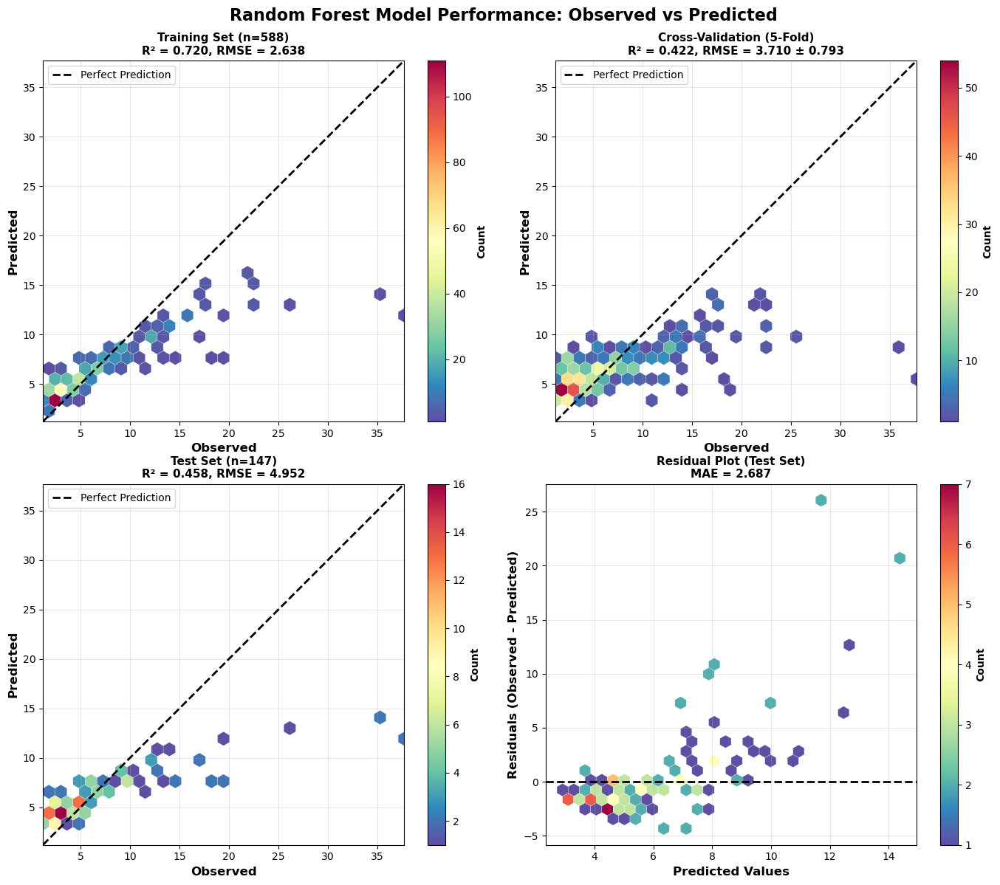


Plot saved to: ../results_images/shannons_model_performance_hex.png


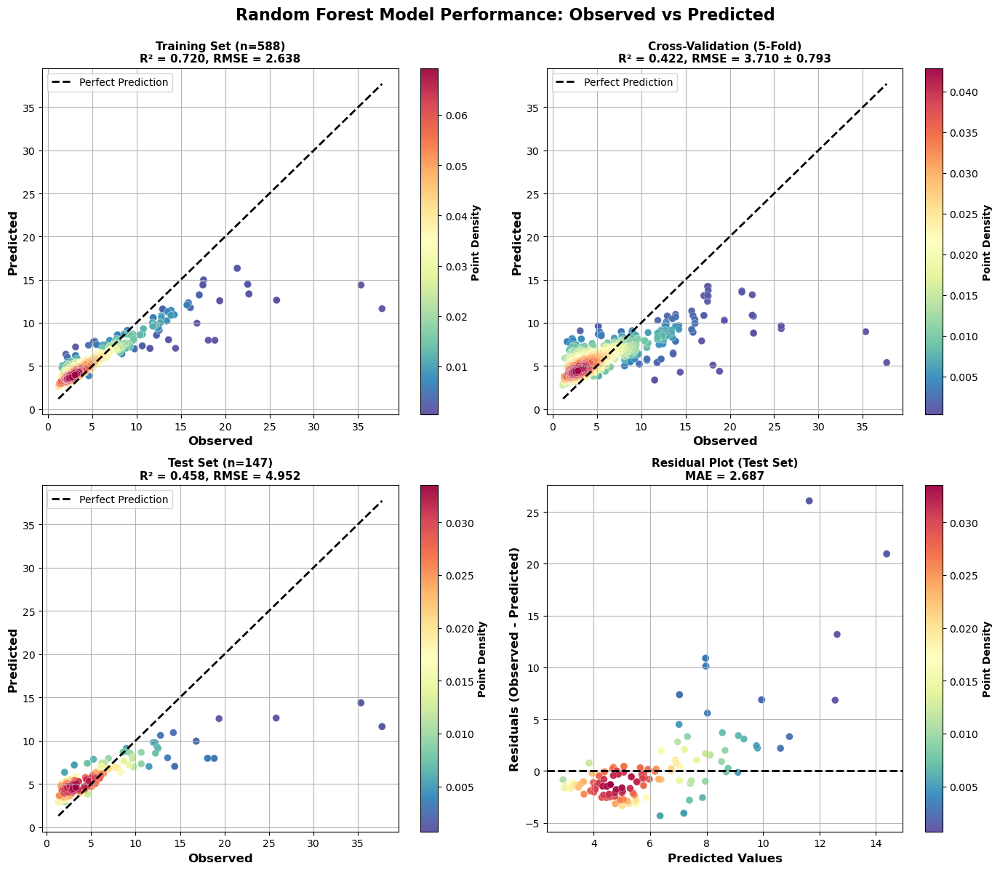

Shape before imputation: (735, 13)
Columns: ['grade', 'impervious_pct', 'mean_ndvi', 'highway_log1', 'mean_canopy', 'SF_pct', 'MF_pct', 'MED_INCOME', 'NH_BLACK_PER', 'NH_ASIAN_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm']
Shape after imputation: (735, 13)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      7.042        9.316        N/A          12.329      
R² Score                  0.687        0.427        0.508        0.471       
MAE                       N/A          5.601        N/A          5.872       

CV RMSE (±std)            9.316 ± 2.077
Shape before imputation: (735, 13)
Columns: ['grade', 'impervious_pct', 'mean_ndvi', 'highway_log1', 'mean_canopy', 'SF_pct', 'MF_pct', 'MED_INCOME', 'NH_BLACK_PER', 'NH_ASIAN_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm']
Shape after imputation: (735, 13)
MODEL EVALUATION SUMMARY

Metric      

In [8]:
# After running your model
# Train model
richness_df = richness_df.drop(columns=['geometry_x'])
shannon_df = shannon_df.drop(columns=['geometry_x'])
simpson_df = simpson_df.drop(columns=['geometry_x'])

shannon_results = train_rf_model(shannon_df, target_col='Estimator', cv_folds=5)
# Create plots
plot_hex_model_performance(shannon_results, save_path= f'../results_images/shannons_model_performance_hex_{timestamp}.png')
plot_density_model_performance(shannon_results, save_path= '../results_images/shannons_model_performance_hex.png')
rich_results = train_rf_model(richness_df, target_col='Estimator', cv_folds=5)
simpson_results = train_rf_model(simpson_df, target_col='Estimator', cv_folds=5)


# Partial Depenence Plots

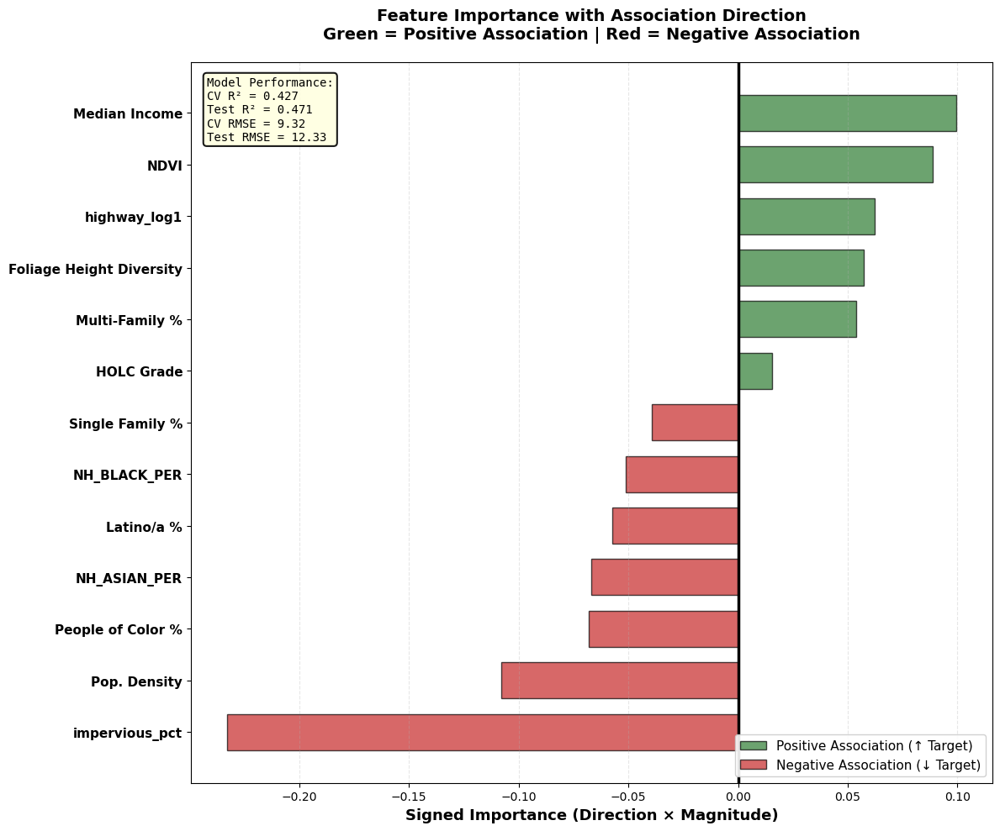

✓ Saved: ../results_images/rich_importance_2026-07-23.png


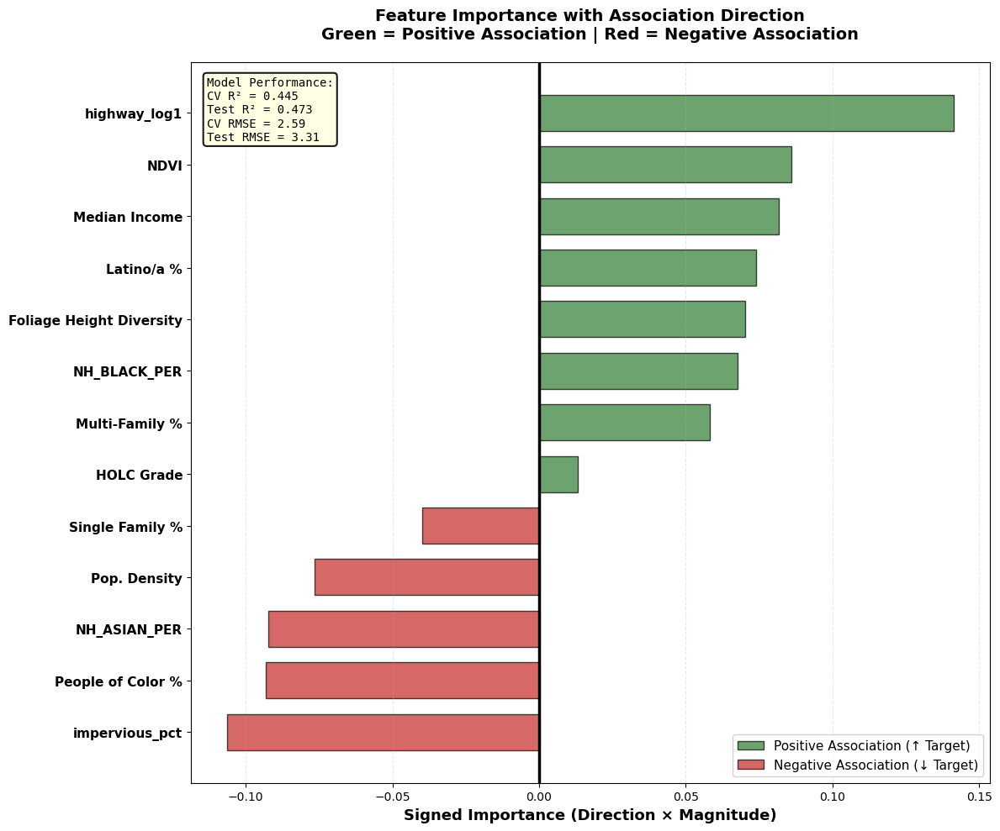

✓ Saved: ../results_images/simpson_importance_2026-07-23.png


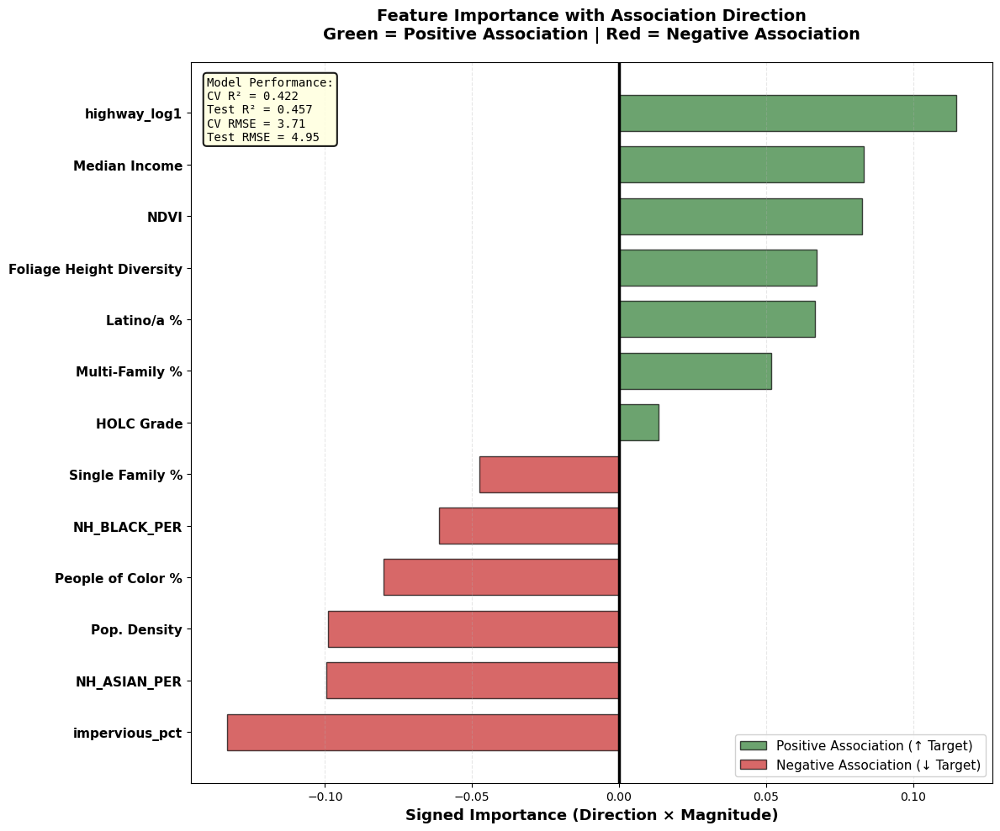

✓ Saved: ../results_images/shannon_importance_2026-07-23.png


In [8]:
def plot_signed_importance(results, richness_df, top_n=15, 
                           feature_names_dict=None, save_path=None):
    """
    Variable importance 
    """
    
    # Default feature names mapping
    if feature_names_dict is None:
        feature_names_dict = {
            'mean_ndvi': 'NDVI',
            'mean_canopy': 'Foliage Height Diversity',
            'mean_highway': 'Highway Distance',
            'mean_imperm': 'Impervious %',
            'TOTPOP': 'Pop. Density',
            'pop_density_sqkm': 'Pop. Density',
            'MED_INCOME': 'Median Income',
            'NHPI_PER': 'Native Hawaiian Pacific Islander%',
            'AMIN_PER': 'Native American%',
            'OTHER_PER': 'Other Race %',
            'WHITE_PER': 'White %',
            'BLACK_PER': 'Black %',
            'ASIAN_PER': 'Asian %',
            'POC_PER': 'People of Color %',
            'LATINE_PER': 'Latino/a %',
            'SF_pct': 'Single Family %',
            'MF_pct': 'Multi-Family %',
            'Diversity': 'Diversity Index',
            'grade': 'HOLC Grade'
        }
    
    # Get data
    feature_importance = results['feature_importance'].copy()
    
    # Calculate correlations for numeric features only
    target_corr = richness_df.select_dtypes(include=[np.number]).corrwith(
        richness_df['Estimator']
    ).drop('Estimator', errors='ignore')
    
    # For categorical features (like grade), calculate point-biserial or use encoded version
    # Check if grade is in features
    X_train = results['X_train']
    if isinstance(X_train, pd.DataFrame) and 'grade' in X_train.columns:
        # Grade was encoded as numeric, so calculate its correlation from X_train
        from scipy.stats import pearsonr
        grade_corr = pearsonr(X_train['grade'], results['y_train'])[0]
        target_corr['grade'] = grade_corr
    
    # Get top features
    top_features = feature_importance.head(top_n)['feature'].tolist()
    
    # Build dataframe, handling features that may not have correlation
    df_list = []
    for feature in top_features:
        imp_value = feature_importance.set_index('feature').loc[feature, 'importance']
        
        # Get correlation if available, otherwise set to 0
        if feature in target_corr.index:
            corr_value = target_corr[feature]
        else:
            # For categorical variables not in correlation, try to get from encoded X_train
            if isinstance(X_train, pd.DataFrame) and feature in X_train.columns:
                try:
                    from scipy.stats import pearsonr
                    corr_value = pearsonr(X_train[feature], results['y_train'])[0]
                except:
                    corr_value = 0.0
            else:
                corr_value = 0.0
        
        df_list.append({
            'feature': feature,
            'importance': imp_value,
            'correlation': corr_value
        })
    
    df = pd.DataFrame(df_list)
    df['signed_importance'] = df['importance'] * np.sign(df['correlation'])
    df = df.sort_values('signed_importance')
    
    # Apply renaming
    df['display_name'] = df['feature'].map(lambda x: feature_names_dict.get(x, x))
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Signed importance bars
    colors = ['#C62828' if x < 0 else '#2E7D32' for x in df['signed_importance']]
    bars = ax.barh(range(len(df)), df['signed_importance'], 
                   color=colors, edgecolor='black', alpha=0.7, height=0.7)
    
    # Formatting
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(df['display_name'], fontweight='bold', fontsize=11)
    ax.axvline(0, color='black', linewidth=2.5)
    ax.set_xlabel('Signed Importance (Direction × Magnitude)', 
                  fontweight='bold', fontsize=13)
    ax.set_title(f'Feature Importance with Association Direction\n' + 
                 'Green = Positive Association | Red = Negative Association', 
                 fontweight='bold', fontsize=14, pad=20)
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    
    # Add value labels
    for i, (idx, row) in enumerate(df.iterrows()):
        value = row['signed_importance']
        corr = row['correlation']
        imp = row['importance']
        
        # Position for text
        x_pos = value + (0.003 if value > 0 else -0.003)
        ha = 'left' if value > 0 else 'right'
        
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2E7D32', edgecolor='black', alpha=0.7, 
              label='Positive Association (↑ Target)'),
        Patch(facecolor='#C62828', edgecolor='black', alpha=0.7, 
              label='Negative Association (↓ Target)')
    ]
    ax.legend(handles=legend_elements, loc='lower right', 
             fontsize=11, framealpha=0.9)
    
    # Add model performance box
    stats_text = (f'Model Performance:\n'
                 f'CV R² = {results.get("cv_r2", 0):.3f}\n'
                 f'Test R² = {results.get("test_r2", 0):.3f}\n'
                 f'CV RMSE = {results.get("cv_rmse_mean", 0):.2f}\n'
                 f'Test RMSE = {results.get("test_rmse", 0):.2f}')
    
    ax.text(0.02, 0.98, stats_text, transform=ax.transAxes,
           fontsize=10, verticalalignment='top', family='monospace',
           bbox=dict(boxstyle='round', facecolor='lightyellow', 
                    alpha=0.9, edgecolor='black', linewidth=1.5))
    
    plt.tight_layout()
    
    # Save
    if save_path is None:
        save_path = 'signed_importance.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")
    
    return df



# Usage
importance_df = plot_signed_importance(
    rich_results, 
    richness_df, 
    top_n=15,
    save_path=f'../results_images/rich_importance_{timestamp}.png'
)



# Usage
importance_df = plot_signed_importance(
    simpson_results, 
    simpson_df, 
    top_n=15,
    save_path=f'../results_images/simpson_importance_{timestamp}.png'
)


# Usage
importance_df = plot_signed_importance(
    shannon_results, 
    shannon_df, 
    top_n=15,
    save_path=f'../results_images/shannon_importance_{timestamp}.png'
)


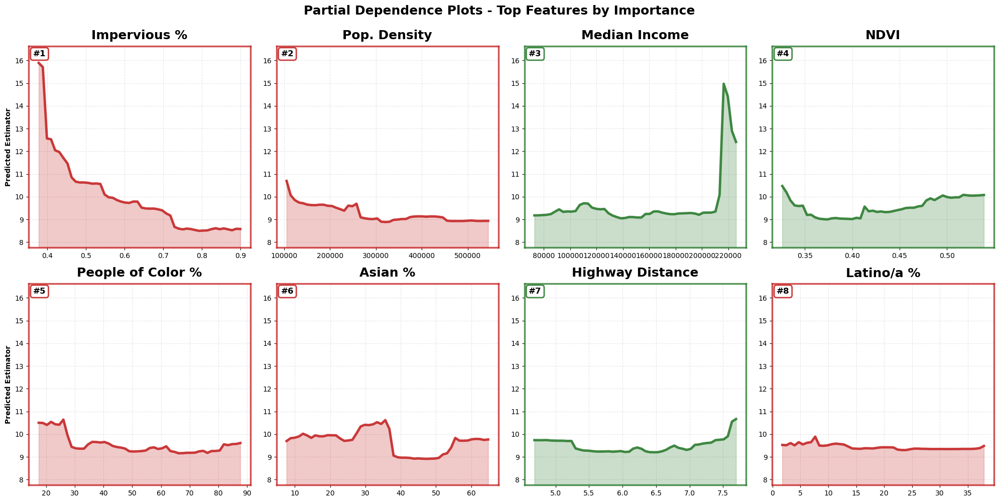

✓ Saved: ../results_images/pdp_grid_richness_2026-07-23.png
  Global Y-axis range: [7.760, 16.630]


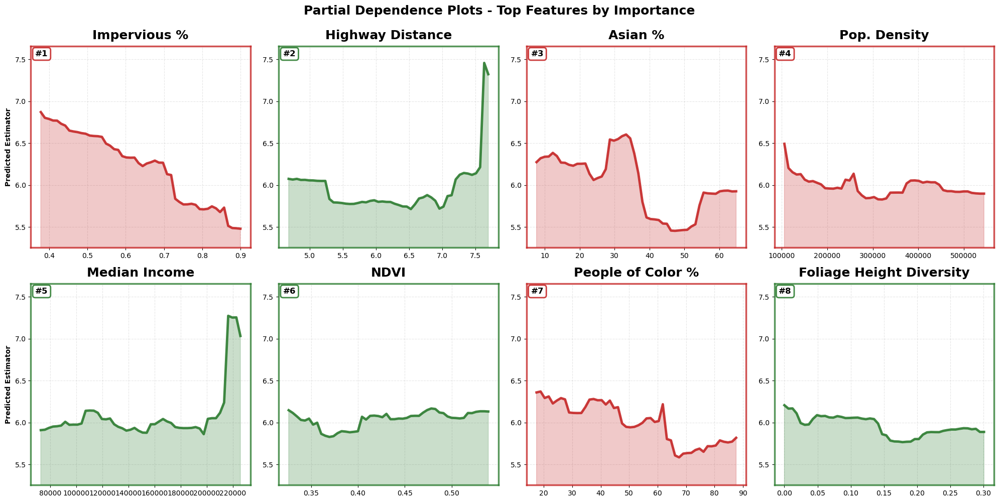

✓ Saved: ../results_images/pdp_grid_shannons_2026-07-23.png
  Global Y-axis range: [5.253, 7.659]


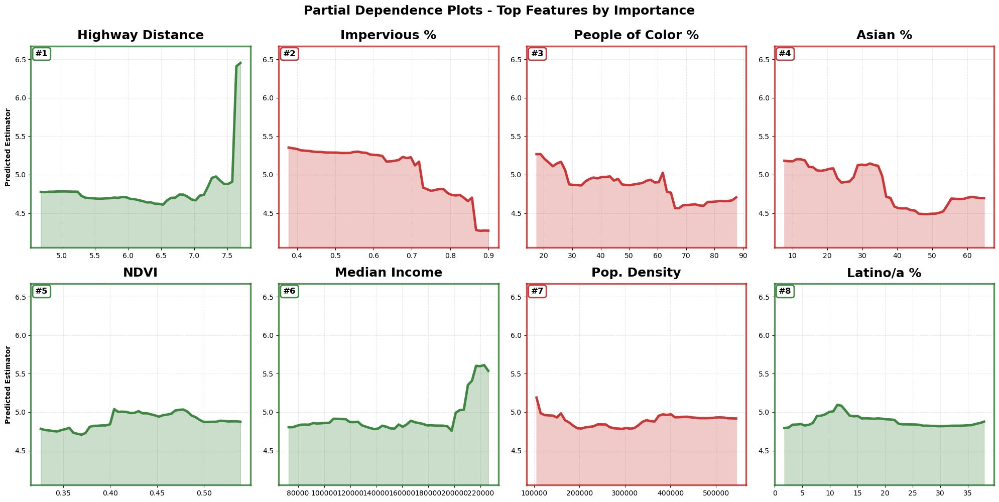

✓ Saved: ../results_images/pdp_grid_simpsons_2026-07-23.png
  Global Y-axis range: [4.051, 6.672]


In [9]:
def plot_pdp_grid(results, richness_df, n_features=8, 
                 feature_names_dict=None, save_path=None):
    """
    Plot grid of Partial Dependence Plots
    
    Parameters:
    -----------
    results : dict
        Model results dictionary
    richness_df : DataFrame
        Original data
    n_features : int
        Number of features to show PDPs for
    feature_names_dict : dict
        Dictionary to rename features
    save_path : str
        Path to save figure
    """
    from sklearn.inspection import partial_dependence
    
    
    # Default feature names mapping
    if feature_names_dict is None:
        feature_names_dict = {
            'mean_ndvi': 'NDVI',
            'mean_canopy': 'Foliage Height Diversity',
            'highway_log1': 'Highway Distance',
            'impervious_pct': 'Impervious %',
            'pop_density_sqkm': 'Pop. Density',
            'MED_INCOME': 'Median Income',
            'NH_NHPI_PER': 'Native Hawaiian Pacific Islander%',
            'NH_AMIN_PER': 'Native American%',
            'NH_OTHER_PER': 'Other Race %',
            'NH_WHITE_PER': 'White %',
            'NH_BLACK_PER': 'Black %',
            'NH_ASIAN_PER': 'Asian %',
            'POC_PER': 'People of Color %',
            'LATINE_PER': 'Latino/a %',
            'SF_pct': 'Single Family %',
            'MF_pct': 'Multi-Family %',
            'Diversity': 'Diversity Index',
            'grade': 'HOLC Grade'
        }
    
    # Get data
    feature_importance = results['feature_importance'].copy()
    target_corr = richness_df.select_dtypes(include=[np.number]).corrwith(
        richness_df['Estimator']
    ).drop('Estimator', errors='ignore')
    
    # Get top features
    top_features_df = feature_importance.head(n_features).copy()
    top_features_df['correlation'] = top_features_df['feature'].map(target_corr)
    top_features_df['display_name'] = top_features_df['feature'].map(
        lambda x: feature_names_dict.get(x, x)
    )
    
    # Sort by importance
    top_features_df = top_features_df.sort_values('importance', ascending=False)
    
    # Get model and data
    model = results['model']
    X = results['X_train']
    
    # Get feature names
    if isinstance(X, pd.DataFrame):
        feature_names = X.columns.tolist()
    else:
        feature_names = results['feature_importance']['feature'].tolist()
    
    # FIRST PASS: Calculate all PDP values to find global min/max
    use_log = results.get('use_log_transform', False)
    all_pd_values = []
    pd_data = []  # Store PDP data for reuse
    
    for idx, (_, feat_row) in enumerate(top_features_df.iterrows()):
        if idx >= n_features:
            break
            
        feature = feat_row['feature']
        
        try:
            feature_idx = feature_names.index(feature)
            
            # Calculate partial dependence
            pd_result = partial_dependence(
                model, 
                X, 
                features=[feature_idx],
                grid_resolution=50
            )
            
            # Transform PDP values if using log
            if use_log:
                pd_values = np.expm1(pd_result['average'][0])
            else:
                pd_values = pd_result['average'][0]
            
            all_pd_values.extend(pd_values)
            pd_data.append((pd_result, pd_values, feat_row))
            
        except Exception as e:
            pd_data.append((None, None, feat_row))
    
    # Calculate global y-axis limits
    if all_pd_values:
        global_y_min = np.min(all_pd_values)
        global_y_max = np.max(all_pd_values)
        y_range = global_y_max - global_y_min
        y_padding = y_range * 0.1  # 10% padding
        global_ylim = (global_y_min - y_padding, global_y_max + y_padding)
    else:
        global_ylim = None
    
    # Determine grid layout
    ncols = 4
    nrows = int(np.ceil(n_features / ncols))
    
    # Create figure
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5*nrows))
    axes = axes.flatten() if n_features > 1 else [axes]
    
    # SECOND PASS: Plot each PDP with global y-limits
    for idx, (pd_result, pd_values, feat_row) in enumerate(pd_data):
        if idx >= n_features:
            break
            
        display_name = feat_row['display_name']
        feat_imp = feat_row['importance']
        feat_corr = feat_row['correlation']
        
        ax = axes[idx]
        
        if pd_result is not None and pd_values is not None:
            try:
                # Choose color based on correlation
                line_color = '#2E7D32' if feat_corr > 0 else '#C62828'
                fill_color = line_color
                
                # Plot PDP line
                ax.plot(pd_result['grid_values'][0], pd_values, 
                       linewidth=3.5, color=line_color, alpha=0.9)
                
                # Add shaded area
                ax.fill_between(pd_result['grid_values'][0], pd_values, 
                               alpha=0.25, color=fill_color, zorder=2)
                
                # Set global y-axis limits
                if global_ylim is not None:
                    ax.set_ylim(global_ylim)
                
                # Formatting
                ax.set_xlabel('')  # Remove x-axis label
                ax.set_ylabel('Predicted Estimator' if idx % ncols == 0 else '', 
                             fontweight='bold', fontsize=10)
                
                # Title with feature name at top in black, larger font
                title_text = f'{display_name}'
                
                ax.set_title(title_text, fontweight='bold', fontsize=18, 
                            color='black', pad=10)
                
                ax.grid(alpha=0.3, linestyle='--', zorder=0)
                
                # Colored border
                for spine in ax.spines.values():
                    spine.set_edgecolor(line_color)
                    spine.set_linewidth(2.5)
                    spine.set_alpha(0.8)
                
                # Add ranking badge
                rank_text = f'#{idx+1}'
                ax.text(0.02, 0.98, rank_text, transform=ax.transAxes,
                       fontsize=12, fontweight='bold', verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='white', 
                                edgecolor=line_color, linewidth=2, alpha=0.9))
                
            except Exception as e:
                # Error handling
                ax.text(0.5, 0.5, f'Error:\n{str(e)[:60]}...', 
                       ha='center', va='center', transform=ax.transAxes,
                       fontsize=9, color='red', 
                       bbox=dict(boxstyle='round', facecolor='white', 
                                alpha=0.9, edgecolor='red', linewidth=2))
                ax.set_title(f'{display_name}\n(Error)', fontweight='bold', fontsize=12, color='black')
        else:
            # Error handling for features that failed in first pass
            ax.text(0.5, 0.5, 'Error calculating PDP', 
                   ha='center', va='center', transform=ax.transAxes,
                   fontsize=9, color='red', 
                   bbox=dict(boxstyle='round', facecolor='white', 
                            alpha=0.9, edgecolor='red', linewidth=2))
            ax.set_title(f'{display_name}\n(Error)', fontweight='bold', fontsize=12, color='black')
    
    # Hide extra subplots
    for idx in range(n_features, len(axes)):
        axes[idx].axis('off')
    
    # Overall title
    plt.suptitle('Partial Dependence Plots - Top Features by Importance', 
                 fontsize=18, fontweight='bold', y=0.995)
    
    plt.tight_layout()
    
    # Save
    if save_path is None:
        save_path = 'pdp_grid.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")
    print(f"  Global Y-axis range: [{global_ylim[0]:.3f}, {global_ylim[1]:.3f}]")
    
    return top_features_df

# Usage
pdp_df = plot_pdp_grid(
    rich_results, 
    richness_df, 
    n_features=8,
    save_path=f'../results_images/pdp_grid_richness_{timestamp}.png'
)


# Usage
pdp_df = plot_pdp_grid(
    shannon_results, 
    shannon_df, 
    n_features=8,
    save_path=f'../results_images/pdp_grid_shannons_{timestamp}.png'
)


# Usage
pdp_df = plot_pdp_grid(
    simpson_results, 
    simpson_df, 
    n_features=8,
    save_path=f'../results_images/pdp_grid_simpsons_{timestamp}.png'
)

In [10]:
## PDP plots for SHAP values

In [11]:
#Troubleshoot 

# Check for infinity or very large values in Simpson diversity data
print("Simpson diversity min:", simpson_df['Estimator'].min())
print("Simpson diversity max:", simpson_df['Estimator'].max())
print("Simpson diversity mean:", simpson_df['Estimator'].mean())
print("Contains infinity:", np.isinf(simpson_df['Estimator']).any())
print("Contains NaN:", np.isnan(simpson_df['Estimator']).any())
print("Number of infinity values:", np.isinf(simpson_df['Estimator']).sum())
print("Number of NaN values:", np.isnan(simpson_df['Estimator']).sum())

# Look at the most extreme values
print("\nTop 10 largest values:")
print(simpson_df['Estimator'].nlargest(10))
print("\nTop 10 smallest values:")
print(simpson_df['Estimator'].nsmallest(10))


Simpson diversity min: 1.06247764397281
Simpson diversity max: 26.6885043285103
Simpson diversity mean: 4.986190769813531
Contains infinity: False
Contains NaN: False
Number of infinity values: 0
Number of NaN values: 0

Top 10 largest values:
456    26.688504
457    26.688504
458    26.688504
33     23.052117
34     23.052117
35     23.052117
51     16.598586
52     16.598586
53     16.598586
303    16.095877
Name: Estimator, dtype: float64

Top 10 smallest values:
1995    1.062478
1996    1.062478
1997    1.062478
1140    1.136590
1141    1.136590
1142    1.136590
1203    1.159509
1204    1.159509
1205    1.159509
1302    1.173285
Name: Estimator, dtype: float64


# PCA Plots

TypeError: ufunc 'arctan2' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

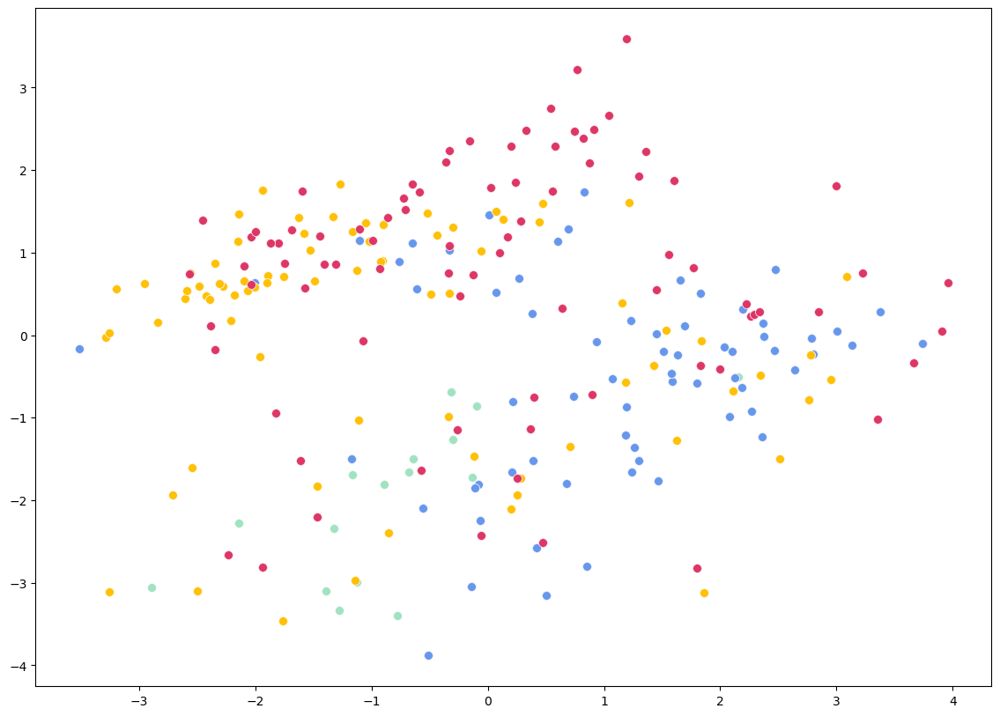

In [7]:
#import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches

def plot_pca_biplot(df, features, group_col='grade_x', target_col=None,
                   feature_names_dict=None, save_path=None):
    """
    Create PCA biplot with HOLC grade groupings
    
    Parameters:
    -----------
    df : DataFrame
        Your data
    features : list
        List of feature column names to include in PCA
    group_col : str
        Column for grouping (e.g., 'grade')
    target_col : str
        Optional target variable to color by
    feature_names_dict : dict
        Dictionary to rename features for display
    save_path : str
        Path to save figure
    """
    
    # Default feature names
    if feature_names_dict is None:
        feature_names_dict = {
            'mean_ndvi': 'NDVI Mean',
            'mean_canopy': 'Number of Canopy Layers',
            'highway_log1': 'Distance to Nearest Highway',
            'impervious_pct': 'Impermeable Surface',
            'pop_density_sqkm': 'Population Density',
            'MED_INCOME': 'Median Household Income',
            'NH_WHITE_PER': 'Percent White',
            'NH_BLACK_PER': 'Percentage Black',
            'NH_ASIAN_PER': 'Percentage Asian',
            'POC_PER': 'Percentage People of Color',
            'LATINE_PER': 'Percentage Latine',
            'SF_pct': 'Single Family %',
            'MF_pct': 'Multi-Family %',
            'Diversity': 'Diversity Index'
        }
    
    # Prepare data
    df_clean = df[features + [group_col]].dropna()
    X = df_clean[features]
    groups = df_clean[group_col]
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    
    # Get loadings (feature contributions)
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(14, 10))
    
    # Define colors and markers for each grade
    grade_colors = {
        'A': '#9FE2BF',  # Light green
        'B': '#6495ED',  # Cornflower blue
        'C': '#FFBF00',  # Gold
        'D': '#DE3163'   # Hot pink
    }
    
    grade_labels = {
        'A': 'A',
        'B': 'B', 
        'C': 'C',
        'D': 'D'
    }
    
    # Plot points by grade
    for grade in ['A', 'B', 'C', 'D']:
        mask = groups == grade
        if mask.sum() > 0:
            ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                      c=grade_colors[grade], 
                      label=grade_labels[grade],
                      s=50, alpha=0.7, edgecolors='white', linewidth=0.5)
    
    # Add confidence ellipses for each grade
    for grade in ['A', 'B', 'C', 'D']:
        mask = groups == grade
        if mask.sum() > 2:  # Need at least 3 points for ellipse
            points = X_pca[mask]
            
            # Calculate mean and covariance
            mean = points.mean(axis=0)
            cov = np.cov(points.T)
            
            # Eigenvalues and eigenvectors
            eigenvalues, eigenvectors = np.linalg.eig(cov)
            
            # Calculate angle and width/height
            angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
            width, height = 2 * 2 * np.sqrt(eigenvalues)  # 2 std devs
            
            # Create ellipse
            ellipse = Ellipse(mean, width, height, angle=angle,
                            facecolor=grade_colors[grade], 
                            edgecolor=grade_colors[grade],
                            alpha=0.2, linewidth=3)
            
            # Optional: Add second ellipse outline for even darker edge
            ellipse_outline = Ellipse(mean, width, height, angle=angle,
                                 facecolor='none',             # No fill
                                 edgecolor=grade_colors[grade], # Edge color
                                 alpha=0.8,                     # Darker edge
                                 linewidth=2.5,                 # Edge width
                                 linestyle='-')
        
            ax.add_patch(ellipse)
            ax.add_patch(ellipse_outline)
        
    # Plot loading vectors (arrows)
    arrow_scale = 4.5  # Adjust this to make arrows longer/shorter
    
    for i, feature in enumerate(features):
        # Arrow coordinates
        x_arrow = loadings[i, 0] * arrow_scale
        y_arrow = loadings[i, 1] * arrow_scale
        
        # Plot arrow
        ax.arrow(0, 0, x_arrow, y_arrow,
                head_width=0.15, head_length=0.15,
                fc='black', ec='black', linewidth=2,
                alpha=0.8, zorder=5)
        
        # Add label at end of arrow
        # Offset label slightly from arrow tip
        offset_x = 0.3 if x_arrow > 0 else -0.3
        offset_y = 0.3 if y_arrow > 0 else -0.3
        
        # Get display name
        display_name = feature_names_dict.get(feature, feature)
        
        ax.text(x_arrow + offset_x, y_arrow + offset_y, display_name,
               fontsize=11, ha='center', va='center',
               bbox=dict(boxstyle='round,pad=0.5', 
                        facecolor='white', 
                        edgecolor='black',
                        alpha=0.8, linewidth=1.5))
    
    # Formatting
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', 
                 fontweight='bold', fontsize=14)
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', 
                 fontweight='bold', fontsize=14)
    ax.set_title('HOLC Graded Neighborhoods', 
                fontweight='bold', fontsize=16, pad=20)
    
    # Add grid
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.axhline(y=0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)
    ax.axvline(x=0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)
    
    # Legend for grades
    legend_elements = []
    for grade in ['A', 'B', 'C', 'D']:
        legend_elements.append(
            mpatches.Patch(facecolor=grade_colors[grade], 
                          edgecolor=grade_colors[grade],
                          label=grade, alpha=0.5)
        )
    
    legend = ax.legend(handles=legend_elements, 
                      title='HOLC Grade', 
                      loc='upper right',
                      fontsize=13,
                      title_fontsize=14,
                      framealpha=0.70,
                      edgecolor='black',
                      ncol=4,
                      columnspacing=1.5,
                      handletextpad=0.5,
                      borderpad=1)
    
    plt.setp(legend.get_title(), fontweight='bold')
    legend.get_frame().set_linewidth(2)
    
    # Set equal aspect ratio
    ax.set_aspect('equal', adjustable='datalim')
    
    plt.tight_layout()
    
    # Save
    if save_path is None:
        save_path = 'pca_biplot_holc.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")
    
    # Print PCA summary
    print("\n" + "=" * 60)
    print("PCA SUMMARY")
    print("=" * 60)
    print(f"PC1 variance explained: {pca.explained_variance_ratio_[0]*100:.2f}%")
    print(f"PC2 variance explained: {pca.explained_variance_ratio_[1]*100:.2f}%")
    print(f"Total variance explained: {pca.explained_variance_ratio_[:2].sum()*100:.2f}%")
    
    print("\nTop 5 Features for PC1:")
    pc1_contrib = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'Loading': loadings[:, 0]
    }).sort_values('Loading', key=abs, ascending=False)
    print(pc1_contrib.head())
    
    print("\nTop 5 Features for PC2:")
    pc2_contrib = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'Loading': loadings[:, 1]
    }).sort_values('Loading', key=abs, ascending=False)
    print(pc2_contrib.head())
    
    return {
        'pca': pca,
        'X_pca': X_pca,
        'loadings': loadings,
        'scaler': scaler
    }

# ============================================================
# USAGE
# ============================================================

# Select features for PCA
pca_features = [
    'mean_ndvi',
    'mean_canopy', 
    'highway_log1',
    'impervious_pct',
    'pop_density_sqkm',
    'MED_INCOME',
    'NH_BLACK_PER',
    'NH_ASIAN_PER',
    'LATINE_PER',
    'POC_PER',
    'SF_pct',
    'MF_pct'
]

# Custom feature names
custom_names = {
    'mean_ndvi': 'NDVI Mean',
    'mean_canopy': 'Number of Canopy Layers',
    'highway_log1': 'Distance to Nearest Highway',
    'impervious_pct': 'Impermeable Surface',
    'pop_density_sqkm': 'Population Density',
    'MED_INCOME': 'Median Household Income',
    'NH_WHITE_PER': 'Percent White',
    'NH_BLACK_PER': 'Percentage Black',
    'NH_ASIAN_PER': 'Percentage Asian',
    'POC_PER': 'Percentage People of Color',
    'LATINE_PER': 'Percentage Latine',
    'SF_pct': 'Single-Family Housing',
    'MF_pct': 'Multi-Family Housing'
}

# Create PCA plot
pca_results = plot_pca_biplot(
    richness_df,
    features=pca_features,
    group_col='grade',
    feature_names_dict=custom_names,
    save_path=f'../results_images/sf_pca_biplot_{timestamp}.png'
)

# Shap Values from PCA 

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_shap_from_pca(pca_results, features, feature_names_dict, 
                       pc_component=0, top_n=None, save_path=None):
    """
    Create SHAP-style waterfall/bar plot from PCA loadings
    
    Parameters:
    -----------
    pca_results : dict
        Results from plot_pca_biplot function
    features : list
        List of feature names
    feature_names_dict : dict
        Dictionary for feature display names
    pc_component : int
        Which PC to use (0 for PC1, 1 for PC2)
    top_n : int or None
        Number of top features to show (by absolute loading). If None, show all.
    save_path : str
        Path to save figure
    """
    
    # Extract loadings for specified component
    loadings = pca_results['loadings'][:, pc_component]
    
    # Create DataFrame
    loading_df = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'Loading': loadings,
        'Abs_Loading': np.abs(loadings)
    }).sort_values('Abs_Loading', ascending=True)
    
    # **NEW: Keep only top N features if specified**
    if top_n is not None:
        loading_df = loading_df.tail(top_n)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(11, 6))
    
    # Color by positive/negative
    if pc_component == 0:  # PC1
        
        colors = ['#DE3163' if x < 0 else '#9FE2BF' for x in loading_df['Loading']]
    else:  # PC2 (or other components)
        colors = ['#DE3163' if x < 0 else '#6495ED' for x in loading_df['Loading']]
        # Horizontal bar plot
   
    bars = ax.barh(range(len(loading_df)), loading_df['Loading'], 
                   color=colors, alpha=0.8, edgecolor='dimgray', linewidth=1.0)
    
    # Add feature names
    ax.set_yticks(range(len(loading_df)))
    ax.set_yticklabels(loading_df['Feature'], fontsize=11)
    
    # Add vertical line at 0
    ax.axvline(x=0, color='black', linestyle='-', linewidth=1.5)
    
    # Labels and title
    pc_var = pca_results['pca'].explained_variance_ratio_[pc_component] * 100
    title_suffix = f' (Top {top_n})' if top_n else ''
    ax.set_xlabel(f'PC{pc_component+1} Loading (Contribution)', 
                  fontsize=13, fontweight='bold')
    ax.set_title(f'Feature Contributions to PC{pc_component+1} ({pc_var:.1f}% variance){title_suffix}', 
                 fontsize=14, fontweight='bold', pad=20)
    
    # Add value labels on bars
    for i, (idx, row) in enumerate(loading_df.iterrows()):
        value = row['Loading']
        x_pos = value + (0.01 if value > 0 else -0.01)
        ha = 'left' if value > 0 else 'right'
        ax.text(x_pos, i, f'{value:.3f}', 
                va='center', ha=ha, fontsize=9, fontweight='bold', alpha=0.3)
    
    # Set padding based on max absolute value**
    max_abs_loading = loading_df['Abs_Loading'].max()
    padding = max_abs_loading * 0.2  # 20% padding
    ax.set_xlim(-max_abs_loading - padding, max_abs_loading + padding)

    # Grid
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    ax.set_axisbelow(True)
    
    plt.tight_layout()
    
    # Save
    if save_path is None:
        save_path = f'pca_shap_style_pc{pc_component+1}.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")
    
    # Print summary (always show top 5 in console)
    print(f"\nTop 5 Positive Contributors to PC{pc_component+1}:")
    full_df = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'Loading': loadings,
        'Abs_Loading': np.abs(loadings)
    })
    print(full_df.nlargest(5, 'Loading')[['Feature', 'Loading']])
    
    print(f"\nTop 5 Negative Contributors to PC{pc_component+1}:")
    print(full_df.nsmallest(5, 'Loading')[['Feature', 'Loading']])
    
    return loading_df

def plot_shap_summary_combined(pca_results, features, feature_names_dict, 
                               top_n=None, save_path=None):
    """
    Create combined bar plot showing PC1 and PC2 contributions side-by-side
    
    Parameters:
    -----------
    top_n : int or None
        Show only top N features (by PC1 absolute loading)
    """
    
    loadings_pc1 = pca_results['loadings'][:, 0]
    loadings_pc2 = pca_results['loadings'][:, 1]
    
    # Create DataFrame
    df = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'PC1': loadings_pc1,
        'PC2': loadings_pc2
    })
    
    # Sort by PC1 absolute value
    df['PC1_abs'] = np.abs(df['PC1'])
    df = df.sort_values('PC1_abs', ascending=True)
    
    # **NEW: Keep only top N**
    if top_n is not None:
        df = df.tail(top_n)
    
    # Create figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    
    # PC1
    colors1 = ['#DE3163' if x < 0 else '#9FE2BF' for x in df['PC1']]
    ax1.barh(range(len(df)), df['PC1'], color=colors1, alpha=0.5, 
             edgecolor='black', linewidth=1.0)
    ax1.axvline(x=0, color='black', linestyle='-', linewidth=1.0)
    ax1.set_xlabel('PC1 Loading', fontsize=13, fontweight='bold')
    pc1_var = pca_results['pca'].explained_variance_ratio_[0] * 100
    title_suffix = f' - Top {top_n}' if top_n else ''
    ax1.set_title(f'PC1 ({pc1_var:.1f}% variance){title_suffix}', fontsize=14, fontweight='bold')
    ax1.grid(axis='x', alpha=0.3, linestyle='--')
    
    # PC2
    colors2 = ['#DE3163' if x < 0 else '#6495ED' for x in df['PC2']]
    ax2.barh(range(len(df)), df['PC2'], color=colors2, alpha=0.5, 
             edgecolor='black', linewidth=1.0)
    ax2.axvline(x=0, color='black', linestyle='-', linewidth=1.0)
    ax2.set_xlabel('PC2 Loading', fontsize=13, fontweight='bold')
    pc2_var = pca_results['pca'].explained_variance_ratio_[1] * 100
    ax2.set_title(f'PC2 ({pc2_var:.1f}% variance){title_suffix}', fontsize=14, fontweight='bold')
    ax2.grid(axis='x', alpha=0.3, linestyle='--')
    
    # Y-axis labels (only on left plot)
    ax1.set_yticks(range(len(df)))
    ax1.set_yticklabels(df['Feature'], fontsize=11)
    
    plt.tight_layout()
    
    # Save
    if save_path is None:
        save_path = 'pca_shap_combined.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")
    
    return df


# ============================================================
# USAGE
# ============================================================

# Show only top 5 for PC1
loading_df_pc1 = plot_shap_from_pca(
    pca_results,
    features=pca_features,
    feature_names_dict=custom_names,
    pc_component=0,
    top_n=5,  # ← Only show top 5
    save_path='../results_images/shap_pc1_loadings_top5.svg'
)

# Show only top 5 for PC2
loading_df_pc2 = plot_shap_from_pca(
    pca_results,
    features=pca_features,
    feature_names_dict=custom_names,
    pc_component=1,
    top_n=5,  # ← Only show top 5
    save_path='../results_images/shap_pc2_loadings_top5.svg'
)

# Combined plot with top 5
combined_df = plot_shap_summary_combined(
    pca_results,
    features=pca_features,
    feature_names_dict=custom_names,
    top_n=5,  # ← Only show top 5
    save_path='../results_images/shap_combined_pc1_pc2_top5.png'
)

NameError: name 'pca_results' is not defined

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr, pearsonr
import matplotlib.patches as mpatches

# ============================================================
# 1. CALCULATE ALPHA DIVERSITY (What you already have)
# ============================================================

def calculate_alpha_diversity(species_data, site_col='hex_id'):
    """
    Calculate multiple alpha diversity metrics
    
    Parameters:
    -----------
    species_data : DataFrame
        Rows = sites, Columns = species abundances
    site_col : str
        Column name for site identifier
    """
    
    # Separate site IDs from species counts
    if site_col in species_data.columns:
        sites = species_data[site_col]
        species_counts = species_data.drop(columns=[site_col])
    else:
        sites = species_data.index
        species_counts = species_data
    
    alpha_metrics = pd.DataFrame(index=sites)
    
    # 1. Species Richness (S)
    alpha_metrics['richness'] = (species_counts > 0).sum(axis=1)
    
    # 2. Shannon Diversity (H')
    def shannon(row):
        row = row[row > 0]  # Remove zeros
        p = row / row.sum()
        return -np.sum(p * np.log(p))
    
    alpha_metrics['shannon'] = species_counts.apply(shannon, axis=1)
    
    # 3. Simpson Diversity (1 - D)
    def simpson(row):
        row = row[row > 0]
        p = row / row.sum()
        return 1 - np.sum(p ** 2)
    
    alpha_metrics['simpson'] = species_counts.apply(simpson, axis=1)
    
    # 4. Pielou's Evenness (J')
    alpha_metrics['evenness'] = alpha_metrics['shannon'] / np.log(alpha_metrics['richness'])
    alpha_metrics['evenness'] = alpha_metrics['evenness'].replace([np.inf, -np.inf], np.nan)
    
    # 5. Total Abundance
    alpha_metrics['total_abundance'] = species_counts.sum(axis=1)
    
    return alpha_metrics


# ============================================================
# 2. CALCULATE BETA DIVERSITY
# ============================================================

def calculate_beta_diversity(species_data, method='bray_curtis', site_col='hex_id'):
    """
    Calculate beta diversity using multiple dissimilarity metrics
    
    Parameters:
    -----------
    species_data : DataFrame
        Rows = sites, Columns = species
    method : str
        'bray_curtis', 'jaccard', 'sorensen', 'euclidean'
    site_col : str
        Site identifier column
    
    Returns:
    --------
    Distance matrix (DataFrame)
    """
    
    # Prepare species matrix
    if site_col in species_data.columns:
        sites = species_data[site_col].values
        species_matrix = species_data.drop(columns=[site_col]).values
    else:
        sites = species_data.index.values
        species_matrix = species_data.values
    
    # Calculate dissimilarity
    if method == 'bray_curtis':
        # Bray-Curtis: (sum |x_i - y_i|) / (sum |x_i + y_i|)
        distances = pdist(species_matrix, metric='braycurtis')
        
    elif method == 'jaccard':
        # Jaccard: presence/absence based
        binary_matrix = (species_matrix > 0).astype(int)
        distances = pdist(binary_matrix, metric='jaccard')
        
    elif method == 'sorensen':
        # Sørensen (Dice): 2*shared / (total species in both sites)
        binary_matrix = (species_matrix > 0).astype(int)
        distances = pdist(binary_matrix, metric='dice')
        
    elif method == 'euclidean':
        distances = pdist(species_matrix, metric='euclidean')
    
    else:
        raise ValueError(f"Unknown method: {method}")
    
    # Convert to square matrix
    dist_matrix = squareform(distances)
    
    # Create DataFrame
    beta_df = pd.DataFrame(dist_matrix, index=sites, columns=sites)
    
    return beta_df


def calculate_whittaker_beta(species_data, site_col='hex_id'):
    """
    Calculate Whittaker's multiplicative beta diversity
    Beta = gamma / mean(alpha)
    
    Returns single value
    """
    
    if site_col in species_data.columns:
        species_matrix = species_data.drop(columns=[site_col])
    else:
        species_matrix = species_data
    
    # Gamma diversity (regional species pool)
    gamma = (species_matrix.sum(axis=0) > 0).sum()
    
    # Mean alpha diversity
    alpha_per_site = (species_matrix > 0).sum(axis=1)
    mean_alpha = alpha_per_site.mean()
    
    # Beta diversity
    beta_whittaker = gamma / mean_alpha
    
    return {
        'beta_whittaker': beta_whittaker,
        'gamma': gamma,
        'mean_alpha': mean_alpha
    }


# ============================================================
# 3. COMPARE BETA DIVERSITY BY HOLC GRADE
# ============================================================

def compare_beta_by_group(species_data, groups, group_col='grade_x', 
                          method='bray_curtis', site_col='hex_id'):
    """
    Compare beta diversity within vs between HOLC grades
    
    Parameters:
    -----------
    species_data : DataFrame
        Species counts per site
    groups : Series or DataFrame column
        Group labels (e.g., HOLC grades)
    group_col : str
        Name of grouping variable
    method : str
        Beta diversity metric
    """
    
    # Calculate beta diversity matrix
    beta_matrix = calculate_beta_diversity(species_data, method=method, site_col=site_col)
    
    # Align groups with beta matrix
    sites = beta_matrix.index
    group_labels = groups.loc[sites] if hasattr(groups, 'loc') else groups
    
    # Calculate within-group and between-group beta diversity
    results = []
    
    unique_groups = group_labels.unique()
    
    # Within-group dissimilarity
    for group in unique_groups:
        group_sites = group_labels[group_labels == group].index
        
        if len(group_sites) > 1:
            # Get submatrix for this group
            group_beta = beta_matrix.loc[group_sites, group_sites]
            
            # Extract upper triangle (avoid double counting)
            upper_tri = group_beta.where(
                np.triu(np.ones(group_beta.shape), k=1).astype(bool)
            ).stack()
            
            results.append({
                'comparison': f'Within {group}',
                'group1': group,
                'group2': group,
                'type': 'within',
                'mean_dissimilarity': upper_tri.mean(),
                'median_dissimilarity': upper_tri.median(),
                'std_dissimilarity': upper_tri.std(),
                'n_comparisons': len(upper_tri)
            })
    
    # Between-group dissimilarity
    for i, group1 in enumerate(unique_groups):
        for group2 in unique_groups[i+1:]:
            sites1 = group_labels[group_labels == group1].index
            sites2 = group_labels[group_labels == group2].index
            
            # Get cross-group dissimilarities
            between_beta = beta_matrix.loc[sites1, sites2]
            values = between_beta.values.flatten()
            
            results.append({
                'comparison': f'{group1} vs {group2}',
                'group1': group1,
                'group2': group2,
                'type': 'between',
                'mean_dissimilarity': values.mean(),
                'median_dissimilarity': np.median(values),
                'std_dissimilarity': values.std(),
                'n_comparisons': len(values)
            })
    
    results_df = pd.DataFrame(results)
    
    return results_df, beta_matrix


# ============================================================
# 4. VISUALIZE BETA DIVERSITY
# ============================================================

def plot_beta_diversity_heatmap(beta_matrix, groups, group_col='grade_x',
                                 method='bray_curtis', save_path=None):
    """
    Plot heatmap of beta diversity matrix ordered by groups
    """
    
    # Sort by groups
    sorted_idx = groups.sort_values().index
    beta_sorted = beta_matrix.loc[sorted_idx, sorted_idx]
    groups_sorted = groups.loc[sorted_idx]
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot heatmap
    sns.heatmap(beta_sorted, cmap='YlOrRd', cbar_kws={'label': f'{method} dissimilarity'},
                xticklabels=False, yticklabels=False, ax=ax)
    
    # Add group separators
    grade_colors = {'A': '#9FE2BF', 'B': '#6495ED', 'C': '#FFBF00', 'D': '#DE3163'}
    
    # Find group boundaries
    boundaries = [0]
    prev_group = groups_sorted.iloc[0]
    for i, group in enumerate(groups_sorted):
        if group != prev_group:
            boundaries.append(i)
            prev_group = group
    boundaries.append(len(groups_sorted))
    
    # Draw lines
    for boundary in boundaries[1:-1]:
        ax.axhline(boundary, color='white', linewidth=2)
        ax.axvline(boundary, color='white', linewidth=2)
    
    # Add color bar for groups
    for i, (start, end) in enumerate(zip(boundaries[:-1], boundaries[1:])):
        mid = (start + end) / 2
        group = groups_sorted.iloc[start]
        
        # Add colored patches on sides
        rect_left = mpatches.Rectangle((-0.5, start), 0.5, end-start,
                                       facecolor=grade_colors.get(group, 'gray'),
                                       edgecolor='black', linewidth=1,
                                       transform=ax.transData, clip_on=False)
        rect_bottom = mpatches.Rectangle((start, len(beta_sorted)), end-start, 0.5,
                                         facecolor=grade_colors.get(group, 'gray'),
                                         edgecolor='black', linewidth=1,
                                         transform=ax.transData, clip_on=False)
        ax.add_patch(rect_left)
        ax.add_patch(rect_bottom)
        
        # Add labels
        ax.text(-1.5, mid, group, ha='center', va='center', fontweight='bold', fontsize=12)
        ax.text(mid, len(beta_sorted)+1.5, group, ha='center', va='center', 
                fontweight='bold', fontsize=12)
    
    ax.set_title(f'Beta Diversity Heatmap ({method})\nOrdered by HOLC Grade',
                fontweight='bold', fontsize=14, pad=20)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_beta_comparison_boxplot(results_df, save_path=None):
    """
    Boxplot comparing within vs between group beta diversity
    """
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Separate within and between
    within = results_df[results_df['type'] == 'within'].copy()
    between = results_df[results_df['type'] == 'between'].copy()
    
    # Prepare data for boxplot
    plot_data = pd.concat([
        within[['comparison', 'mean_dissimilarity']],
        between[['comparison', 'mean_dissimilarity']]
    ])
    
    # Sort by dissimilarity
    order = plot_data.groupby('comparison')['mean_dissimilarity'].mean().sort_values().index
    
    # Color by type
    colors = []
    for comp in order:
        if comp.startswith('Within'):
            colors.append('#9FE2BF')
        else:
            colors.append('#DE3163')
    
    # Create bar plot
    means = plot_data.groupby('comparison')['mean_dissimilarity'].mean().loc[order]
    bars = ax.barh(range(len(means)), means, color=colors, alpha=0.7, 
                   edgecolor='black', linewidth=1.5)
    
    ax.set_yticks(range(len(means)))
    ax.set_yticklabels(order, fontsize=11)
    ax.set_xlabel('Mean Dissimilarity', fontweight='bold', fontsize=12)
    ax.set_title('Beta Diversity: Within vs Between HOLC Grades',
                fontweight='bold', fontsize=14, pad=20)
    
    # Legend
    within_patch = mpatches.Patch(color='#9FE2BF', label='Within Grade', alpha=0.7)
    between_patch = mpatches.Patch(color='#DE3163', label='Between Grades', alpha=0.7)
    ax.legend(handles=[within_patch, between_patch], loc='lower right', fontsize=11)
    
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


# ============================================================
# 5. BETA DIVERSITY ORDINATION (NMDS/PCoA)
# ============================================================

def plot_beta_ordination(beta_matrix, groups, method='PCoA', group_col='grade_x',
                         save_path=None):
    """
    Ordination plot (PCoA or NMDS) of beta diversity
    """
    from sklearn.manifold import MDS
    
    if method == 'PCoA':
        # Principal Coordinates Analysis
        mds = MDS(n_components=2, dissimilarity='precomputed', random_state=123)
        coords = mds.fit_transform(beta_matrix.values)
        
    elif method == 'NMDS':
        # Non-metric MDS
        mds = MDS(n_components=2, dissimilarity='precomputed', 
                  metric=False, random_state=123)
        coords = mds.fit_transform(beta_matrix.values)
    
    # Create DataFrame
    ord_df = pd.DataFrame(coords, columns=['Axis1', 'Axis2'], index=beta_matrix.index)
    ord_df['group'] = groups
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 8))
    
    grade_colors = {'A': '#9FE2BF', 'B': '#6495ED', 'C': '#FFBF00', 'D': '#DE3163'}
    
    for grade in ['A', 'B', 'C', 'D']:
        subset = ord_df

# NMDS Plot

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist, squareform
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches

def plot_nmds_biplot(df, features, group_col='grade_x', target_col=None,
                     feature_names_dict=None, save_path=None, 
                     metric='euclidean', n_init=10, max_iter=300, random_state=42):
    """
    Create NMDS biplot with HOLC grade groupings
    
    Parameters:
    -----------
    df : DataFrame
        Your data
    features : list
        List of feature column names to include in NMDS
    group_col : str
        Column for grouping (e.g., 'grade_x')
    target_col : str
        Optional target variable to color by
    feature_names_dict : dict
        Dictionary to rename features for display
    save_path : str
        Path to save figure
    metric : str
        Distance metric ('euclidean', 'cityblock', 'cosine', etc.)
    n_init : int
        Number of times to run with different initializations
    max_iter : int
        Maximum iterations for optimization
    random_state : int
        Random seed for reproducibility
    """
    
    # Default feature names
    if feature_names_dict is None:
        feature_names_dict = {
            'mean_ndvi': 'NDVI Mean',
            'mean_canopy': 'Number of Canopy Layers',
            'mean_highway': 'Distance to Nearest Highway',
            'mean_imperm': 'Impermeable Surface',
            'TOTPOP': 'Population Density',
            'pop_density_sqkm': 'Population Density',
            'MED_INCOME': 'Median Household Income',
            'NH_WHITE_PER': 'Percent White',
            'NH_BLACK_PER': 'Percentage Black',
            'NH_ASIAN_PER': 'Percentage Asian',
            'POC_PER': 'Percentage People of Color',
            'LATINE_PER': 'Percentage Latine',
            '1.0': 'Single Family %',
            '2.0': 'Multi-Family %',
            'Diversity': 'Diversity Index'
        }
    
    # Prepare data
    df_clean = df[features + [group_col]].dropna()
    X = df_clean[features]
    groups = df_clean[group_col]
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Calculate distance matrix
    dist_matrix = squareform(pdist(X_scaled, metric=metric))
    
    # Perform NMDS using MDS with metric=False for non-metric
    # Note: sklearn's MDS can do metric or non-metric
    nmds = MDS(n_components=2, 
               metric=False,  # Set to True for metric MDS, False for NMDS
               dissimilarity='precomputed',
               n_init=n_init,
               max_iter=max_iter,
               random_state=random_state)
    
    X_nmds = nmds.fit_transform(dist_matrix)
    
    # Calculate stress
    stress = nmds.stress_
    
    # Calculate feature correlations with NMDS axes (environmental fitting)
    # This is analogous to loadings in PCA
    correlations = np.zeros((len(features), 2))
    for i, feature in enumerate(features):
        correlations[i, 0] = np.corrcoef(X_scaled[:, i], X_nmds[:, 0])[0, 1]
        correlations[i, 1] = np.corrcoef(X_scaled[:, i], X_nmds[:, 1])[0, 1]
    
    # Create figure
    fig, ax = plt.subplots(figsize=(14, 10))
    
    # Define colors and markers for each grade
    grade_colors = {
        'A': '#9FE2BF',  # Light green
        'B': '#6495ED',  # Cornflower blue
        'C': '#FFBF00',  # Gold
        'D': '#DE3163'   # Hot pink
    }
    
    grade_labels = {
        'A': 'A',
        'B': 'B', 
        'C': 'C',
        'D': 'D'
    }
    
    # Plot points by grade
    for grade in ['A', 'B', 'C', 'D']:
        mask = groups == grade
        if mask.sum() > 0:
            ax.scatter(X_nmds[mask, 0], X_nmds[mask, 1],
                      c=grade_colors[grade], 
                      label=grade_labels[grade],
                      s=50, alpha=0.7, edgecolors='white', linewidth=0.5)
    
    # Add confidence ellipses for each grade
    for grade in ['A', 'B', 'C', 'D']:
        mask = groups == grade
        if mask.sum() > 2:  # Need at least 3 points for ellipse
            points = X_nmds[mask]
            
            # Calculate mean and covariance
            mean = points.mean(axis=0)
            cov = np.cov(points.T)
            
            # Eigenvalues and eigenvectors
            eigenvalues, eigenvectors = np.linalg.eig(cov)
            
            # Calculate angle and width/height
            angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
            width, height = 2 * 2 * np.sqrt(eigenvalues)  # 2 std devs
            
            # Create ellipse
            ellipse = Ellipse(mean, width, height, angle=angle,
                            facecolor=grade_colors[grade], 
                            edgecolor=grade_colors[grade],
                            alpha=0.2, linewidth=3)
            
            # Optional: Add second ellipse outline for even darker edge
            ellipse_outline = Ellipse(mean, width, height, angle=angle,
                                 facecolor='none',
                                 edgecolor=grade_colors[grade],
                                 alpha=0.8,
                                 linewidth=2.5,
                                 linestyle='-')
        
            ax.add_patch(ellipse)
            ax.add_patch(ellipse_outline)
    
    # Plot correlation vectors (arrows) - analogous to loadings
    arrow_scale = max(np.abs(X_nmds).max(axis=0)) * 0.8  # Scale based on data range
    
    for i, feature in enumerate(features):
        # Arrow coordinates based on correlations
        x_arrow = correlations[i, 0] * arrow_scale
        y_arrow = correlations[i, 1] * arrow_scale
        
        # Only plot if correlation is meaningful (e.g., > 0.3)
        if np.sqrt(x_arrow**2 + y_arrow**2) > 0.3:
            # Plot arrow
            ax.arrow(0, 0, x_arrow, y_arrow,
                    head_width=0.15, head_length=0.15,
                    fc='black', ec='black', linewidth=2,
                    alpha=0.8, zorder=5)
            
            # Add label at end of arrow
            offset_x = 0.3 if x_arrow > 0 else -0.3
            offset_y = 0.3 if y_arrow > 0 else -0.3
            
            # Get display name
            display_name = feature_names_dict.get(feature, feature)
            
            ax.text(x_arrow + offset_x, y_arrow + offset_y, display_name,
                   fontsize=11, ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.5', 
                            facecolor='white', 
                            edgecolor='black',
                            alpha=0.8, linewidth=1.5))
    
    # Formatting
    ax.set_xlabel('NMDS1', fontweight='bold', fontsize=14)
    ax.set_ylabel('NMDS2', fontweight='bold', fontsize=14)
    ax.set_title(f'HOLC Graded Neighborhoods (NMDS, Stress={stress:.3f})', 
                fontweight='bold', fontsize=16, pad=20)
    
    # Add grid
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.axhline(y=0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)
    ax.axvline(x=0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)
    
    # Legend for grades
    legend_elements = []
    for grade in ['A', 'B', 'C', 'D']:
        legend_elements.append(
            mpatches.Patch(facecolor=grade_colors[grade], 
                          edgecolor=grade_colors[grade],
                          label=grade, alpha=0.5)
        )
    
    legend = ax.legend(handles=legend_elements, 
                      title='HOLC Grade', 
                      loc='upper right',
                      fontsize=13,
                      title_fontsize=14,
                      framealpha=0.70,
                      edgecolor='black',
                      ncol=4,
                      columnspacing=1.5,
                      handletextpad=0.5,
                      borderpad=1)
    
    plt.setp(legend.get_title(), fontweight='bold')
    legend.get_frame().set_linewidth(2)
    
    # Set equal aspect ratio
    ax.set_aspect('equal', adjustable='datalim')
    
    plt.tight_layout()
    
    # Save
    if save_path is None:
        save_path = 'nmds_biplot_holc.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")
    
    # Print NMDS summary
    print("\n" + "=" * 60)
    print("NMDS SUMMARY")
    print("=" * 60)
    print(f"Stress: {stress:.4f}")
    print(f"Distance metric: {metric}")
    print(f"Number of iterations: {nmds.n_iter_}")
    
    # Stress interpretation
    if stress < 0.05:
        quality = "Excellent"
    elif stress < 0.10:
        quality = "Good"
    elif stress < 0.20:
        quality = "Fair"
    else:
        quality = "Poor"
    print(f"Stress interpretation: {quality}")
    
    print("\nTop 5 Features correlated with NMDS1:")
    nmds1_contrib = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'Correlation': correlations[:, 0]
    }).sort_values('Correlation', key=abs, ascending=False)
    print(nmds1_contrib.head())
    
    print("\nTop 5 Features correlated with NMDS2:")
    nmds2_contrib = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'Correlation': correlations[:, 1]
    }).sort_values('Correlation', key=abs, ascending=False)
    print(nmds2_contrib.head())
    
    return {
        'nmds': nmds,
        'X_nmds': X_nmds,
        'correlations': correlations,
        'stress': stress,
        'scaler': scaler,
        'dist_matrix': dist_matrix
    }

# ============================================================
# USAGE
# ============================================================

# Select features for NMDS
nmds_features = [
    'mean_ndvi',
    'mean_canopy', 
    'mean_highway',
    'mean_imperm',
    'pop_density_sqkm',
    'MED_INCOME',
    'NH_WHITE_PER',
    'NH_BLACK_PER',
    'NH_ASIAN_PER',
    'LATINE_PER',
    'POC_PER',
    '2.0',
    '1.0'
]

# Custom feature names
custom_names = {
    'mean_ndvi': 'NDVI Mean',
    'mean_canopy': 'Number of Canopy Layers',
    'mean_highway': 'Distance to Nearest Highway',
    'mean_imperm': 'Impermeable Surface',
    'pop_density_sqkm': 'Population Density',
    'MED_INCOME': 'Median Household Income',
    'NH_WHITE_PER': 'Percent White',
    'NH_BLACK_PER': 'Percentage Black',
    'NH_ASIAN_PER': 'Percentage Asian',
    'POC_PER': 'Percentage People of Color',
    'LATINE_PER': 'Percentage Latine',
    '2.0': 'Multi-Family Housing',
    '1.0': 'Single-Family Housing'
}

# Create NMDS plot
nmds_results = plot_nmds_biplot(
    richness_df,
    features=nmds_features,
    group_col='grade_x',
    feature_names_dict=custom_names,
    save_path='../results_images/sf_nmds_biplot_04.26.26.png',
    metric='euclidean',  # Try 'bray' for ecological data if using scipy >= 1.8
    n_init=20,  # More initializations for better convergence
    random_state=42
)

/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:771: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=False instead of metric=False. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


KeyboardInterrupt: 

## 3D NMDS Plot

In [ ]:
## 3D NMDS Plot
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import MDS
from scipy.spatial.distance import pdist, squareform
import plotly.express as px


from scipy.spatial import ConvexHull

def add_3d_convex_hull(fig, points, color, name, alpha=0.2):
    """Add 3D convex hull for a group of points"""
    
    if len(points) < 4:  # Need at least 4 points for 3D hull
        return fig
    
    try:
        hull = ConvexHull(points)
        
        # Extract vertices and faces
        vertices = points[hull.vertices]
        
        # Add mesh
        fig.add_trace(go.Mesh3d(
            x=vertices[:, 0],
            y=vertices[:, 1],
            z=vertices[:, 2],
            i=hull.simplices[:, 0],
            j=hull.simplices[:, 1],
            k=hull.simplices[:, 2],
            opacity=alpha,
            color=color,
            name=f'{name} Hull',
            showlegend=False,
            hoverinfo='skip'
        ))
    except:
        print(f"Could not create hull for {name}")
    
    return fig


def plot_nmds_3d_interactive(df, features, group_col='grade_x', 
                              feature_names_dict=None, save_path=None,
                              metric='euclidean', n_init=10, max_iter=300, 
                              random_state=42, show_vectors=True,
                              vector_threshold=0.3):
    """
    Create interactive 3D NMDS plot with HOLC grade groupings
    
    Parameters:
    -----------
    df : DataFrame
        Your data
    features : list
        List of feature column names to include in NMDS
    group_col : str
        Column for grouping (e.g., 'grade_x')
    feature_names_dict : dict
        Dictionary to rename features for display
    save_path : str
        Path to save figure (as HTML)
    metric : str
        Distance metric ('euclidean', 'cityblock', 'cosine', etc.)
    n_init : int
        Number of times to run with different initializations
    max_iter : int
        Maximum iterations for optimization
    random_state : int
        Random seed for reproducibility
    show_vectors : bool
        Whether to show environmental vectors
    vector_threshold : float
        Minimum correlation to display vector (0-1)
    """
    
    # Default feature names
    if feature_names_dict is None:
        feature_names_dict = {
            'mean_ndvi': 'NDVI Mean',
            'mean_canopy': 'Number of Canopy Layers',
            'mean_highway': 'Distance to Nearest Highway',
            'mean_imperm': 'Impermeable Surface',
            'pop_density_sqkm': 'Population Density',
            'MED_INCOME': 'Median Household Income',
            'NH_WHITE_PER': 'Percent White',
            'NH_BLACK_PER': 'Percentage Black',
            'NH_ASIAN_PER': 'Percentage Asian',
            'POC_PER': 'Percentage People of Color',
            'LATINE_PER': 'Percentage Latine',
            '1.0': 'Single Family %',
            '2.0': 'Multi-Family %',
        }
    
    # Prepare data
    df_clean = df[features + [group_col]].dropna()
    X = df_clean[features]
    groups = df_clean[group_col]
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Calculate distance matrix
    dist_matrix = squareform(pdist(X_scaled, metric=metric))
    
    # Perform NMDS with 3 components
    nmds = MDS(n_components=3, 
               metric=False,
               dissimilarity='precomputed',
               n_init=n_init,
               max_iter=max_iter,
               random_state=random_state)
    
    X_nmds = nmds.fit_transform(dist_matrix)
    stress = nmds.stress_
    
    # Calculate feature correlations with NMDS axes
    correlations = np.zeros((len(features), 3))
    for i, feature in enumerate(features):
        correlations[i, 0] = np.corrcoef(X_scaled[:, i], X_nmds[:, 0])[0, 1]
        correlations[i, 1] = np.corrcoef(X_scaled[:, i], X_nmds[:, 1])[0, 1]
        correlations[i, 2] = np.corrcoef(X_scaled[:, i], X_nmds[:, 2])[0, 1]
    
    # Create figure
    fig = go.Figure()
    
    # Define colors for each grade
    grade_colors = {
        'A': '#9FE2BF',
        'B': '#6495ED',
        'C': '#FFBF00',
        'D': '#DE3163'
    }
    
    grade_labels = {
        'A': 'Grade A (Best)',
        'B': 'Grade B',
        'C': 'Grade C',
        'D': 'Grade D (Hazardous)'
    }
    
    # Plot points by grade
    for grade in ['A', 'B', 'C', 'D']:
        mask = groups == grade
        if mask.sum() > 0:
            fig.add_trace(go.Scatter3d(
                x=X_nmds[mask, 0],
                y=X_nmds[mask, 1],
                z=X_nmds[mask, 2],
                mode='markers',
                name=grade_labels[grade],
                marker=dict(
                    size=6,
                    color=grade_colors[grade],
                    opacity=0.7,
                    line=dict(color='white', width=0.5)
                ),
                text=[f'Grade {grade}' for _ in range(mask.sum())],
                hovertemplate='<b>%{text}</b><br>' +
                              'NMDS1: %{x:.3f}<br>' +
                              'NMDS2: %{y:.3f}<br>' +
                              'NMDS3: %{z:.3f}<br>' +
                              '<extra></extra>'
            ))
        
        # Then in your main function, after plotting points:
    for grade in ['A', 'B', 'C', 'D']:
        mask = groups == grade
        if mask.sum() >= 4:
            fig = add_3d_convex_hull(
                fig, 
                X_nmds[mask], 
                grade_colors[grade], 
                grade_labels[grade],
                alpha=0.15
            )
        

    # Add environmental vectors if requested
    if show_vectors:
        arrow_scale = max(np.abs(X_nmds).max(axis=0)) * 0.8
        
        for i, feature in enumerate(features):
            # Calculate correlation magnitude
            corr_mag = np.sqrt(np.sum(correlations[i, :]**2))
            
            # Only plot if correlation is above threshold
            if corr_mag > vector_threshold:
                x_arrow = correlations[i, 0] * arrow_scale
                y_arrow = correlations[i, 1] * arrow_scale
                z_arrow = correlations[i, 2] * arrow_scale
                
                # Arrow line
                fig.add_trace(go.Scatter3d(
                    x=[0, x_arrow],
                    y=[0, y_arrow],
                    z=[0, z_arrow],
                    mode='lines',
                    line=dict(color='black', width=4),
                    showlegend=False,
                    hoverinfo='skip'
                ))
                
                # Arrow cone (head)
                fig.add_trace(go.Cone(
                    x=[x_arrow],
                    y=[y_arrow],
                    z=[z_arrow],
                    u=[x_arrow * 0.1],
                    v=[y_arrow * 0.1],
                    w=[z_arrow * 0.1],
                    colorscale=[[0, 'black'], [1, 'black']],
                    showscale=False,
                    showlegend=False,
                    sizemode='absolute',
                    sizeref=0.3,
                    hoverinfo='skip'
                ))
                
                # Label
                display_name = feature_names_dict.get(feature, feature)
                fig.add_trace(go.Scatter3d(
                    x=[x_arrow * 1.1],
                    y=[y_arrow * 1.1],
                    z=[z_arrow * 1.1],
                    mode='text',
                    text=[display_name],
                    textfont=dict(size=12, color='black'),
                    showlegend=False,
                    hovertemplate=f'<b>{display_name}</b><br>' +
                                  f'Correlation: {corr_mag:.3f}<br>' +
                                  f'NMDS1: {correlations[i, 0]:.3f}<br>' +
                                  f'NMDS2: {correlations[i, 1]:.3f}<br>' +
                                  f'NMDS3: {correlations[i, 2]:.3f}<br>' +
                                  '<extra></extra>'
                ))
    
    # Stress interpretation
    if stress < 0.05:
        quality = "Excellent"
    elif stress < 0.10:
        quality = "Good"
    elif stress < 0.20:
        quality = "Fair"
    else:
        quality = "Poor"
    
    # Update layout
    fig.update_layout(
        title=dict(
            text=f'3D NMDS: HOLC Graded Neighborhoods<br>' +
                 f'<sub>Stress: {stress:.4f} ({quality}), Metric: {metric}</sub>',
            x=0.5,
            xanchor='center',
            font=dict(size=18, color='black')
        ),
        scene=dict(
            xaxis=dict(
                title='NMDS1',
                backgroundcolor="rgb(230, 230,230)",
                gridcolor="white",
                showbackground=True,
                zeroline=True,
                zerolinecolor='gray',
                zerolinewidth=2
            ),
            yaxis=dict(
                title='NMDS2',
                backgroundcolor="rgb(230, 230,230)",
                gridcolor="white",
                showbackground=True,
                zeroline=True,
                zerolinecolor='gray',
                zerolinewidth=2
            ),
            zaxis=dict(
                title='NMDS3',
                backgroundcolor="rgb(230, 230,230)",
                gridcolor="white",
                showbackground=True,
                zeroline=True,
                zerolinecolor='gray',
                zerolinewidth=2
            ),
            aspectmode='cube'
        ),
        legend=dict(
            yanchor="top",
            y=0.99,
            xanchor="left",
            x=0.01,
            bgcolor="rgba(255, 255, 255, 0.8)",
            bordercolor="Black",
            borderwidth=2,
            font=dict(size=12)
        ),
        width=1200,
        height=900,
        hovermode='closest'
    )
    
    # Save as HTML
    if save_path is None:
        save_path = 'nmds_3d_interactive.html'
    
    fig.write_html(save_path)
    print(f"✓ Saved interactive plot: {save_path}")
    
    # Also show in notebook/browser
    fig.show()
    
    # Print NMDS summary
    print("\n" + "=" * 60)
    print("3D NMDS SUMMARY")
    print("=" * 60)
    print(f"Stress: {stress:.4f} ({quality})")
    print(f"Distance metric: {metric}")
    print(f"Number of iterations: {nmds.n_iter_}")
    
    print("\nTop 5 Features by overall correlation magnitude:")
    corr_magnitude = np.sqrt(np.sum(correlations**2, axis=1))
    top_features = pd.DataFrame({
        'Feature': [feature_names_dict.get(f, f) for f in features],
        'Total_Correlation': corr_magnitude,
        'NMDS1_cor': correlations[:, 0],
        'NMDS2_cor': correlations[:, 1],
        'NMDS3_cor': correlations[:, 2]
    }).sort_values('Total_Correlation', ascending=False)
    print(top_features.head(10))
    
    return {
        'nmds': nmds,
        'X_nmds': X_nmds,
        'correlations': correlations,
        'stress': stress,
        'scaler': scaler,
        'dist_matrix': dist_matrix,
        'fig': fig
    }

# ============================================================
# USAGE
# ============================================================

# Select features for NMDS
nmds_features = [
    'mean_ndvi',
    'mean_canopy', 
    'mean_highway',
    'mean_imperm',
    'pop_density_sqkm',
    'MED_INCOME',
    'NH_WHITE_PER',
    'NH_BLACK_PER',
    'NH_ASIAN_PER',
    'LATINE_PER',
    'POC_PER',
    '2.0',
    '1.0'
]

# Custom feature names
custom_names = {
    'mean_ndvi': 'NDVI',
    'mean_canopy': 'Canopy Layers',
    'mean_highway': 'Highway Distance',
    'mean_imperm': 'Impervious Surface',
    'pop_density_sqkm': 'Population Density',
    'MED_INCOME': 'Median Income',
    'NH_WHITE_PER': '% White',
    'NH_BLACK_PER': '% Black',
    'NH_ASIAN_PER': '% Asian',
    'POC_PER': '% People of Color',
    'LATINE_PER': '% Latinx',
    '2.0': 'Multi-Family Zoning',
    '1.0': 'Single-Family Zoning'
}

# Create 3D NMDS plot
nmds_results = plot_nmds_3d_interactive(
    richness_df,
    features=nmds_features,
    group_col='grade_x',
    feature_names_dict=custom_names,
    save_path='../results_images/sf_nmds_3d_interactive.html',
    metric='euclidean',
    n_init=20,
    random_state=42,
    show_vectors=True,
    vector_threshold=0.3  # Only show vectors with correlation > 0.3
)

/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:771: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=False instead of metric=False. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


KeyboardInterrupt: 

# Spatial Autocorrelation

In [17]:


# List the columns you want to keep
columns_to_keep = ['hex_id', 'grade', 'mean_ndvi', 'highway_log1', 'impervious_pct', 'mean_canopy', 'MED_INCOME', 'NH_BLACK_PER',
       'NH_ASIAN_PER', 'LATINE_PER', 'POC_PER',
       'pop_density_sqkm', 'SF_pct', 'MF_pct', 'Estimator', 'geometry_x']

# Keep only these columns
shannon_df_spatial = df[columns_to_keep].rename(columns={'geometry_x': 'geometry'})
shannon_df_spatial


,hex_id,grade,mean_ndvi,highway_log1,impervious_pct,mean_canopy,MED_INCOME,NH_BLACK_PER,NH_ASIAN_PER,LATINE_PER,POC_PER,pop_density_sqkm,SF_pct,MF_pct,Estimator,geometry
0,3395_C,C,0.348543,5.192811,0.777047,0.285423,128824.0,1.752577,12.680412,4.432990,18.865979,112005.952223,0.0,64.225698,22.000000,POLYGON ((550845.9912916046 4183886.2632090645...
1,3395_C,C,0.348543,5.192811,0.777047,0.285423,128824.0,1.752577,12.680412,4.432990,18.865979,112005.952223,0.0,64.225698,22.000000,POLYGON ((550845.9912916046 4183886.2632090645...
2,3395_C,C,0.348543,5.192811,0.777047,0.285423,128824.0,1.752577,12.680412,4.432990,18.865979,112005.952223,0.0,64.225698,22.000000,POLYGON ((550845.9912916046 4183886.2632090645...
3,3395_C,C,0.348543,5.192811,0.777047,0.285423,128824.0,1.752577,12.680412,4.432990,18.865979,112005.952223,0.0,64.225698,13.409046,POLYGON ((550845.9912916046 4183886.2632090645...
4,3395_C,C,0.348543,5.192811,0.777047,0.285423,128824.0,1.752577,12.680412,4.432990,18.865979,112005.952223,0.0,64.225698,13.409046,POLYGON ((550845.9912916046 4183886.2632090645...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2272,3481_D,D,0.450693,6.531851,0.735015,0.117285,167692.0,4.886988,4.886988,25.778864,35.552841,189024.478132,0.0,62.123280,2.026529,POLYGON ((551295.9912916046 4176871.4574384107...
2273,3481_D,D,0.450693,6.531851,0.735015,0.117285,167692.0,4.886988,4.886988,25.778864,35.552841,189024.478132,0.0,62.123280,2.026529,POLYGON ((551295.9912916046 4176871.4574384107...
2274,3481_D,D,0.450693,6.531851,0.735015,0.117285,167692.0,4.886988,4.886988,25.778864,35.552841,189024.478132,0.0,62.123280,2.052632,POLYGON ((551295.9912916046 4176871.4574384107...
2275,3481_D,D,0.450693,6.531851,0.735015,0.117285,167692.0,4.886988,4.886988,25.778864,35.552841,189024.478132,0.0,62.123280,2.052632,POLYGON ((551295.9912916046 4176871.4574384107...


## KNearestNeighborRF Script
Make sure to import estimator.py 

In [18]:
import pandas as pd
import geopandas as gpd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, r2_score, make_scorer
from shapely import wkt
import sys
import os

# Import estimator
%run estimator.py

# ============================================================================
# DATA PREPROCESSING
# ============================================================================
data = shannon_df_spatial.copy()
data.dropna(inplace=True)
data.reset_index(drop=True, inplace=True)

# Store geometry
geometry_backup = data['geometry'].copy()

# Convert WKT to geometry objects if needed
if isinstance(data['geometry'].iloc[0], str):
    print("Converting WKT strings to geometry objects...")
    data['geometry'] = data['geometry'].apply(wkt.loads)
    print("✓ Conversion complete")

data = gpd.GeoDataFrame(data, geometry='geometry')
data.name = 'Shannon'

# ============================================================================
# PREPARE FEATURES
# ============================================================================
target_col = 'Estimator'
y = data[target_col].copy()
X = data.drop(columns=[target_col])

# Drop unnecessary columns
guild_cols = ['human_estimator', 'shrubgrass_estimator', 'trees_estimator', 
              'water_estimator', 'native_estimator', 'nonnative_estimator']
drop_cols = ['Estimator_log_alt', 'Estimator_log', 'hex_id', 'Assemblage', 
             'Diversity', 'TOTPOP'] + guild_cols

X = X.drop(columns=[col for col in drop_cols if col in X.columns], errors='ignore')

# Store geometry BEFORE removing it
geometries = X['geometry'].copy()

# Remove geometry temporarily for encoding and imputation
X_no_geom = X.drop(columns=['geometry'])

# Encode categorical variables
categorical_cols = ['grade_x']
for col in categorical_cols:
    if col in X_no_geom.columns:
        le = LabelEncoder()
        X_no_geom[col] = le.fit_transform(X_no_geom[col].astype(str))
        print(f"✓ Encoded {col}")

# Check for remaining non-numeric columns
non_numeric_cols = X_no_geom.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric_cols:
    print(f"⚠️  Non-numeric columns found: {non_numeric_cols}")
    for col in non_numeric_cols:
        le = LabelEncoder()
        X_no_geom[col] = le.fit_transform(X_no_geom[col].astype(str))
        print(f"  ✓ Encoded {col}")

# Impute missing values
imp = SimpleImputer(missing_values=np.nan, strategy='median')
X_imputed = imp.fit_transform(X_no_geom)
X_clean = pd.DataFrame(X_imputed, columns=X_no_geom.columns, index=X_no_geom.index)

# ============================================================================
# ADD GEOMETRY BACK 
# ============================================================================
X_clean['geometry'] = geometries.values
X_final = gpd.GeoDataFrame(X_clean, geometry='geometry')

print(f"\n✓ Final X type: {type(X_final)}")
print(f"✓ X shape: {X_final.shape}")
print(f"✓ Has geometry: {'geometry' in X_final.columns}")
print(f"✓ Is GeoDataFrame: {isinstance(X_final, gpd.GeoDataFrame)}")

# ============================================================================
# BUILD KNN-RF MODEL
# ============================================================================
rf_knn = KNearestNeighborRF(n_neighbors=7)
print(f"✓ Created KNearestNeighborRF with {rf_knn.n_neighbors} neighbors")

# ============================================================================
# 5-FOLD CROSS-VALIDATION
# ============================================================================
kf = KFold(n_splits=5, shuffle=True, random_state=1)

print("\nRunning 5-fold cross-validation...")

# RMSE
rf_rmse_scores = -cross_val_score(rf_knn, X_final, y, cv=kf, 
                                   scoring='neg_root_mean_squared_error')
mean_rf_rmse = rf_rmse_scores.mean()

# MAE
rf_mae_scores = -cross_val_score(rf_knn, X_final, y, cv=kf, 
                                  scoring='neg_mean_absolute_error')
mean_rf_mae = rf_mae_scores.mean()

# R²
rf_r2_scores = cross_val_score(rf_knn, X_final, y, cv=kf, scoring='r2')
mean_rf_r2 = rf_r2_scores.mean()

# ============================================================================
# RESULTS
# ============================================================================
print("\n" + "="*80)
print("KNN-RF MODEL PERFORMANCE (5-Fold CV)")
print("="*80)
print(f"Mean RMSE: {mean_rf_rmse:.4f} (+/- {rf_rmse_scores.std():.4f})")
print(f"Mean MAE:  {mean_rf_mae:.4f} (+/- {rf_mae_scores.std():.4f})")
print(f"Mean R²:   {mean_rf_r2:.4f} (+/- {rf_r2_scores.std():.4f})")
print("="*80)

# Create results table
rf_performance_df = pd.DataFrame([
    ["Mean R²", mean_rf_r2], 
    ["Mean RMSE", mean_rf_rmse], 
    ["Mean MAE", mean_rf_mae]
], columns=['Metrics', 'Score'])

rf_performance_df

Converting WKT strings to geometry objects...
✓ Conversion complete
⚠️  Non-numeric columns found: ['grade']
  ✓ Encoded grade

✓ Final X type: <class 'geopandas.geodataframe.GeoDataFrame'>
✓ X shape: (2205, 14)
✓ Has geometry: True
✓ Is GeoDataFrame: True
✓ Created KNearestNeighborRF with 7 neighbors

Running 5-fold cross-validation...


/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestRegressor was f


KNN-RF MODEL PERFORMANCE (5-Fold CV)
Mean RMSE: 5.9106 (+/- 0.9154)
Mean MAE:  2.2089 (+/- 0.1271)
Mean R²:   0.5509 (+/- 0.0201)


/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


,Metrics,Score
0,Mean R²,0.550944
1,Mean RMSE,5.910621
2,Mean MAE,2.208945


# SHAP Values 



In [ ]:
#Drop the geometry values 
richness_df = richness_df.drop(columns=['geometry'])
shannon_df = shannon_df.drop(columns=['geometry'])
simpson_df = simpson_df.drop(columns=['geometry'])

KeyError: "['geometry'] not found in axis"

In [ ]:
richness_df.name = 'Richness'
shannon_df.name = 'Shannon'
simpson_df.name = 'Simpson'

In [ ]:
#Check number of unique sites for each grade

shannon_df.groupby('grade')['hex_id'].nunique()

#A    16
#B    66
#C    79
#D    84

grade
A    16
B    66
C    79
D    84
Name: hex_id, dtype: int64

In [58]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches
import matplotlib.colors
from matplotlib.ticker import FuncFormatter


import seaborn as sns
#Convert categorial variables with label encoder
from sklearn.preprocessing import LabelEncoder
import shap 

def train_rf_model_guild(data, cv_folds=5, show_shap=True, save_path=None):
    """
    Train Random Forest with cross-validation and OOB evaluation 
    """
    # Define variable name mapping for better readability
    variable_name_mapping = {
        'NH_AMIN_PER': 'American Indian %',
        'NH_ASIAN_PER': 'Asian %',
        'NH_BLACK_PER': 'Black %',
        'NH_WHITE_PER': 'White %',
        'NH_NHPI_PER': 'Pacific Islander %',
        'NH_OTHER_PER': 'Other Race %',
        'HISPANIC_PER': 'Hispanic %',
        'LATINE_PER': 'Latine %',
        'POC_PER': 'People of Color %',
        'MED_INCOME': 'Median Income',
        'pop_density_sqkm': 'Population Density',
        'mean_canopy': 'Foliage Height Diversity',
        'mean_ndvi': 'NDVI',
        'impervious_pct': 'Impervious Surface %',
        'highway_log1': 'Distance to Highway (log scale)',
        'grade': 'HOLC Grade',
        'SF_pct': 'Single Family Zoning %',
        'MF_pct': 'Multi-Family Zoning %'
    }
    
    # Set target column based on guild
    target_col = 'Estimator'

    diversity = data.name

    
    # Check if target column exists
    if target_col not in data.columns:
        print(f"Error: {target_col} not found in data")
        return None

    
    # Prepare features and target
    y = data[target_col].copy()
    X = data.copy()
    
    # Drop other guild columns and extra columns
    guild_cols = ['human_estimator', 'shrubgrass_estimator', 'trees_estimator', 
                  'water_estimator', 'native_estimator', 'nonnative_estimator']
    drop_cols = ['Estimator_log_alt', 'Estimator_log', 'hex_id', 'Assemblage', 'Diversity', 'Estimator', 'TOTPOP'] + guild_cols
    X = X.drop(columns=[col for col in drop_cols if col in X.columns], errors='ignore')
    
    # Encode categorical variables BEFORE dropping NaN
    categorical_cols = ['grade']
    for col in categorical_cols:
        if col in X.columns:
            le = LabelEncoder()
            X[col] = le.fit_transform(X[col].astype(str))
    
    # Remove rows with NaN in target variable
    valid_idx = ~y.isna()
    X = X[valid_idx]
    y = y[valid_idx]
    
    print(f"Original data size: {len(data)}")
    print(f"Valid data size (non-NaN target): {len(y)}")
    print(f"Shape: {X.shape}")
    print(f"Features used: {list(X.columns)}")
    

    
    # Handle missing values in features with median imputation
    imp = SimpleImputer(missing_values=np.nan, strategy='median')
    X_imputed = imp.fit_transform(X)
    
    # Create DataFrame with imputed values
    idf = pd.DataFrame(X_imputed, columns=X.columns, index=X.index)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        idf, y, test_size=0.2, random_state=123
    )
    
    # Double-check for NaN values
    print(f"NaN in X_train: {X_train.isna().sum().sum()}")
    print(f"NaN in y_train: {y_train.isna().sum()}")
    print(f"NaN in X_test: {X_test.isna().sum().sum()}")
    print(f"NaN in y_test: {y_test.isna().sum()}")
    
    # Train model with OOB score enabled
    rf = RandomForestRegressor(
        n_estimators=500, 
        random_state=123,
        max_features='sqrt',
        min_samples_leaf=5,
        max_depth=30,
        oob_score=True,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    
    # === Cross-Validation on Training Set ===
    cv_scores = cross_val_score(
        rf, X_train, y_train, 
        cv=cv_folds, 
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    cv_rmse = -cv_scores
    
    cv_predictions = cross_val_predict(
        rf, X_train, y_train, 
        cv=cv_folds,
        n_jobs=-1
    )
    
    # === Test Set Evaluation ===
    y_pred_test = rf.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_r2 = r2_score(y_test, y_pred_test)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    
    # === Training Set Evaluation ===
    y_pred_train = rf.predict(X_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    train_r2 = r2_score(y_train, y_pred_train)
    
    # === CV Metrics ===
    cv_r2 = r2_score(y_train, cv_predictions)
    cv_mae = mean_absolute_error(y_train, cv_predictions)
    
    # Feature importance with renamed variables
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': rf.feature_importances_
    }).sort_values('importance', ascending=False)
    
    # Add readable names
    feature_importance['readable_name'] = feature_importance['feature'].map(
        lambda x: variable_name_mapping.get(x, x)
    )

    # === SHAP Analysis ====
    shap_values = None
    explainer = None
    
    if show_shap:
        print("\nGenerating SHAP values...")
        
        explainer = shap.TreeExplainer(rf)
        shap_values = explainer.shap_values(X_test)
        
        # ===== CALCULATE CONSISTENT SHAP-BASED ORDERING =====
        mean_abs_shap = np.abs(shap_values).mean(axis=0)
        shap_importance_df = pd.DataFrame({
            'feature': X_test.columns,
            'mean_abs_shap': mean_abs_shap
        }).sort_values('mean_abs_shap', ascending=False)
        
        shap_importance_df['readable_name'] = shap_importance_df['feature'].map(
            lambda x: variable_name_mapping.get(x, x)
        )
        
        print("\n=== Top 10 Features by Mean |SHAP| ===")
        print(shap_importance_df[['readable_name', 'mean_abs_shap']].head(10))
        
        # Create renamed X_test for SHAP plots
        X_test_renamed = X_test.copy()
        X_test_renamed.columns = [variable_name_mapping.get(col, col) for col in X_test.columns]
        
        
        # 1. SHAP summary plot (dot plot) with renamed features
        plt.figure(figsize=(10, 8))
        shap.summary_plot(shap_values, X_test_renamed, plot_type="dot", show=False, cmap= 'Spectral_r')
        plt.title(f'SHAP Summary Plot {diversity}', fontsize=14, fontweight='bold', pad=20)
        plt.tight_layout()
        if save_path:
            plt.savefig(f'{save_path}/shap_summary_all_{diversity}_{timestamp}.png', dpi=300, bbox_inches='tight')
        plt.show()
        

        # 2. SHAP summary plot (bar plot) with renamed features
        plt.figure(figsize=(10, 8))
        #Get the base value (handle both scalar and array cases)
        base_value = explainer.expected_value
        if isinstance(base_value, np.ndarray):
            base_value = base_value[0] if len(base_value) > 0 else float(base_value)
        

        # Default SHAP colors  
        default_pos_color = "#ff0051"  
        default_neg_color = "#008bfb"

        # Custom colors  
        positive_color = "#8FD2A4"  
        negative_color = "#DE3163" 

        shap.plots.bar(
            shap.Explanation(
                values=shap_values[0], 
                base_values=base_value, 
                data=X_test.iloc[0].values,
                feature_names=X_test_renamed.columns.tolist()
            ), 
            show=False
        )
        


        #holc_colors = {
        #    'A': '#9FE2BF',
        #    'B': '#6495ED', 
        #    'C': '#FFBF00',
        #    'D': '#DE3163'
        #}

        # Change the colormap of the artists  
        for fc in plt.gcf().get_children():  
            for fcc in fc.get_children():  
                if isinstance(fcc, matplotlib.patches.Rectangle):  
                    current_color = matplotlib.colors.to_hex(fcc.get_facecolor())
                    if current_color == default_pos_color:  
                        fcc.set_facecolor(positive_color)  
                    elif current_color == default_neg_color:  
                        fcc.set_facecolor(negative_color)  
                elif isinstance(fcc, matplotlib.text.Text):  
                    current_color = matplotlib.colors.to_hex(fcc.get_color())
                    if current_color == default_pos_color:  
                        fcc.set_color(positive_color)  
                    elif current_color == default_neg_color:  
                        fcc.set_color(negative_color)

        plt.title(f'SHAP Feature Importance - {diversity}', 
                fontsize=14, fontweight='bold', pad=20)
        plt.tight_layout()

        if save_path:
            plt.savefig(f'{save_path}/shap_bar_custom_colors_{diversity}_{timestamp}.png', 
                        dpi=300, bbox_inches='tight')
        plt.show()

        # === 3. SHAP PLOTS GROUPED BY HOLC GRADE ===
    
        # Get the original HOLC grade column (before encoding)
        grade_col = 'grade'  # The encoded column in X_test
        
        # Create reverse mapping from encoded values to original labels
        le = LabelEncoder()
        le.fit(data['grade'].astype(str))  # Fit on original data
        
        # Get original grade labels for test set
        holc_grades_original = le.inverse_transform(X_test[grade_col].astype(int))
        
        # Get unique HOLC grades
        unique_grades = sorted(np.unique(holc_grades_original))
        
        print(f"\nHOLC Grades found: {unique_grades}")
        
        # === 4. COMBINED BAR PLOT - ALL GRADES TOGETHER ===
        # Calculate mean absolute SHAP values for each grade
        grade_shap_dict = {}
        
        for grade in unique_grades:
            grade_mask = holc_grades_original == grade
            
            if grade_mask.sum() == 0:
                continue
            
            shap_values_grade = shap_values[grade_mask]
            mean_shap = np.abs(shap_values_grade).mean(axis=0)
            grade_shap_dict[grade] = mean_shap
        
        # Create DataFrame for easier plotting
        shap_df = pd.DataFrame(grade_shap_dict, index=X_test_renamed.columns)
        
        # Get top N features based on overall importance
        top_n = 20
        overall_importance = shap_df.mean(axis=1).sort_values(ascending=False)
        top_features = shap_importance_df.head(top_n)['readable_name'].tolist()
        
        # Filter to top features
        shap_df_top = shap_df.loc[top_features]
        
        # Create grouped bar plot
        #fig, ax = plt.subplots(figsize=(14, 10))
        
        # Set up bar positions
        #x = np.arange(len(top_features))
        #width = 0.8 / len(unique_grades)  # Width of bars
        
        # Define colors for each grade
        #colors = ['#2ecc71', '#3498db', '#f39c12', '#e74c3c']  # Green, Blue, Orange, Red (for A, B, C, D)
        #grade_colors = {grade: colors[i % len(colors)] for i, grade in enumerate(unique_grades)}
        
        # Plot bars for each grade
        #for i, grade in enumerate(unique_grades):
        #    offset = (i - len(unique_grades)/2 + 0.5) * width
        #    values = shap_df_top[grade].values
        #    bars = ax.barh(x + offset, values, width, 
        #                label=f'Grade {grade}', 
        #                color=grade_colors[grade],
        #                alpha=0.8)
        
        # Customize plot
        #ax.set_yticks(x)
        #ax.set_yticklabels(top_features)
        #ax.set_xlabel('Mean |SHAP value|', fontsize=12, fontweight='bold')
        #ax.set_ylabel('Features', fontsize=12, fontweight='bold')
        #ax.set_title(f'Mean Absolute SHAP Values by HOLC Grade - {diversity}', 
        #            fontsize=14, fontweight='bold', pad=20)
        #ax.legend(loc='lower right', frameon=True, fontsize=10)
        #ax.grid(axis='x', alpha=0.3, linestyle='--')
        #ax.invert_yaxis()
        
        #plt.tight_layout()
        #if save_path:
        #    plt.savefig(f'{save_path}/shap_grouped_bars_{diversity}.png', 
        #            dpi=300, bbox_inches='tight')
        #plt.show()
        
        # === 5. ALTERNATIVE: HEATMAP VIEW ===
        fig, ax = plt.subplots(figsize=(10, 12))
        
        sns.heatmap(shap_df_top, annot=True, fmt='.3f', cmap='YlOrRd', 
                    cbar_kws={'label': 'Mean |SHAP value|'},
                    linewidths=0.5, ax=ax)
        
        ax.set_xlabel('HOLC Grade', fontsize=12, fontweight='bold')
        ax.set_ylabel('Features', fontsize=12, fontweight='bold')
        ax.set_title(f'Mean Absolute SHAP Values Heatmap - {diversity}', 
                    fontsize=14, fontweight='bold', pad=20)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(f'{save_path}/shap_heatmap_{diversity}.png', 
                    dpi=300, bbox_inches='tight')
        plt.show()


        # === 5a. HEATMAP VIEW WITH DIVERGING COLORS ===
        fig, ax = plt.subplots(figsize=(10, 12))

        # Option 1: Use signed SHAP values (not absolute) for true diverging effect
        # Calculate signed mean SHAP values for each grade
        grade_shap_signed_dict = {}

        for grade in unique_grades:
            grade_mask = holc_grades_original == grade
            
            if grade_mask.sum() == 0:
                continue
            
            shap_values_grade = shap_values[grade_mask]
            mean_shap_signed = shap_values_grade.mean(axis=0)  # Don't take absolute
            grade_shap_signed_dict[grade] = mean_shap_signed

        # Create DataFrame with signed values
        shap_df_signed = pd.DataFrame(grade_shap_signed_dict, index=X_test_renamed.columns)

        # Use SHAP-based ordering instead of feature_importance
        top_n_shap = 20
        top_features_shap = shap_importance_df.head(top_n_shap)['readable_name'].tolist()
        shap_df_signed_top = shap_df_signed.loc[top_features_shap]

        # Find the maximum absolute value for symmetric color scale
        vmax = np.abs(shap_df_signed_top.values).max()
        vmin = -vmax

        # Create heatmap with diverging colormap
        sns.heatmap(shap_df_signed_top, annot=True, fmt='.3f', 
                    cmap='Spectral_r',
                    center=0,  # Center the colormap at 0
                    vmin=vmin, vmax=vmax,  # Symmetric range
                    cbar_kws={'label': 'Mean SHAP value'},
                    linewidths=0.5, ax=ax)

        ax.set_xlabel('HOLC Grade', fontsize=12, fontweight='bold')
        ax.set_ylabel('Features', fontsize=12, fontweight='bold')
        ax.set_title(f'Mean SHAP Values Heatmap (Diverging) - {diversity}\nRed = Increases Prediction | Blue = Decreases Prediction', 
                    fontsize=14, fontweight='bold', pad=20)

        plt.tight_layout()
        if save_path:
            plt.savefig(f'{save_path}/shap_heatmap_diverging_{diversity}.png', 
                        dpi=300, bbox_inches='tight')
        plt.show()
        
        # === 6. INDIVIDUAL GRADE PLOTS (OPTIONAL) ===
        for grade in unique_grades:
            grade_mask = holc_grades_original == grade
            
            if grade_mask.sum() == 0:
                print(f"No samples found for grade {grade}")
                continue
                
            print(f"\nProcessing HOLC Grade {grade}: {grade_mask.sum()} samples")
            
            shap_values_grade = shap_values[grade_mask]
            X_test_grade = X_test_renamed[grade_mask]

            
            # Bar plot for this grade
            plt.figure(figsize=(10, 8))

            base_value = explainer.expected_value
        
            if isinstance(base_value, np.ndarray):
                base_value = base_value[0] if len(base_value) > 0 else float(base_value)
        
            shap.plots.bar(
                shap.Explanation(
                    values=shap_values_grade[0], 
                    base_values=base_value, 
                    data=X_test_grade.iloc[0].values,
                    feature_names=X_test_grade.columns.tolist()
                ), 
                show=False
            )
            
            # Change the colormap of the artists  
            for fc in plt.gcf().get_children():  
                for fcc in fc.get_children():  
                    if isinstance(fcc, matplotlib.patches.Rectangle):  
                        current_color = matplotlib.colors.to_hex(fcc.get_facecolor())
                        if current_color == default_pos_color:  
                            fcc.set_facecolor(positive_color)  
                        elif current_color == default_neg_color:  
                            fcc.set_facecolor(negative_color)  
                    elif isinstance(fcc, matplotlib.text.Text):  
                        current_color = matplotlib.colors.to_hex(fcc.get_color())
                        if current_color == default_pos_color:  
                            fcc.set_color(positive_color)  
                        elif current_color == default_neg_color:  
                            fcc.set_color(negative_color)

            plt.title(f'SHAP Feature Importance - HOLC Grade {grade} ({diversity})', 
                        fontsize=14, fontweight='bold', pad=20)
            plt.tight_layout()
            if save_path:
                plt.savefig(f'{save_path}/shap_bar_grade_{grade}_{diversity}.png', 
                            dpi=300, bbox_inches='tight')
            plt.show()
        
        # === 7. PRINT SUMMARY STATISTICS ===
        print("\n" + "="*80)
        print(f"SHAP VALUE SUMMARY BY HOLC GRADE - {diversity}")
        print("="*80)
        
        # Print as a formatted table
        print(f"\n{'Feature':<30} " + " ".join([f"Grade {g:>8}" for g in unique_grades]))
        print("-" * 80)
        
        for feature in top_features[:10]:  # Top 10 features
            row = f"{feature:<30}"
            for grade in unique_grades:
                value = shap_df.loc[feature, grade]
                row += f" {value:>10.4f}"
            print(row)
        
        print("\n" + "="*80)
        
        # Print top 3 features for each grade
        for grade in unique_grades:
            print(f"\nTop 5 features for HOLC Grade {grade}:")
            print("-" * 40)
            top_grade_features = shap_df[grade].sort_values(ascending=False).head(5)
            for i, (feature, value) in enumerate(top_grade_features.items(), 1):
                print(f"  {i}. {feature}: {value:.4f}")

       
        # 3. SHAP waterfall plot for a single prediction with renamed features
        plt.figure(figsize=(10, 8))
        # Get the base value (handle both scalar and array cases)
        base_value = explainer.expected_value
        if isinstance(base_value, np.ndarray):
            base_value = base_value[0] if len(base_value) > 0 else float(base_value)
        
        shap.plots.waterfall(
            shap.Explanation(
                values=shap_values[0], 
                base_values=base_value, 
                data=X_test.iloc[0].values,
                feature_names=X_test_renamed.columns.tolist()
            ), 
            show=False
        )

        for fc in plt.gcf().get_children():  
            for fcc in fc.get_children():  
                if (isinstance(fcc, matplotlib.patches.FancyArrow)):  
                    if (matplotlib.colors.to_hex(fcc.get_facecolor()) == default_pos_color):  
                        fcc.set_facecolor(positive_color)  
                    elif (matplotlib.colors.to_hex(fcc.get_facecolor()) == default_neg_color):  
                        fcc.set_color(negative_color)  
                elif (isinstance(fcc, plt.Text)):  
                    if (matplotlib.colors.to_hex(fcc.get_color()) == default_pos_color):  
                        fcc.set_color(positive_color)  
                    elif (matplotlib.colors.to_hex(fcc.get_color()) == default_neg_color):  
                        fcc.set_color(negative_color)
                        plt.show()
                plt.title(f'SHAP Waterfall Plot {diversity}(Sample Prediction)', 
                        fontsize=14, fontweight='bold')
                plt.tight_layout()

        if save_path:
            plt.savefig(f'{save_path}/shap_waterfall_{diversity}.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        #### 4. SHAP dependence plot for top 3 features with renamed features ########
        top_features = feature_importance.head(3)['feature'].tolist()
        top_features_renamed = [variable_name_mapping.get(f, f) for f in top_features]
         
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        axes = axes.flatten()  # ← ADD THIS LINE to convert 2D array to 1D
        
        for idx, (feature, renamed_feature) in enumerate(zip(top_features, top_features_renamed)):
            plt.sca(axes[idx])
            # Find column index in original X_test
            col_idx = list(X_test.columns).index(feature)
            shap.dependence_plot(
                col_idx,  # Use index instead of name
                shap_values, 
                X_test_renamed, 
                show=False,
                ax=axes[idx],
                cmap=plt.get_cmap('Spectral_r')  # CHANGE THIS LINE - get colormap object
            )
            axes[idx].set_title(f'{renamed_feature}', fontsize=12, fontweight='bold')

        fig.suptitle(f'SHAP Dependence Plots (Top 3 Features) {diversity}', 
                    fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        if save_path:
            plt.savefig(f'{save_path}/shap_dependence_{diversity}.png', dpi=300, bbox_inches='tight')
        plt.show()

        ########4a. Custom SHAP dependence plots with HOLC grade as categorical color ########
        from matplotlib.patches import Ellipse
        import matplotlib.transforms as transforms

        # Add this RIGHT BEFORE the ellipse plotting loop (after holc_grades_original is created):

        print(f"\n=== Test Set HOLC Grade Distribution for {diversity} ===")
        print(f"Total test samples: {len(holc_grades_original)}")
        print(f"Unique grades in test: {np.unique(holc_grades_original)}")

        for grade in sorted(np.unique(holc_grades_original)):
            count = np.sum(holc_grades_original == grade)
            pct = 100 * count / len(holc_grades_original)
            print(f"Grade {grade}: {count:3d} samples ({pct:5.1f}%)")

        print(f"\nX_test shape: {X_test.shape}")
        print(f"SHAP values shape: {shap_values.shape}")


        def confidence_ellipse(x, y, ax, n_std=2.0, facecolor='none', **kwargs):
            """
            Create a plot of the covariance confidence ellipse of *x* and *y*.
            """
            if x.size != y.size:
                raise ValueError("x and y must be the same size")
            
            if len(x) < 2:
                return None
            
            # Remove any NaN or inf values
            mask = np.isfinite(x) & np.isfinite(y)
            x_clean = x[mask]
            y_clean = y[mask]
            
            if len(x_clean) < 2:
                print(f"Warning: Less than 2 valid points after removing NaN/inf")
                return None
            
            # Check for zero or near-zero variance
            x_std = np.std(x_clean)
            y_std = np.std(y_clean)
            
            if x_std < 1e-10 or y_std < 1e-10:
                print(f"Warning: Near-zero variance (x_std={x_std:.2e}, y_std={y_std:.2e})")
                return None
            
            try:
                cov = np.cov(x_clean, y_clean)
                
                # Check if covariance matrix is valid
                if not np.all(np.isfinite(cov)):
                    print(f"Warning: Non-finite covariance matrix")
                    return None
                
                # Check for valid variances
                if cov[0, 0] <= 0 or cov[1, 1] <= 0:
                    print(f"Warning: Non-positive variance in covariance matrix")
                    return None
                
                denom = np.sqrt(cov[0, 0] * cov[1, 1])
                if denom == 0 or not np.isfinite(denom):
                    print(f"Warning: Invalid denominator in Pearson calculation")
                    return None
                    
                pearson = cov[0, 1] / denom
                
                # Check if pearson is valid (should be between -1 and 1)
                if not np.isfinite(pearson) or not (-1 <= pearson <= 1):
                    print(f"Warning: Invalid Pearson correlation: {pearson}")
                    return None
                
                # Calculate ellipse radii
                ell_radius_x = np.sqrt(1 + pearson)
                ell_radius_y = np.sqrt(1 - pearson)
                
                if not (np.isfinite(ell_radius_x) and np.isfinite(ell_radius_y)):
                    print(f"Warning: Invalid ellipse radii")
                    return None
                
                ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                                facecolor=facecolor, **kwargs)
                
                scale_x = np.sqrt(cov[0, 0]) * n_std
                mean_x = np.mean(x_clean)
                
                scale_y = np.sqrt(cov[1, 1]) * n_std
                mean_y = np.mean(y_clean)
                
                # Verify all transformation parameters are finite
                if not all(np.isfinite([scale_x, scale_y, mean_x, mean_y])):
                    print(f"Warning: Non-finite transformation parameters")
                    return None
                
                transf = transforms.Affine2D() \
                    .scale(scale_x, scale_y) \
                    .translate(mean_x, mean_y)
                
                ellipse.set_transform(transf + ax.transData)
                return ax.add_patch(ellipse)
                
            except Exception as e:
                print(f"Error creating ellipse: {e}")
                return None
    
        # Formatter function for income axis
        def thousands_formatter(x, pos):
            """Format axis labels to show values in thousands (K)"""
            return f'{x/1000:.0f}K'

        # Use SHAP importance instead of RF feature importance
        top_features = shap_importance_df.head(6)['feature'].tolist()
        top_features_renamed = shap_importance_df.head(6)['readable_name'].tolist()

        # Get original HOLC grades (before encoding)
        holc_feature = 'grade'

        # Reverse the label encoding to get original grades (A, B, C, D)
        le = LabelEncoder()
        le.fit(data['grade'].astype(str))  # Fit on original data
        holc_grades_original = le.inverse_transform(X_test[holc_feature].astype(int))



        # Define HOLC grade colors
        holc_colors = {
            'A': '#9FE2BF',
            'B': '#6495ED', 
            'C': '#FFBF00',
            'D': '#DE3163'
        }


        # Increased figure size for better spacing
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        # Adjust spacing between subplots
        #fig.subplots_adjust(hspace=0.9, wspace=0.4)
        
        # Store handles for shared legend
        legend_handles = []

        for idx, (feature, renamed_feature) in enumerate(zip(top_features, top_features_renamed)):
            # Calculate row and column position
            row = idx // 3  # 0,1,2 -> row 0; 3,4,5 -> row 1
            col = idx % 3   # 0,1,2,0,1,2
            ax = axes[row, col]
            
            # Find column index for SHAP values
            col_idx = list(X_test.columns).index(feature)
            
            # Get feature values and corresponding SHAP values
            feature_values = X_test[feature].values  # Use original X_test
            shap_feature_values = shap_values[:, col_idx]
            
            # Plot each HOLC grade separately
            for grade in sorted(np.unique(holc_grades_original)):
                mask = holc_grades_original == grade
                
                # Get data for this grade
                x_data = feature_values[mask]
                y_data = shap_feature_values[mask]
                
                # Plot scatter points
                scatter = ax.scatter(
                    x_data,
                    y_data,
                    c=holc_colors.get(grade, '#999999'),
                    label=f'Grade {grade}' if idx == 0 else '',
                    alpha=0.8,  # Reduced alpha to see ellipses better
                    s=50,
                    edgecolors='white',
                    linewidth=0.5,
                    zorder=3  # Put points on top
                )
                
                # Add confidence ellipse (2 standard deviations = ~95% confidence)
                if len(x_data) >= 3:  # Need at least 3 points for meaningful ellipse
                    confidence_ellipse(
                        x_data, y_data, ax,
                        n_std=2.0,  # 2 std = ~95% of data
                        edgecolor=holc_colors.get(grade, '#999999'),
                        facecolor=holc_colors.get(grade, '#999999'),
                        alpha=0.15,  # Semi-transparent fill
                        linewidth=2,
                        linestyle='--',
                        zorder=2  # Put ellipses behind points
                    )
                
                # Collect handles from first subplot only
                if idx == 0:
                    legend_handles.append(scatter)
            
            # Special handling for HOLC grade x-axis
            if feature == holc_feature:
                ax.set_xticks([0, 1, 2, 3])
                ax.set_xticklabels(['A', 'B', 'C', 'D'])

            # Special handling for Median Income x-axis
            if feature == 'MED_INCOME':
                ax.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))

    
            # Styling
            #ax.set_xlabel(renamed_feature, fontsize=11, fontweight='bold')
            #ax.set_ylabel(f'SHAP value', fontsize=16, fontweight='bold')
            ax.set_title(f'{renamed_feature}', fontsize=16, fontweight='bold')
            ax.grid(True, alpha=0.3, zorder=1)  # Grid in background
            ax.tick_params(axis='both', labelsize=12)
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5, zorder=1)

        # Add single legend at top
        fig.legend(
            handles=legend_handles,
            labels=[f'Grade {g}' for g in sorted(np.unique(holc_grades_original))],
            title='HOLC Grade',
            title_fontsize=16,
            loc='upper center',
            bbox_to_anchor=(0.5, 1.1),
            ncol=4,
            frameon=True,
            fontsize=16,
            borderaxespad=1.5
        )

        #fig.suptitle(f'SHAP Dependence: Top 6 Features by HOLC Grade - {diversity}', 
        #            fontsize=14, fontweight='bold', y=1.02)

        plt.tight_layout(rect=[0, 0, 1, 1])
        
        if save_path:
            plt.savefig(f'{save_path}/shap_dependence_holc_{diversity}_{timestamp}.png', 
                        dpi=300)
        plt.show()
        
    # Print model performance
    print("\n=== Model Performance ===")
    print(f"OOB Score: {rf.oob_score_:.4f}")
    print(f"\nCross-Validation ({cv_folds}-fold):")
    print(f"  CV RMSE: {cv_rmse.mean():.4f} (+/- {cv_rmse.std():.4f})")
    print(f"  CV R²: {cv_r2:.4f}")
    print(f"  CV MAE: {cv_mae:.4f}")
    print(f"\nTraining Set:")
    print(f"  Train RMSE: {train_rmse:.4f}")
    print(f"  Train R²: {train_r2:.4f}")
    print(f"\nTest Set:")
    print(f"  Test RMSE: {test_rmse:.4f}")
    print(f"  Test R²: {test_r2:.4f}")
    print(f"  Test MAE: {test_mae:.4f}")
    
    # Print top 10 features with readable names
    print("\n=== Top 10 Features ===")
    print(feature_importance[['readable_name', 'importance']].head(10).to_string(index=False))
    
    return {
        'model': rf,
        'feature_importance': feature_importance,
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'y_pred_test': y_pred_test,
        'cv_predictions': cv_predictions,
        'metrics': {
            'oob_score': rf.oob_score_,
            'cv_rmse_mean': cv_rmse.mean(),
            'cv_rmse_std': cv_rmse.std(),
            'cv_r2': cv_r2,
            'cv_mae': cv_mae,
            'train_rmse': train_rmse,
            'train_r2': train_r2,
            'test_rmse': test_rmse,
            'test_r2': test_r2,
            'test_mae': test_mae
        },
        'shap_values': shap_values,
        'explainer': explainer,
        'variable_name_mapping': variable_name_mapping  # Include mapping in output
    }

#test
train_rf_model_guild(richness_df, cv_folds=5, show_shap=True, save_path='../results_images/')
train_rf_model_guild(shannon_df, cv_folds=5, show_shap=True, save_path='../results_images/')
train_rf_model_guild(simpson_df, cv_folds=5, show_shap=True, save_path='../results_images/')

AttributeError: 'DataFrame' object has no attribute 'name'

# Model Performance

In [ ]:
def plot_hex_model_performance(results, save_path=None):
    """
    Create comprehensive plots with hexbin density visualization
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle('Random Forest Model Performance: Observed vs Predicted', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    # Calculate global min/max for consistent scaling
    global_min = min(results['y_train'].min(), 
                    results['y_test'].min(), 
                    results['y_pred_train'].min(),
                    results['y_pred_test'].min(),
                    results['y_pred_cv'].min())

    global_max = max(results['y_train'].max(), 
                    results['y_test'].max(), 
                    results['y_pred_train'].max(),
                    results['y_pred_test'].max(),
                    results['y_pred_cv'].max())

    # 1. Training Set - Hexbin
    ax1 = axes[0, 0]
    
    hexbin1 = ax1.hexbin(results['y_train'], results['y_pred_train'], 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2,
                         extent=[global_min, global_max, global_min, global_max])  # Add extent
    
    # Use global min/max for everything
    ax1.plot([global_min, global_max], [global_min, global_max], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax1.set_xlim(global_min, global_max)
    ax1.set_ylim(global_min, global_max)
    ax1.set_aspect('equal', adjustable='box')
    
    ax1.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax1.set_title(f'Training Set (n={len(results["y_train"])})\n' + 
                  f'R² = {results["train_r2"]:.3f}, RMSE = {results["train_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3)
    
    cbar1 = plt.colorbar(hexbin1, ax=ax1)
    cbar1.set_label('Count', fontsize=10, fontweight='bold')
    
    # 2. Cross-Validation - Hexbin
    ax2 = axes[0, 1]
    
    hexbin2 = ax2.hexbin(results['y_train'], results['y_pred_cv'], 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2,
                         extent=[global_min, global_max, global_min, global_max])
    
    ax2.plot([global_min, global_max], [global_min, global_max], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax2.set_xlim(global_min, global_max)
    ax2.set_ylim(global_min, global_max)
    ax2.set_aspect('equal', adjustable='box')
    
    ax2.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax2.set_title(f'Cross-Validation (5-Fold)\n' + 
                  f'R² = {results["cv_r2"]:.3f}, RMSE = {results["cv_rmse_mean"]:.3f} ± {results["cv_rmse_std"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.3)
    
    cbar2 = plt.colorbar(hexbin2, ax=ax2)
    cbar2.set_label('Count', fontsize=10, fontweight='bold')
    
    # 3. Test Set - Hexbin
    ax3 = axes[1, 0]
    
    hexbin3 = ax3.hexbin(results['y_test'], results['y_pred_test'], 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2,
                         extent=[global_min, global_max, global_min, global_max])

    ax3.plot([global_min, global_max], [global_min, global_max], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax3.set_xlim(global_min, global_max)
    ax3.set_ylim(global_min, global_max)
    ax3.set_aspect('equal', adjustable='box')
    
    ax3.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax3.set_title(f'Test Set (n={len(results["y_test"])})\n' + 
                  f'R² = {results["test_r2"]:.3f}, RMSE = {results["test_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax3.legend(loc='upper left')
    ax3.grid(True, alpha=0.3)
    
    cbar3 = plt.colorbar(hexbin3, ax=ax3)
    cbar3.set_label('Count', fontsize=10, fontweight='bold')
    
    # 4. Residual Plot - Hexbin (different scaling is OK here)
    ax4 = axes[1, 1]
    residuals = results['y_test'] - results['y_pred_test']
    
    hexbin4 = ax4.hexbin(results['y_pred_test'], residuals, 
                         gridsize=30, cmap='Spectral_r', 
                         mincnt=1, edgecolors='white', linewidths=0.2)
    
    ax4.axhline(y=0, color='k', linestyle='--', lw=2, zorder=5)
    
    ax4.set_xlabel('Predicted Values', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Residuals (Observed - Predicted)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Residual Plot (Test Set)\n' + 
                  f'MAE = {results["test_mae"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    
    cbar4 = plt.colorbar(hexbin4, ax=ax4)
    cbar4.set_label('Count', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot saved to: {save_path}")
    
    plt.show()
    
    return fig


def plot_density_model_performance(results, save_path=None):
    """
    Create comprehensive scatter plots showing observed vs predicted values
    with density-based coloring
    """
    import numpy as np
    from scipy.stats import gaussian_kde
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle('Random Forest Model Performance: Observed vs Predicted', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    def calculate_density(x, y):
        """Calculate point density for coloring"""
        xy = np.vstack([x, y])
        z = gaussian_kde(xy)(xy)
        return z
    
    # 1. Training Set
    ax1 = axes[0, 0]
    
    # Calculate density
    density_train = calculate_density(results['y_train'].values, 
                                      results['y_pred_train'])
    
    # Sort points by density (so dense points are plotted on top)
    idx_train = density_train.argsort()
    x_train, y_train, z_train = (results['y_train'].values[idx_train], 
                                  results['y_pred_train'][idx_train], 
                                  density_train[idx_train])
    
    scatter1 = ax1.scatter(x_train, y_train, c=z_train, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    # Perfect prediction line
    min_val = min(results['y_train'].min(), results['y_pred_train'].min())
    max_val = max(results['y_train'].max(), results['y_pred_train'].max())
    ax1.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax1.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax1.set_title(f'Training Set (n={len(results["y_train"])})\n' + 
                  f'R² = {results["train_r2"]:.3f}, RMSE = {results["train_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.95)
    
    # Add colorbar
    cbar1 = plt.colorbar(scatter1, ax=ax1)
    cbar1.set_label('Point Density', fontsize=10, fontweight='bold')
    
    # 2. Cross-Validation
    ax2 = axes[0, 1]
    
    # Calculate density
    density_cv = calculate_density(results['y_train'].values, 
                                   results['y_pred_cv'])
    
    idx_cv = density_cv.argsort()
    x_cv, y_cv, z_cv = (results['y_train'].values[idx_cv], 
                        results['y_pred_cv'][idx_cv], 
                        density_cv[idx_cv])
    
    scatter2 = ax2.scatter(x_cv, y_cv, c=z_cv, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    min_val = min(results['y_train'].min(), results['y_pred_cv'].min())
    max_val = max(results['y_train'].max(), results['y_pred_cv'].max())
    ax2.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax2.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax2.set_title(f'Cross-Validation (5-Fold)\n' + 
                  f'R² = {results["cv_r2"]:.3f}, RMSE = {results["cv_rmse_mean"]:.3f} ± {results["cv_rmse_std"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax2.legend(loc='upper left')
    ax2.grid(True, alpha=0.95)
    
    cbar2 = plt.colorbar(scatter2, ax=ax2)
    cbar2.set_label('Point Density', fontsize=10, fontweight='bold')
    
    # 3. Test Set
    ax3 = axes[1, 0]
    
    # Calculate density
    density_test = calculate_density(results['y_test'].values, 
                                     results['y_pred_test'])
    
    idx_test = density_test.argsort()
    x_test, y_test, z_test = (results['y_test'].values[idx_test], 
                              results['y_pred_test'][idx_test], 
                              density_test[idx_test])
    
    scatter3 = ax3.scatter(x_test, y_test, c=z_test, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    min_val = min(results['y_test'].min(), results['y_pred_test'].min())
    max_val = max(results['y_test'].max(), results['y_pred_test'].max())
    ax3.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction', zorder=5)
    
    ax3.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax3.set_title(f'Test Set (n={len(results["y_test"])})\n' + 
                  f'R² = {results["test_r2"]:.3f}, RMSE = {results["test_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax3.legend(loc='upper left')
    ax3.grid(True, alpha=0.95)
    
    cbar3 = plt.colorbar(scatter3, ax=ax3)
    cbar3.set_label('Point Density', fontsize=10, fontweight='bold')
    
    # 4. Residual Plot (Test Set) with density
    ax4 = axes[1, 1]
    residuals = results['y_test'] - results['y_pred_test']
    
    # Calculate density for residual plot
    density_resid = calculate_density(results['y_pred_test'], residuals.values)
    
    idx_resid = density_resid.argsort()
    x_resid, y_resid, z_resid = (results['y_pred_test'][idx_resid], 
                                 residuals.values[idx_resid], 
                                 density_resid[idx_resid])
    
    scatter4 = ax4.scatter(x_resid, y_resid, c=z_resid, 
                          cmap='Spectral_r', s=50, 
                          alpha=0.95, edgecolors='white', linewidth=0.2)
    
    ax4.axhline(y=0, color='k', linestyle='--', lw=2, zorder=5)
    
    ax4.set_xlabel('Predicted Values', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Residuals (Observed - Predicted)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Residual Plot (Test Set)\n' + 
                  f'MAE = {results["test_mae"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax4.grid(True, alpha=0.95)
    
    cbar4 = plt.colorbar(scatter4, ax=ax4)
    cbar4.set_label('Point Density', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot saved to: {save_path}")
    
    plt.show()
    
    return fig
    

In [ ]:
# After running your model
# Train model
shannon_results = train_rf_model(shannon_df, target_col='Estimator', cv_folds=5)
# Create plots
plot_hex_model_performance(shannon_results, save_path= f'../results_images/shannons_model_performance_hex_{timestamp}.png')
plot_density_model_performance(shannon_results, save_path= f'../results_images/shannons_model_performance_density_{timestamp}.png')


# Habitat and Native Guilds


In [10]:
#Load the Guilds 

human = pd.read_csv("../data/Results/SF_bird_diversity_human.csv")
shrubgrass = pd.read_csv("../data/Results/SF_bird_diversity_shrub_grass.csv")
trees = pd.read_csv("../data/Results/SF_bird_diversity_trees.csv")
water = pd.read_csv("../data/Results/SF_bird_diversity_water.csv")
native = pd.read_csv("../data/Results/SF_bird_diversity_native.csv")
nonnative  = pd.read_csv("../data/Results/SF_bird_diversity_nonnative.csv")




In [11]:
data_cleaned.columns

Index(['hex_id', 'grade', 'impervious_pct', 'mean_ndvi', 'highway_log1',
       'mean_canopy', 'SF_pct', 'MF_pct', 'MED_INCOME', 'NH_BLACK_PER',
       'NH_ASIAN_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm',
       'Diversity', 'Estimator', 'geometry_x'],
      dtype='str')

In [79]:
data_drop = data_cleaned.drop_duplicates()
print(data_cleaned.shape)
print(data_drop.shape)


(2205, 17)
(735, 17)


In [80]:
# Dictionary of guild dataframes
guild_dfs = {
    'human': human,
    'shrubgrass': shrubgrass,
    'trees': trees,
    'water': water,
    'native': native,
    'nonnative': nonnative
}

# Standardize the ID column name in each dataframe before merging
for guild_name, guild_df in guild_dfs.items():
    if 'Assemblage' in guild_df.columns:
        guild_dfs[guild_name] = guild_df.rename(columns={'Assemblage': 'hex_id'})

# Start with the original dataframe (which should have hex_id and Diversity columns) from the very first cell
combined_df = data_drop.copy()

# For each guild, merge on both hex_id AND Diversity
for guild_name, guild_df in guild_dfs.items():
    # Select only hex_id, Diversity, and Estimator columns
    guild_subset = guild_df[['hex_id', 'Diversity', 'Estimator']].copy()
    
    # Rename Estimator to include guild name
    guild_subset = guild_subset.rename(columns={'Estimator': f'{guild_name}_estimator'})
    
    # Merge on both hex_id and Diversity
    combined_df = combined_df.merge(
        guild_subset, 
        on=['hex_id', 'Diversity'], 
        how='left'
    )
    
    print(f"Added {guild_name}_estimator")

print(f"\nFinal dataframe has {len(combined_df.columns)} columns")
print(combined_df.columns.tolist())

# Check the result
print(f"\nDataframe shape: {combined_df.shape}")
print("\nSample rows:")

# Verify all diversity types are present
print(combined_df)

Added human_estimator
Added shrubgrass_estimator
Added trees_estimator
Added water_estimator
Added native_estimator
Added nonnative_estimator

Final dataframe has 23 columns
['hex_id', 'grade', 'impervious_pct', 'mean_ndvi', 'highway_log1', 'mean_canopy', 'SF_pct', 'MF_pct', 'MED_INCOME', 'NH_BLACK_PER', 'NH_ASIAN_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', 'Diversity', 'Estimator', 'geometry_x', 'human_estimator', 'shrubgrass_estimator', 'trees_estimator', 'water_estimator', 'native_estimator', 'nonnative_estimator']

Dataframe shape: (735, 23)

Sample rows:
     hex_id grade  impervious_pct  mean_ndvi  highway_log1  mean_canopy  \
0    3395_C     C        0.777047   0.348543      5.192811     0.285423   
1    3395_C     C        0.777047   0.348543      5.192811     0.285423   
2    3395_C     C        0.777047   0.348543      5.192811     0.285423   
3    2071_C     C        0.542352   0.493731      7.066829     0.040498   
4    2071_C     C        0.542352   0.493731      7.

In [81]:
combined_df

,hex_id,grade,impervious_pct,mean_ndvi,highway_log1,mean_canopy,SF_pct,MF_pct,MED_INCOME,NH_BLACK_PER,...,pop_density_sqkm,Diversity,Estimator,geometry_x,human_estimator,shrubgrass_estimator,trees_estimator,water_estimator,native_estimator,nonnative_estimator
0,3395_C,C,0.777047,0.348543,5.192811,0.285423,0.000000,64.225698,128824.000000,1.752577,...,112005.952223,Species richness,22.000000,POLYGON ((550845.9912916046 4183886.2632090645...,4.000000,8.000000,9.000000,NaN,20.000000,2.000000
1,3395_C,C,0.777047,0.348543,5.192811,0.285423,0.000000,64.225698,128824.000000,1.752577,...,112005.952223,Shannon diversity,13.409046,POLYGON ((550845.9912916046 4183886.2632090645...,3.499515,4.943124,5.590637,NaN,12.647958,1.296845
2,3395_C,C,0.777047,0.348543,5.192811,0.285423,0.000000,64.225698,128824.000000,1.752577,...,112005.952223,Simpson diversity,9.819065,POLYGON ((550845.9912916046 4183886.2632090645...,3.180723,3.539863,4.483101,NaN,9.169806,1.150313
3,2071_C,C,0.542352,0.493731,7.066829,0.040498,74.473256,0.000000,165756.040873,0.277778,...,581969.071345,Species richness,51.000000,POLYGON ((548445.9912916046 4176784.8548980323...,5.000000,14.000000,27.000000,2.000000,48.000000,3.000000
4,2071_C,C,0.542352,0.493731,7.066829,0.040498,74.473256,0.000000,165756.040873,0.277778,...,581969.071345,Shannon diversity,25.801220,POLYGON ((548445.9912916046 4176784.8548980323...,4.180821,9.875066,12.030096,1.942485,23.685764,2.892462
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,1150_B,B,0.650113,0.511060,2.968587,0.199127,0.000000,4.537346,165398.019497,0.283587,...,325741.021878,Shannon diversity,1.601606,"POLYGON ((546445.9912916046 4182154.212401496,...",NaN,NaN,1.601606,NaN,1.601606,NaN
731,1150_B,B,0.650113,0.511060,2.968587,0.199127,0.000000,4.537346,165398.019497,0.283587,...,325741.021878,Simpson diversity,1.392857,"POLYGON ((546445.9912916046 4182154.212401496,...",NaN,NaN,1.392857,NaN,1.392857,NaN
732,3481_D,D,0.735015,0.450693,6.531851,0.117285,0.000000,62.123280,167692.000000,4.886988,...,189024.478132,Species richness,2.000000,POLYGON ((551295.9912916046 4176871.4574384107...,NaN,NaN,NaN,NaN,2.000000,NaN
733,3481_D,D,0.735015,0.450693,6.531851,0.117285,0.000000,62.123280,167692.000000,4.886988,...,189024.478132,Shannon diversity,2.026529,POLYGON ((551295.9912916046 4176871.4574384107...,NaN,NaN,NaN,NaN,2.026529,NaN


In [14]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns
#Convert categorial variables with label encoder
from sklearn.preprocessing import LabelEncoder


def train_rf_model(data, target_col, cv_folds=5):
    """
    Train Random Forest with cross-validation and OOB evaluation
    """
    # Prepare features and target
    y = data[target_col].copy()
    X = data.drop(columns=[target_col]).copy()
    
    # Create arrary of categorial variables to be encoded
    categorical_cols = ['grade']
    le = LabelEncoder()
    # apply label encoder on categorical feature columns
    X[categorical_cols] = X[categorical_cols].apply(lambda col: le.fit_transform(col))
    
    # Drop extra columns
    drop_cols = ['Estimator_log_alt', 'Estimator_log']
    X = X.drop(columns=[col for col in drop_cols if col in X.columns], errors='ignore')
    

    #Initiate simpler imputer which deals with Null values by replacing them with the median
    imp = SimpleImputer(missing_values=np.nan, strategy='mean')
    #Transform null values
    imp.fit_transform(X)
    idf=pd.DataFrame(imp.fit_transform(X))
    #Create new dataframe with null values replaced with the mean
    idf.columns= X.columns
    idf.index= X.index


    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        idf, y, test_size=0.2, random_state=123
    )
    

    # Train model with OOB score enabled
    rf = RandomForestRegressor(
        n_estimators=500, 
        random_state=123,
        max_features='sqrt',
        min_samples_leaf=5,
        max_depth=30,
        oob_score=True,  # Enable Out-of-Bag scoring
        n_jobs=-1  # Use all cores
    )
    rf.fit(X_train, y_train)
    
    # === Cross-Validation on Training Set ===
    cv_scores = cross_val_score(
        rf, X_train, y_train, 
        cv=cv_folds, 
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    cv_rmse = -cv_scores  # Convert back to positive RMSE
    
    # Get CV predictions for plotting
    cv_predictions = cross_val_predict(
        rf, X_train, y_train, 
        cv=cv_folds,
        n_jobs=-1
    )
    
    # === Test Set Evaluation ===
    y_pred_test = rf.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_r2 = r2_score(y_test, y_pred_test)
    test_mae = mean_absolute_error(y_test, y_pred_test)
    
    # === Training Set Evaluation ===
    y_pred_train = rf.predict(X_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    train_r2 = r2_score(y_train, y_pred_train)
    
    # === CV Metrics ===
    cv_r2 = r2_score(y_train, cv_predictions)
    cv_mae = mean_absolute_error(y_train, cv_predictions)
    
    # Feature importance
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': rf.feature_importances_
    }).sort_values('importance', ascending=False)
    
    # Print summary
    print("=" * 60)
    print("MODEL EVALUATION SUMMARY")
    print("=" * 60)
    print(f"\n{'Metric':<25} {'Train':<12} {'CV':<12} {'OOB':<12} {'Test':<12}")
    print("-" * 60)
    print(f"{'RMSE':<25} {train_rmse:<12.3f} {cv_rmse.mean():<12.3f} {'N/A':<12} {test_rmse:<12.3f}")
    print(f"{'R² Score':<25} {train_r2:<12.3f} {cv_r2:<12.3f} {rf.oob_score_:<12.3f} {test_r2:<12.3f}")
    print(f"{'MAE':<25} {'N/A':<12} {cv_mae:<12.3f} {'N/A':<12} {test_mae:<12.3f}")
    print(f"\n{'CV RMSE (±std)':<25} {cv_rmse.mean():.3f} ± {cv_rmse.std():.3f}")
    print("=" * 60)
    
    return {
        'model': rf,
        'imputer': imp,
        # Metrics
        'test_rmse': test_rmse,
        'test_r2': test_r2,
        'test_mae': test_mae,
        'train_rmse': train_rmse,
        'train_r2': train_r2,
        'cv_rmse_mean': cv_rmse.mean(),
        'cv_rmse_std': cv_rmse.std(),
        'cv_r2': cv_r2,
        'oob_score': rf.oob_score_,
        # Predictions
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'y_pred_train': y_pred_train,
        'y_pred_test': y_pred_test,
        'y_pred_cv': cv_predictions,
        # Feature importance
        'feature_importance': feature_importance
    }


def plot_model_performance(results, save_path=None):
    """
    Create comprehensive scatter plots showing observed vs predicted values
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle('Random Forest Model Performance: Observed vs Predicted', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    # Color scheme
    train_color = '#2E86AB'
    test_color = '#A23B72'
    cv_color = '#F18F01'
    
    # 1. Training Set
    ax1 = axes[0, 0]
    ax1.scatter(results['y_train'], results['y_pred_train'], 
                alpha=0.5, s=50, color=train_color, edgecolors='white', linewidth=0.5)
    
    # Perfect prediction line
    min_val = min(results['y_train'].min(), results['y_pred_train'].min())
    max_val = max(results['y_train'].max(), results['y_pred_train'].max())
    ax1.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction')
    
    ax1.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax1.set_title(f'Training Set (n={len(results["y_train"])})\n' + 
                  f'R² = {results["train_r2"]:.3f}, RMSE = {results["train_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Cross-Validation
    ax2 = axes[0, 1]
    ax2.scatter(results['y_train'], results['y_pred_cv'], 
                alpha=0.5, s=50, color=cv_color, edgecolors='white', linewidth=0.5)
    
    min_val = min(results['y_train'].min(), results['y_pred_cv'].min())
    max_val = max(results['y_train'].max(), results['y_pred_cv'].max())
    ax2.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction')
    
    ax2.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax2.set_title(f'Cross-Validation (5-Fold)\n' + 
                  f'R² = {results["cv_r2"]:.3f}, RMSE = {results["cv_rmse_mean"]:.3f} ± {results["cv_rmse_std"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Test Set
    ax3 = axes[1, 0]
    ax3.scatter(results['y_test'], results['y_pred_test'], 
                alpha=0.6, s=50, color=test_color, edgecolors='white', linewidth=0.5)
    
    min_val = min(results['y_test'].min(), results['y_pred_test'].min())
    max_val = max(results['y_test'].max(), results['y_pred_test'].max())
    ax3.plot([min_val, max_val], [min_val, max_val], 
             'k--', lw=2, label='Perfect Prediction')
    
    ax3.set_xlabel('Observed', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Predicted', fontsize=12, fontweight='bold')
    ax3.set_title(f'Test Set (n={len(results["y_test"])})\n' + 
                  f'R² = {results["test_r2"]:.3f}, RMSE = {results["test_rmse"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Residual Plot (Test Set)
    ax4 = axes[1, 1]
    residuals = results['y_test'] - results['y_pred_test']
    ax4.scatter(results['y_pred_test'], residuals, 
                alpha=0.6, s=50, color=test_color, edgecolors='white', linewidth=0.5)
    ax4.axhline(y=0, color='k', linestyle='--', lw=2)
    
    ax4.set_xlabel('Predicted Values', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Residuals (Observed - Predicted)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Residual Plot (Test Set)\n' + 
                  f'MAE = {results["test_mae"]:.3f}',
                  fontsize=11, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot saved to: {save_path}")
    
    plt.show()
    
    return fig


def plot_feature_importance(results, top_n=15, save_path=None):
    """
    Plot feature importance
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    
    top_features = results['feature_importance'].head(top_n)
    
    ax.barh(range(len(top_features)), top_features['importance'], 
            color='steelblue', edgecolor='black', linewidth=0.5)
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features['feature'])
    ax.invert_yaxis()
    ax.set_xlabel('Importance', fontsize=12, fontweight='bold')
    ax.set_title(f'Top {top_n} Most Important Features', 
                 fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    plt.show()
    
    return fig


### Habitat Radial Correlations (Not RF)

human - Vegetation
(Complexity): r=-0.068, normalized=0.466
human - NDVI: r=-0.049, normalized=0.476
human - Distance
to
Highway: r=-0.011, normalized=0.495
human - Impervious
Surface
%: r=-0.085, normalized=0.458
human - Median Household Income: r=0.067, normalized=0.533
human - POC%: r=-0.027, normalized=0.487
human - Population Density: r=-0.093, normalized=0.454
human - Single
Family
Zoining: r=-0.161, normalized=0.419
human - Multi
Family
Zoning: r=0.074, normalized=0.537


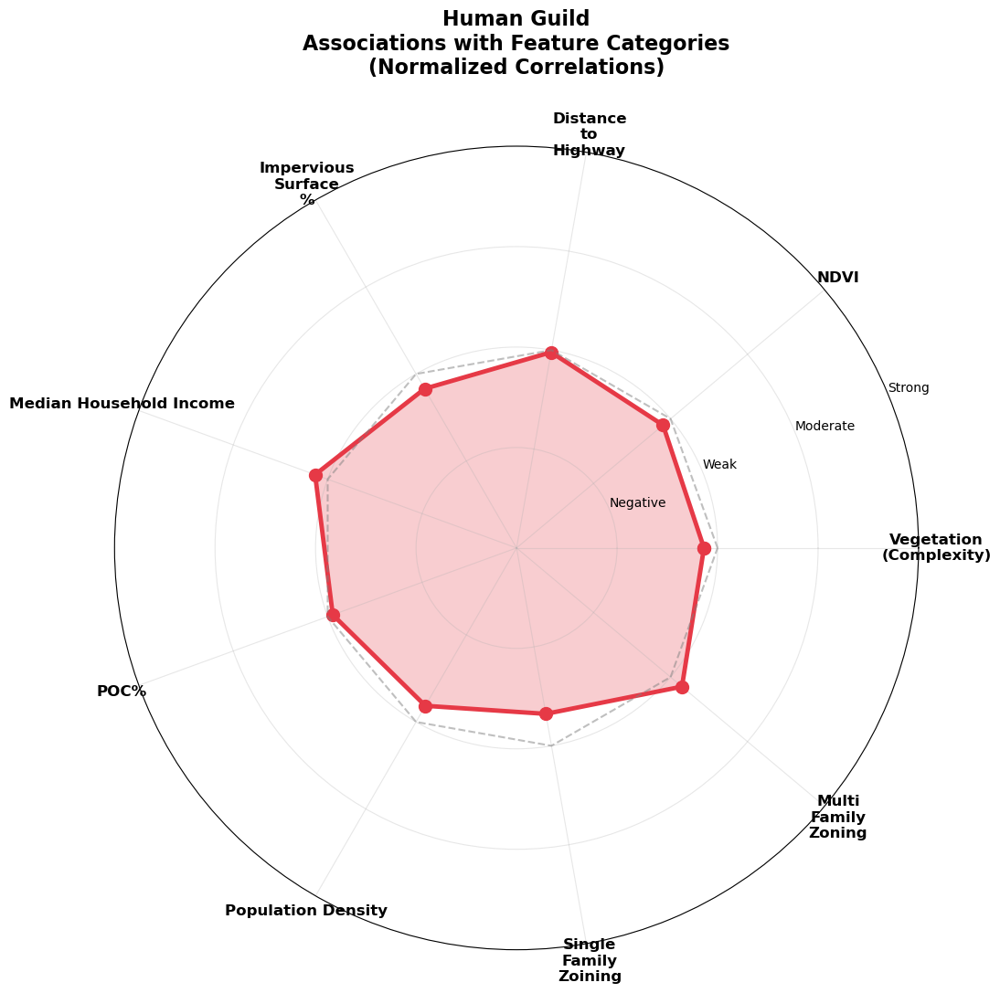

✓ Saved: ../results_images/guild_radar_human_normalized_4.26.26.png

shrubgrass - Vegetation
(Complexity): r=0.023, normalized=0.511
shrubgrass - NDVI: r=0.090, normalized=0.545
shrubgrass - Distance
to
Highway: r=0.109, normalized=0.555
shrubgrass - Impervious
Surface
%: r=-0.145, normalized=0.427
shrubgrass - Median Household Income: r=0.043, normalized=0.521
shrubgrass - POC%: r=-0.061, normalized=0.470
shrubgrass - Population Density: r=-0.121, normalized=0.439
shrubgrass - Single
Family
Zoining: r=0.054, normalized=0.527
shrubgrass - Multi
Family
Zoning: r=0.024, normalized=0.512


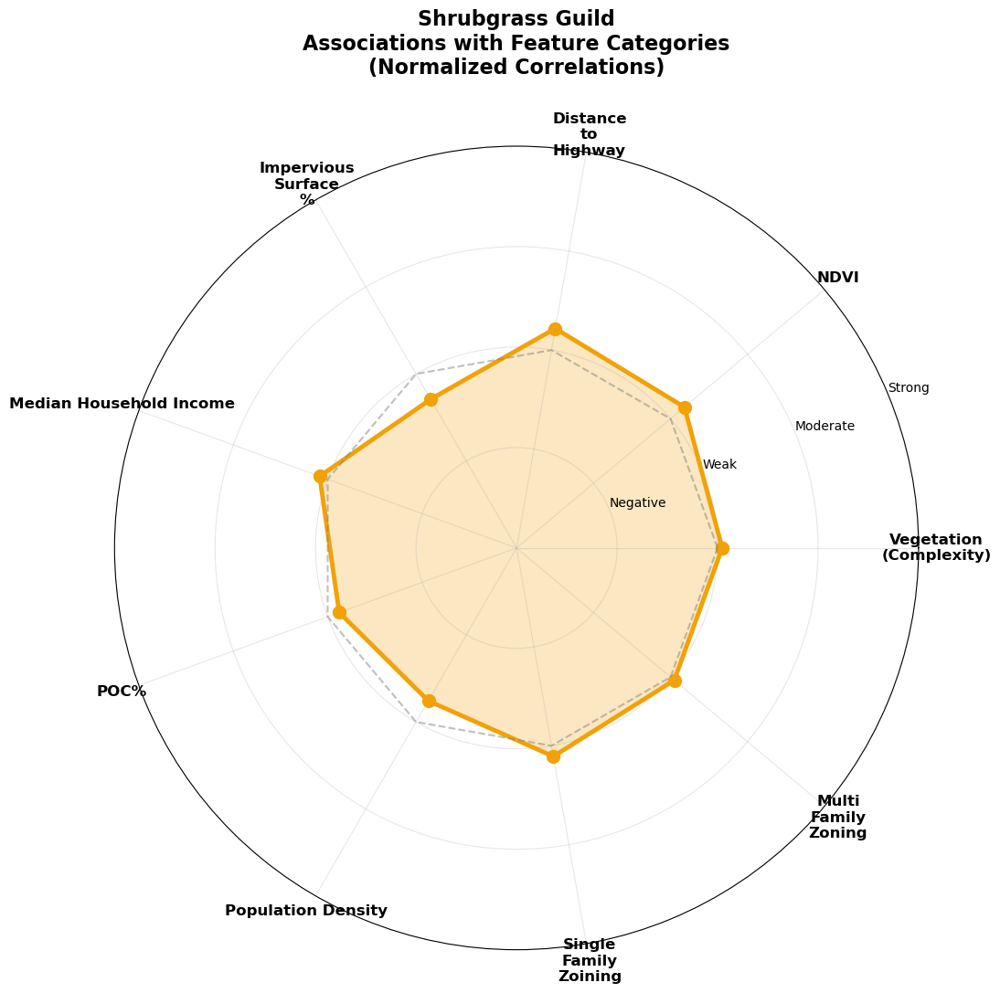

✓ Saved: ../results_images/guild_radar_shrubgrass_normalized_4.26.26.png

trees - Vegetation
(Complexity): r=0.028, normalized=0.514
trees - NDVI: r=0.222, normalized=0.611
trees - Distance
to
Highway: r=0.140, normalized=0.570
trees - Impervious
Surface
%: r=-0.225, normalized=0.387
trees - Median Household Income: r=0.170, normalized=0.585
trees - POC%: r=-0.172, normalized=0.414
trees - Population Density: r=-0.122, normalized=0.439
trees - Single
Family
Zoining: r=-0.105, normalized=0.447
trees - Multi
Family
Zoning: r=0.152, normalized=0.576


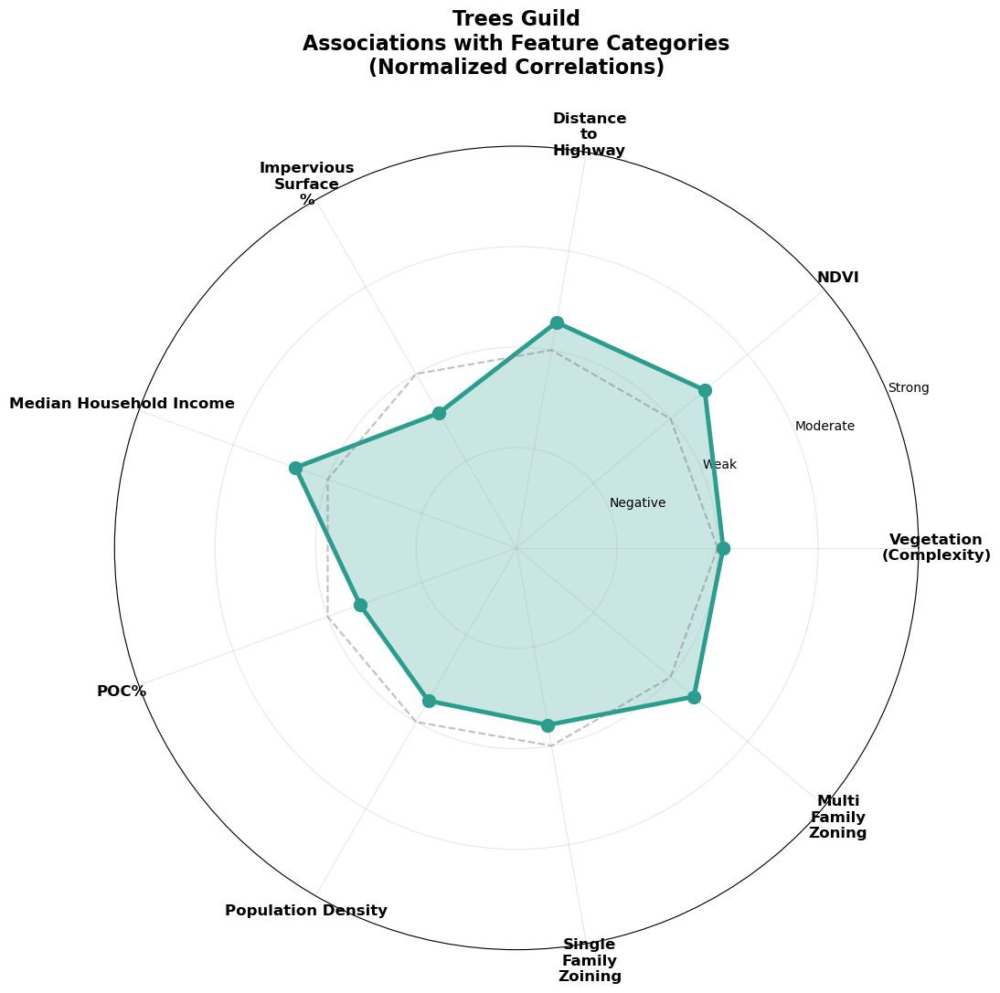

✓ Saved: ../results_images/guild_radar_trees_normalized_4.26.26.png

water - Vegetation
(Complexity): r=0.120, normalized=0.560
water - NDVI: r=0.104, normalized=0.552
water - Distance
to
Highway: r=-0.002, normalized=0.499
water - Impervious
Surface
%: r=-0.307, normalized=0.347
water - Median Household Income: r=0.021, normalized=0.510
water - POC%: r=0.028, normalized=0.514
water - Population Density: r=-0.083, normalized=0.458
water - Single
Family
Zoining: r=-0.087, normalized=0.457
water - Multi
Family
Zoning: r=-0.067, normalized=0.466


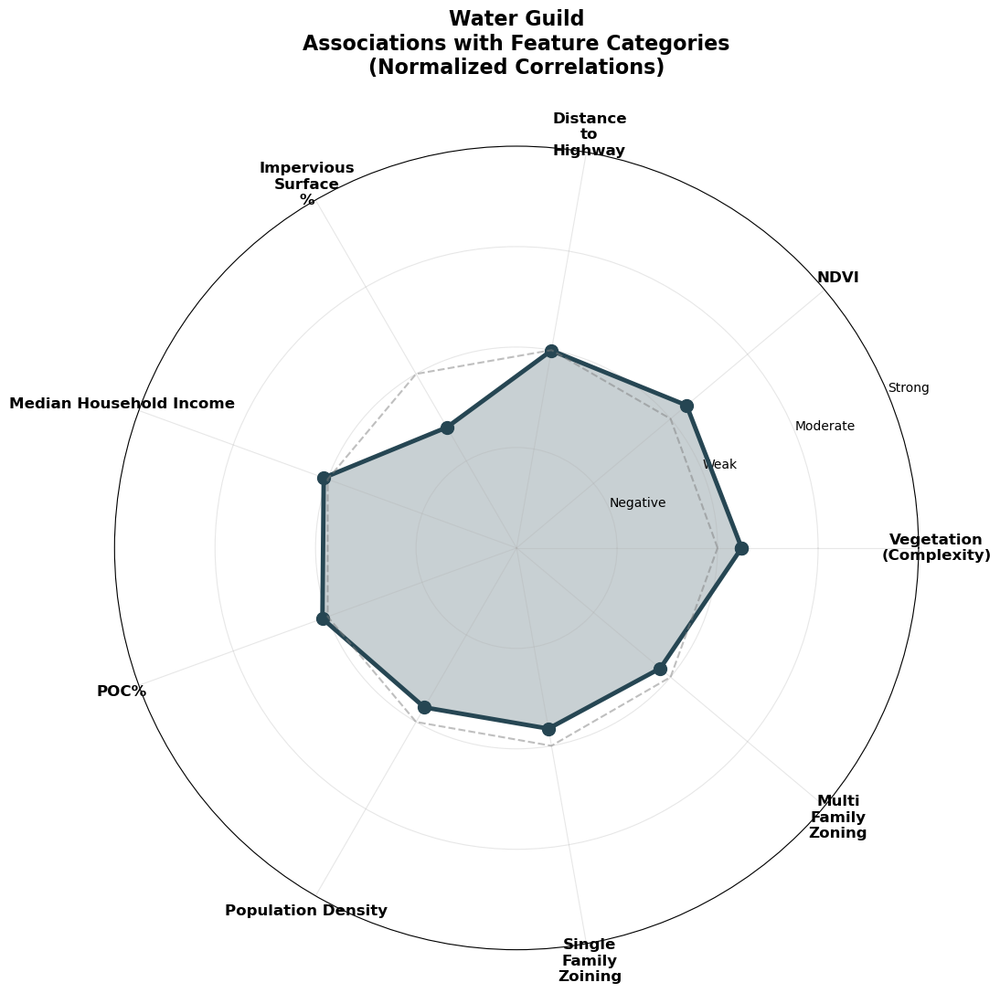

✓ Saved: ../results_images/guild_radar_water_normalized_4.26.26.png

native - Vegetation
(Complexity): r=0.042, normalized=0.521
native - NDVI: r=0.227, normalized=0.613
native - Distance
to
Highway: r=0.143, normalized=0.571
native - Impervious
Surface
%: r=-0.258, normalized=0.371
native - Median Household Income: r=0.158, normalized=0.579
native - POC%: r=-0.176, normalized=0.412
native - Population Density: r=-0.104, normalized=0.448
native - Single
Family
Zoining: r=-0.046, normalized=0.477
native - Multi
Family
Zoning: r=0.120, normalized=0.560


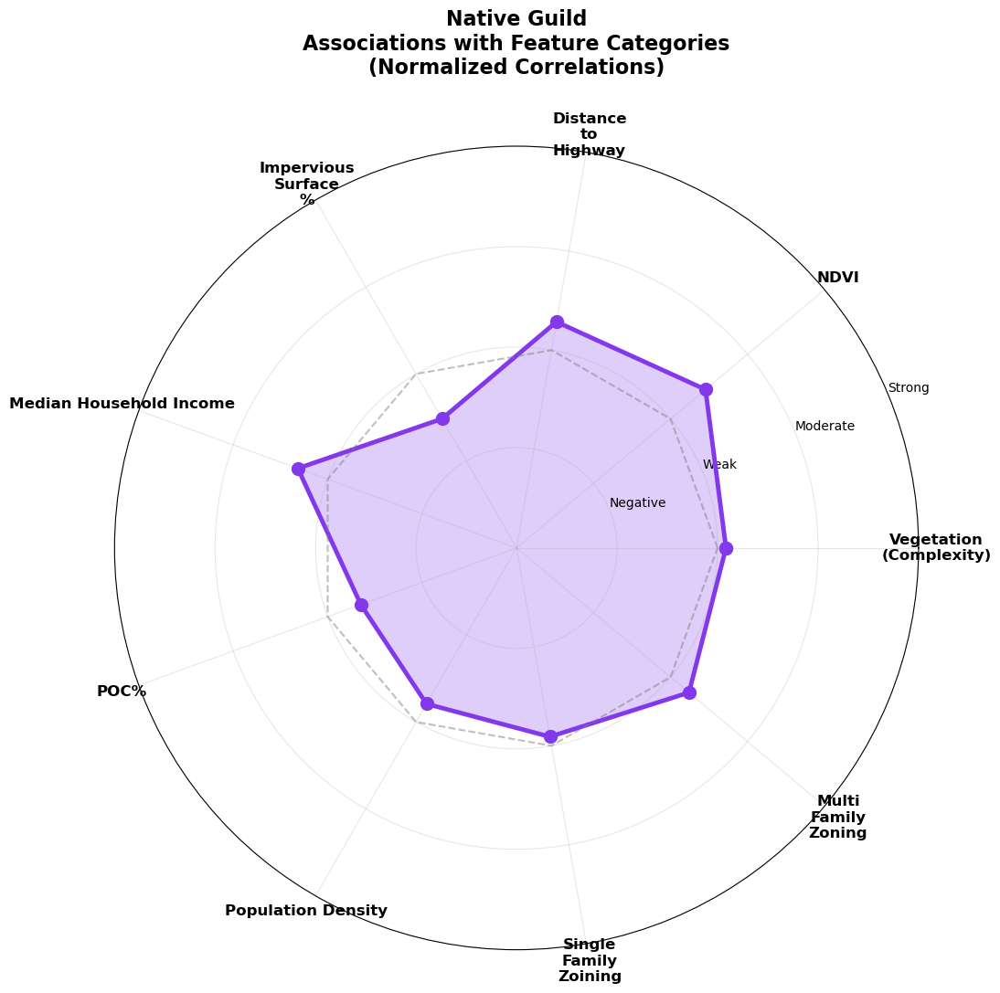

✓ Saved: ../results_images/guild_radar_native_normalized_4.26.26.png

nonnative - Vegetation
(Complexity): r=-0.065, normalized=0.468
nonnative - NDVI: r=-0.074, normalized=0.463
nonnative - Distance
to
Highway: r=-0.004, normalized=0.498
nonnative - Impervious
Surface
%: r=-0.086, normalized=0.457
nonnative - Median Household Income: r=0.041, normalized=0.520
nonnative - POC%: r=-0.042, normalized=0.479
nonnative - Population Density: r=-0.082, normalized=0.459
nonnative - Single
Family
Zoining: r=-0.129, normalized=0.435
nonnative - Multi
Family
Zoning: r=0.086, normalized=0.543


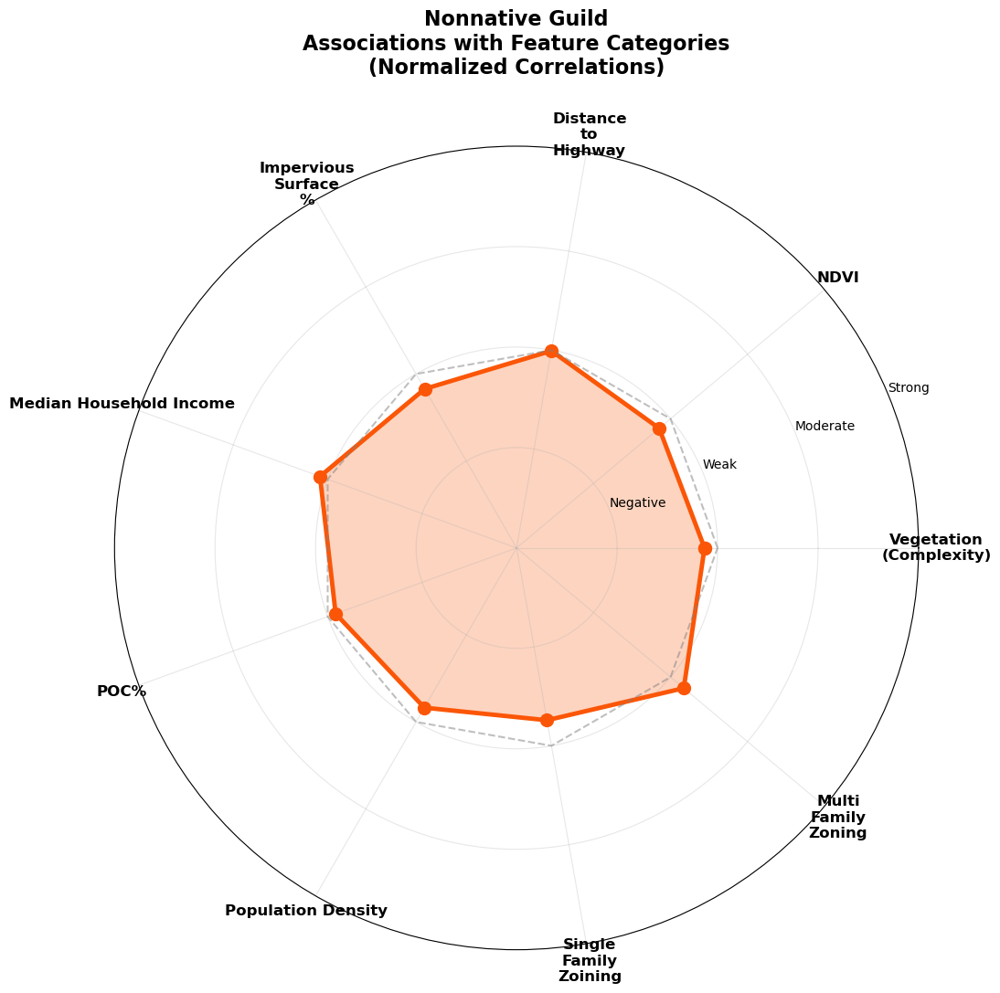

✓ Saved: ../results_images/guild_radar_nonnative_normalized_4.26.26.png



In [21]:
def plot_guild_feature_radar_normalized(df, guild_name='trees', save_path=None):
    """
    Radar plot with normalized correlations for better comparison
    """
    from math import pi
    
    richness_df = df[df['Diversity'] == 'Shannon diversity'].copy()
    
    # Define feature categories with more features
    feature_categories = {
        'Vegetation\n(Complexity)': ['mean_canopy'],
        'NDVI':['mean_ndvi'],
        'Distance\nto\nHighway':['highway_log1'],
        'Impervious\nSurface\n%': ['impervious_pct'],
        'Median Household Income': ['MED_INCOME'],
        'POC%':['POC_PER'],
        #'White %': ['NH_WHITE_PER'],
        #'Black%':['NH_BLACK_PER'],
        'Population Density':['pop_density_sqkm'],
        'Single\nFamily\nZoining':['SF_pct'],
        'Multi\nFamily\nZoning':['MF_pct']
    }
    
    guild_col = f'{guild_name}_estimator'
    
    # Calculate correlations
    category_scores = []
    category_labels = []
    
    for category, features in feature_categories.items():
        correlations = []
        for feature in features:
            if feature in richness_df.columns and guild_col in richness_df.columns:
                # Prepare data
                corr_data = richness_df[[feature, guild_col]].copy()
                corr_data[guild_col] = corr_data[guild_col].fillna(0)
                corr_data = corr_data.dropna()
                
                if len(corr_data) > 0:
                    # Use log-transformed guild values for correlation
                    guild_log = np.log1p(corr_data[guild_col])
                    
                    # Calculate correlation
                    corr = np.corrcoef(corr_data[feature], guild_log)[0, 1]
                    
                    if not np.isnan(corr):
                        correlations.append(corr)
        
        if correlations:
            mean_corr = np.mean(correlations)
            # Normalize to 0-1 scale: (corr + 1) / 2
            normalized_score = (mean_corr + 1) / 2
            category_scores.append(normalized_score)
            category_labels.append(category)
            
            print(f"{guild_name} - {category}: r={mean_corr:.3f}, normalized={normalized_score:.3f}")
    
    if len(category_scores) == 0:
        print(f"No valid data for {guild_name}")
        return
    
    # Number of variables
    N = len(category_labels)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    category_scores += category_scores[:1]
    angles += angles[:1]
    
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    
    color = guild_colors.get(guild_name, '#999999')
    
    fig, ax = plt.subplots(figsize=(11, 11), subplot_kw=dict(projection='polar'))
    
    # Plot
    ax.plot(angles, category_scores, 'o-', linewidth=3.5, color=color, markersize=10)
    ax.fill(angles, category_scores, alpha=0.25, color=color)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(category_labels, fontsize=12, fontweight='bold')
    
    # Set radial limits
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['Negative', 'Weak', 'Moderate', 'Strong'], fontsize=10)
    
    ax.set_title(f'{guild_name.title()} Guild\nAssociations with Feature Categories\n(Normalized Correlations)',
                fontsize=16, fontweight='bold', pad=30)
    
    # Add reference circle at 0.5 (no correlation)
    ax.plot(angles, [0.5] * len(angles), '--', color='gray', alpha=0.5, linewidth=1.5)
    
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}\n")

# Create radar plots for each guild
guilds = ['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative']

for guild in guilds:
    plot_guild_feature_radar_normalized(combined_df, guild_name=guild,
                                       save_path=f'../results_images/guild_radar_{guild}_normalized_4.26.26.png')

In [ ]:
# Save to the data folder
combined_df.to_csv('../data/combined_guild_diversity_4.26.25.csv', index=False)

## Habitat Radial Graphs with RF (scaled)

human - Vegetation
(Complexity): normalized importance=0.0754, scaled=0.4553
human - NDVI: normalized importance=0.0933, scaled=0.5637
human - Distance
to
Highway: normalized importance=0.0912, scaled=0.5508
human - Impervious
Surface
%: normalized importance=0.1655, scaled=1.0000
human - Median Household Income: normalized importance=0.0762, scaled=0.4603
human - POC%: normalized importance=0.0693, scaled=0.4188
human - Black%: normalized importance=0.0887, scaled=0.5358
human - Asian%: normalized importance=0.1469, scaled=0.8875
human - Population Density: normalized importance=0.0820, scaled=0.4952
human - Single
Family
Zoning: normalized importance=0.0589, scaled=0.3562
human - Multi
Family
Zoning: normalized importance=0.0527, scaled=0.3185


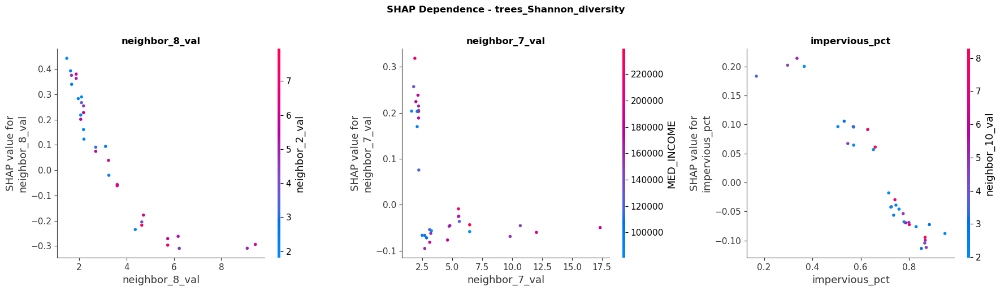

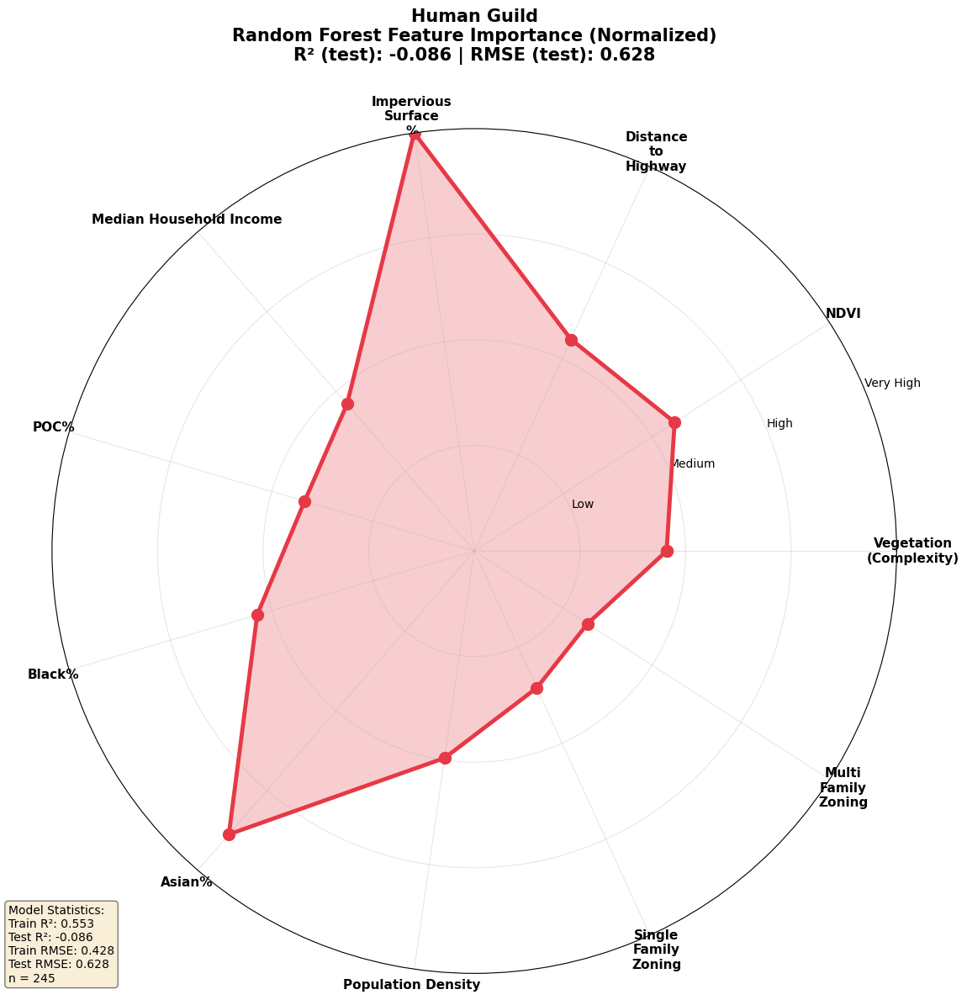

✓ Saved: ../results_images/guild_radar_human_rf_importance_4.26.26.png
Test R²: -0.086, Test RMSE: 0.628

shrubgrass - Vegetation
(Complexity): normalized importance=0.0619, scaled=0.4727
shrubgrass - NDVI: normalized importance=0.0700, scaled=0.5351
shrubgrass - Distance
to
Highway: normalized importance=0.1309, scaled=1.0000
shrubgrass - Impervious
Surface
%: normalized importance=0.1257, scaled=0.9602
shrubgrass - Median Household Income: normalized importance=0.1056, scaled=0.8068
shrubgrass - POC%: normalized importance=0.0908, scaled=0.6935
shrubgrass - Black%: normalized importance=0.0811, scaled=0.6194
shrubgrass - Asian%: normalized importance=0.0982, scaled=0.7502
shrubgrass - Population Density: normalized importance=0.1255, scaled=0.9590
shrubgrass - Single
Family
Zoning: normalized importance=0.0693, scaled=0.5296
shrubgrass - Multi
Family
Zoning: normalized importance=0.0412, scaled=0.3145


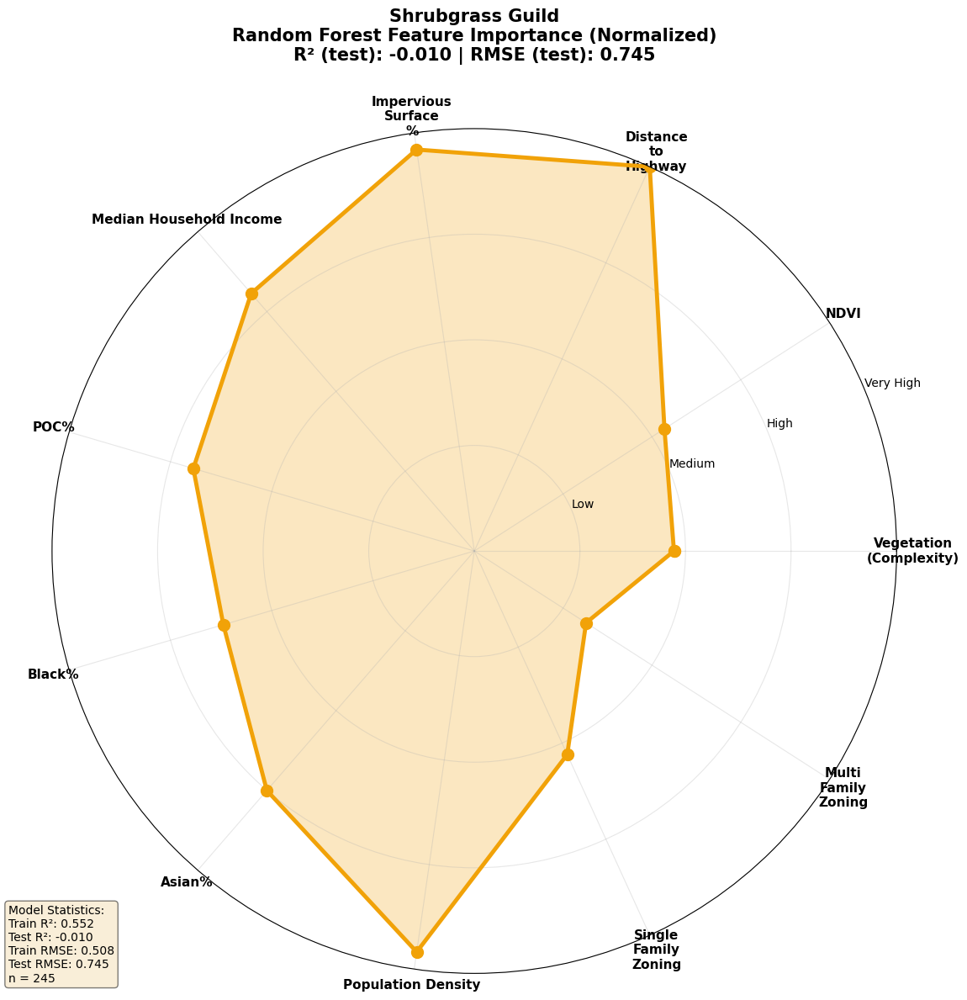

✓ Saved: ../results_images/guild_radar_shrubgrass_rf_importance_4.26.26.png
Test R²: -0.010, Test RMSE: 0.745

trees - Vegetation
(Complexity): normalized importance=0.0660, scaled=0.4211
trees - NDVI: normalized importance=0.1540, scaled=0.9822
trees - Distance
to
Highway: normalized importance=0.1568, scaled=1.0000
trees - Impervious
Surface
%: normalized importance=0.1456, scaled=0.9282
trees - Median Household Income: normalized importance=0.0554, scaled=0.3533
trees - POC%: normalized importance=0.0542, scaled=0.3455
trees - Black%: normalized importance=0.0664, scaled=0.4231
trees - Asian%: normalized importance=0.0902, scaled=0.5752
trees - Population Density: normalized importance=0.0922, scaled=0.5882
trees - Single
Family
Zoning: normalized importance=0.0574, scaled=0.3657
trees - Multi
Family
Zoning: normalized importance=0.0617, scaled=0.3934


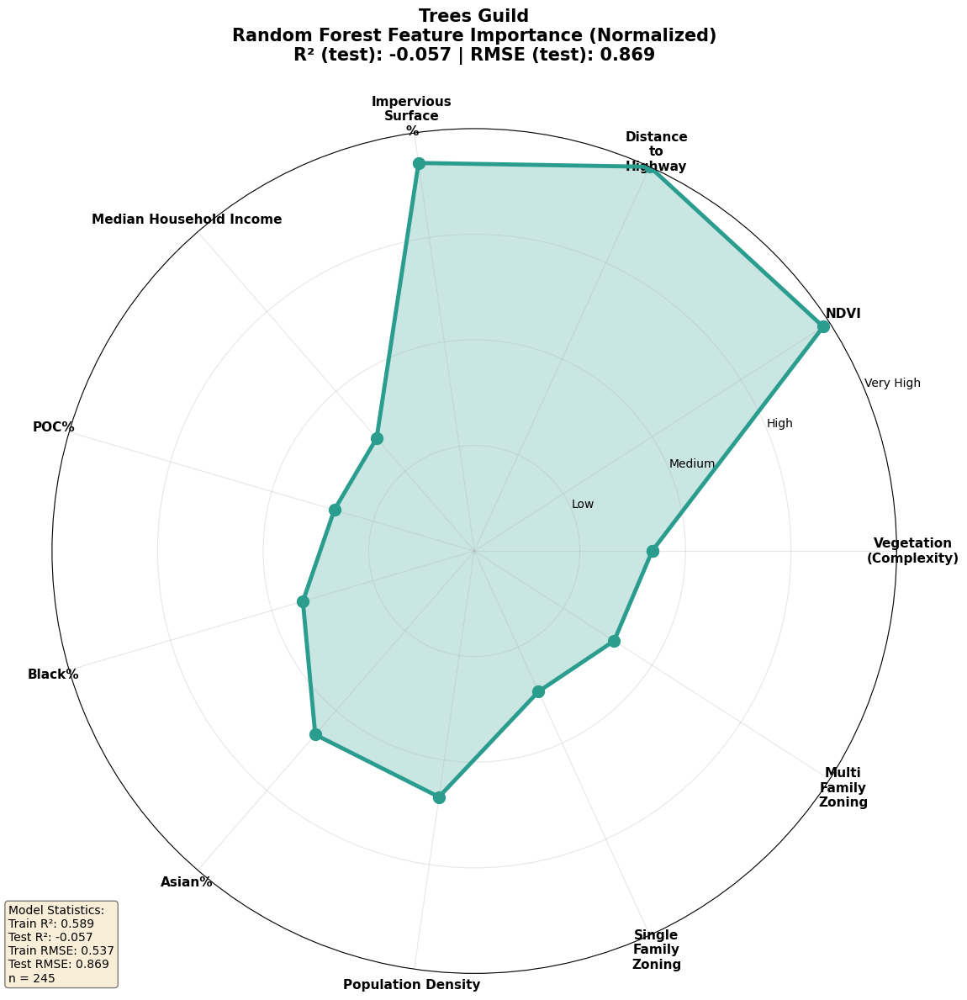

✓ Saved: ../results_images/guild_radar_trees_rf_importance_4.26.26.png
Test R²: -0.057, Test RMSE: 0.869

water - Vegetation
(Complexity): normalized importance=0.0255, scaled=0.0419
water - NDVI: normalized importance=0.0570, scaled=0.0937
water - Distance
to
Highway: normalized importance=0.0198, scaled=0.0325
water - Impervious
Surface
%: normalized importance=0.6088, scaled=1.0000
water - Median Household Income: normalized importance=0.0312, scaled=0.0513
water - POC%: normalized importance=0.0716, scaled=0.1176
water - Black%: normalized importance=0.0329, scaled=0.0541
water - Asian%: normalized importance=0.0868, scaled=0.1426
water - Population Density: normalized importance=0.0521, scaled=0.0856
water - Single
Family
Zoning: normalized importance=0.0091, scaled=0.0150
water - Multi
Family
Zoning: normalized importance=0.0051, scaled=0.0084


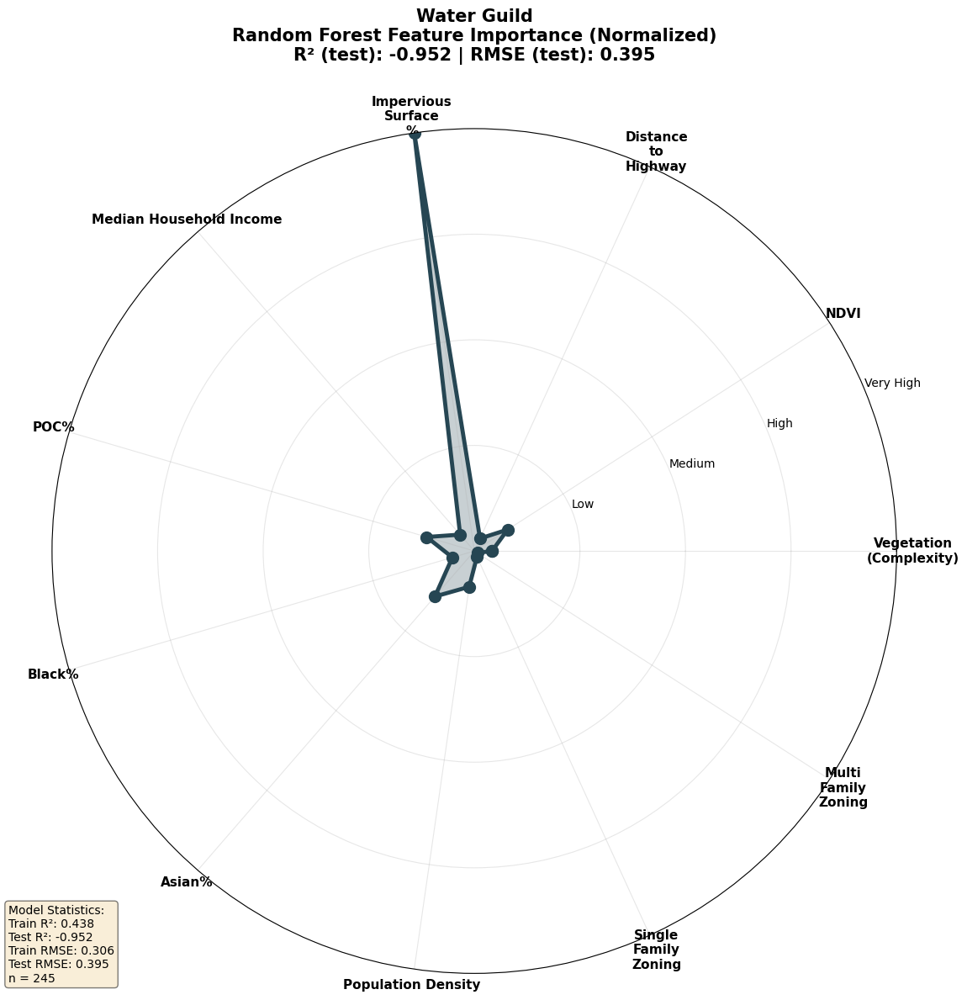

✓ Saved: ../results_images/guild_radar_water_rf_importance_4.26.26.png
Test R²: -0.952, Test RMSE: 0.395

native - Vegetation
(Complexity): normalized importance=0.0537, scaled=0.2599
native - NDVI: normalized importance=0.0692, scaled=0.3350
native - Distance
to
Highway: normalized importance=0.1647, scaled=0.7977
native - Impervious
Surface
%: normalized importance=0.2065, scaled=1.0000
native - Median Household Income: normalized importance=0.0720, scaled=0.3488
native - POC%: normalized importance=0.0496, scaled=0.2405
native - Black%: normalized importance=0.0686, scaled=0.3325
native - Asian%: normalized importance=0.1000, scaled=0.4846
native - Population Density: normalized importance=0.0979, scaled=0.4743
native - Single
Family
Zoning: normalized importance=0.0540, scaled=0.2614
native - Multi
Family
Zoning: normalized importance=0.0638, scaled=0.3090


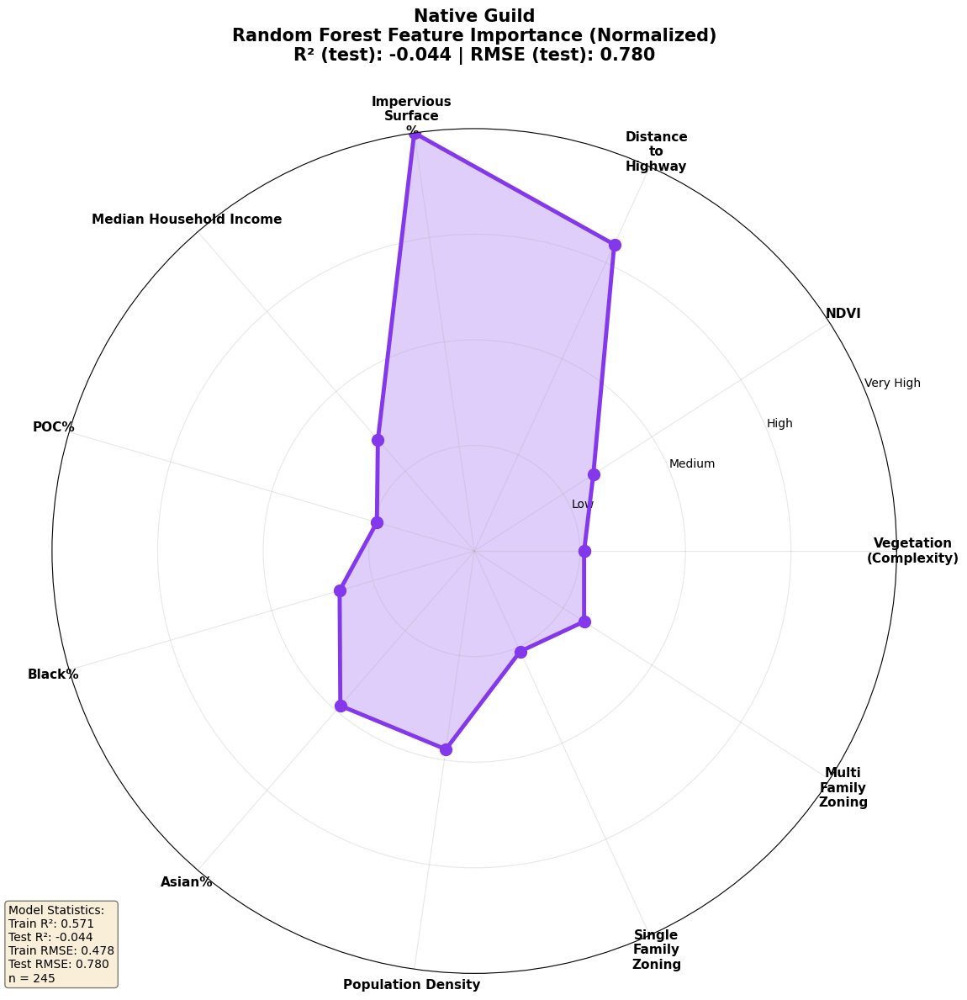

✓ Saved: ../results_images/guild_radar_native_rf_importance_4.26.26.png
Test R²: -0.044, Test RMSE: 0.780

nonnative - Vegetation
(Complexity): normalized importance=0.0572, scaled=0.3416
nonnative - NDVI: normalized importance=0.1633, scaled=0.9747
nonnative - Distance
to
Highway: normalized importance=0.1004, scaled=0.5990
nonnative - Impervious
Surface
%: normalized importance=0.1423, scaled=0.8489
nonnative - Median Household Income: normalized importance=0.0441, scaled=0.2632
nonnative - POC%: normalized importance=0.0545, scaled=0.3254
nonnative - Black%: normalized importance=0.1167, scaled=0.6964
nonnative - Asian%: normalized importance=0.1676, scaled=1.0000
nonnative - Population Density: normalized importance=0.0761, scaled=0.4540
nonnative - Single
Family
Zoning: normalized importance=0.0341, scaled=0.2035
nonnative - Multi
Family
Zoning: normalized importance=0.0436, scaled=0.2604


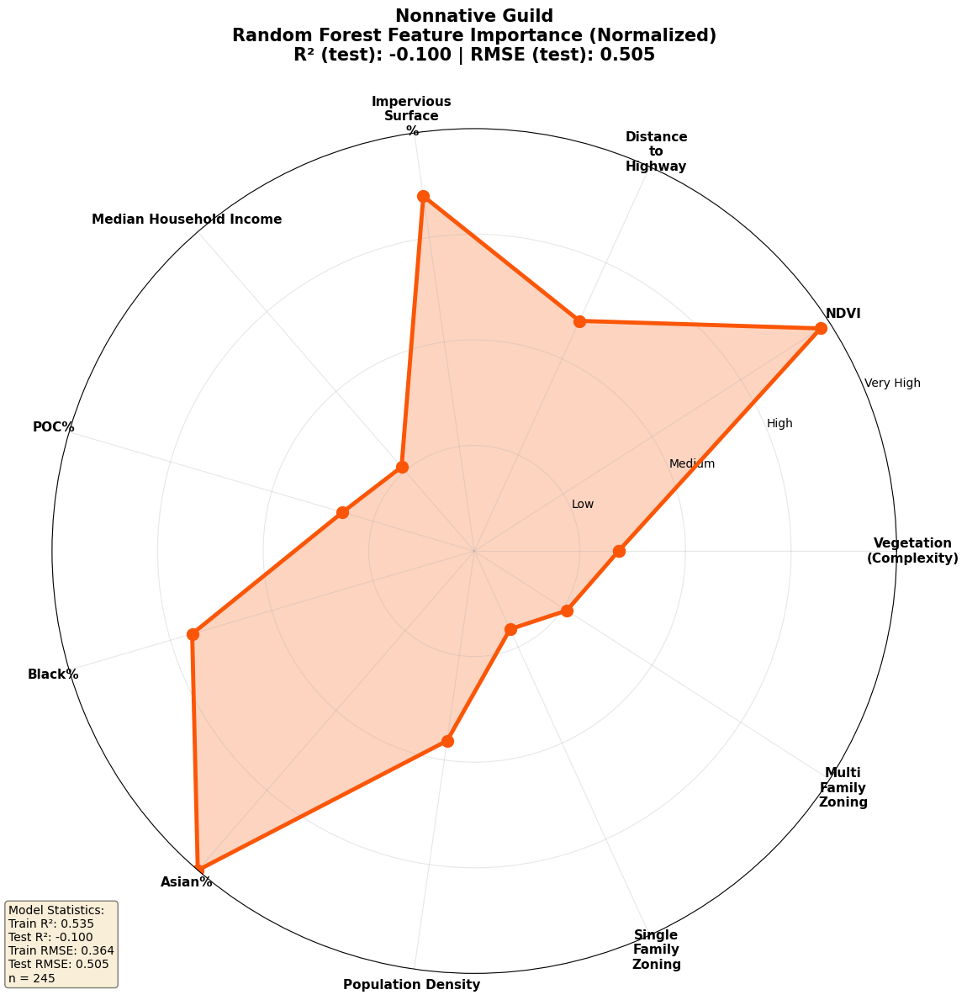

✓ Saved: ../results_images/guild_radar_nonnative_rf_importance_4.26.26.png
Test R²: -0.100, Test RMSE: 0.505



In [112]:
def plot_guild_feature_radar_rf(df, guild_name='trees', save_path=None):
    """
    Radar plot with Random Forest feature importance (normalized) and model statistics
    """
    from math import pi
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import r2_score, mean_squared_error
    
    richness_df = df[df['Diversity'] == 'Shannon diversity'].copy()
    
    # Define feature categories
    feature_categories = {
        'Vegetation\n(Complexity)': ['mean_canopy'],
        'NDVI': ['mean_ndvi'],
        'Distance\nto\nHighway': ['highway_log1'],
        'Impervious\nSurface\n%': ['impervious_pct'],
        'Median Household Income': ['MED_INCOME'],
        'POC%': ['POC_PER'],
        #'White %': ['NH_WHITE_PER'],
        'Black%': ['NH_BLACK_PER'],
        'Asian%': ['NH_ASIAN_PER'],
        #'Latine%': ['NH_LATINE_PER'],
        'Population Density': ['pop_density_sqkm'],
        'Single\nFamily\nZoning': ['SF_pct'],
        'Multi\nFamily\nZoning': ['MF_pct']
    }
    
    guild_col = f'{guild_name}_estimator'
    
    # Get all features
    all_features = [feat for feats in feature_categories.values() for feat in feats]
    
    # Prepare data
    model_data = richness_df[all_features + [guild_col]].copy()
    model_data[guild_col] = model_data[guild_col].fillna(0)
    model_data = model_data.dropna()
    
    if len(model_data) < 10:
        print(f"Not enough data for {guild_name}")
        return
    
    X = model_data[all_features]
    y = np.log1p(model_data[guild_col])  # Log transform
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Train Random Forest
    rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10, min_samples_leaf=5)
    rf.fit(X_train, y_train)
    
    # Get predictions and metrics
    y_pred_train = rf.predict(X_train)
    y_pred_test = rf.predict(X_test)
    
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    
    # Get feature importances (already normalized to sum to 1 by sklearn)
    feature_importance = dict(zip(all_features, rf.feature_importances_))
    
    # Calculate category importance (average of features in category)
    category_scores = []
    category_labels = []
    category_importances = {}
    
    for category, features in feature_categories.items():
        importances = [feature_importance[feat] for feat in features if feat in feature_importance]
        if importances:
            mean_importance = np.mean(importances)
            category_importances[category] = mean_importance
    
    # Normalize category importances to sum to 1
    total_importance = sum(category_importances.values())
    category_importances_normalized = {cat: imp/total_importance for cat, imp in category_importances.items()}
    
    # Scale normalized importances to 0-1 range for better visualization
    max_norm_importance = max(category_importances_normalized.values())
    
    for category, features in feature_categories.items():
        if category in category_importances_normalized:
            normalized_score = category_importances_normalized[category] / max_norm_importance
            category_scores.append(normalized_score)
            category_labels.append(category)
            print(f"{guild_name} - {category}: normalized importance={category_importances_normalized[category]:.4f}, scaled={normalized_score:.4f}")
    
    if len(category_scores) == 0:
        print(f"No valid data for {guild_name}")
        return
    
    # Number of variables
    N = len(category_labels)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    category_scores += category_scores[:1]
    angles += angles[:1]
    
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    
    color = guild_colors.get(guild_name, '#999999')
    
    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    
    # Plot
    ax.plot(angles, category_scores, 'o-', linewidth=3.5, color=color, markersize=10)
    ax.fill(angles, category_scores, alpha=0.25, color=color)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(category_labels, fontsize=11, fontweight='bold')
    
    # Set radial limits
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['Low', 'Medium', 'High', 'Very High'], fontsize=10)
    
    # Title with statistics
    title_text = (f'{guild_name.title()} Guild\n'
                  f'Random Forest Feature Importance (Normalized)\n'
                  f'R² (test): {r2_test:.3f} | RMSE (test): {rmse_test:.3f}')
    ax.set_title(title_text, fontsize=15, fontweight='bold', pad=30)
    
    ax.grid(True, alpha=0.3)
    
    # Add text box with detailed statistics (bottom left only)
    stats_text = (f'Model Statistics:\n'
                  f'Train R²: {r2_train:.3f}\n'
                  f'Test R²: {r2_test:.3f}\n'
                  f'Train RMSE: {rmse_train:.3f}\n'
                  f'Test RMSE: {rmse_test:.3f}\n'
                  f'n = {len(model_data)}')
    
    plt.figtext(0.02, 0.02, stats_text, fontsize=10, 
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5),
                verticalalignment='bottom')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")
    print(f"Test R²: {r2_test:.3f}, Test RMSE: {rmse_test:.3f}\n")
    
    return {
        'r2_train': r2_train,
        'r2_test': r2_test,
        'rmse_train': rmse_train,
        'rmse_test': rmse_test,
        'feature_importances': category_importances_normalized,
        'model': rf
    }

# Create radar plots for each guild
guilds = ['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative']

results = {}
for guild in guilds:
    results[guild] = plot_guild_feature_radar_rf(
        combined_df, 
        guild_name=guild,
        save_path=f'../results_images/guild_radar_{guild}_rf_importance_4.26.26.png'
    )

## Habitat SHAP values with KNN-RF

In [ ]:
#import necessary libraries
#%pip install shap scikit-learn matplotlib

In [108]:
import os
print(os.getcwd())
print([f for f in os.listdir('.') if 'estim' in f.lower()])

/home/oliver/gdrive/Chapter1_SF_redlining_Rprj/Code
['estimator_hab.py', 'estimator.py', 'estimator', 'estimator_hab']



KNN-RF | HUMAN | Species richness
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_neighbors': 7}


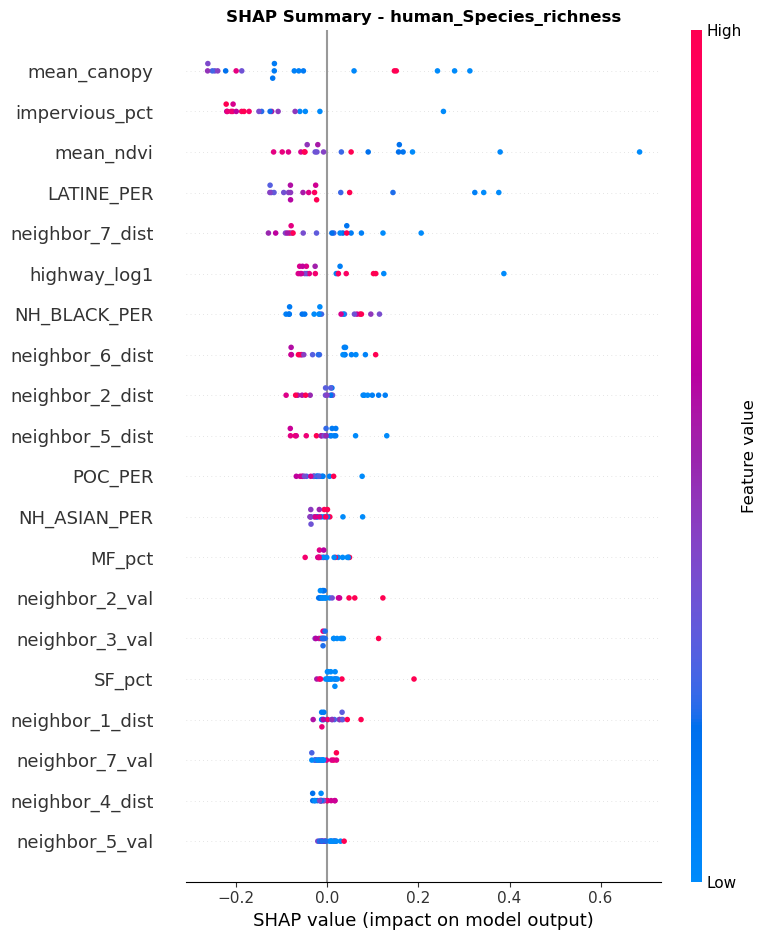

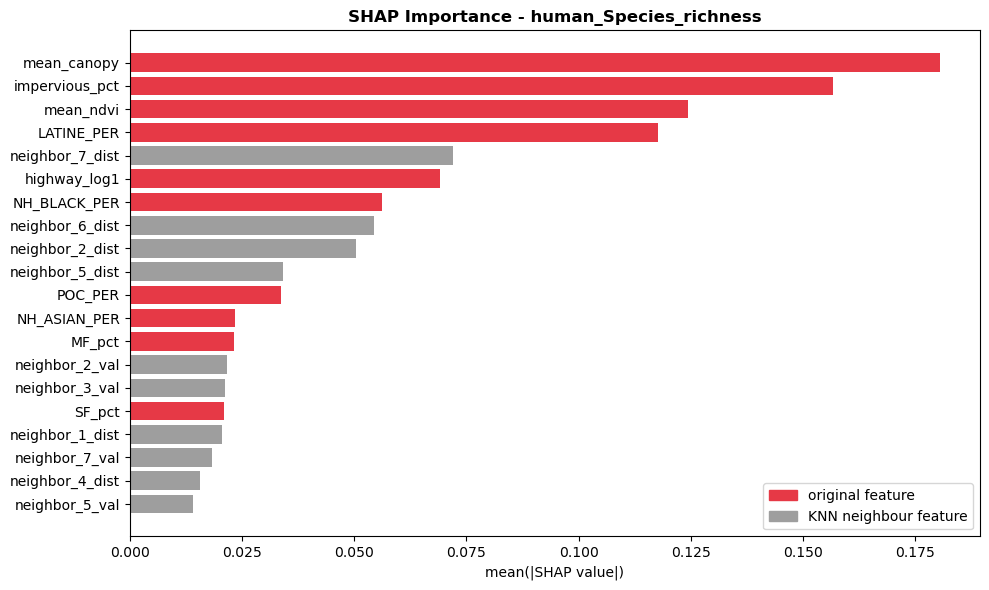

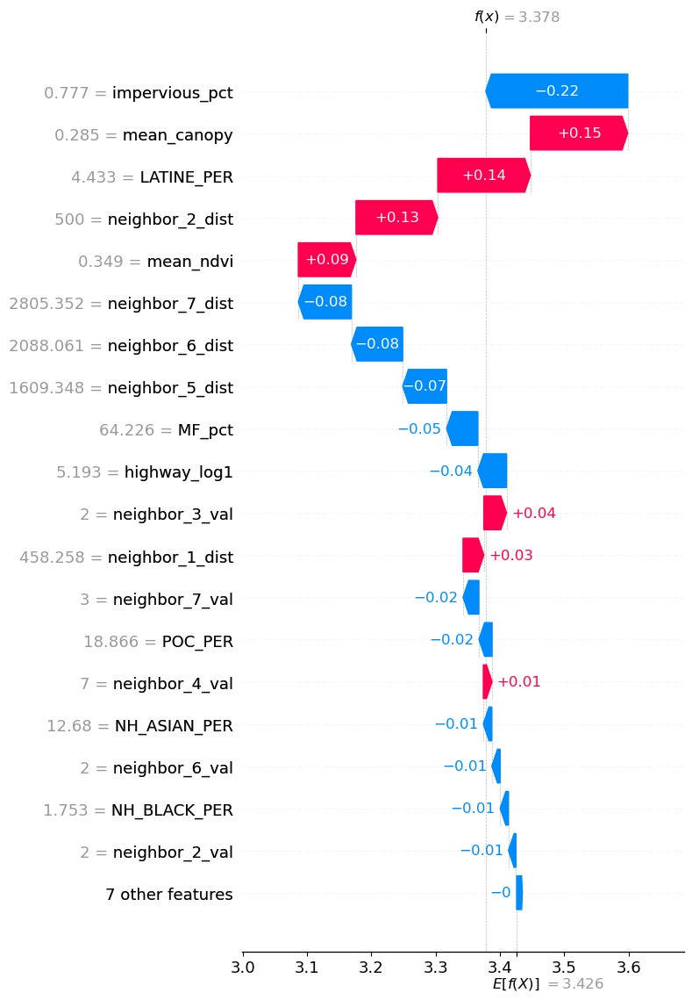

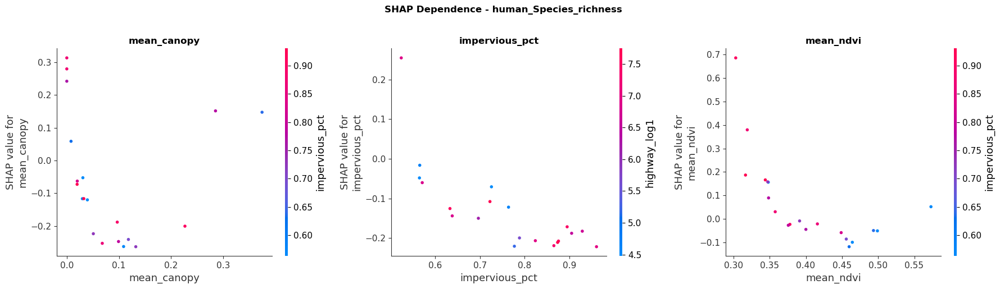


=== Model Performance ===
OOB Score: 0.0534
CV RMSE: 1.7033 (+/- 0.4102)
CV R²:   -0.0854 | CV MAE: 1.3147
Train RMSE: 0.6447 | Train R²: 0.8729
Test  RMSE: 1.6940 | Test  R²: -0.1354 | Test MAE: 1.2864

=== Top 10 Features ===
        feature  importance              type
    mean_canopy    0.180399          original
 impervious_pct    0.156558          original
      mean_ndvi    0.124414          original
     LATINE_PER    0.117627          original
neighbor_7_dist    0.072001 neighbor distance
   highway_log1    0.069181          original
   NH_BLACK_PER    0.056167          original
neighbor_6_dist    0.054449 neighbor distance
neighbor_2_dist    0.050337 neighbor distance
neighbor_5_dist    0.034064 neighbor distance

KNN-RF | HUMAN | Shannon diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_neighbors': 10}


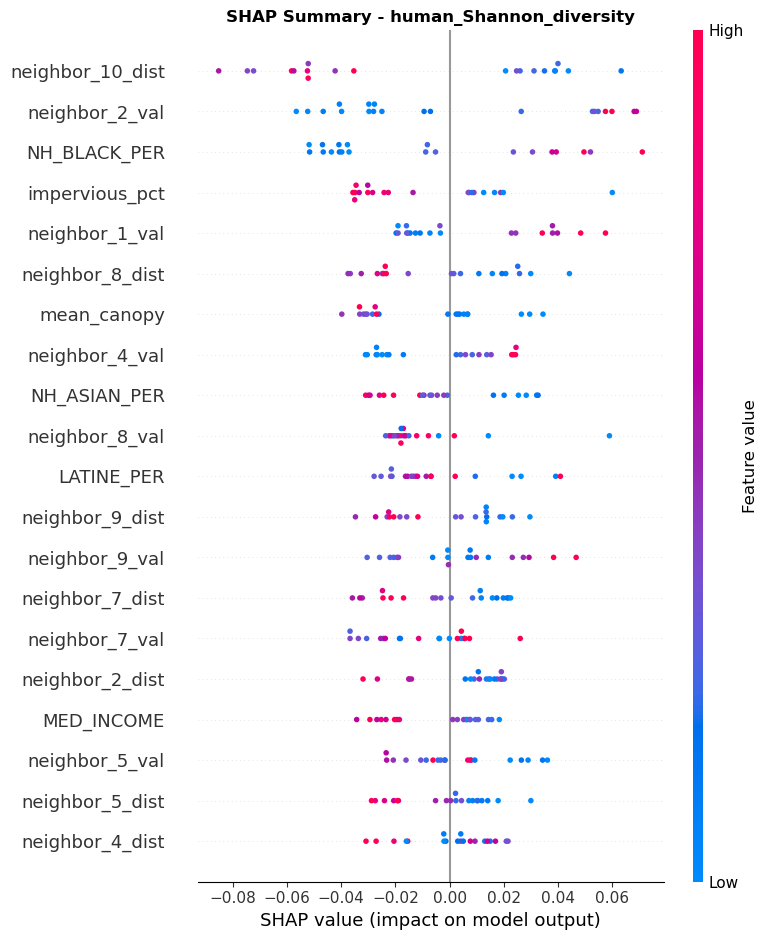

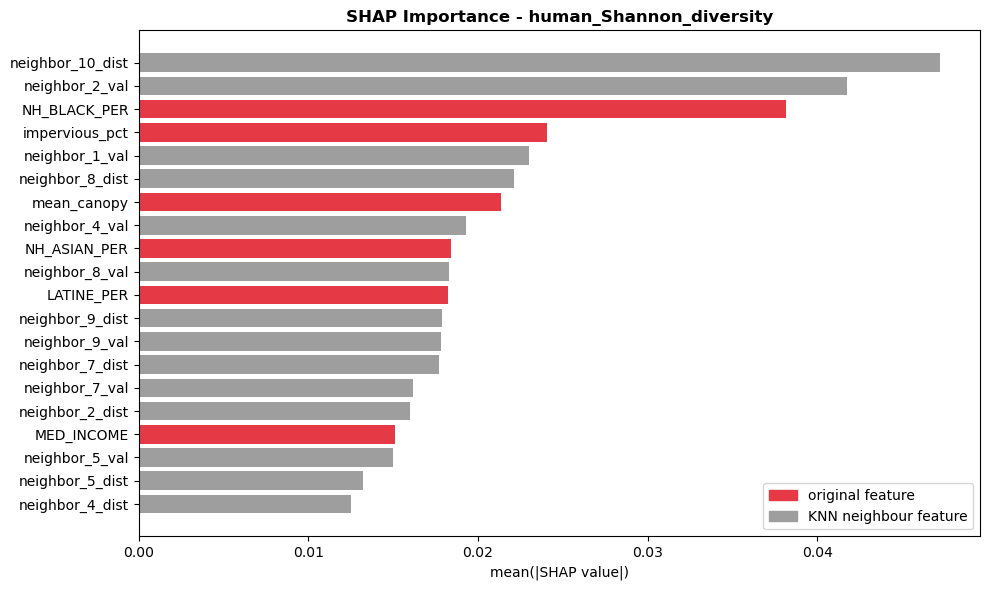

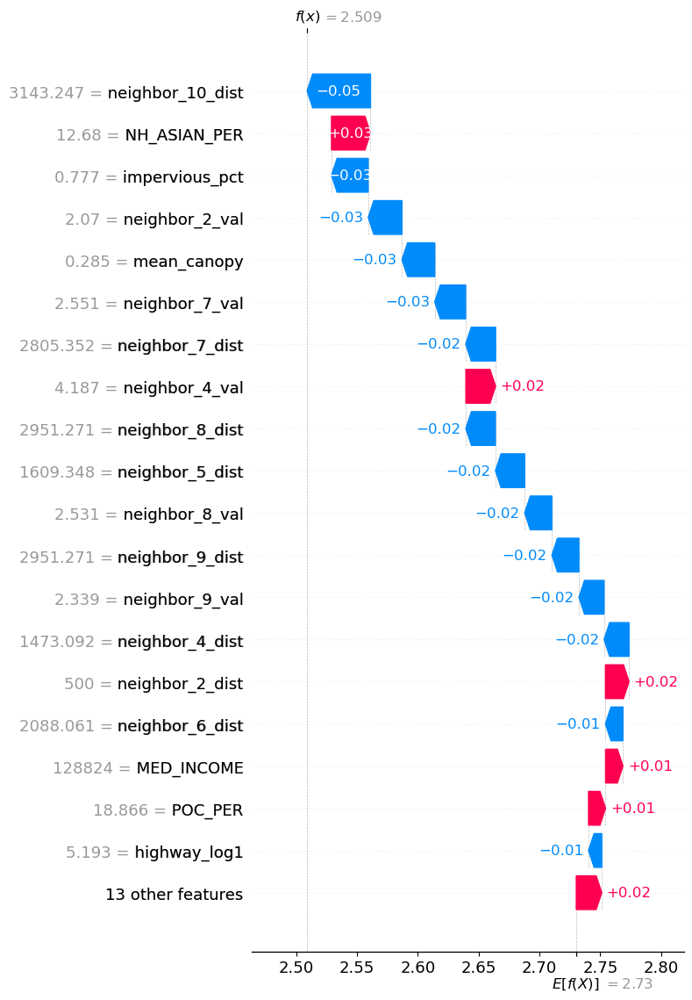

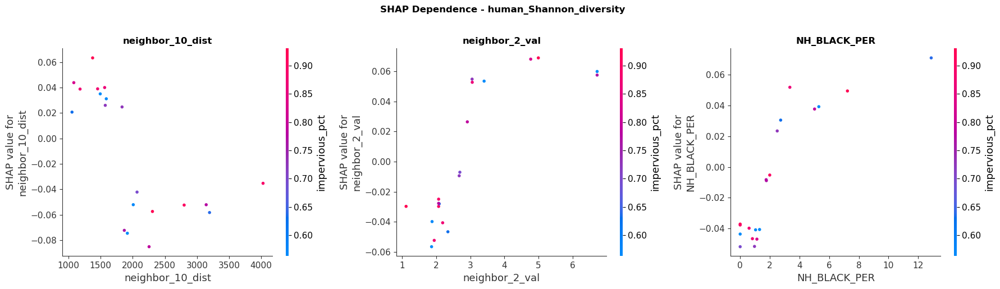


=== Model Performance ===
OOB Score: -0.0449
CV RMSE: 1.0093 (+/- 0.2606)
CV R²:   -0.0364 | CV MAE: 0.7357
Train RMSE: 0.7753 | Train R²: 0.4388
Test  RMSE: 0.8921 | Test  R²: -1.3003 | Test MAE: 0.7502

=== Top 10 Features ===
         feature  importance              type
neighbor_10_dist    0.047229 neighbor distance
  neighbor_2_val    0.041737    neighbor value
    NH_BLACK_PER    0.038142          original
  impervious_pct    0.024086          original
  neighbor_1_val    0.023015    neighbor value
 neighbor_8_dist    0.022140 neighbor distance
     mean_canopy    0.021351          original
  neighbor_4_val    0.019274    neighbor value
    NH_ASIAN_PER    0.018389          original
  neighbor_8_val    0.018271    neighbor value

KNN-RF | HUMAN | Simpson diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_neighbors': 10}


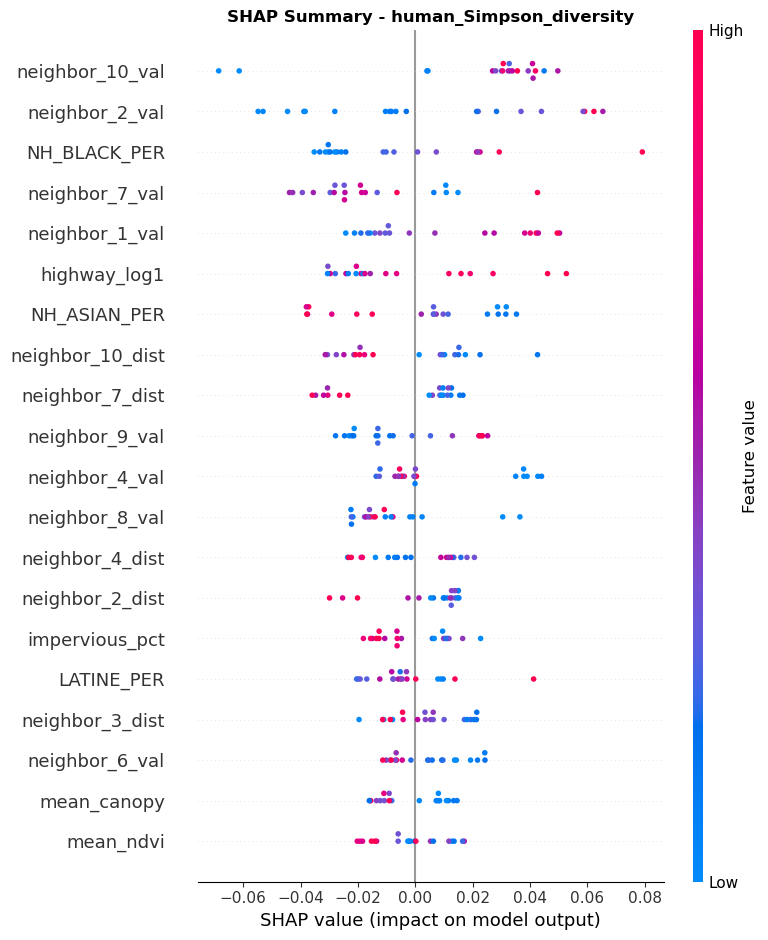

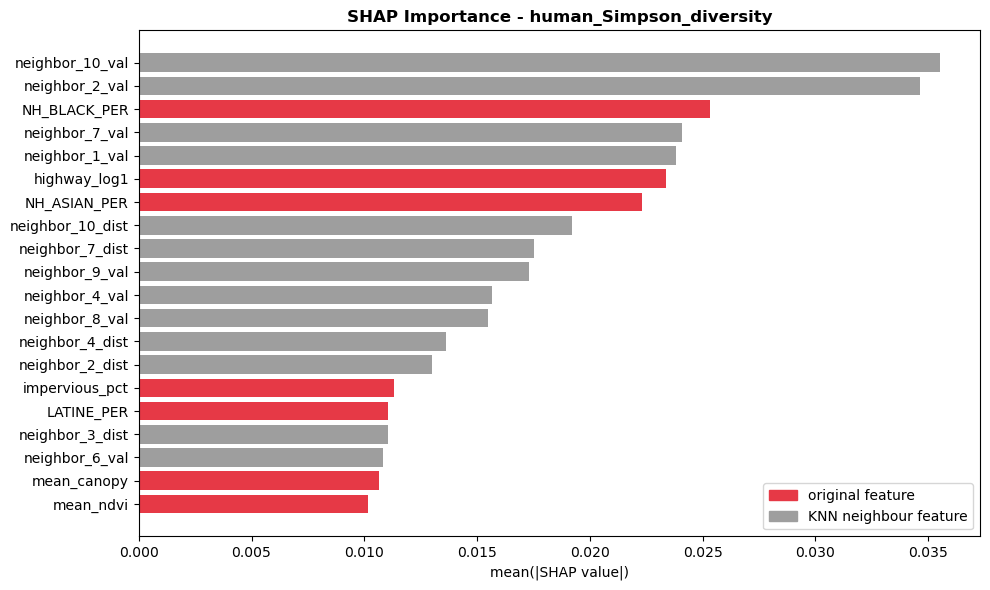

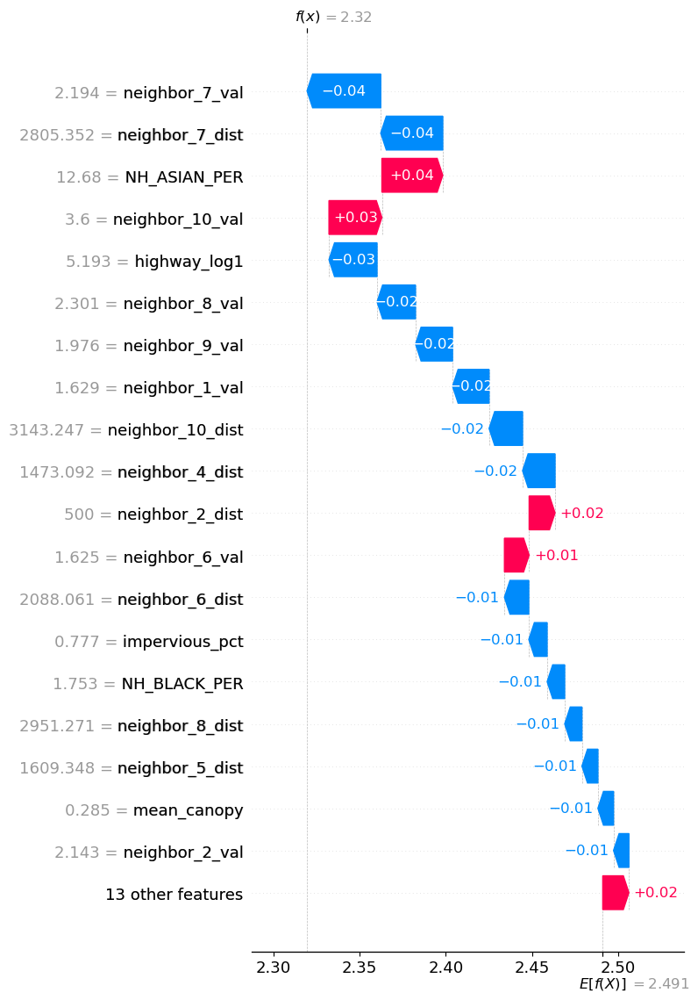

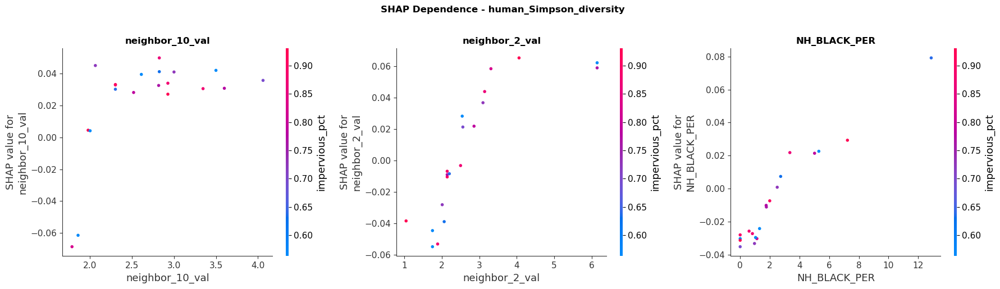


=== Model Performance ===
OOB Score: -0.0650
CV RMSE: 0.8803 (+/- 0.1995)
CV R²:   -0.0612 | CV MAE: 0.6560
Train RMSE: 0.6682 | Train R²: 0.4387
Test  RMSE: 0.8934 | Test  R²: -1.5134 | Test MAE: 0.7909

=== Top 10 Features ===
         feature  importance              type
 neighbor_10_val    0.035520    neighbor value
  neighbor_2_val    0.034655    neighbor value
    NH_BLACK_PER    0.025341          original
  neighbor_7_val    0.024092    neighbor value
  neighbor_1_val    0.023797    neighbor value
    highway_log1    0.023365          original
    NH_ASIAN_PER    0.022311          original
neighbor_10_dist    0.019218 neighbor distance
 neighbor_7_dist    0.017502 neighbor distance
  neighbor_9_val    0.017289    neighbor value

KNN-RF | SHRUBGRASS | Species richness
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_neighbors': 10}


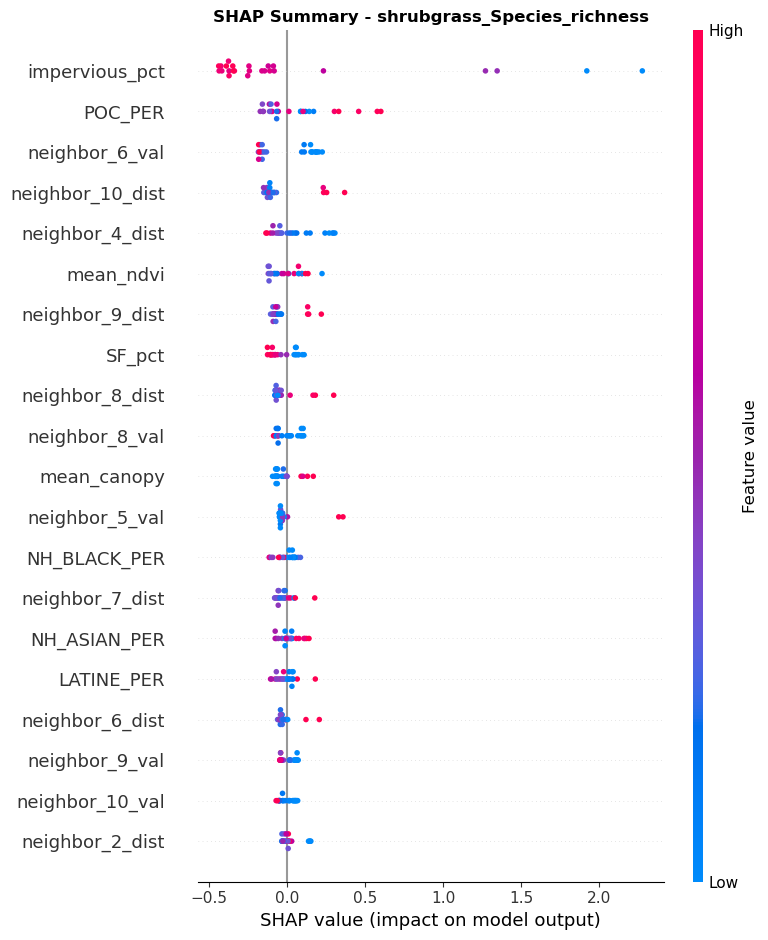

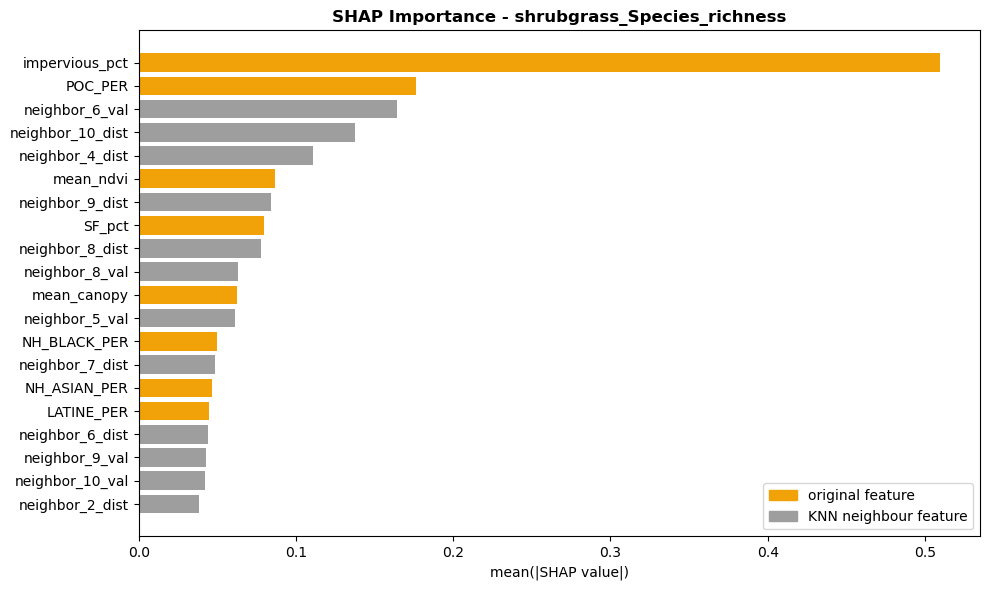

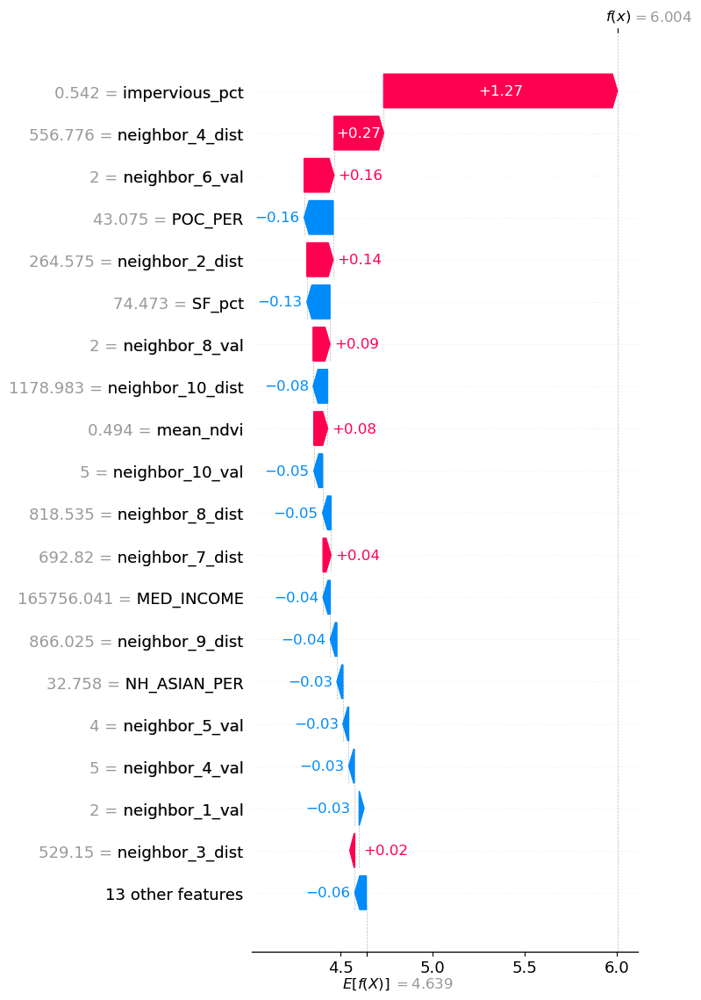

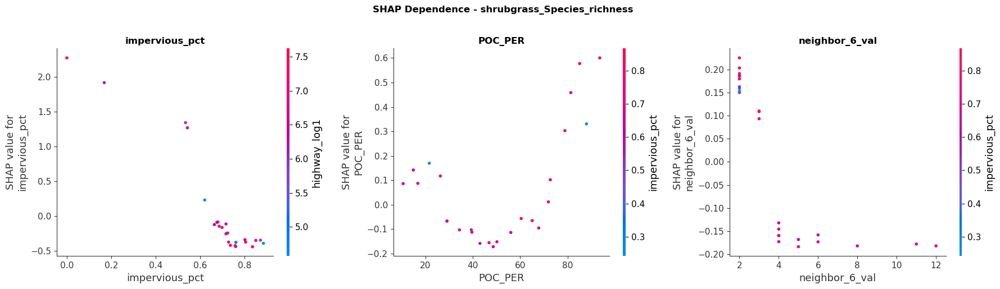


=== Model Performance ===
OOB Score: -0.0654
CV RMSE: 3.4680 (+/- 1.4317)
CV R²:   -0.2056 | CV MAE: 2.5088
Train RMSE: 2.8063 | Train R²: 0.4284
Test  RMSE: 4.9287 | Test  R²: 0.1786 | Test MAE: 2.8964

=== Top 10 Features ===
         feature  importance              type
  impervious_pct    0.509496          original
         POC_PER    0.176175          original
  neighbor_6_val    0.164192    neighbor value
neighbor_10_dist    0.137687 neighbor distance
 neighbor_4_dist    0.110846 neighbor distance
       mean_ndvi    0.086424          original
 neighbor_9_dist    0.083871 neighbor distance
          SF_pct    0.079685          original
 neighbor_8_dist    0.078058 neighbor distance
  neighbor_8_val    0.063060    neighbor value

KNN-RF | SHRUBGRASS | Shannon diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_neighbors': 7}


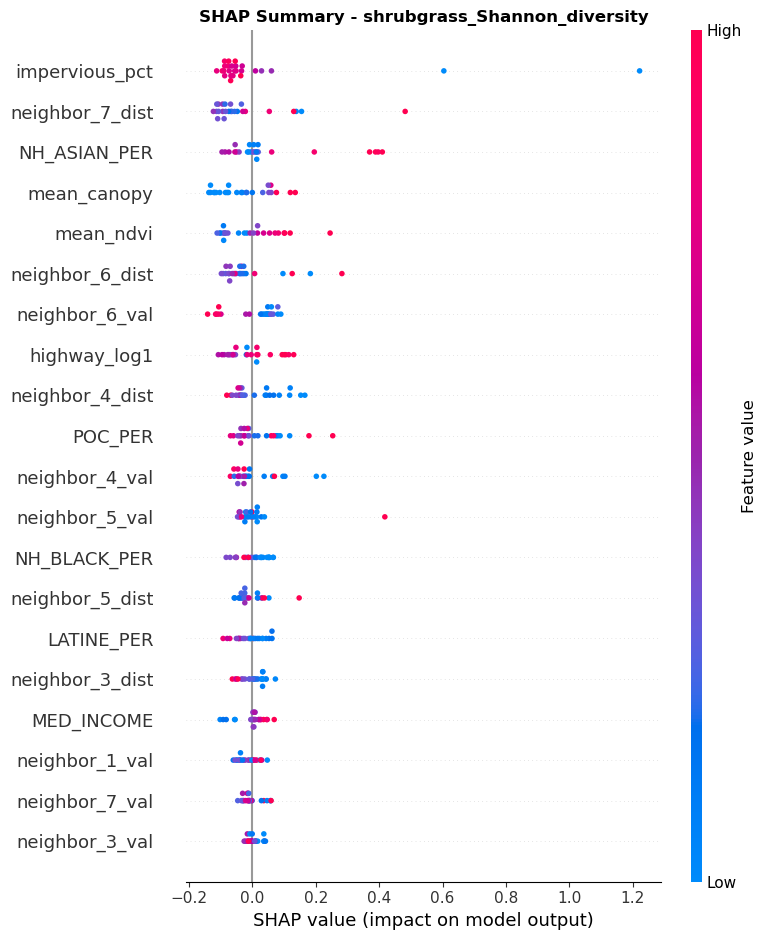

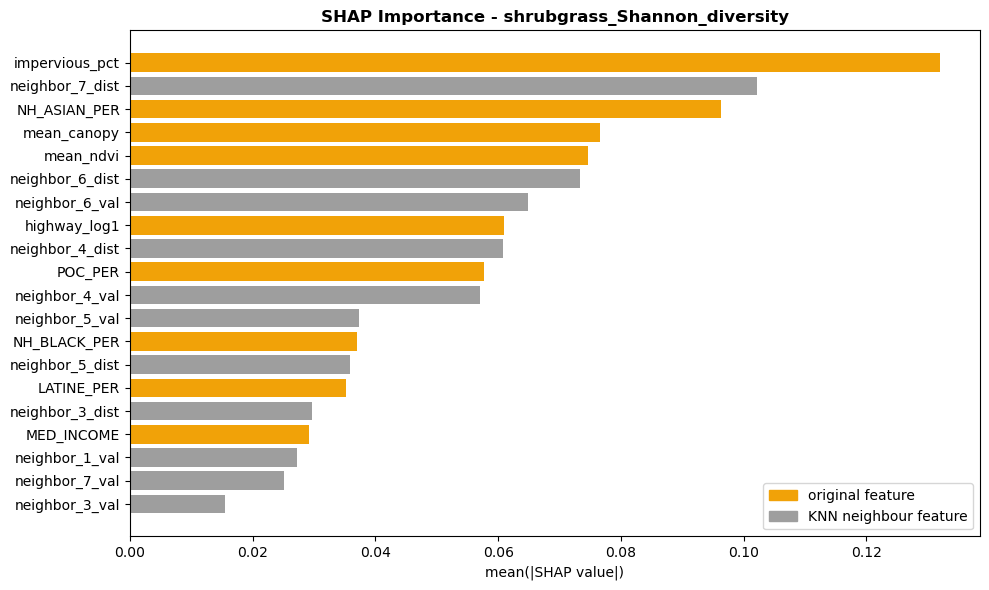

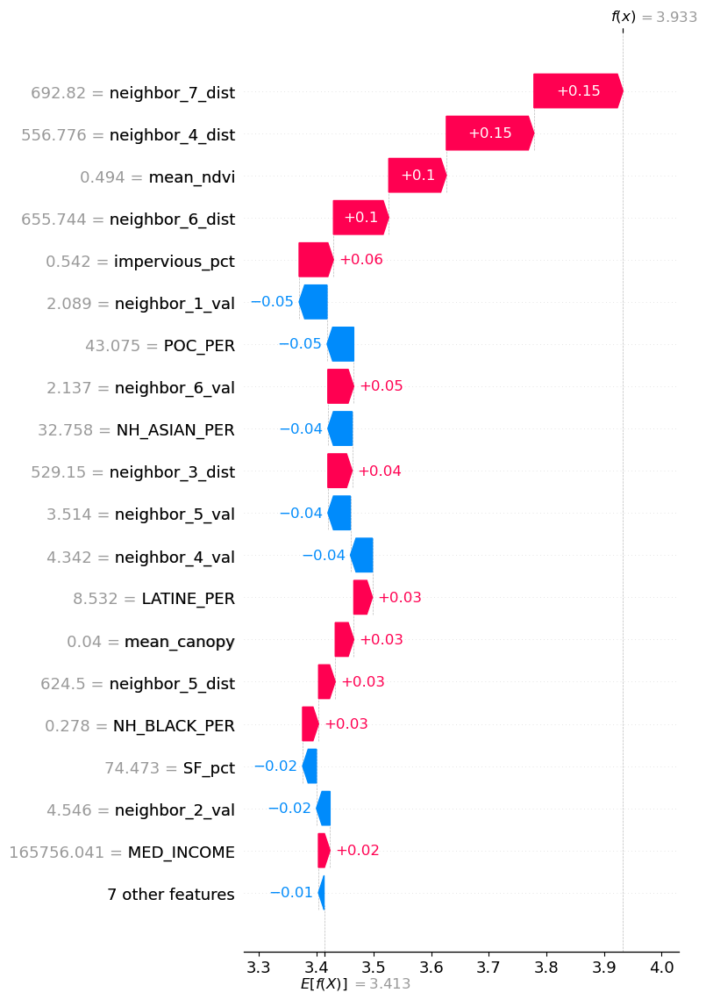

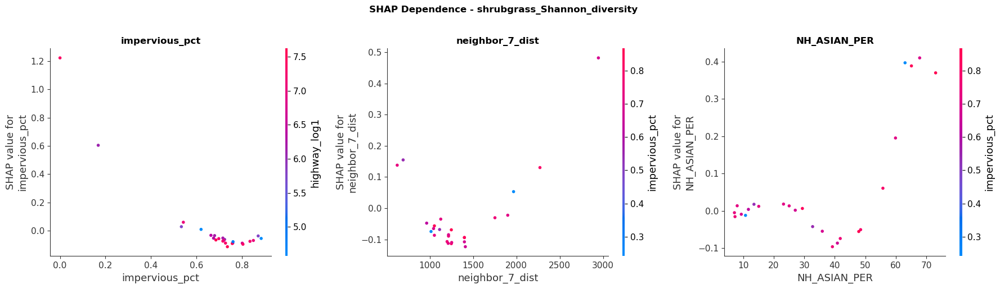


=== Model Performance ===
OOB Score: -0.0727
CV RMSE: 1.5789 (+/- 0.2928)
CV R²:   -0.0696 | CV MAE: 1.2456
Train RMSE: 0.6044 | Train R²: 0.8624
Test  RMSE: 2.0557 | Test  R²: 0.1527 | Test MAE: 1.4916

=== Top 10 Features ===
        feature  importance              type
 impervious_pct    0.131896          original
neighbor_7_dist    0.102131 neighbor distance
   NH_ASIAN_PER    0.096355          original
    mean_canopy    0.076662          original
      mean_ndvi    0.074679          original
neighbor_6_dist    0.073388 neighbor distance
 neighbor_6_val    0.064906    neighbor value
   highway_log1    0.060999          original
neighbor_4_dist    0.060752 neighbor distance
        POC_PER    0.057646          original

KNN-RF | SHRUBGRASS | Simpson diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_neighbors': 10}


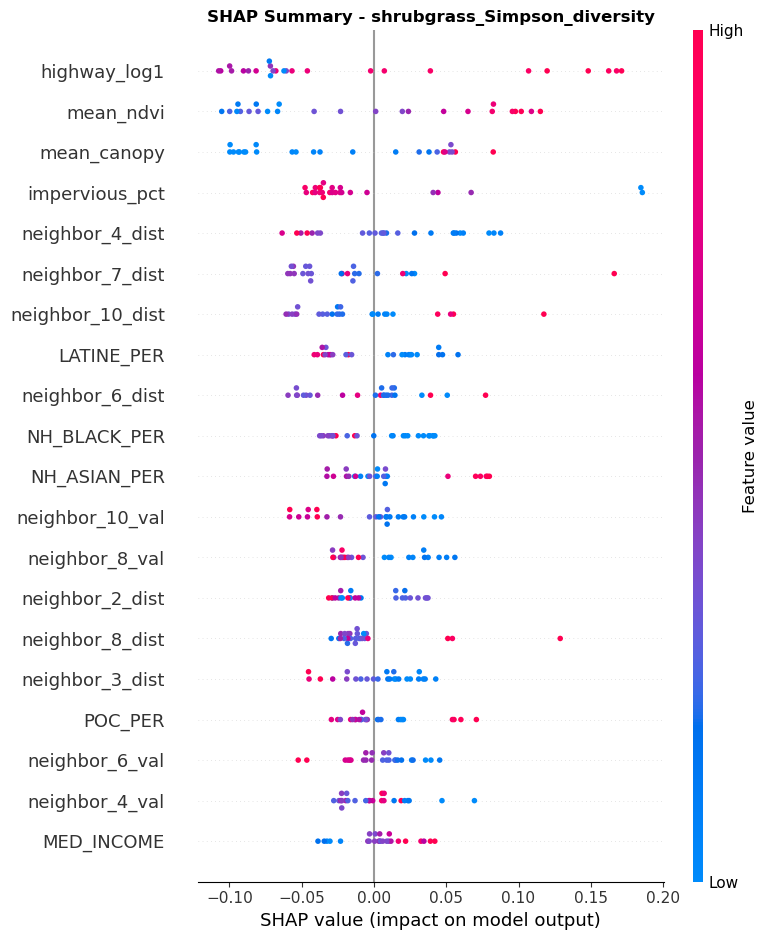

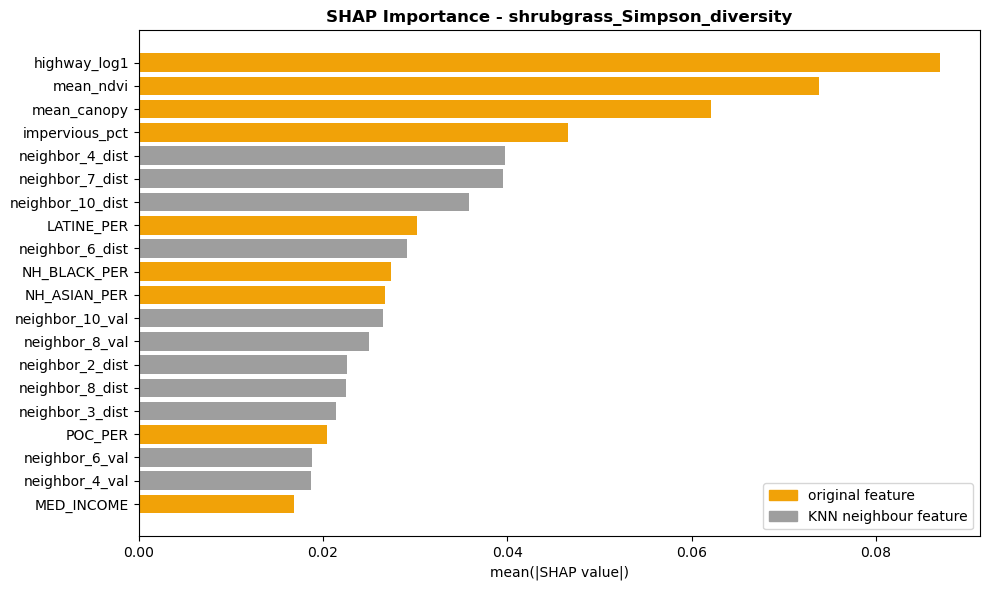

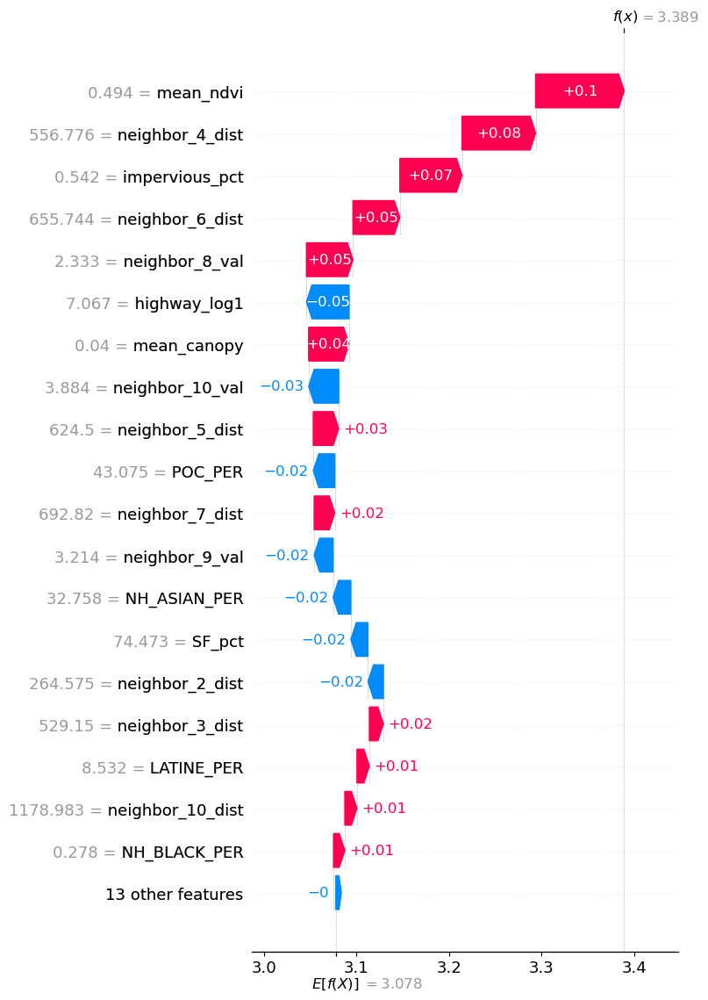

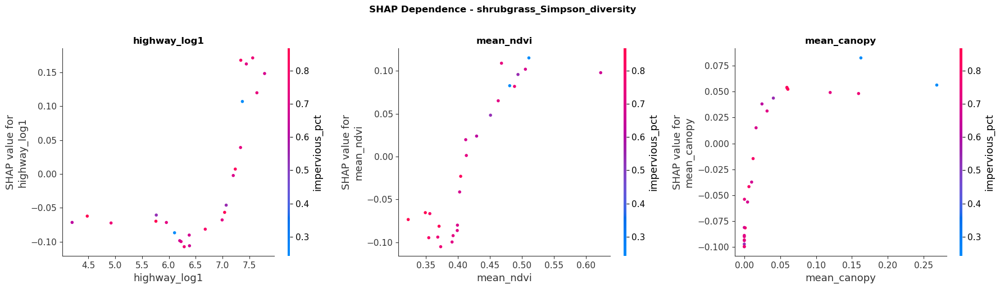


=== Model Performance ===
OOB Score: -0.0722
CV RMSE: 1.2682 (+/- 0.2334)
CV R²:   -0.0781 | CV MAE: 1.0082
Train RMSE: 0.7609 | Train R²: 0.6523
Test  RMSE: 1.7954 | Test  R²: 0.0252 | Test MAE: 1.3535

=== Top 10 Features ===
         feature  importance              type
    highway_log1    0.086966          original
       mean_ndvi    0.073857          original
     mean_canopy    0.062101          original
  impervious_pct    0.046563          original
 neighbor_4_dist    0.039759 neighbor distance
 neighbor_7_dist    0.039550 neighbor distance
neighbor_10_dist    0.035809 neighbor distance
      LATINE_PER    0.030209          original
 neighbor_6_dist    0.029106 neighbor distance
    NH_BLACK_PER    0.027363          original

KNN-RF | TREES | Species richness
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_neighbors': 5}


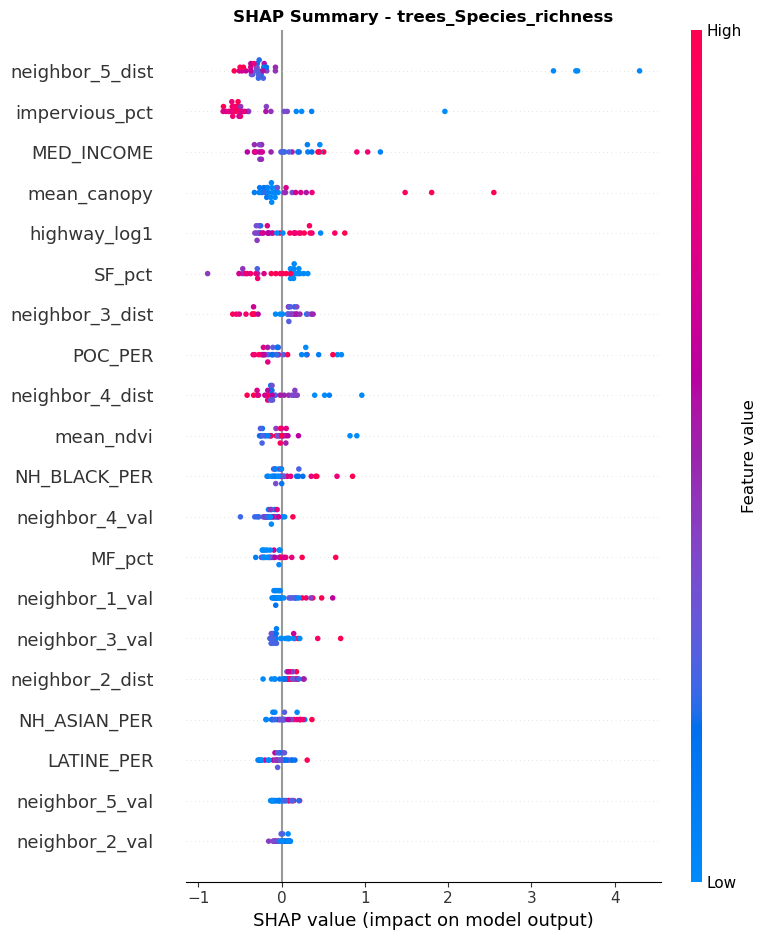

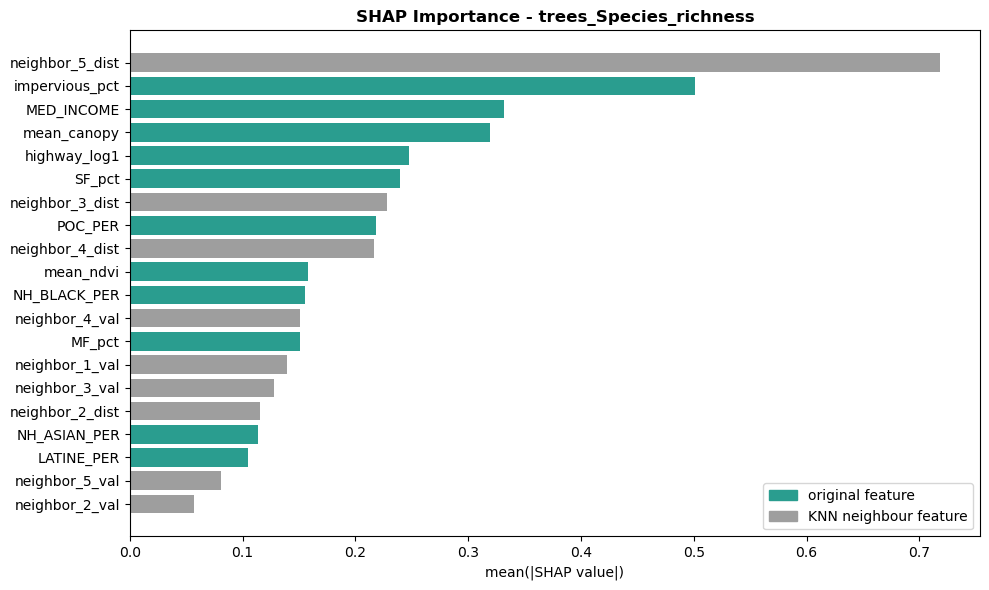

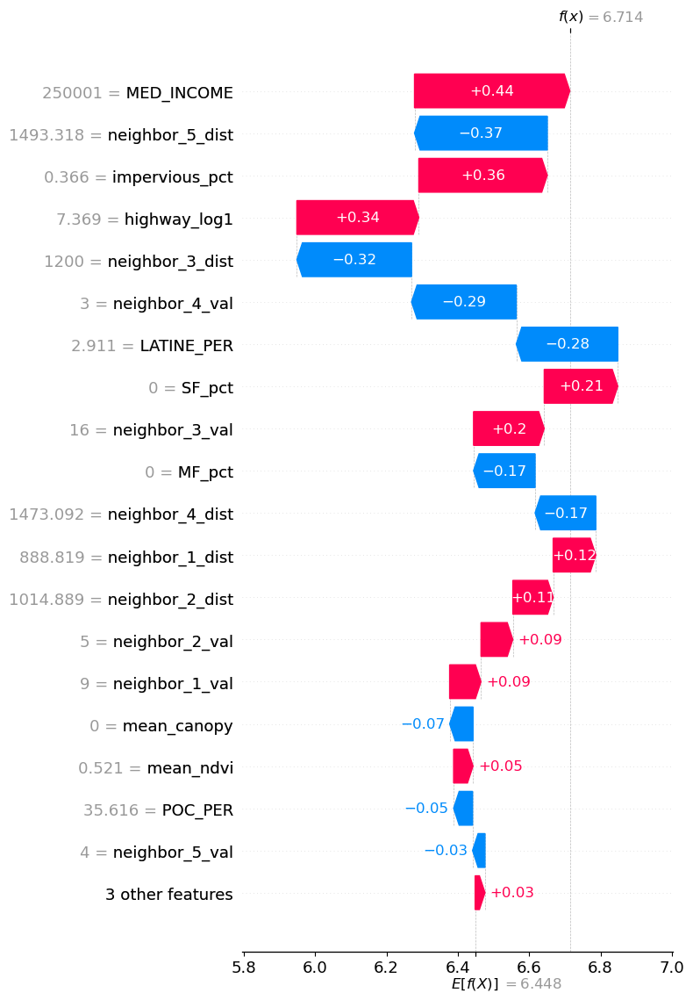

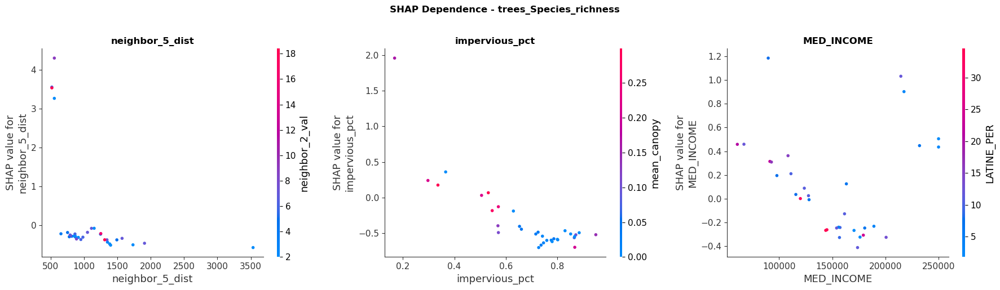


=== Model Performance ===
OOB Score: 0.1085
CV RMSE: 7.0849 (+/- 2.2438)
CV R²:   -0.2677 | CV MAE: 4.9163
Train RMSE: 2.6821 | Train R²: 0.8804
Test  RMSE: 4.8420 | Test  R²: -0.0241 | Test MAE: 3.7693

=== Top 10 Features ===
        feature  importance              type
neighbor_5_dist    0.717899 neighbor distance
 impervious_pct    0.501313          original
     MED_INCOME    0.331400          original
    mean_canopy    0.319388          original
   highway_log1    0.247247          original
         SF_pct    0.239410          original
neighbor_3_dist    0.227873 neighbor distance
        POC_PER    0.218030          original
neighbor_4_dist    0.216042 neighbor distance
      mean_ndvi    0.157570          original

KNN-RF | TREES | Shannon diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_neighbors': 10}


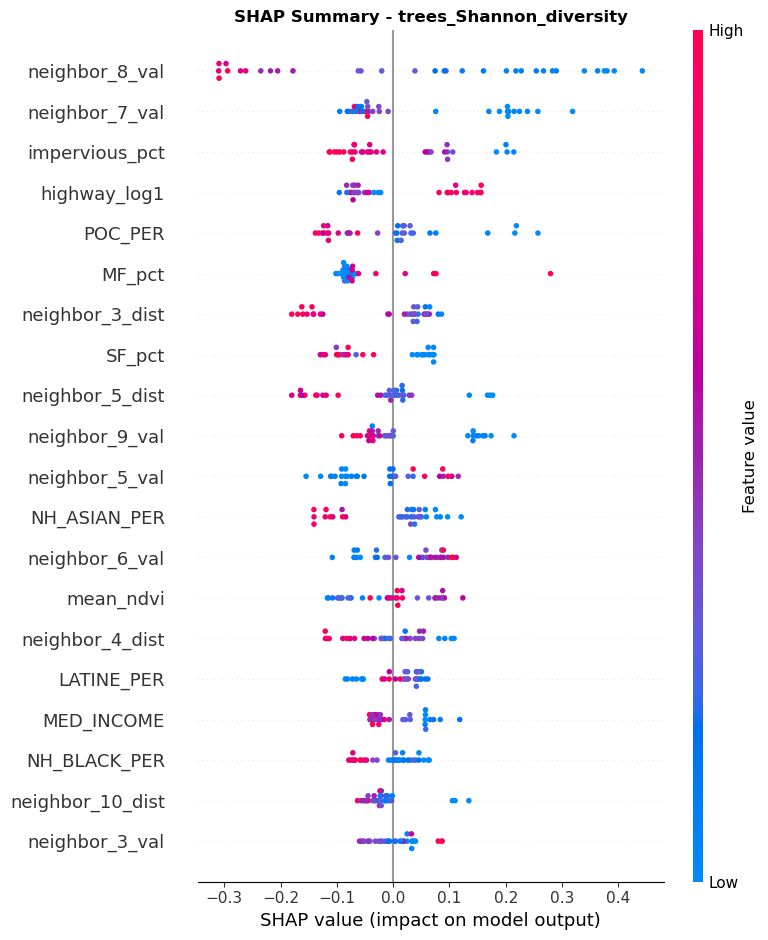

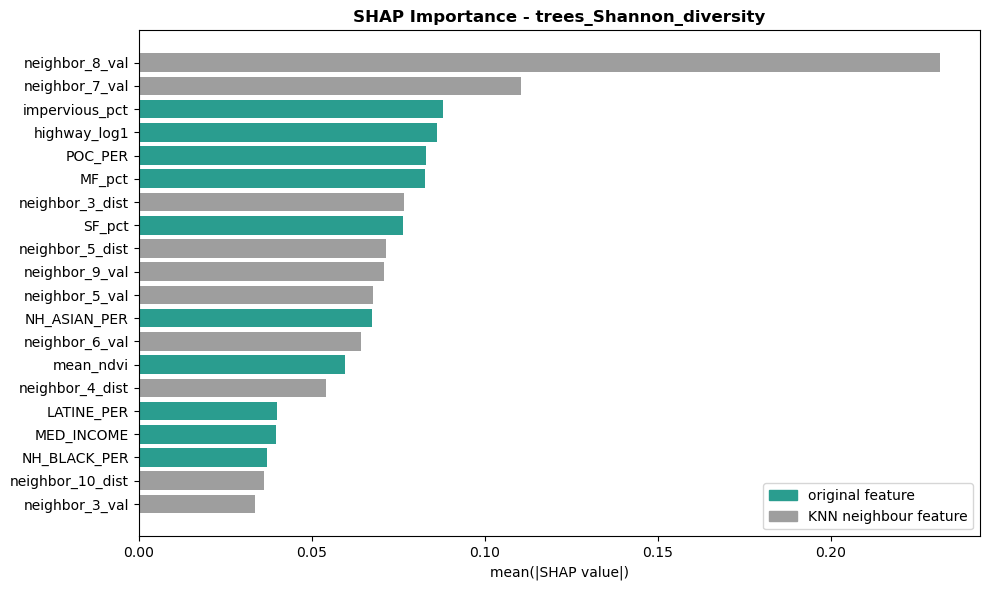

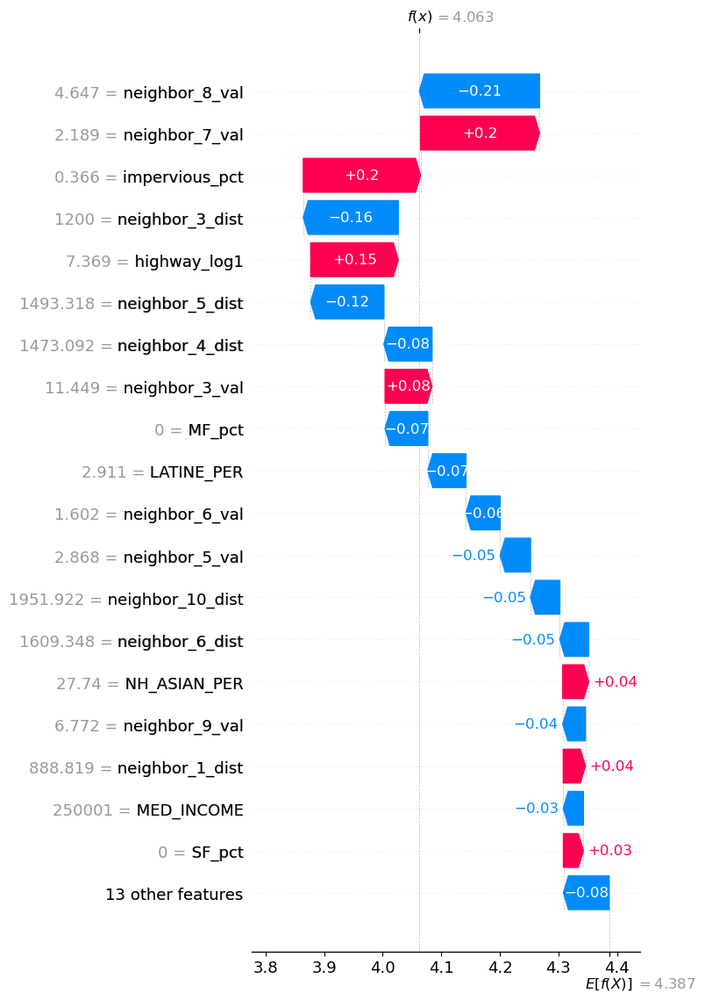

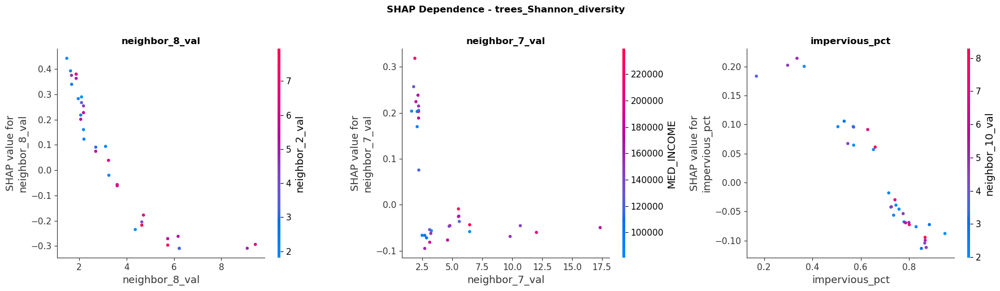


=== Model Performance ===
OOB Score: -0.0146
CV RMSE: 2.8836 (+/- 0.8914)
CV R²:   -0.0561 | CV MAE: 2.2475
Train RMSE: 2.1611 | Train R²: 0.4789
Test  RMSE: 2.4663 | Test  R²: -0.0249 | Test MAE: 2.1252

=== Top 10 Features ===
        feature  importance              type
 neighbor_8_val    0.231497    neighbor value
 neighbor_7_val    0.110475    neighbor value
 impervious_pct    0.087875          original
   highway_log1    0.086297          original
        POC_PER    0.083015          original
         MF_pct    0.082696          original
neighbor_3_dist    0.076658 neighbor distance
         SF_pct    0.076469          original
neighbor_5_dist    0.071354 neighbor distance
 neighbor_9_val    0.070806    neighbor value

KNN-RF | TREES | Simpson diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_neighbors': 10}


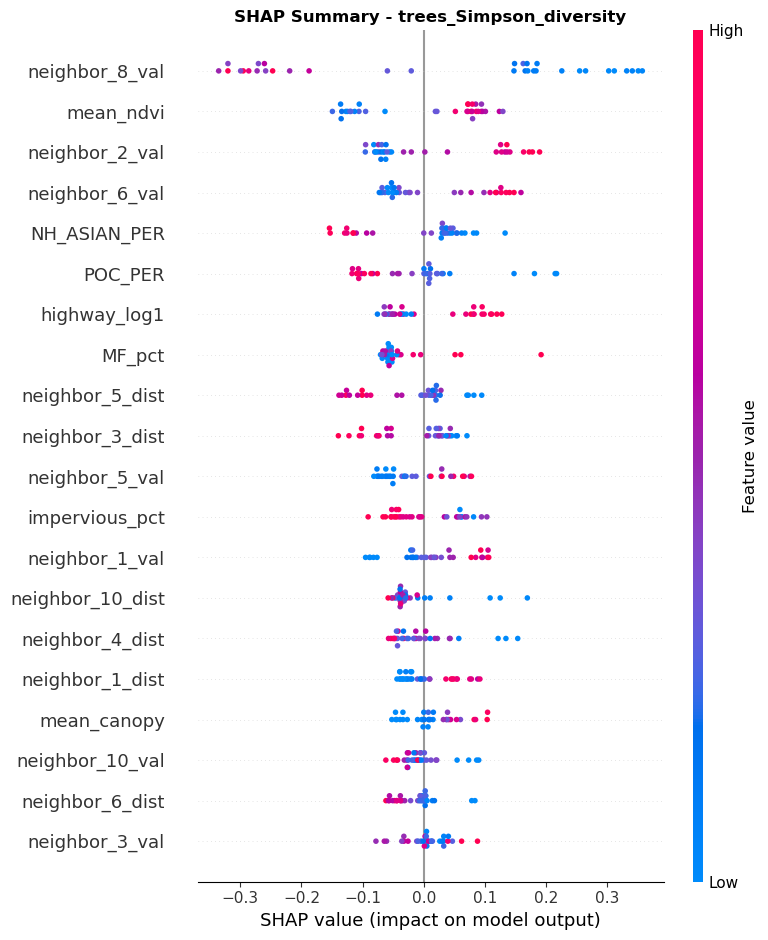

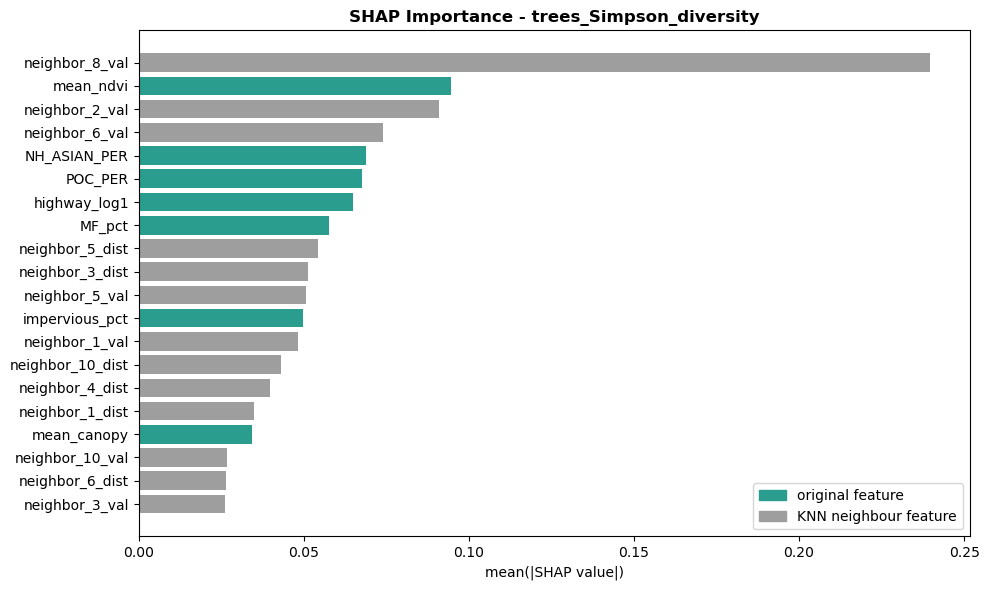

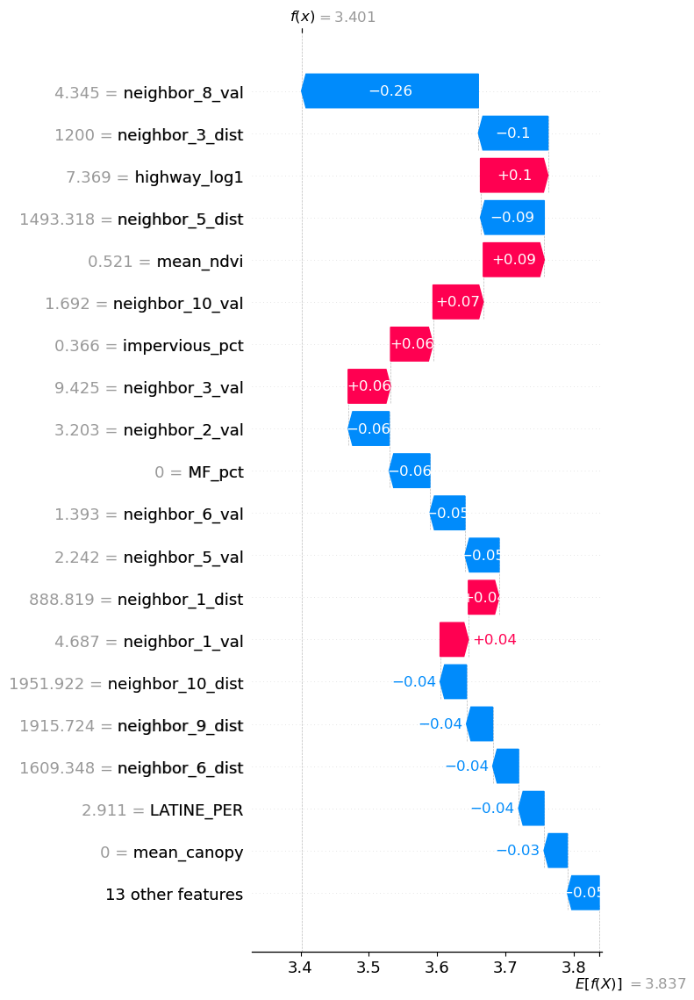

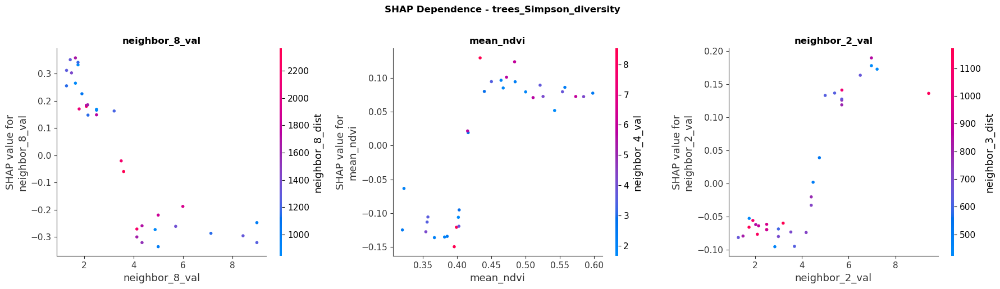


=== Model Performance ===
OOB Score: 0.0220
CV RMSE: 2.2205 (+/- 0.4337)
CV R²:   -0.0016 | CV MAE: 1.7436
Train RMSE: 1.5887 | Train R²: 0.5164
Test  RMSE: 1.9757 | Test  R²: -0.0486 | Test MAE: 1.6694

=== Top 10 Features ===
        feature  importance              type
 neighbor_8_val    0.239658    neighbor value
      mean_ndvi    0.094712          original
 neighbor_2_val    0.090995    neighbor value
 neighbor_6_val    0.074107    neighbor value
   NH_ASIAN_PER    0.068785          original
        POC_PER    0.067484          original
   highway_log1    0.064877          original
         MF_pct    0.057695          original
neighbor_5_dist    0.054263 neighbor distance
neighbor_3_dist    0.051326 neighbor distance

KNN-RF | WATER | Species richness
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_neighbors': 7}


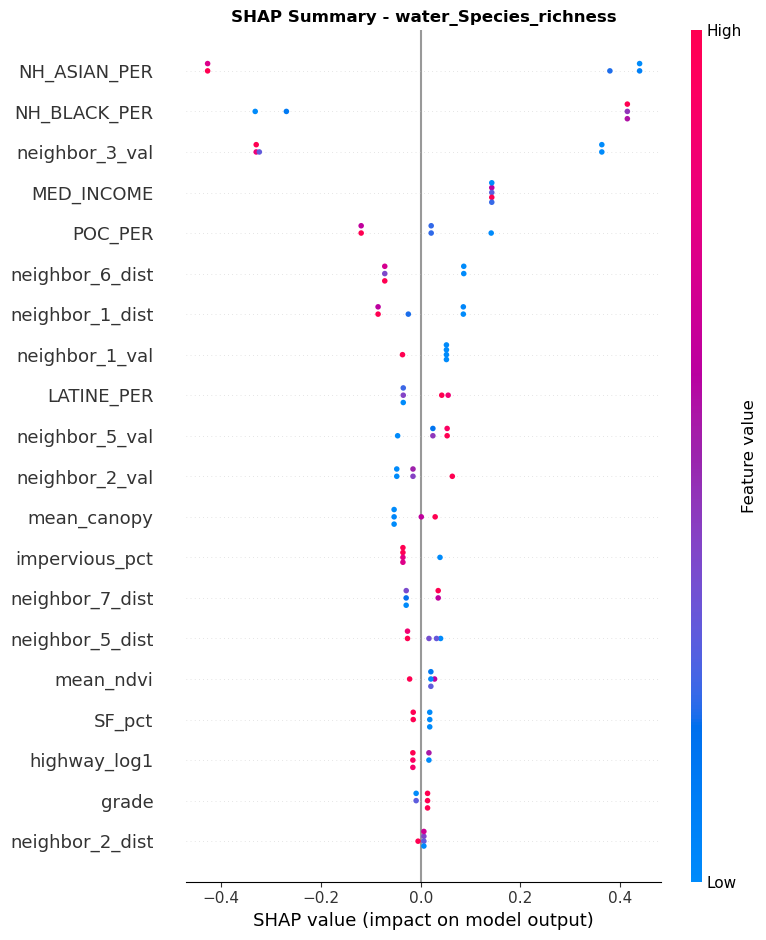

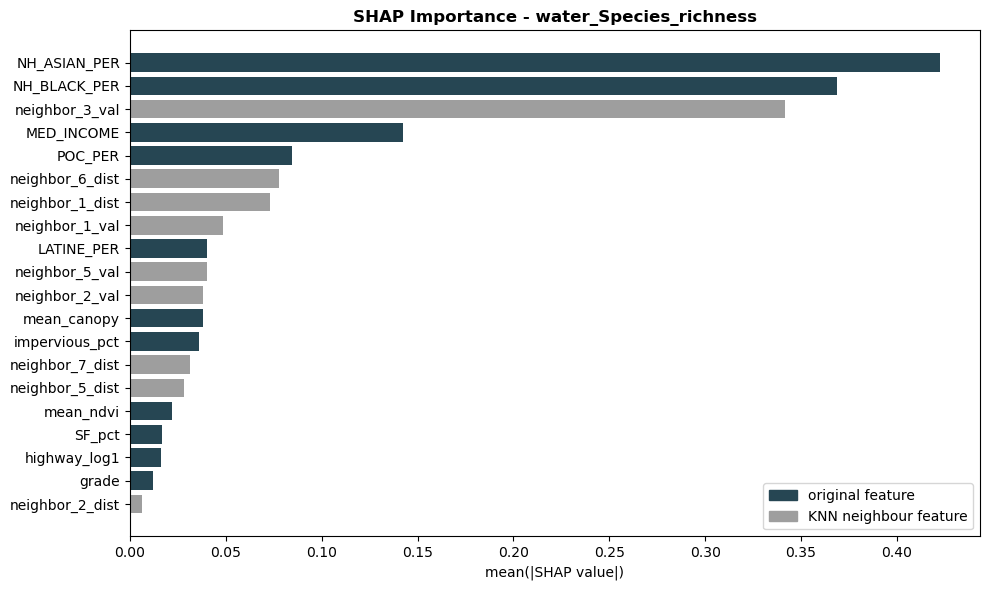

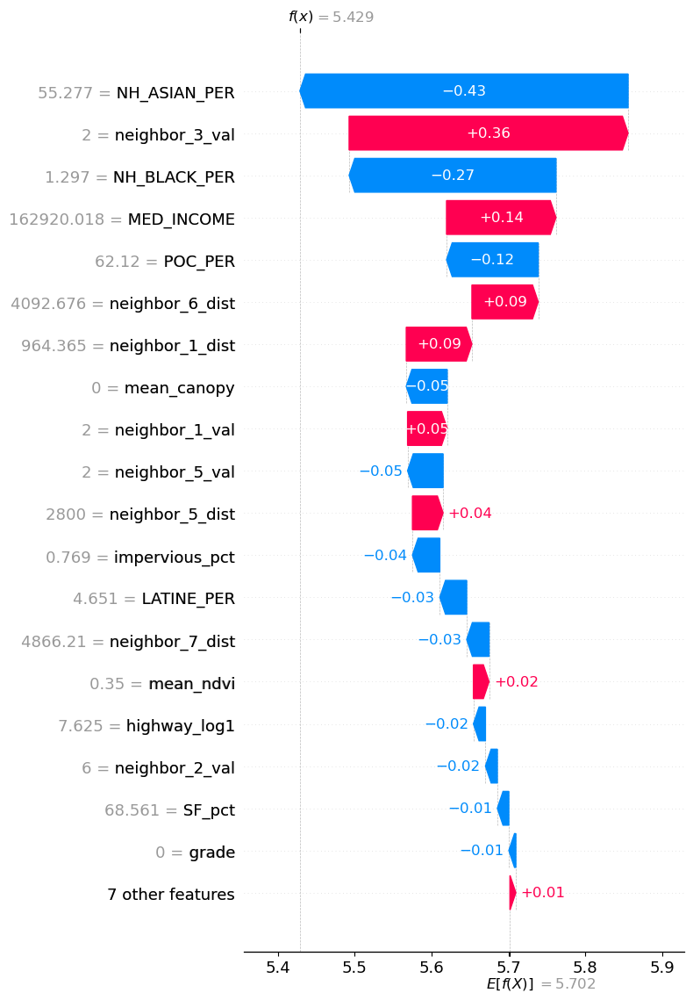

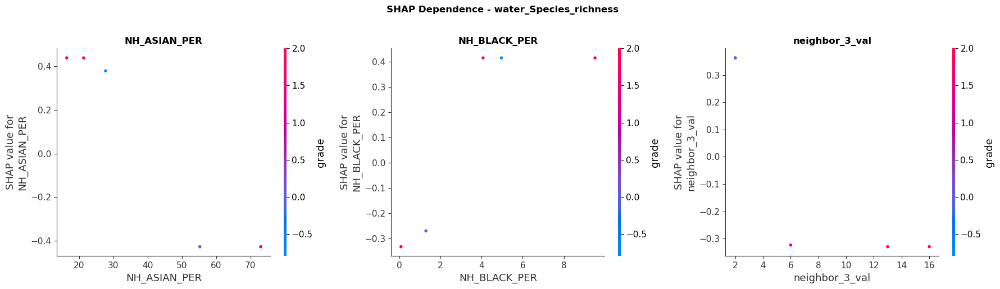


=== Model Performance ===
OOB Score: -0.1357
CV RMSE: 4.3865 (+/- 1.1205)
CV R²:   -3.5368 | CV MAE: 3.8235
Train RMSE: 3.4941 | Train R²: 0.3653
Test  RMSE: 7.4871 | Test  R²: 0.0089 | Test MAE: 4.4674

=== Top 10 Features ===
        feature  importance              type
   NH_ASIAN_PER    0.422169          original
   NH_BLACK_PER    0.368676          original
 neighbor_3_val    0.341760    neighbor value
     MED_INCOME    0.142444          original
        POC_PER    0.084398          original
neighbor_6_dist    0.077734 neighbor distance
neighbor_1_dist    0.073306 neighbor distance
 neighbor_1_val    0.048548    neighbor value
     LATINE_PER    0.040412          original
 neighbor_5_val    0.040210    neighbor value

KNN-RF | WATER | Shannon diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_neighbors': 5}


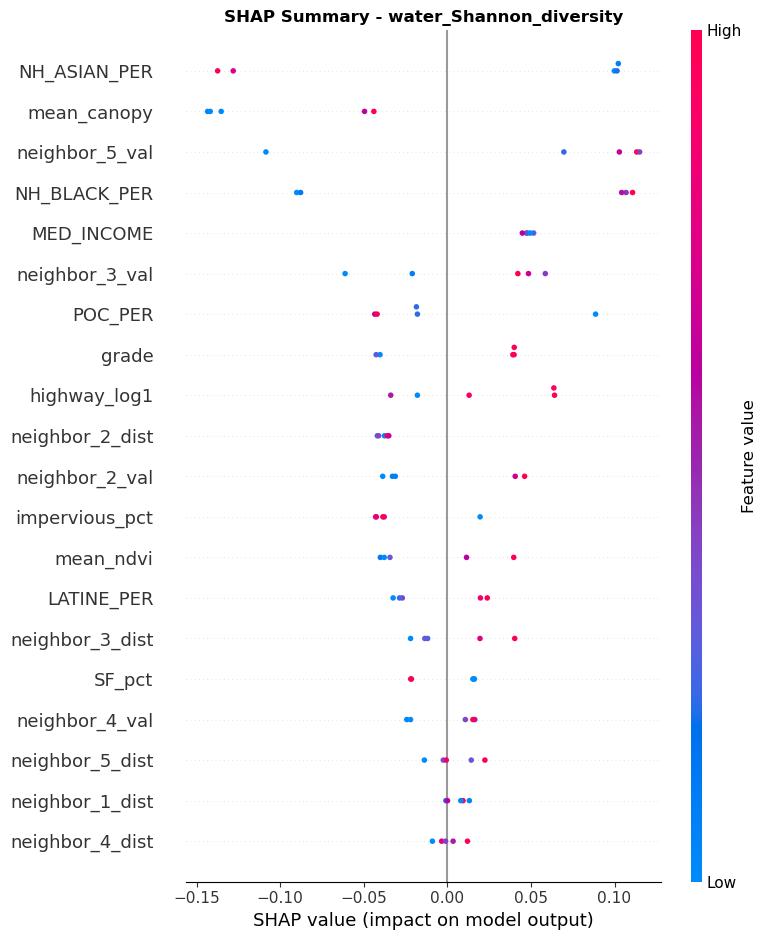

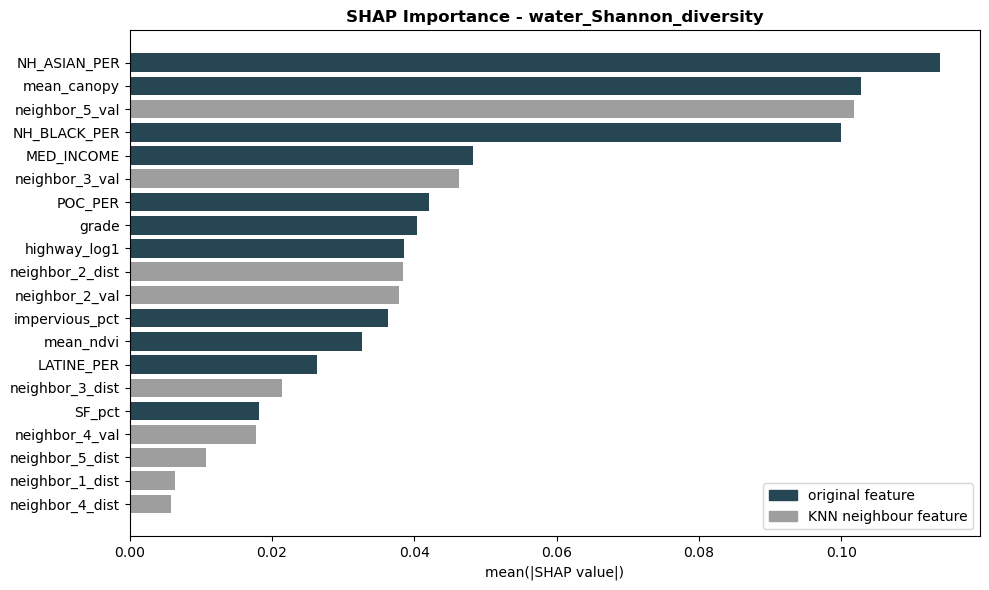

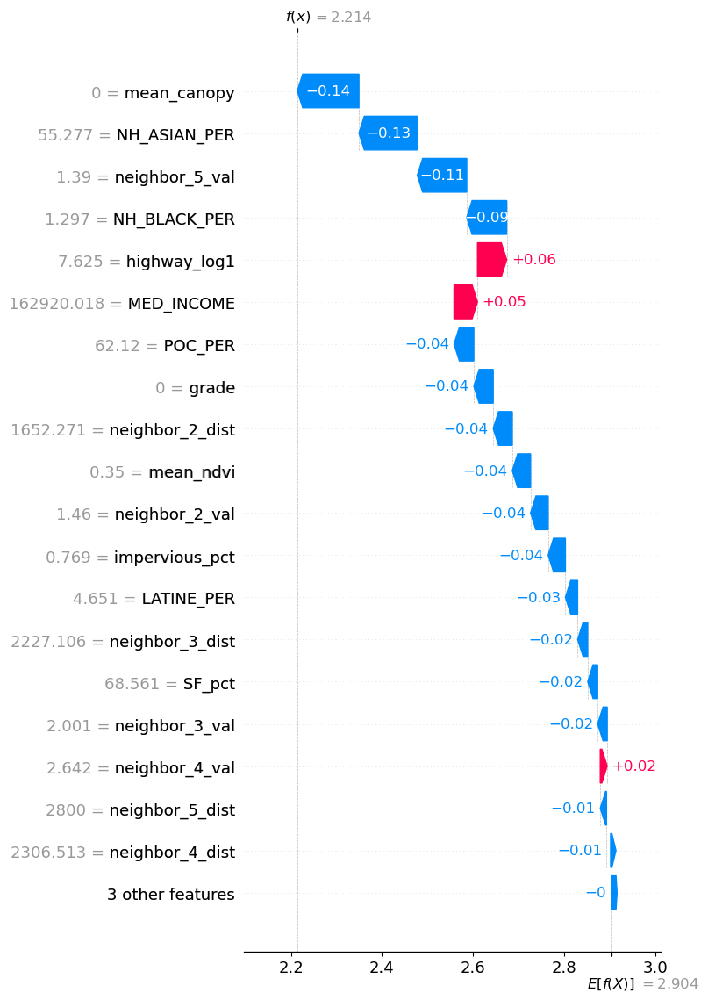

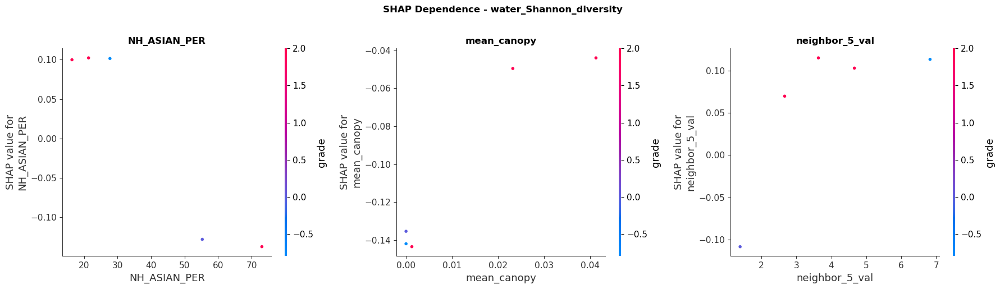


=== Model Performance ===
OOB Score: -0.0348
CV RMSE: 1.3929 (+/- 0.6500)
CV R²:   -0.9036 | CV MAE: 1.1780
Train RMSE: 0.9832 | Train R²: 0.5598
Test  RMSE: 2.1197 | Test  R²: -0.2012 | Test MAE: 1.6223

=== Top 10 Features ===
        feature  importance              type
   NH_ASIAN_PER    0.113819          original
    mean_canopy    0.102808          original
 neighbor_5_val    0.101865    neighbor value
   NH_BLACK_PER    0.099971          original
     MED_INCOME    0.048289          original
 neighbor_3_val    0.046285    neighbor value
        POC_PER    0.042102          original
          grade    0.040396          original
   highway_log1    0.038522          original
neighbor_2_dist    0.038344 neighbor distance

KNN-RF | WATER | Simpson diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_neighbors': 5}


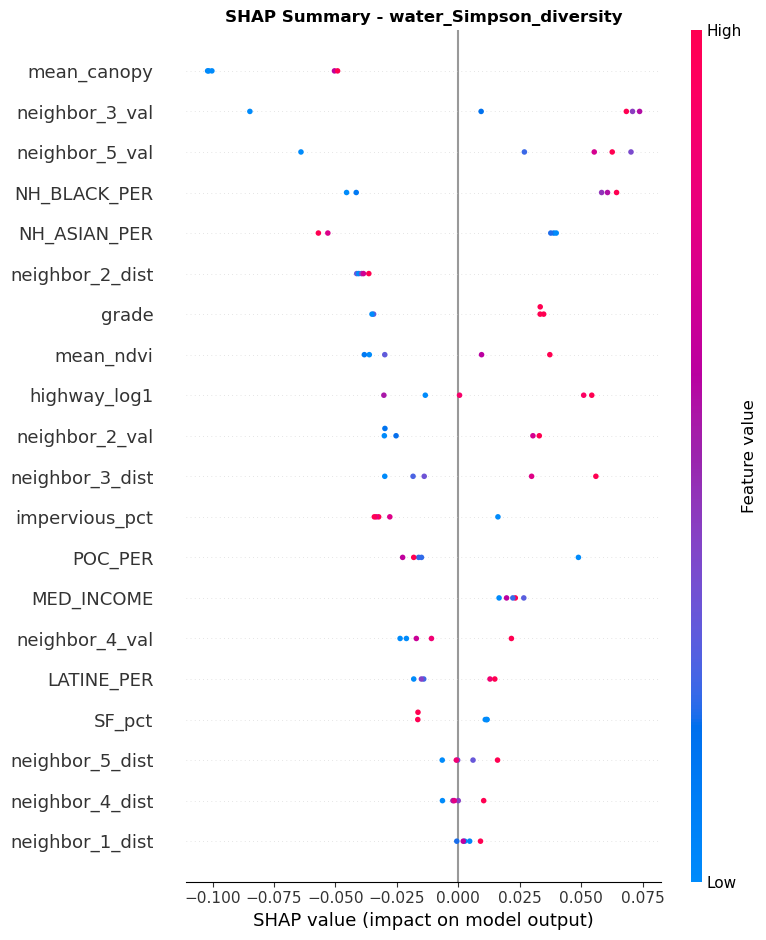

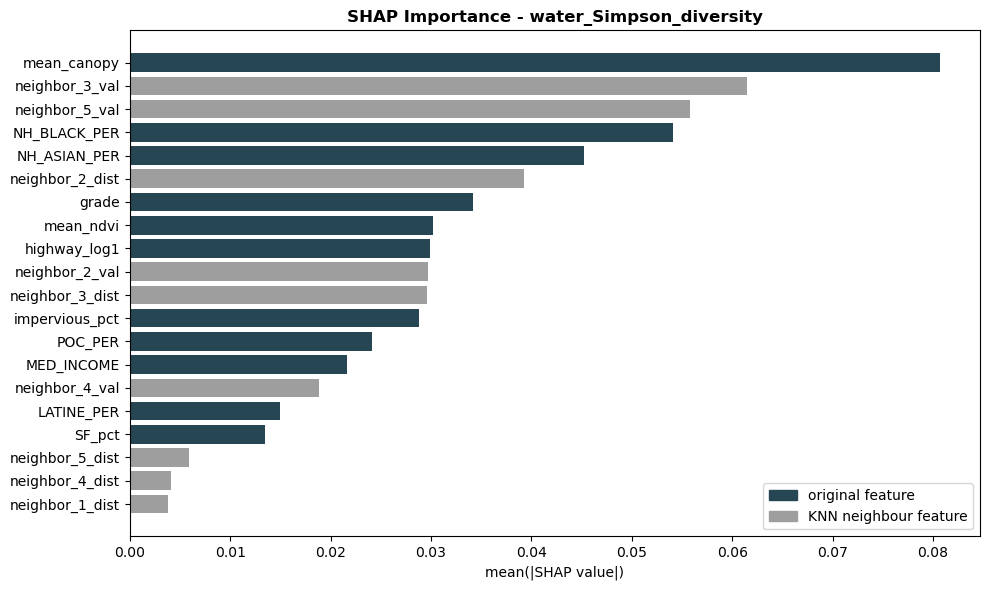

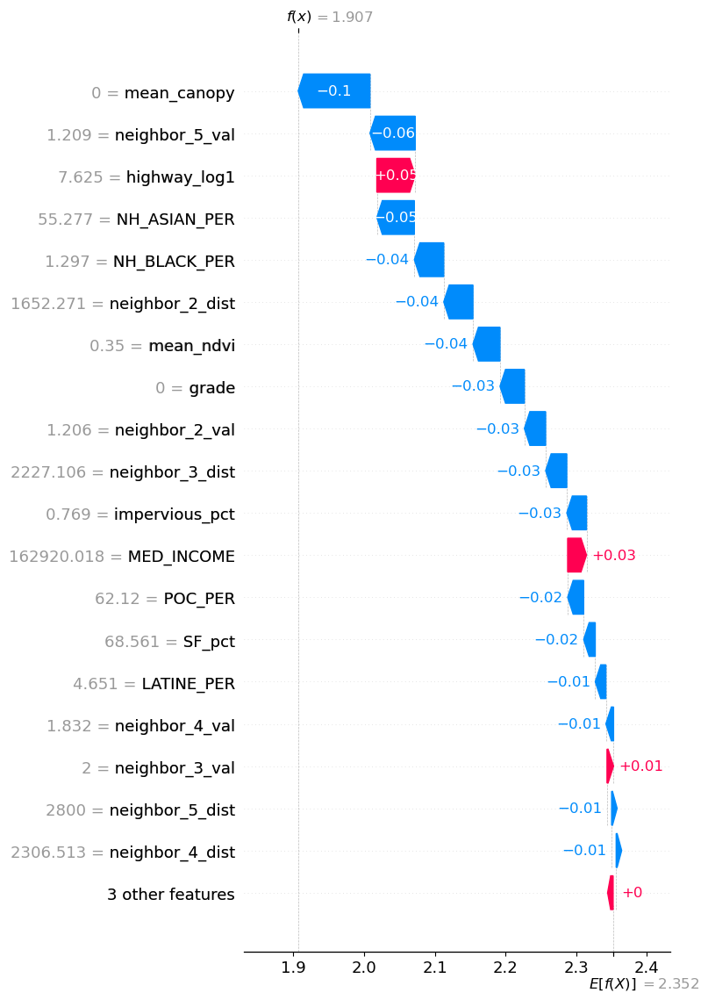

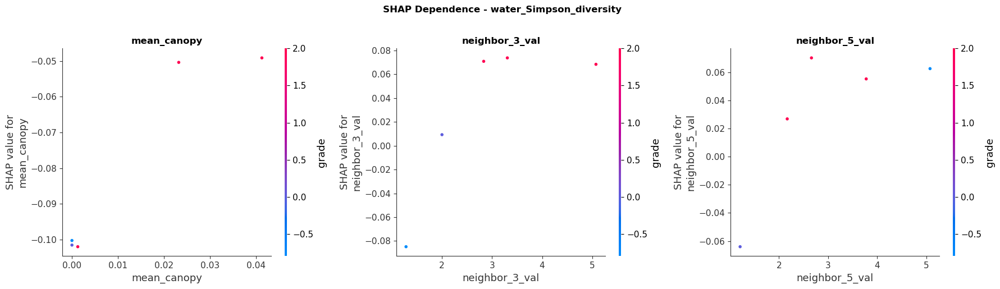


=== Model Performance ===
OOB Score: 0.0305
CV RMSE: 0.9508 (+/- 0.5170)
CV R²:   -0.9478 | CV MAE: 0.7903
Train RMSE: 0.6493 | Train R²: 0.5955
Test  RMSE: 0.9291 | Test  R²: -0.2544 | Test MAE: 0.7529

=== Top 10 Features ===
        feature  importance              type
    mean_canopy    0.080655          original
 neighbor_3_val    0.061436    neighbor value
 neighbor_5_val    0.055834    neighbor value
   NH_BLACK_PER    0.054090          original
   NH_ASIAN_PER    0.045272          original
neighbor_2_dist    0.039231 neighbor distance
          grade    0.034194          original
      mean_ndvi    0.030212          original
   highway_log1    0.029911          original
 neighbor_2_val    0.029717    neighbor value

KNN-RF | NATIVE | Species richness
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_neighbors': 10}


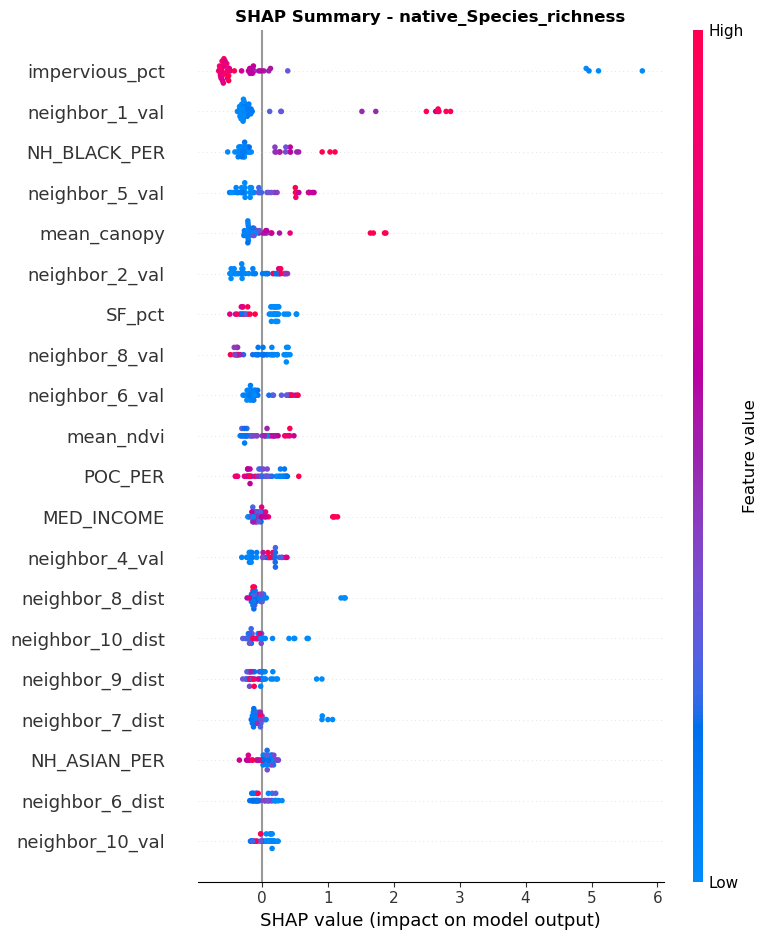

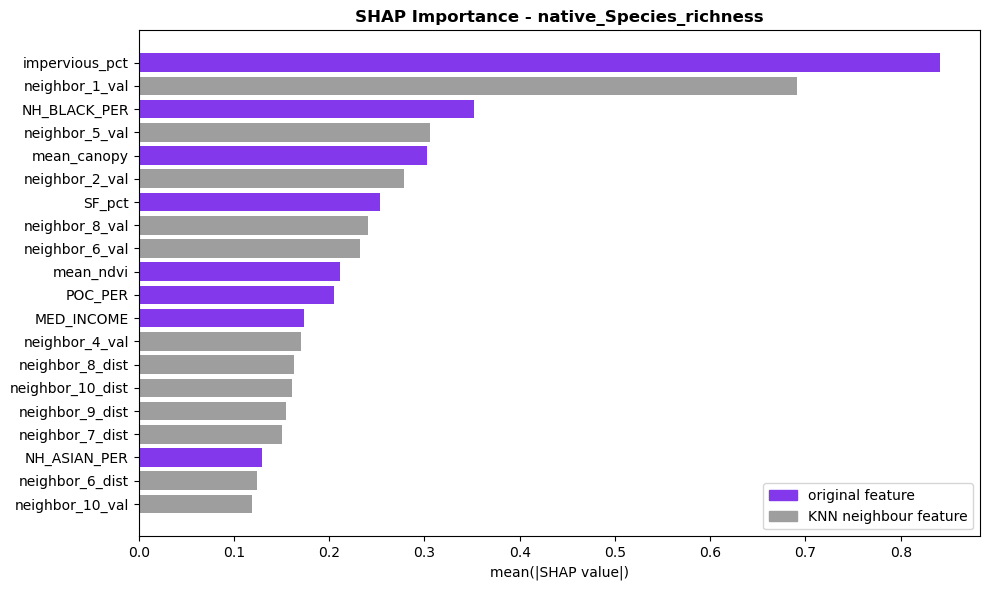

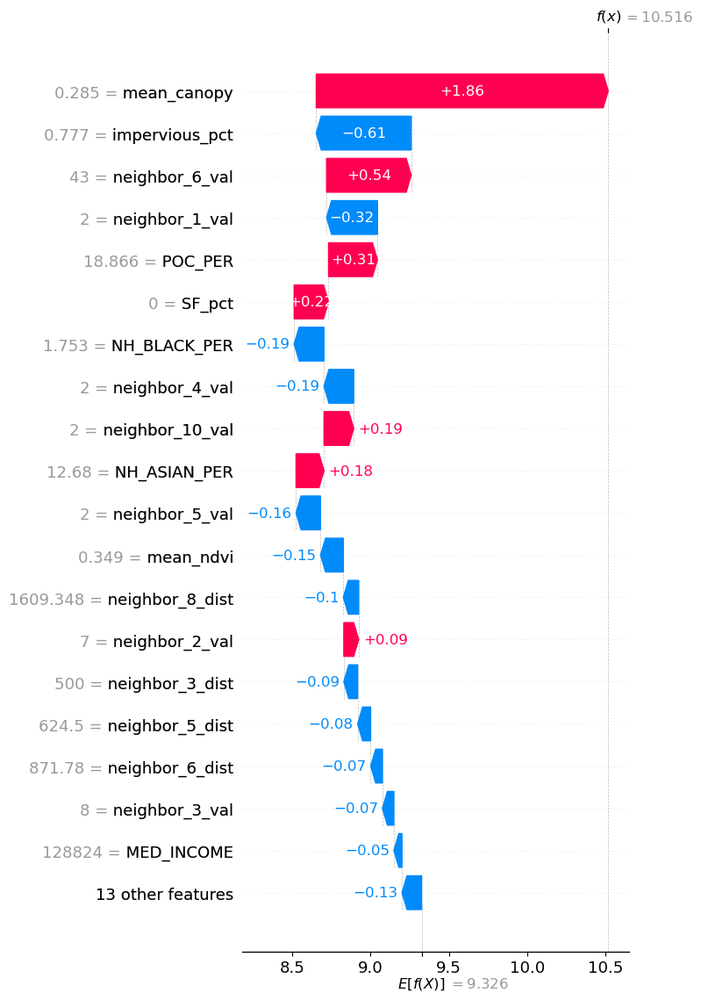

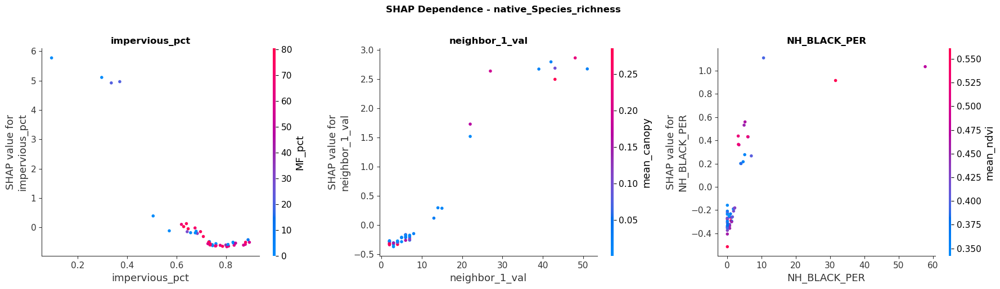


=== Model Performance ===
OOB Score: -0.0219
CV RMSE: 12.7603 (+/- 5.4629)
CV R²:   -0.2379 | CV MAE: 7.9880
Train RMSE: 10.9741 | Train R²: 0.3609
Test  RMSE: 10.0319 | Test  R²: 0.0328 | Test MAE: 7.4537

=== Top 10 Features ===
       feature  importance           type
impervious_pct    0.841185       original
neighbor_1_val    0.690951 neighbor value
  NH_BLACK_PER    0.352245       original
neighbor_5_val    0.305667 neighbor value
   mean_canopy    0.303069       original
neighbor_2_val    0.277996 neighbor value
        SF_pct    0.252955       original
neighbor_8_val    0.240302 neighbor value
neighbor_6_val    0.232477 neighbor value
     mean_ndvi    0.211212       original

KNN-RF | NATIVE | Shannon diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_neighbors': 10}


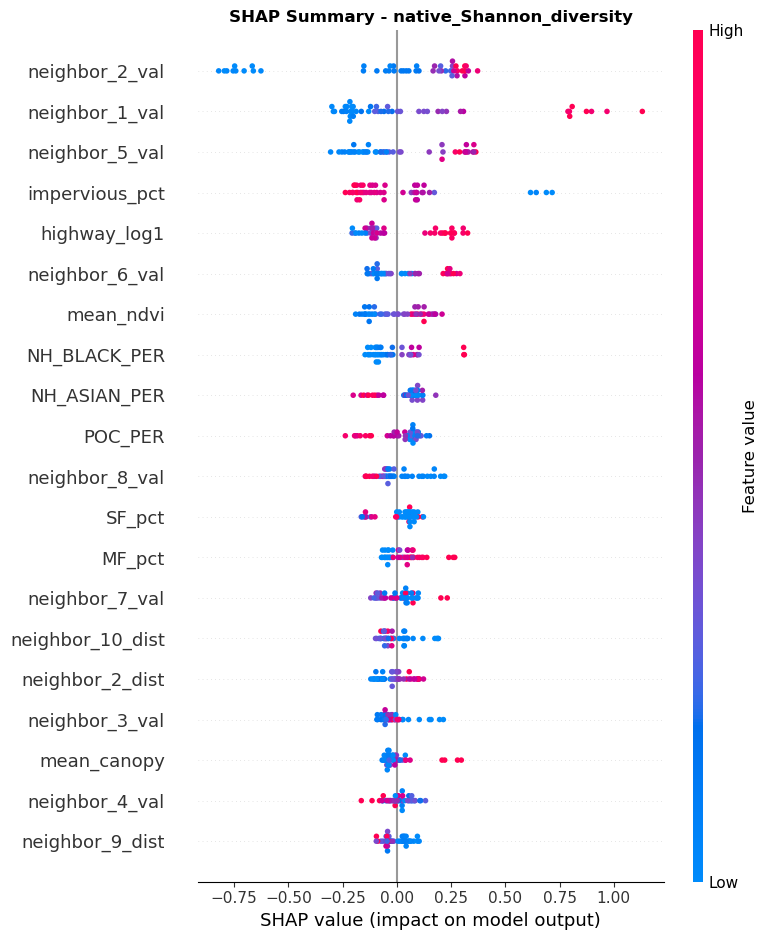

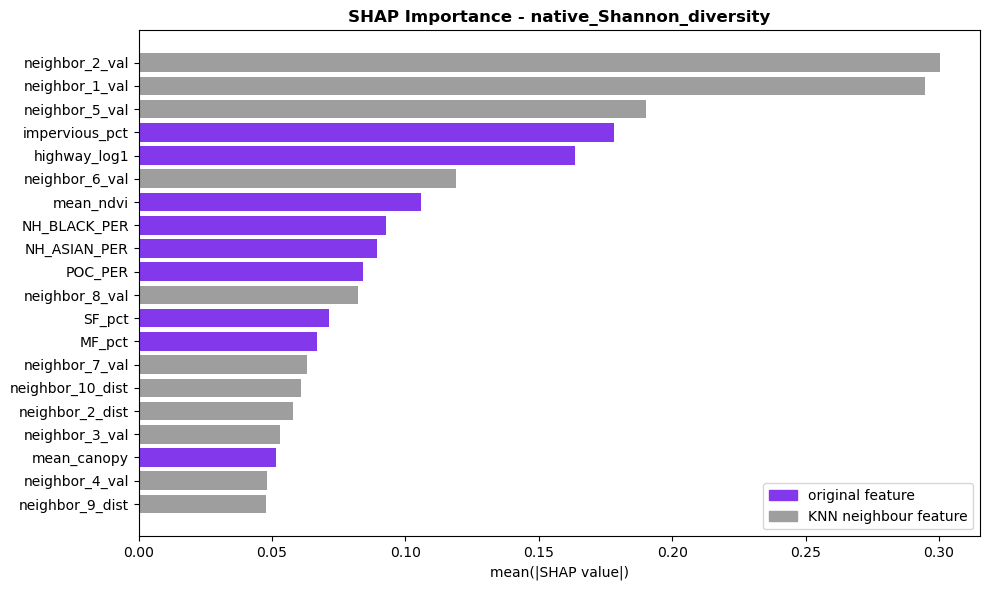

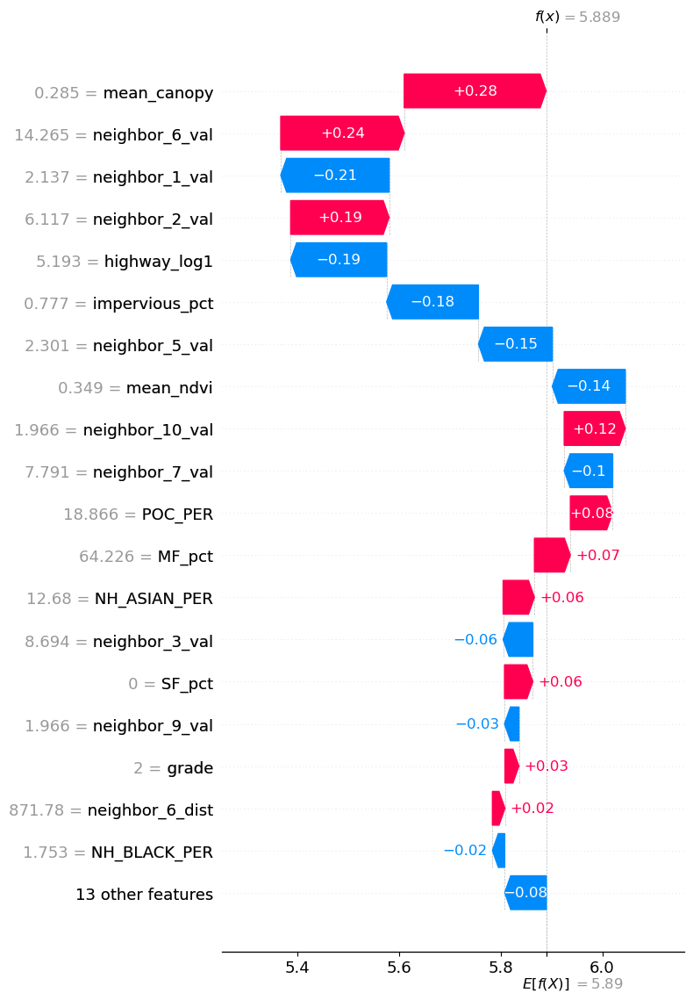

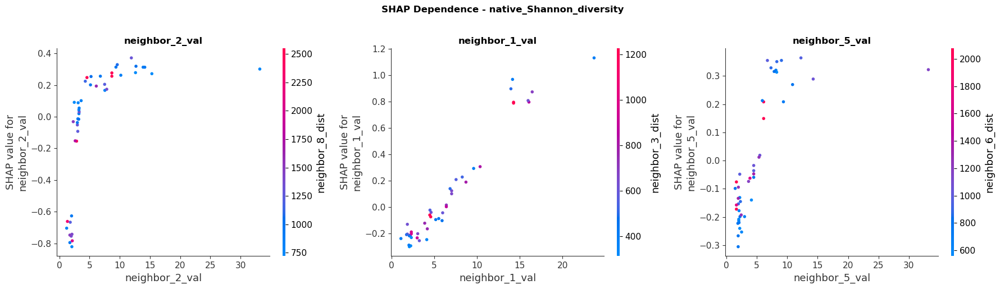


=== Model Performance ===
OOB Score: -0.0098
CV RMSE: 5.1219 (+/- 1.0435)
CV R²:   -0.1149 | CV MAE: 3.7262
Train RMSE: 3.7832 | Train R²: 0.4609
Test  RMSE: 5.3813 | Test  R²: 0.0782 | Test MAE: 3.9620

=== Top 10 Features ===
       feature  importance           type
neighbor_2_val    0.300350 neighbor value
neighbor_1_val    0.294734 neighbor value
neighbor_5_val    0.189995 neighbor value
impervious_pct    0.178089       original
  highway_log1    0.163451       original
neighbor_6_val    0.118882 neighbor value
     mean_ndvi    0.105658       original
  NH_BLACK_PER    0.092838       original
  NH_ASIAN_PER    0.089263       original
       POC_PER    0.083980       original

KNN-RF | NATIVE | Simpson diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_neighbors': 5}


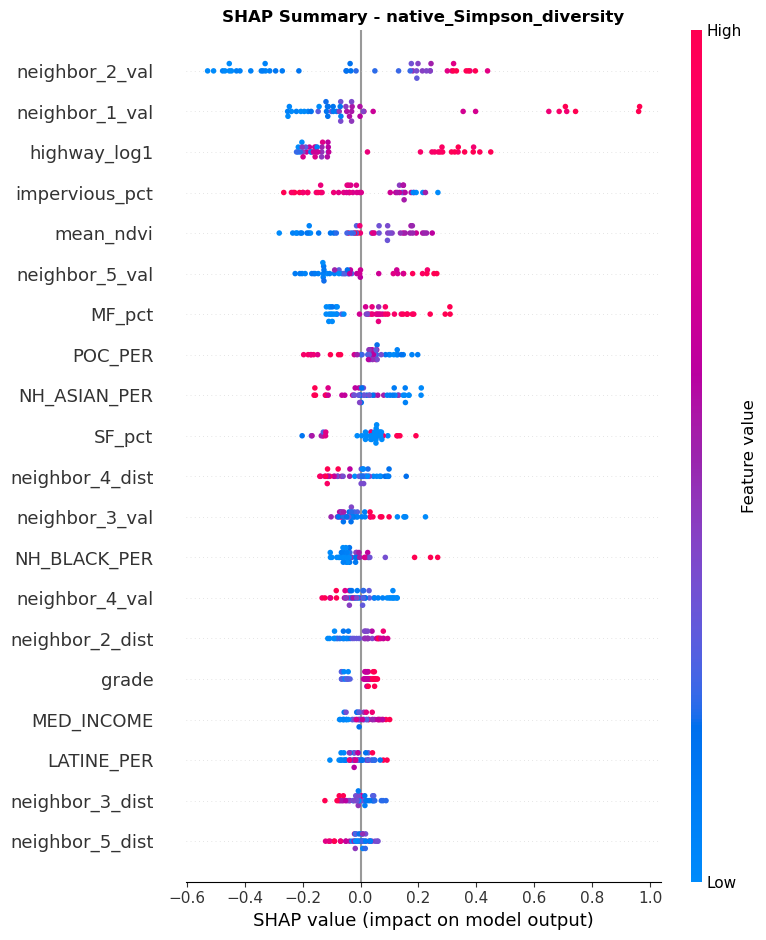

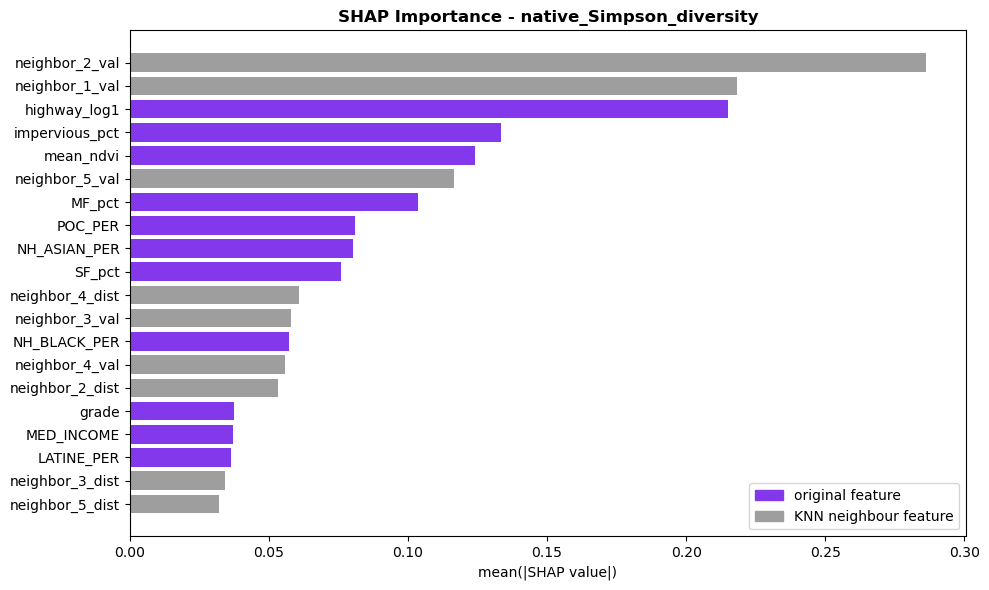

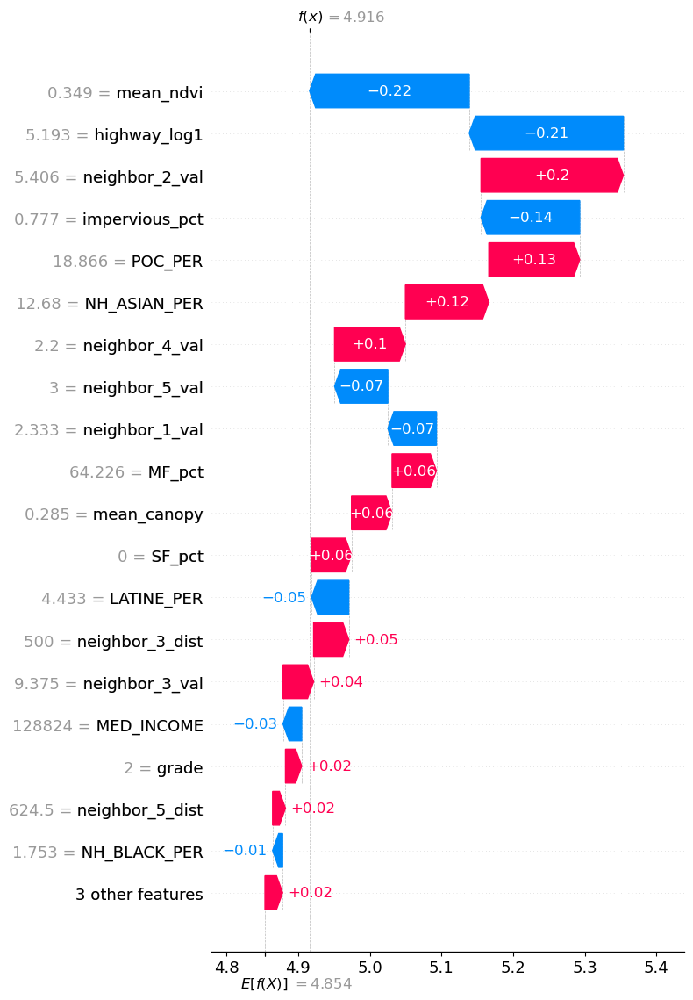

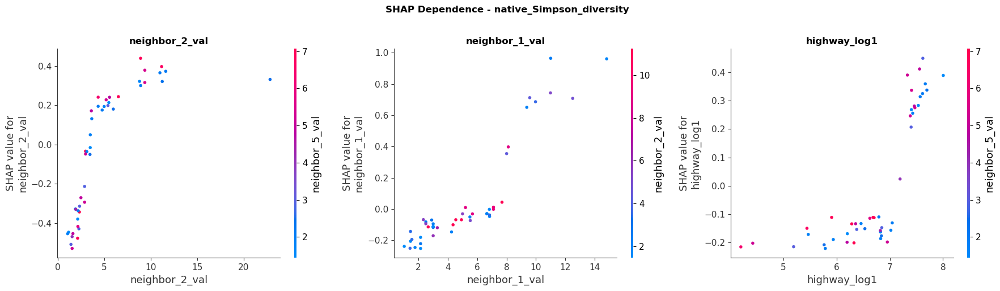


=== Model Performance ===
OOB Score: -0.0037
CV RMSE: 3.6753 (+/- 0.6244)
CV R²:   -0.0903 | CV MAE: 2.6897
Train RMSE: 2.6775 | Train R²: 0.4669
Test  RMSE: 3.9047 | Test  R²: 0.0648 | Test MAE: 2.9077

=== Top 10 Features ===
       feature  importance           type
neighbor_2_val    0.286230 neighbor value
neighbor_1_val    0.218399 neighbor value
  highway_log1    0.214894       original
impervious_pct    0.133278       original
     mean_ndvi    0.124067       original
neighbor_5_val    0.116364 neighbor value
        MF_pct    0.103674       original
       POC_PER    0.080833       original
  NH_ASIAN_PER    0.080146       original
        SF_pct    0.076064       original

KNN-RF | NONNATIVE | Species richness
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_neighbors': 7}


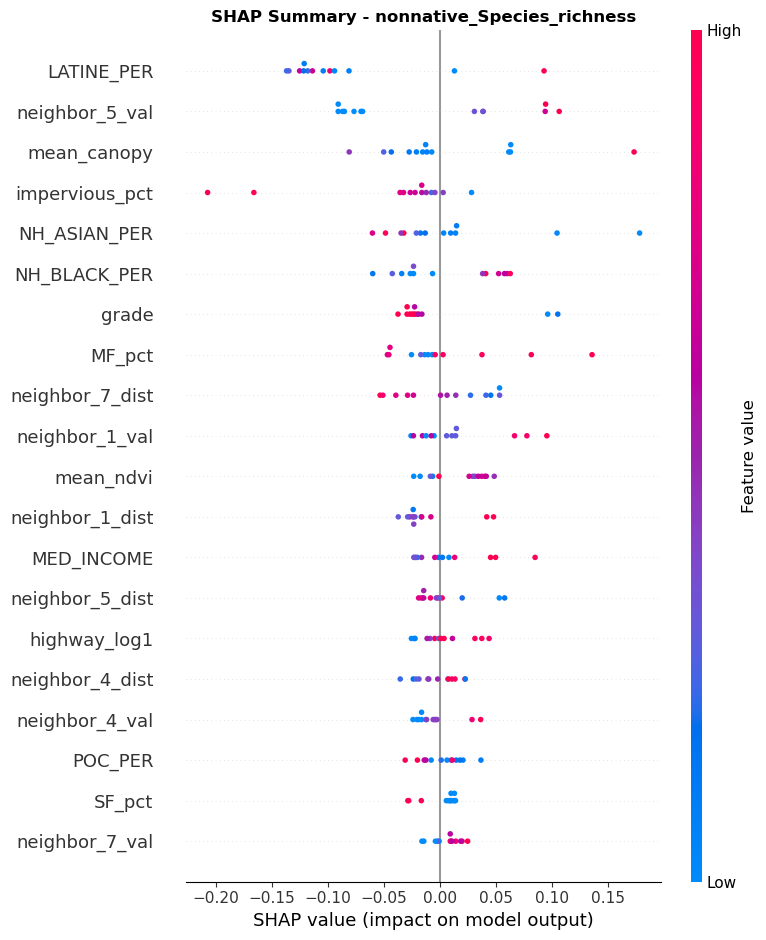

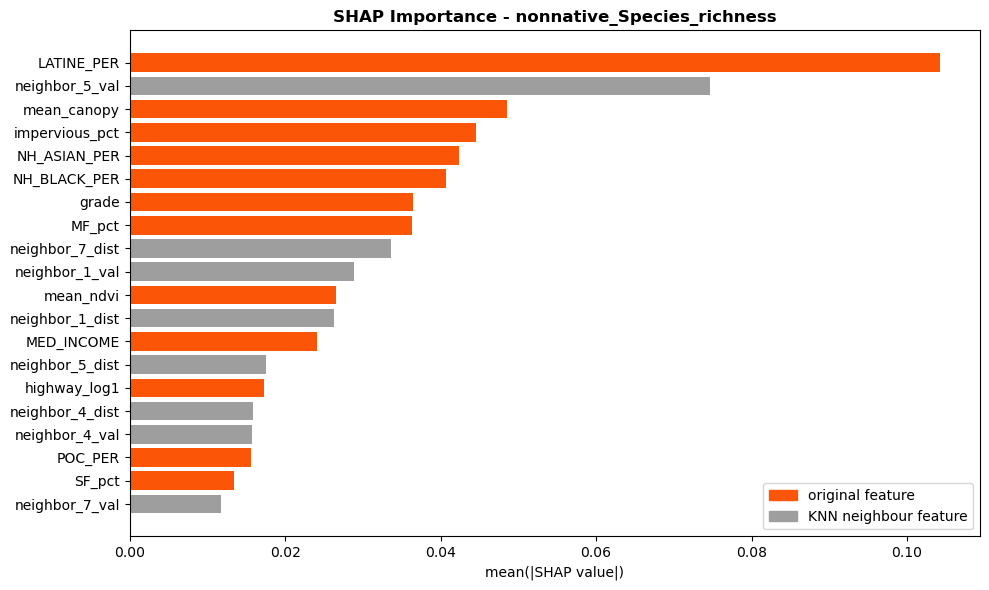

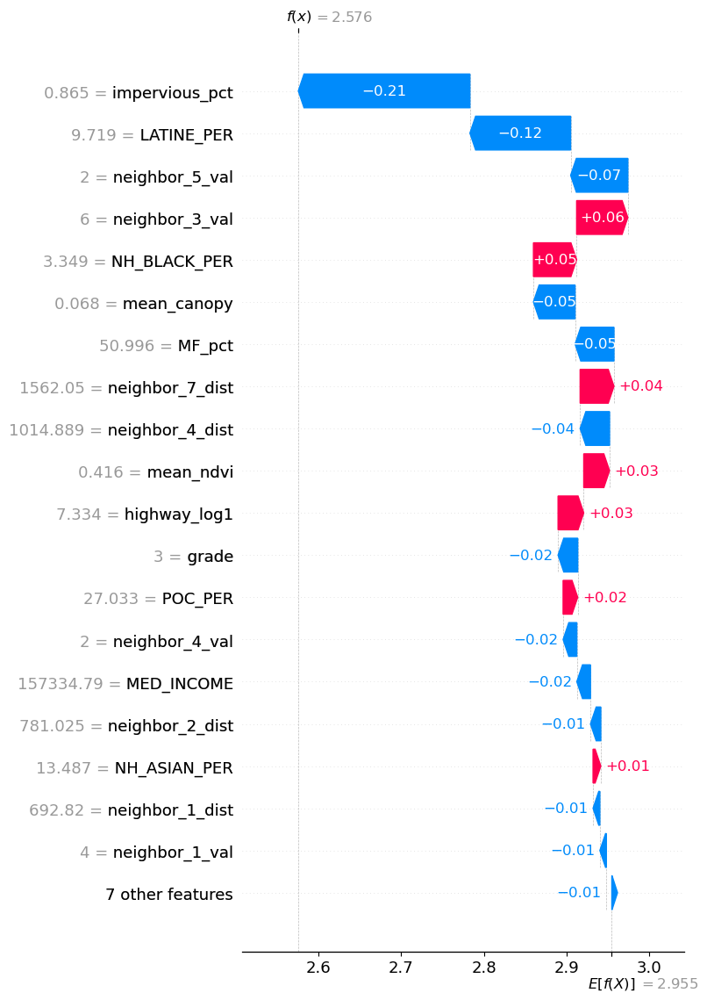

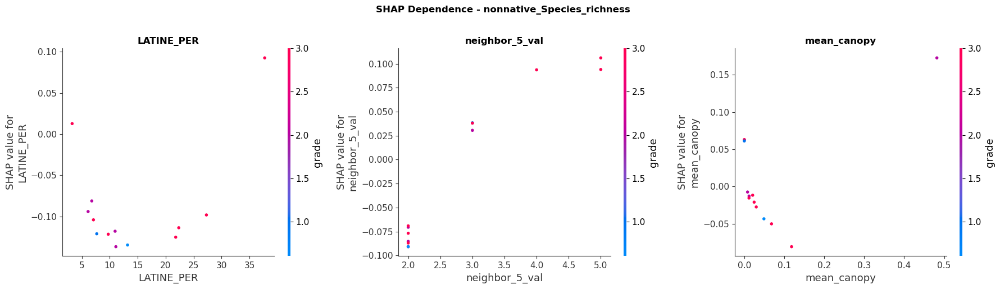


=== Model Performance ===
OOB Score: 0.0355
CV RMSE: 1.0361 (+/- 0.1672)
CV R²:   0.0163 | CV MAE: 0.8553
Train RMSE: 0.3848 | Train R²: 0.8734
Test  RMSE: 0.8225 | Test  R²: 0.2478 | Test MAE: 0.6638

=== Top 10 Features ===
        feature  importance              type
     LATINE_PER    0.104188          original
 neighbor_5_val    0.074702    neighbor value
    mean_canopy    0.048527          original
 impervious_pct    0.044499          original
   NH_ASIAN_PER    0.042400          original
   NH_BLACK_PER    0.040623          original
          grade    0.036487          original
         MF_pct    0.036355          original
neighbor_7_dist    0.033569 neighbor distance
 neighbor_1_val    0.028826    neighbor value

KNN-RF | NONNATIVE | Shannon diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_neighbors': 10}


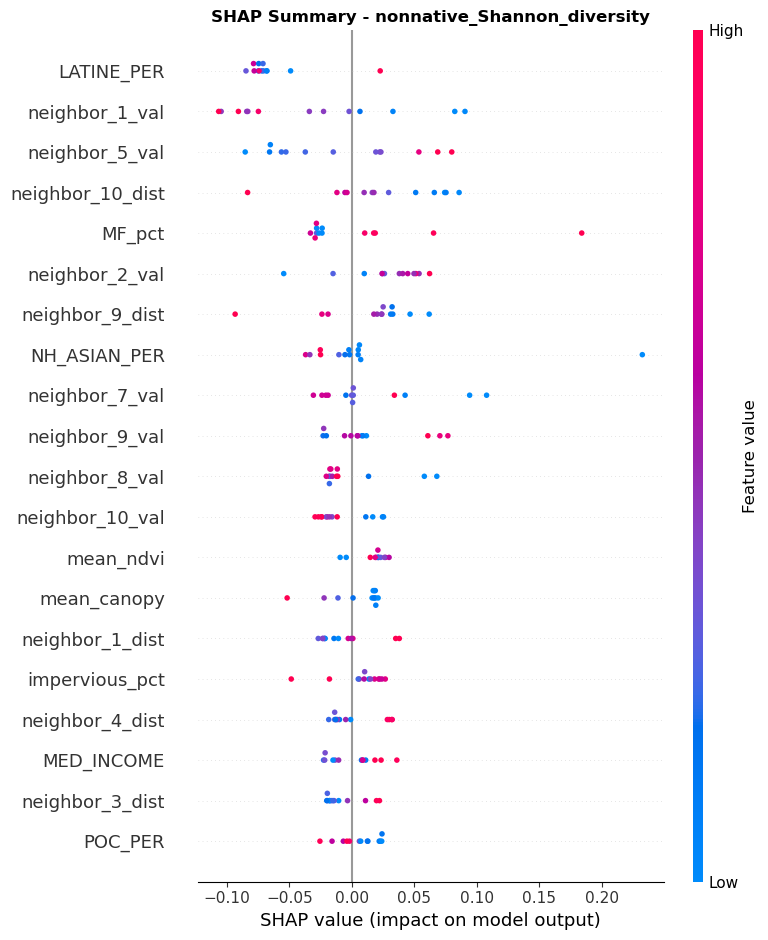

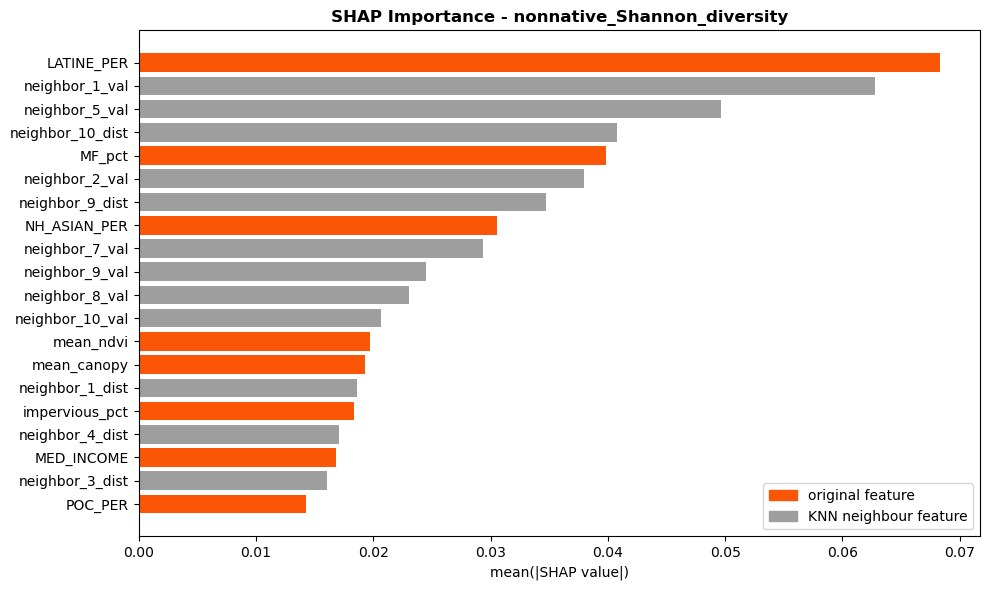

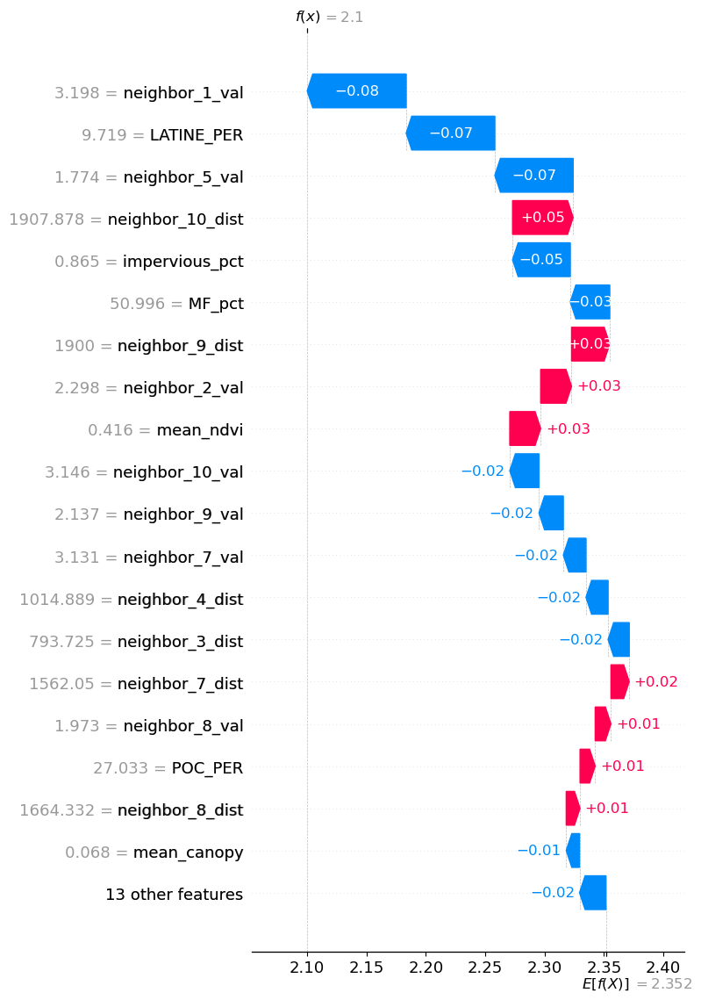

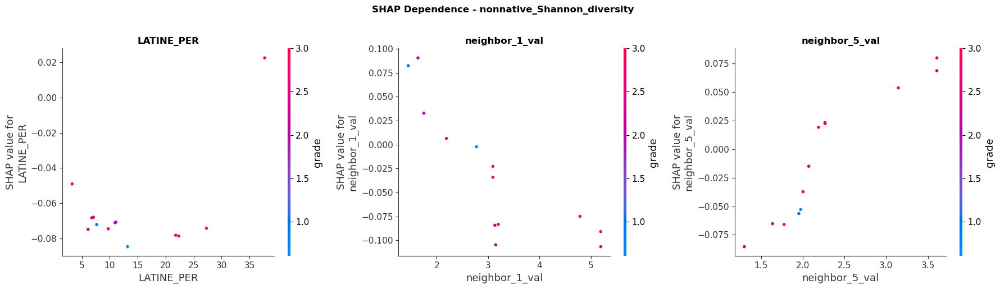


=== Model Performance ===
OOB Score: 0.1323
CV RMSE: 0.7536 (+/- 0.0991)
CV R²:   0.0233 | CV MAE: 0.6082
Train RMSE: 0.2789 | Train R²: 0.8885
Test  RMSE: 0.7354 | Test  R²: -1.1511 | Test MAE: 0.6496

=== Top 10 Features ===
         feature  importance              type
      LATINE_PER    0.068316          original
  neighbor_1_val    0.062759    neighbor value
  neighbor_5_val    0.049618    neighbor value
neighbor_10_dist    0.040795 neighbor distance
          MF_pct    0.039803          original
  neighbor_2_val    0.038006    neighbor value
 neighbor_9_dist    0.034699 neighbor distance
    NH_ASIAN_PER    0.030542          original
  neighbor_7_val    0.029315    neighbor value
  neighbor_9_val    0.024474    neighbor value

KNN-RF | NONNATIVE | Simpson diversity
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_neighbors': 10}


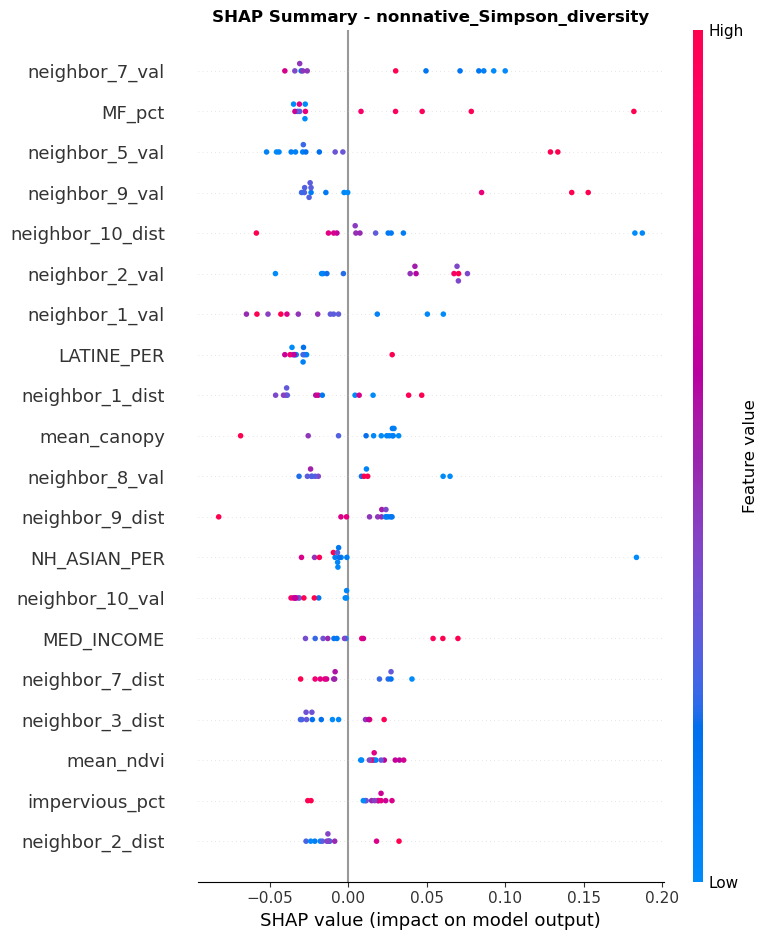

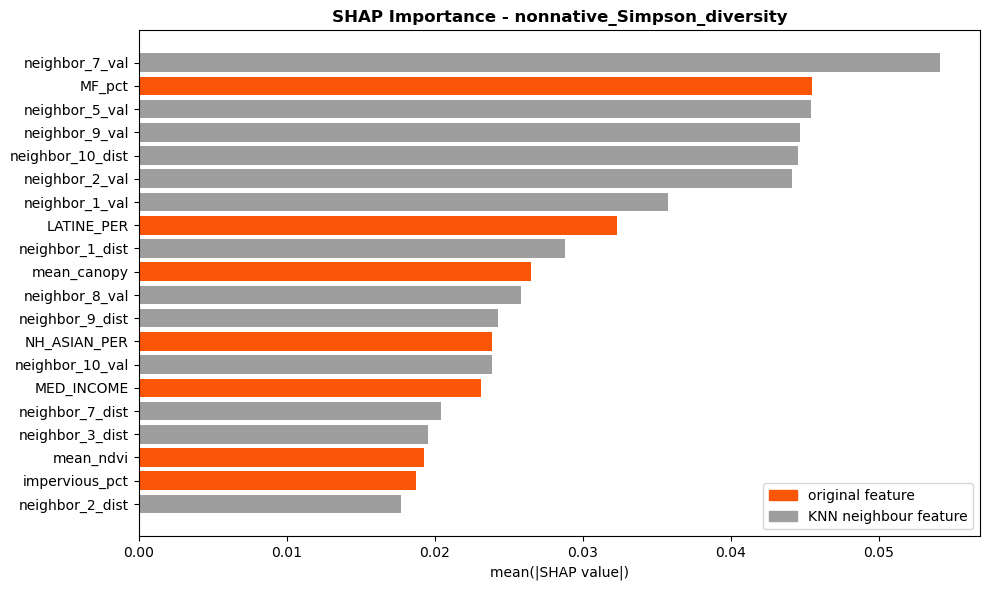

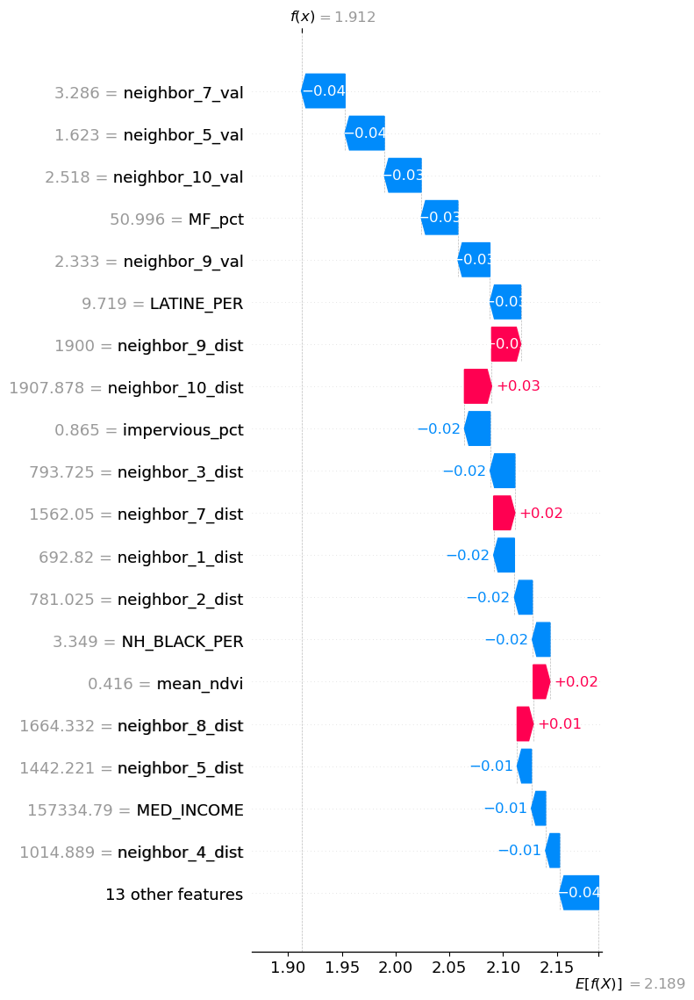

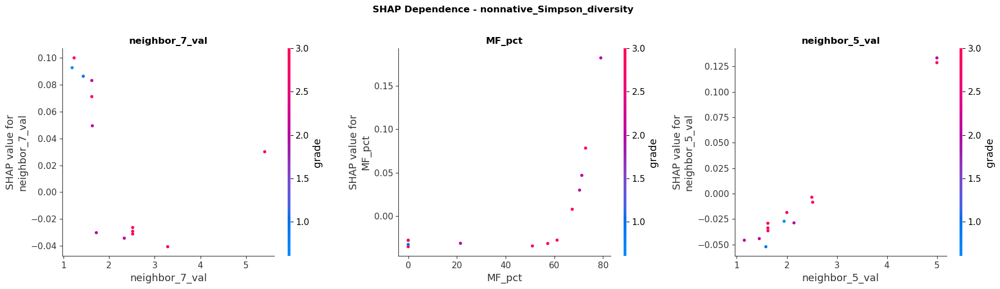


=== Model Performance ===
OOB Score: 0.0366
CV RMSE: 0.8580 (+/- 0.1835)
CV R²:   -0.2228 | CV MAE: 0.6780
Train RMSE: 0.3184 | Train R²: 0.8782
Test  RMSE: 0.8378 | Test  R²: -2.5345 | Test MAE: 0.7123

=== Top 10 Features ===
         feature  importance              type
  neighbor_7_val    0.054134    neighbor value
          MF_pct    0.045515          original
  neighbor_5_val    0.045421    neighbor value
  neighbor_9_val    0.044669    neighbor value
neighbor_10_dist    0.044553 neighbor distance
  neighbor_2_val    0.044165    neighbor value
  neighbor_1_val    0.035770    neighbor value
      LATINE_PER    0.032325          original
 neighbor_1_dist    0.028817 neighbor distance
     mean_canopy    0.026534          original
                               Test R²  Test RMSE     CV R² OOB Score  \
human_Species_richness       -0.135381   1.694012 -0.085371  0.053384   
human_Shannon_diversity      -1.300278   0.892106 -0.036365 -0.044909   
human_Simpson_diversity      -1.513

In [113]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import shap
import matplotlib.pyplot as plt
from datetime import datetime
from shapely import wkt

from sklearn.base import clone
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (GroupShuffleSplit, GroupKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


%run estimator_hab.py   #uses estimator_hab version

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

CRS = "EPSG:26910"   # labels the geometry only, it does not reproject. Confirm it matches your hexes.

GUILD_COLS = ['human_estimator', 'shrubgrass_estimator', 'trees_estimator',
              'water_estimator', 'native_estimator', 'nonnative_estimator']

DROP_COLS = ['Estimator_log_alt', 'Estimator_log', 'hex_id', 'Assemblage',
             'Diversity', 'Estimator', 'pop_density_sqkm'] + GUILD_COLS

GUILD_COLORS = {'human': '#E63946', 'shrubgrass': '#F1A208', 'trees': '#2A9D8F',
                'water': '#264653', 'native': '#8338EC', 'nonnative': '#FB5607'}

PARAM_GRID = {
    'n_neighbors':      [5, 7, 10],
    'max_depth':        [15, 30, None],
    'min_samples_leaf': [1, 3, 5],
    'max_features':     ['sqrt', 0.5],
}


def to_gdf(df, geom, crs):
    g = geom.apply(wkt.loads) if isinstance(geom.iloc[0], str) else geom
    out = df.copy()
    out['geometry'] = g.values
    return gpd.GeoDataFrame(out, geometry='geometry', crs=crs)


# ========= SHAP PLOT FUNCTION ==================
def make_shap_plots(rf_model, X_test_t, orig_cols, guild_name, save_path, tag=None,
                    max_display=20):
    """All features (original + individual neighbour features) are shown separately.
    orig_cols is only used to label/colour original vs neighbour features."""
    tag = tag or guild_name
    color = GUILD_COLORS.get(guild_name, '#1f77b4')
    NEIGHBOR_COLOR = '#9E9E9E'

    explainer = shap.TreeExplainer(rf_model)
    sv = explainer.shap_values(X_test_t, check_additivity=False)
    base_value = float(np.ravel(explainer.expected_value)[0])

    def ftype(c):
        if c in orig_cols:        return 'original'
        if c.endswith('_val'):    return 'neighbor value'
        return 'neighbor distance'

    def _save(name):
        if save_path:
            plt.savefig(f'{save_path}/{name}_{tag}.png', dpi=300, bbox_inches='tight')

    # 1. Dot summary: every feature, top `max_display` by mean |SHAP|
    shap.summary_plot(sv, X_test_t, plot_type="dot", max_display=max_display, show=False)
    plt.title(f'SHAP Summary - {tag}', fontweight='bold')
    plt.tight_layout(); _save('shap_summary'); plt.show()

    # 2. Bar: every feature, neighbour features in grey
    imp = pd.Series(np.abs(sv).mean(axis=0), index=X_test_t.columns).sort_values()
    shown = imp.tail(max_display)
    fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(shown))))
    ax.barh(shown.index, shown.values,
            color=[color if ftype(c) == 'original' else NEIGHBOR_COLOR for c in shown.index])
    ax.set_xlabel('mean(|SHAP value|)')
    ax.set_title(f'SHAP Importance - {tag}', fontweight='bold')
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=color, label='original feature'),
                       Patch(color=NEIGHBOR_COLOR, label='KNN neighbour feature')],
              loc='lower right')
    plt.tight_layout(); _save('shap_bar'); plt.show()

    # 3. Waterfall (first test row), all features
    shap.plots.waterfall(
        shap.Explanation(values=sv[0], base_values=base_value,
                         data=X_test_t.iloc[0].values,
                         feature_names=X_test_t.columns.tolist()),
        max_display=max_display, show=False)
    plt.tight_layout(); _save('shap_waterfall'); plt.show()

    # 4. Dependence: top 3 features overall (may include neighbour features)
    top3 = imp.sort_values(ascending=False).head(3).index
    fig, axes = plt.subplots(1, len(top3), figsize=(6 * len(top3), 5))
    for ax, feat in zip(np.atleast_1d(axes), top3):
        shap.dependence_plot(feat, sv, X_test_t, show=False, ax=ax)
        ax.set_title(feat, fontweight='bold')
    fig.suptitle(f'SHAP Dependence - {tag}', fontweight='bold', y=1.02)
    plt.tight_layout(); _save('shap_dependence'); plt.show()

    plt.close('all')

    # Full importance table with a type column
    shap_importance = (imp.rename_axis('feature').reset_index(name='importance')
                          .sort_values('importance', ascending=False)
                          .reset_index(drop=True))
    shap_importance['type'] = shap_importance['feature'].map(ftype)
    return explainer, sv, shap_importance

# ========= MODEL FUNCTION ==================
def train_rf_model_guild(data, guild_name, diversity_type, cv_folds=5, show_shap=True,
                         save_path=None, param_grid=None,
                         search_trees=150, final_trees=500):
    param_grid = param_grid or PARAM_GRID
    target_col = f'{guild_name}_estimator'
    tag = f"{guild_name}_{diversity_type.replace(' ', '_')}"
    print(f"\n{'='*60}\nKNN-RF | {guild_name.upper()} | {diversity_type}\n{'='*60}")

    # ---------- 1. Select rows ----------
    sub = (data[(data['Diversity'] == diversity_type) & data[target_col].notna()]
           .copy().reset_index(drop=True))
    if sub.empty:
        print("No rows for this model, skipping.")
        return None

    n_dup = sub['hex_id'].duplicated().sum()
    if n_dup:
        print(f"ℹ️ {n_dup} duplicate hex_ids: splitting and CV are grouped by hex_id.")

    y = sub[target_col]
    groups = sub['hex_id']
    X = sub.drop(columns=[c for c in DROP_COLS if c in sub.columns])
    if 'geometry_x' in X.columns:
        X = X.rename(columns={'geometry_x': 'geometry'})
    X = X.drop(columns=['geometry_y'], errors='ignore')
    assert 'geometry' in X.columns, "No geometry column found"

    # ---------- 2. Grouped split, encode, impute (fit on train only) ----------
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=123)
    tr, te = next(gss.split(X, y, groups=groups))
    X_train, X_test = X.iloc[tr].copy(), X.iloc[te].copy()
    y_train, y_test = y.iloc[tr], y.iloc[te]
    groups_train = groups.iloc[tr]

    geom_train = X_train.pop('geometry')
    geom_test  = X_test.pop('geometry')

    if 'grade' in X_train.columns:
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
        X_train[['grade']] = enc.fit_transform(X_train[['grade']].astype(str))
        X_test[['grade']]  = enc.transform(X_test[['grade']].astype(str))

    feat_cols = X_train.columns[X_train.notna().any()].tolist()
    X_train, X_test = X_train[feat_cols], X_test[feat_cols]

    imp = SimpleImputer(strategy='mean')
    X_train = pd.DataFrame(imp.fit_transform(X_train), columns=feat_cols, index=X_train.index)
    X_test  = pd.DataFrame(imp.transform(X_test),      columns=feat_cols, index=X_test.index)

    X_train = to_gdf(X_train, geom_train, CRS)
    X_test  = to_gdf(X_test,  geom_test,  CRS)

    # ---------- 3. Grid search (training set only, grouped folds) ----------
    max_k = int(len(X_train) * (cv_folds - 1) / cv_folds) - 2
    grid_k = [k for k in param_grid['n_neighbors'] if k <= max_k]
    if not grid_k:
        print(f"Too few rows ({len(X_train)}) for the n_neighbors grid, skipping.")
        return None
    pg = {**param_grid, 'n_neighbors': grid_k}

    cv = GroupKFold(n_splits=cv_folds)
    search = GridSearchCV(
        KNearestNeighborRF(n_estimators=search_trees, oob_score=False),
        pg, cv=cv, n_jobs=-1, refit='rmse', error_score='raise', verbose=1,
        scoring={'rmse': 'neg_root_mean_squared_error',
                 'mae':  'neg_mean_absolute_error',
                 'r2':   'r2'})
    search.fit(X_train, y_train, groups=groups_train)

    best_params = search.best_params_
    print(f"Best params: {best_params}")
    b, res = search.best_index_, search.cv_results_
    cv_rmse_mean, cv_rmse_std = -res['mean_test_rmse'][b], res['std_test_rmse'][b]
    cv_mae, cv_r2 = -res['mean_test_mae'][b], res['mean_test_r2'][b]

    cv_predictions = cross_val_predict(clone(search.best_estimator_), X_train, y_train,
                                       cv=cv, groups=groups_train, n_jobs=-1)

    # ---------- 4. Final fit with full-size forest + evaluation ----------
    rf_knn = KNearestNeighborRF(**best_params, n_estimators=final_trees,
                                oob_score=True).fit(X_train, y_train)
    rf_inner = rf_knn.estimator

    y_pred_test  = rf_knn.predict(X_test)
    y_pred_train = rf_knn.predict(X_train, exclude_self=True)
    X_test_t = rf_knn.transform(X_test)

    assert len(X_test_t.columns) == len(rf_inner.feature_importances_)

    scores = {
        'oob_score': getattr(rf_inner, 'oob_score_', np.nan),
        'cv_rmse_mean': cv_rmse_mean, 'cv_rmse_std': cv_rmse_std,
        'cv_mae': cv_mae, 'cv_r2': cv_r2,
        'cv_r2_pooled': r2_score(y_train, cv_predictions),
        'train_rmse': np.sqrt(mean_squared_error(y_train, y_pred_train)),
        'train_r2': r2_score(y_train, y_pred_train),
        'test_rmse': np.sqrt(mean_squared_error(y_test, y_pred_test)),
        'test_r2': r2_score(y_test, y_pred_test),
        'test_mae': mean_absolute_error(y_test, y_pred_test),
    }

    # ---------- 5. SHAP / importance ----------
    shap_values = explainer = None
    if show_shap:
        explainer, shap_values, feature_importance = make_shap_plots(
            rf_inner, X_test_t, feat_cols, guild_name, save_path, tag=tag)
    else:
        fi = pd.Series(rf_inner.feature_importances_, index=X_test_t.columns)[feat_cols]
        feature_importance = ((fi / fi.sum()).rename_axis('feature')
                              .reset_index(name='importance')
                              .sort_values('importance', ascending=False))

    # ---------- 6. Report ----------
    print("\n=== Model Performance ===")
    print(f"OOB Score: {scores['oob_score']:.4f}")
    print(f"CV RMSE: {scores['cv_rmse_mean']:.4f} (+/- {scores['cv_rmse_std']:.4f})")
    print(f"CV R²:   {scores['cv_r2']:.4f} | CV MAE: {scores['cv_mae']:.4f}")
    print(f"Train RMSE: {scores['train_rmse']:.4f} | Train R²: {scores['train_r2']:.4f}")
    print(f"Test  RMSE: {scores['test_rmse']:.4f} | Test  R²: {scores['test_r2']:.4f} "
          f"| Test MAE: {scores['test_mae']:.4f}")
    print("\n=== Top 10 Features ===")
    print(feature_importance.head(10).to_string(index=False))

    return {'guild': guild_name, 'diversity_type': diversity_type, 'tag': tag,
            'model': rf_knn, 'best_params': best_params,
            'cv_results': pd.DataFrame(search.cv_results_),
            'feature_importance': feature_importance,
            'X_train': X_train, 'X_test': X_test,
            'y_train': y_train, 'y_test': y_test,
            'y_pred_test': y_pred_test, 'cv_predictions': cv_predictions,
            'metrics': scores, 'shap_values': shap_values, 'explainer': explainer}


# ---------- Run all guilds ----------
save_dir = '../results_images'
os.makedirs(save_dir, exist_ok=True)
diversity_types = ['Species richness', 'Shannon diversity', 'Simpson diversity']
guilds = ['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative']
guild_results = {}

for guild in guilds:
    for div in diversity_types:
        res = train_rf_model_guild(combined_df, guild, div, cv_folds=5,
                                   show_shap=True, save_path=save_dir)
        if res is not None:
            guild_results[res['tag']] = res

if guild_results:
    comparison_df = pd.DataFrame({
        g: {'Test R²': r['metrics']['test_r2'], 'Test RMSE': r['metrics']['test_rmse'],
            'CV R²': r['metrics']['cv_r2'], 'OOB Score': r['metrics']['oob_score'],
            'Best params': str(r['best_params'])}
        for g, r in guild_results.items()}).T

    print(comparison_df.round(4))
    out = f"{save_dir}/guild_model_comparison_{timestamp}.csv"
    comparison_df.to_csv(out)
    print(f"✓ Saved comparison to {out}")

### Habitat SHAP Radial Plots with Stats (KNN-RF)

In [33]:
SPATIAL_LABEL = 'Spatial context (KNN)'

def plot_guild_feature_radar_shap_with_stats(guild_results, comparison_df, guild_name='trees',
                                             diversity_type='Species richness',
                                             include_spatial=False, save_path=None):
    """
    Radar plot of mean |SHAP| for ORIGINAL features (neighbor features are grouped
    into one 'Spatial context' term, shown in the stats box or as an optional grey axis).
    Top 3 covariate categories are highlighted with their scores.
    """
    from math import pi

    key = f"{guild_name}_{diversity_type.replace(' ', '_')}"
    if key not in guild_results:
        print(f"No results found for {guild_name} with {diversity_type}")
        return

    result = guild_results[key]
    shap_importance = result.get('shap_importance')
    if shap_importance is None:
        print(f"No grouped SHAP importance for {key}. Rerun training with show_shap=True "
              f"and the updated return dict.")
        return

    # ---- split covariates vs grouped spatial term ----
    is_spatial_row = shap_importance['feature'] == SPATIAL_LABEL
    spatial_value = shap_importance.loc[is_spatial_row, 'importance'].sum()   # 0 if absent
    cov_importance = shap_importance.loc[~is_spatial_row].reset_index(drop=True)
    total_shap = shap_importance['importance'].sum()
    spatial_share = spatial_value / total_shap if total_shap > 0 else np.nan

    print(f"\nTop 15 covariates by SHAP importance:")
    print(cov_importance.sort_values('importance', ascending=False).head(15))
    print(f"{SPATIAL_LABEL}: {spatial_value:.4f} ({spatial_share:.1%} of total)")

    # ---- feature categories ----
    feature_categories = {
        'Vegetation\nComplexity': ['mean_canopy'],
        'NDVI': ['mean_ndvi'],
        'Distance to\nHighway': ['highway_log1'],
        'Impervious\nSurface %': ['impervious_pct'],
        'Median\nIncome': ['MED_INCOME'],
        'POC %': ['POC_PER'],
        'White %': ['NH_WHITE_PER'],
        'Black %': ['NH_BLACK_PER'],
        'Latine %': ['NH_LATINO_PER'],
        'Asian %': ['NH_ASIAN_PER'],
        'Single Family\nZoning': ['SF_pct'],
        'Multi Family\nZoning': ['MF_pct'],
        'HOLC\nGrades': ['grade']
    }

    imp_lookup = cov_importance.set_index('feature')['importance']
    category_scores, category_labels = [], []

    print(f"\n{guild_name.upper()} - {diversity_type}\n{'='*60}")
    for category, features in feature_categories.items():
        found = [imp_lookup[f] for f in features if f in imp_lookup.index]
        missing = [f for f in features if f not in imp_lookup.index]
        if missing:
            print(f"  ✗ Missing {missing} for {category.replace(chr(10), ' ')}")
        if found:
            # SHAP is additive, so SUM is the right aggregation for multi-feature categories.
            # (identical to mean for your current single-feature categories)
            category_scores.append(float(np.sum(found)))
            category_labels.append(category)
            print(f"  {category.replace(chr(10), ' '):<30}: {category_scores[-1]:.4f}")

    if not category_scores:
        print(f"No valid data for {guild_name}")
        return

    # top 3 among covariates only (before optionally appending spatial axis)
    top_3_indices = sorted(range(len(category_scores)),
                           key=lambda i: category_scores[i], reverse=True)[:3]

    # optional spatial axis
    spatial_idx = None
    if include_spatial:
        category_scores.append(float(spatial_value))
        category_labels.append('Spatial\nContext\n(KNN)')
        spatial_idx = len(category_scores) - 1

    # ---- model stats ----
    stats_row = comparison_df[(comparison_df['Guild'] == guild_name) &
                              (comparison_df['Diversity'] == diversity_type)]
    if stats_row.empty:
        print(f"No statistics found for {guild_name} with {diversity_type}")
        return
    stats = stats_row.iloc[0]

    # ---- bins ----
    max_shap = max(category_scores)
    weak_threshold, moderate_threshold = max_shap * 0.33, max_shap * 0.67
    print(f"\nSHAP bins: weak ≤ {weak_threshold:.4f} < moderate ≤ {moderate_threshold:.4f} < strong")
    print("Top 3 categories:")
    for idx in top_3_indices:
        print(f"  {category_labels[idx].replace(chr(10), ' ')}: {category_scores[idx]:.4f}")

    # ---- geometry of the plot ----
    N = len(category_labels)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    scores_plot = category_scores + [category_scores[0]]
    angles_plot = angles + [angles[0]]

    guild_colors = {'human': '#E63946', 'shrubgrass': '#F1A208', 'trees': '#2A9D8F',
                    'water': '#264653', 'native': '#8338EC', 'nonnative': '#FB5607'}
    color = guild_colors.get(guild_name, '#999999')

    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    ax.plot(angles_plot, scores_plot, 'o-', linewidth=3.5, color=color, markersize=10)
    ax.fill(angles_plot, scores_plot, alpha=0.25, color=color)

    for idx in top_3_indices:
        ax.plot(angles[idx], category_scores[idx], 'o', markersize=15, color=color,
                zorder=5, markeredgecolor=color, markeredgewidth=1)
    if spatial_idx is not None:
        ax.plot(angles[spatial_idx], category_scores[spatial_idx], 's', markersize=12,
                color='grey', zorder=5)

    ax.set_xticks(angles)
    labels = [f"{lab}\n({category_scores[i]:.4f})" if i in top_3_indices else lab
              for i, lab in enumerate(category_labels)]
    ax.set_xticklabels(labels, fontsize=10, fontweight='bold')

    for i, tick in enumerate(ax.get_xticklabels()):
        if i in top_3_indices:
            tick.set_fontsize(11); tick.set_color(color); tick.set_fontweight('extra bold')
        elif i == spatial_idx:
            tick.set_color('grey'); tick.set_style('italic')

    ax.set_ylim(0, max_shap * 1.1)
    ax.set_yticks([weak_threshold, moderate_threshold, max_shap])
    ax.set_yticklabels([f'Weak\n({weak_threshold:.3f})',
                        f'Moderate\n({moderate_threshold:.3f})',
                        f'Strong\n({max_shap:.3f})'], fontsize=10, fontweight='bold')

    ax.set_title(f'{guild_name.title()} Guild | {diversity_type}\n'
                 f'Mean Absolute SHAP Values (covariates, conditional on spatial context)',
                 fontsize=16, fontweight='bold', pad=30)
    ax.grid(True, alpha=0.3)

    stats_text = (
        f"Model Performance\n{'─'*20}\n"
        f"Test R² = {stats['Test_R2']:.3f}\n"
        f"CV R² = {stats['CV_R2']:.3f}\n"
        f"Test RMSE = {stats['Test_RMSE']:.3f}\n"
        f"Test MAE = {stats['Test_MAE']:.3f}\n"
        f"n = {stats['N_samples']:.0f}\n\n"
        f"Spatial context (KNN)\n{'─'*20}\n"
        f"mean|SHAP| = {spatial_value:.3f}\n"
        f"share of total = {spatial_share:.0%}\n"
    )
    ax.text(1.35, 0.5, stats_text, transform=ax.transAxes, fontsize=9,
            verticalalignment='center', family='monospace',
            bbox=dict(boxstyle='round', facecolor='white', edgecolor=color,
                      linewidth=2, alpha=0.9))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {save_path}")
    plt.show()


# Test
plot_guild_feature_radar_shap_with_stats(
    guild_results, comparison_df,
    guild_name='trees', diversity_type='Species richness',
    include_spatial=False,
    save_path='../results_images/test_radar.png'
)

No results found for trees with Species richness


### Understanding Habitat SHAP Summary Plots

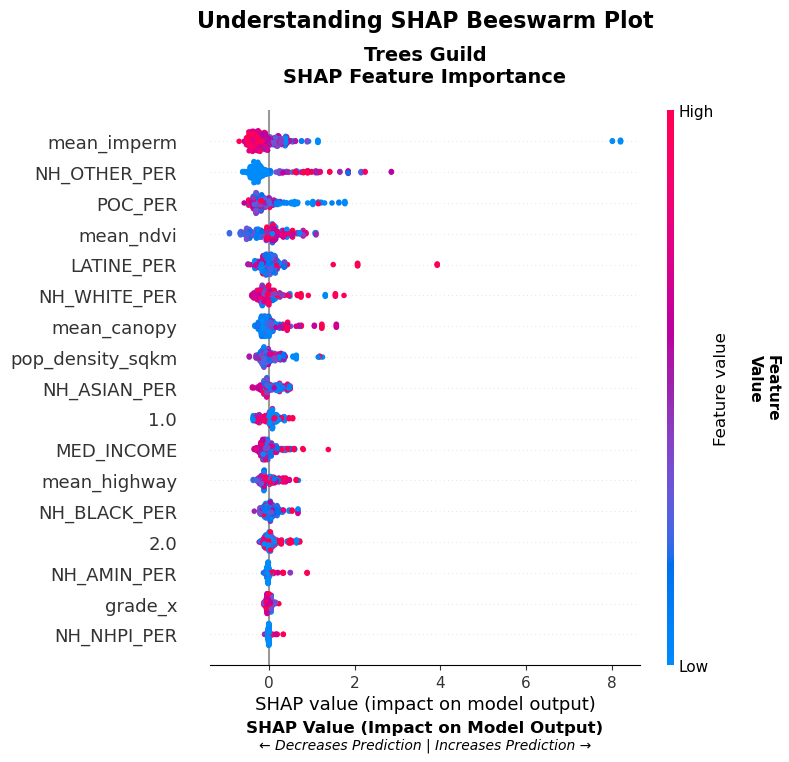

✓ Saved annotated SHAP plot: ../results_images/shap_explained_trees.png


SHAP VALUE vs FEATURE VALUE EXPLANATION

Example: mean_canopy for trees guild

┌──────────────────────────────────────────────────────────────────────────────┐
│ FEATURE VALUE (Color in plot)                                             │
├──────────────────────────────────────────────────────────────────────────────┤
│ • The actual measured value of the feature in your dataset                │
│ • Examples: canopy height = 15m, % impervious = 45%, income = $75,000     │
│ • Color coding: Red = High value, Blue = Low value                        │
└──────────────────────────────────────────────────────────────────────────────┘

  Real examples from your data:
    Low mean_canopy: 0.00
    High mean_canopy: 0.48

┌──────────────────────────────────────────────────────────────────────────────┐
│ SHAP VALUE (X-axis position)                                              │
├─────────────────────────────────────────────

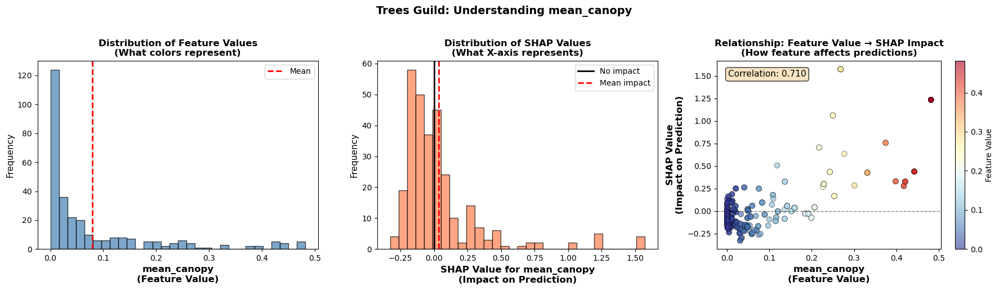

✓ Saved feature-SHAP relationship plot: ../results_images/shap_feature_relationship_trees.png



In [ ]:

# Visual explanation with annotated plot
def explain_shap_beeswarm(guild_results, guild_name='trees', save_path=None):
    """
    Create SHAP beeswarm plot with detailed annotations explaining the axes
    """
    import shap
    
    if guild_name not in guild_results:
        print(f"No results found for {guild_name}")
        return
    
    result = guild_results[guild_name]
    shap_values = result['shap_values']
    X_test = result['X_test']
    
    if shap_values is None:
        print(f"No SHAP values found for {guild_name}")
        return
    
    # Create the beeswarm plot
    fig, ax = plt.subplots(figsize=(12, 10))
    shap.summary_plot(shap_values, X_test, plot_type="dot", show=False)
    
    # Add detailed annotations
    plt.text(0.5, 1.15, 'Understanding SHAP Beeswarm Plot', 
             transform=ax.transAxes, fontsize=16, fontweight='bold', ha='center')
    
    # Annotate x-axis
    plt.text(0.5, -0.12, 'SHAP Value (Impact on Model Output)', 
             transform=ax.transAxes, fontsize=12, fontweight='bold', ha='center')
    plt.text(0.5, -0.15, '← Decreases Prediction | Increases Prediction →', 
             transform=ax.transAxes, fontsize=10, ha='center', style='italic')
    
    # Annotate color bar
    plt.text(1.25, 0.5, 'Feature\nValue', 
             transform=ax.transAxes, fontsize=11, fontweight='bold', 
             rotation=-90, va='center')
    
    plt.title(f'{guild_name.title()} Guild\nSHAP Feature Importance', 
              fontsize=14, fontweight='bold', pad=20)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved annotated SHAP plot: {save_path}\n")


# Detailed explanation with examples
def print_shap_explanation(guild_results, guild_name='trees', example_feature='mean_canopy'):
    """
    Print detailed explanation of SHAP values vs feature values with examples
    """
    if guild_name not in guild_results:
        return
    
    result = guild_results[guild_name]
    shap_values = result['shap_values']
    X_test = result['X_test']
    
    if shap_values is None or example_feature not in X_test.columns:
        return
    
    print("\n" + "="*80)
    print("SHAP VALUE vs FEATURE VALUE EXPLANATION")
    print("="*80)
    
    print(f"\nExample: {example_feature} for {guild_name} guild\n")
    
    # Get feature index
    feature_idx = list(X_test.columns).index(example_feature)
    
    # Get data for this feature
    feature_values = X_test[example_feature].values
    feature_shap_values = shap_values[:, feature_idx]
    
    # Find examples
    low_value_idx = np.argmin(feature_values)
    high_value_idx = np.argmax(feature_values)
    
    print("┌" + "─"*78 + "┐")
    print("│ FEATURE VALUE (Color in plot)                                             │")
    print("├" + "─"*78 + "┤")
    print("│ • The actual measured value of the feature in your dataset                │")
    print("│ • Examples: canopy height = 15m, % impervious = 45%, income = $75,000     │")
    print("│ • Color coding: Red = High value, Blue = Low value                        │")
    print("└" + "─"*78 + "┘")
    
    print(f"\n  Real examples from your data:")
    print(f"    Low {example_feature}: {feature_values[low_value_idx]:.2f}")
    print(f"    High {example_feature}: {feature_values[high_value_idx]:.2f}")
    
    print("\n┌" + "─"*78 + "┐")
    print("│ SHAP VALUE (X-axis position)                                              │")
    print("├" + "─"*78 + "┤")
    print("│ • How much this feature value pushes the prediction up or down            │")
    print("│ • Measured in units of the target variable (e.g., bird richness)          │")
    print("│ • Positive SHAP = increases predicted richness                            │")
    print("│ • Negative SHAP = decreases predicted richness                            │")
    print("│ • Magnitude = strength of impact                                          │")
    print("└" + "─"*78 + "┘")
    
    print(f"\n  Real examples from your model:")
    print(f"    SHAP value when {example_feature} is low: {feature_shap_values[low_value_idx]:.3f}")
    print(f"    SHAP value when {example_feature} is high: {feature_shap_values[high_value_idx]:.3f}")
    
    # Interpretation
    print("\n" + "="*80)
    print("INTERPRETATION GUIDE")
    print("="*80)
    
    print("\n📊 What patterns tell you:\n")
    
    print("  1. RED DOTS ON THE RIGHT (High feature value → Positive SHAP)")
    print("     → High values of this feature INCREASE predicted richness")
    print("     Example: High canopy cover → more birds predicted\n")
    
    print("  2. BLUE DOTS ON THE LEFT (Low feature value → Negative SHAP)")
    print("     → Low values of this feature DECREASE predicted richness")
    print("     Example: Low canopy cover → fewer birds predicted\n")
    
    print("  3. RED DOTS ON THE LEFT (High feature value → Negative SHAP)")
    print("     → High values of this feature DECREASE predicted richness")
    print("     Example: High % impervious surface → fewer birds predicted\n")
    
    print("  4. BLUE DOTS ON THE RIGHT (Low feature value → Positive SHAP)")
    print("     → Low values of this feature INCREASE predicted richness")
    print("     Example: Low distance to highway → more birds predicted\n")
    
    # Calculate correlation between feature value and SHAP value
    correlation = np.corrcoef(feature_values, feature_shap_values)[0, 1]
    
    print(f"\n📈 For {example_feature}:")
    print(f"   Correlation between feature value and SHAP value: {correlation:.3f}")
    
    if correlation > 0.3:
        print(f"   → Higher {example_feature} generally INCREASES {guild_name} richness")
    elif correlation < -0.3:
        print(f"   → Higher {example_feature} generally DECREASES {guild_name} richness")
    else:
        print(f"   → {example_feature} has complex/non-linear relationship with {guild_name} richness")
    
    print("\n" + "="*80 + "\n")


# Concrete example with real data visualization
def visualize_shap_feature_relationship(guild_results, guild_name='trees', 
                                        feature_name='mean_canopy', save_path=None):
    """
    Create side-by-side visualization showing feature value vs SHAP value
    """
    if guild_name not in guild_results:
        return
    
    result = guild_results[guild_name]
    shap_values = result['shap_values']
    X_test = result['X_test']
    y_test = result['y_test']
    
    if shap_values is None or feature_name not in X_test.columns:
        return
    
    feature_idx = list(X_test.columns).index(feature_name)
    feature_values = X_test[feature_name].values
    feature_shap_values = shap_values[:, feature_idx]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Plot 1: Feature value distribution
    axes[0].hist(feature_values, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
    axes[0].set_xlabel(f'{feature_name}\n(Feature Value)', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Frequency', fontsize=11)
    axes[0].set_title('Distribution of Feature Values\n(What colors represent)', fontsize=12, fontweight='bold')
    axes[0].axvline(np.mean(feature_values), color='red', linestyle='--', linewidth=2, label='Mean')
    axes[0].legend()
    
    # Plot 2: SHAP value distribution
    axes[1].hist(feature_shap_values, bins=30, color='coral', alpha=0.7, edgecolor='black')
    axes[1].set_xlabel(f'SHAP Value for {feature_name}\n(Impact on Prediction)', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Frequency', fontsize=11)
    axes[1].set_title('Distribution of SHAP Values\n(What X-axis represents)', fontsize=12, fontweight='bold')
    axes[1].axvline(0, color='black', linestyle='-', linewidth=2, label='No impact')
    axes[1].axvline(np.mean(feature_shap_values), color='red', linestyle='--', linewidth=2, label='Mean impact')
    axes[1].legend()
    
    # Plot 3: Feature value vs SHAP value (dependency plot)
    scatter = axes[2].scatter(feature_values, feature_shap_values, 
                             c=feature_values, cmap='RdYlBu_r', 
                             alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
    axes[2].set_xlabel(f'{feature_name}\n(Feature Value)', fontsize=12, fontweight='bold')
    axes[2].set_ylabel(f'SHAP Value\n(Impact on Prediction)', fontsize=12, fontweight='bold')
    axes[2].set_title('Relationship: Feature Value → SHAP Impact\n(How feature affects predictions)', 
                     fontsize=12, fontweight='bold')
    axes[2].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    
    # Add correlation info
    correlation = np.corrcoef(feature_values, feature_shap_values)[0, 1]
    axes[2].text(0.05, 0.95, f'Correlation: {correlation:.3f}', 
                transform=axes[2].transAxes, fontsize=11, 
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.colorbar(scatter, ax=axes[2], label='Feature Value')
    
    plt.suptitle(f'{guild_name.title()} Guild: Understanding {feature_name}', 
                fontsize=14, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved feature-SHAP relationship plot: {save_path}\n")


# Run explanations for a guild
guild = 'trees'

# 1. Create annotated beeswarm plot
explain_shap_beeswarm(
    guild_results, 
    guild_name=guild,
    save_path=f'../results_images/shap_explained_{guild}.png'
)

# 2. Print detailed text explanation
print_shap_explanation(
    guild_results, 
    guild_name=guild, 
    example_feature='mean_canopy'
)

# 3. Visualize feature-SHAP relationship
visualize_shap_feature_relationship(
    guild_results, 
    guild_name=guild,
    feature_name='mean_canopy',
    save_path=f'../results_images/shap_feature_relationship_{guild}.png'
)




In [24]:
def plot_shap_dependence_comprehensive(guild_results, guild_name='trees', 
                                       top_n_features=10, save_path=None):
    """
    Create comprehensive dependence plots for top N features
    Shows: SHAP dependence + feature distribution + SHAP distribution
    """
    import shap
    
    if guild_name not in guild_results:
        print(f"No results found for {guild_name}")
        return
    
    result = guild_results[guild_name]
    shap_values = result['shap_values']
    X_test = result['X_test']
    
    if shap_values is None:
        print(f"No SHAP values found for {guild_name}")
        return
    
    # Get feature importance
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    feature_importance = pd.DataFrame({
        'feature': X_test.columns,
        'importance': mean_abs_shap
    }).sort_values('importance', ascending=False)
    
    top_features = feature_importance.head(top_n_features)['feature'].tolist()
    
    print(f"\n{'='*80}")
    print(f"SHAP DEPENDENCE ANALYSIS - {guild_name.upper()} GUILD")
    print(f"Top {top_n_features} Most Important Features")
    print(f"{'='*80}\n")
    
    # Guild color
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    color = guild_colors.get(guild_name, '#1f77b4')
    
    for i, feature in enumerate(top_features, 1):
        feature_idx = list(X_test.columns).index(feature)
        feature_values = X_test[feature].values
        feature_shap_values = shap_values[:, feature_idx]
        
        # Create 3-panel figure
        fig = plt.figure(figsize=(18, 5))
        gs = fig.add_gridspec(1, 3, width_ratios=[1.5, 1, 1], hspace=0.3)
        
        # Panel 1: SHAP Dependence Plot
        ax1 = fig.add_subplot(gs[0])
        scatter = ax1.scatter(feature_values, feature_shap_values, 
                            c=feature_values, cmap='RdYlBu_r', 
                            alpha=0.6, s=30, edgecolors='black', linewidth=0.5)
        
        # Add trend line
        z = np.polyfit(feature_values, feature_shap_values, 2)
        p = np.poly1d(z)
        x_sorted = np.sort(feature_values)
        ax1.plot(x_sorted, p(x_sorted), "r--", alpha=0.8, linewidth=2, label='Trend')
        
        ax1.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
        ax1.set_xlabel(f'{feature}\n(Feature Value)', fontsize=11, fontweight='bold')
        ax1.set_ylabel('SHAP Value\n(Impact on Prediction)', fontsize=11, fontweight='bold')
        ax1.set_title(f'SHAP Dependence: {feature}', fontsize=12, fontweight='bold')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Calculate and display correlation
        correlation = np.corrcoef(feature_values, feature_shap_values)[0, 1]
        ax1.text(0.05, 0.95, f'Correlation: {correlation:.3f}', 
                transform=ax1.transAxes, fontsize=10,
                verticalalignment='top', 
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
        
        plt.colorbar(scatter, ax=ax1, label='Feature Value')
        
        # Panel 2: Feature Value Distribution
        ax2 = fig.add_subplot(gs[1])
        ax2.hist(feature_values, bins=30, color=color, alpha=0.7, edgecolor='black')
        ax2.axvline(np.mean(feature_values), color='red', linestyle='--', 
                   linewidth=2, label=f'Mean: {np.mean(feature_values):.2f}')
        ax2.axvline(np.median(feature_values), color='blue', linestyle='--', 
                   linewidth=2, label=f'Median: {np.median(feature_values):.2f}')
        ax2.set_xlabel(f'{feature}', fontsize=11, fontweight='bold')
        ax2.set_ylabel('Frequency', fontsize=11)
        ax2.set_title(f'Distribution of {feature}', fontsize=12, fontweight='bold')
        ax2.legend(fontsize=9)
        ax2.grid(True, alpha=0.3, axis='y')
        
        # Add statistics
        stats_text = f'Min: {np.min(feature_values):.2f}\nMax: {np.max(feature_values):.2f}\nStd: {np.std(feature_values):.2f}'
        ax2.text(0.95, 0.95, stats_text, transform=ax2.transAxes, 
                fontsize=9, verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.5))
        
        # Panel 3: SHAP Value Distribution
        ax3 = fig.add_subplot(gs[2])
        ax3.hist(feature_shap_values, bins=30, color='coral', alpha=0.7, edgecolor='black')
        ax3.axvline(0, color='black', linestyle='-', linewidth=2, label='No impact')
        ax3.axvline(np.mean(feature_shap_values), color='red', linestyle='--', 
                   linewidth=2, label=f'Mean: {np.mean(feature_shap_values):.3f}')
        ax3.set_xlabel('SHAP Value', fontsize=11, fontweight='bold')
        ax3.set_ylabel('Frequency', fontsize=11)
        ax3.set_title(f'SHAP Distribution for {feature}', fontsize=12, fontweight='bold')
        ax3.legend(fontsize=9)
        ax3.grid(True, alpha=0.3, axis='y')
        
        # Add statistics
        pct_positive = (feature_shap_values > 0).sum() / len(feature_shap_values) * 100
        shap_stats_text = f'Positive: {pct_positive:.1f}%\nNegative: {100-pct_positive:.1f}%'
        ax3.text(0.95, 0.95, shap_stats_text, transform=ax3.transAxes, 
                fontsize=9, verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.5))
        
        # Main title
        fig.suptitle(f'{guild_name.title()} Guild - Feature #{i}: {feature}', 
                    fontsize=14, fontweight='bold', y=1.02)
        
        plt.tight_layout()
        
        if save_path:
            plt.savefig(f'{save_path}/dependence_{guild_name}_{feature}.png', 
                       dpi=300, bbox_inches='tight')
        plt.show()
        
        # Print interpretation
        print(f"\n{'─'*80}")
        print(f"Feature #{i}: {feature}")
        print(f"{'─'*80}")
        print(f"  Feature Range: {np.min(feature_values):.2f} to {np.max(feature_values):.2f}")
        print(f"  Mean Feature Value: {np.mean(feature_values):.2f}")
        print(f"  SHAP Range: {np.min(feature_shap_values):.3f} to {np.max(feature_shap_values):.3f}")
        print(f"  Mean SHAP Impact: {np.mean(feature_shap_values):.3f}")
        print(f"  Correlation (Feature ↔ SHAP): {correlation:.3f}")
        
        if correlation > 0.3:
            print(f"  → Higher {feature} generally INCREASES {guild_name} richness")
        elif correlation < -0.3:
            print(f"  → Higher {feature} generally DECREASES {guild_name} richness")
        else:
            print(f"  → {feature} has COMPLEX/NON-LINEAR relationship with {guild_name} richness")
        
        if pct_positive > 70:
            print(f"  → This feature mostly has POSITIVE impacts ({pct_positive:.1f}% of cases)")
        elif pct_positive < 30:
            print(f"  → This feature mostly has NEGATIVE impacts ({100-pct_positive:.1f}% of cases)")
        else:
            print(f"  → This feature has MIXED impacts (positive in {pct_positive:.1f}% of cases)")
        
        print()


def plot_all_features_histogram_grid(guild_results, guild_name='trees', save_path=None):
    """
    Create a grid of histograms showing distribution of ALL features used in the model
    """
    if guild_name not in guild_results:
        print(f"No results found for {guild_name}")
        return
    
    result = guild_results[guild_name]
    X_test = result['X_test']
    
    n_features = len(X_test.columns)
    n_cols = 4
    n_rows = int(np.ceil(n_features / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
    axes = axes.flatten()
    
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    color = guild_colors.get(guild_name, '#1f77b4')
    
    for idx, feature in enumerate(X_test.columns):
        ax = axes[idx]
        values = X_test[feature].values
        
        ax.hist(values, bins=30, color=color, alpha=0.7, edgecolor='black')
        ax.axvline(np.mean(values), color='red', linestyle='--', linewidth=2, label='Mean')
        ax.axvline(np.median(values), color='blue', linestyle=':', linewidth=2, label='Median')
        
        ax.set_title(feature, fontsize=10, fontweight='bold')
        ax.set_xlabel('Value', fontsize=9)
        ax.set_ylabel('Frequency', fontsize=9)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3, axis='y')
        
        # Add statistics text
        stats_text = f'μ={np.mean(values):.2f}\nσ={np.std(values):.2f}'
        ax.text(0.98, 0.98, stats_text, transform=ax.transAxes,
               fontsize=8, verticalalignment='top', horizontalalignment='right',
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    
    # Hide unused subplots
    for idx in range(n_features, len(axes)):
        axes[idx].axis('off')
    
    fig.suptitle(f'{guild_name.title()} Guild - Distribution of All Features', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved feature distribution grid: {save_path}\n")


def plot_shap_values_histogram_grid(guild_results, guild_name='trees', save_path=None):
    """
    Create a grid of histograms showing SHAP value distributions for ALL features
    """
    if guild_name not in guild_results:
        print(f"No results found for {guild_name}")
        return
    
    result = guild_results[guild_name]
    shap_values = result['shap_values']
    X_test = result['X_test']
    
    if shap_values is None:
        return
    
    n_features = len(X_test.columns)
    n_cols = 4
    n_rows = int(np.ceil(n_features / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
    axes = axes.flatten()
    
    for idx, feature in enumerate(X_test.columns):
        ax = axes[idx]
        feature_shap = shap_values[:, idx]
        
        ax.hist(feature_shap, bins=30, color='coral', alpha=0.7, edgecolor='black')
        ax.axvline(0, color='black', linestyle='-', linewidth=2, label='No impact')
        ax.axvline(np.mean(feature_shap), color='red', linestyle='--', linewidth=2, label='Mean')
        
        ax.set_title(feature, fontsize=10, fontweight='bold')
        ax.set_xlabel('SHAP Value', fontsize=9)
        ax.set_ylabel('Frequency', fontsize=9)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3, axis='y')
        
        # Add statistics
        pct_positive = (feature_shap > 0).sum() / len(feature_shap) * 100
        stats_text = f'μ={np.mean(feature_shap):.3f}\n+: {pct_positive:.0f}%'
        ax.text(0.98, 0.98, stats_text, transform=ax.transAxes,
               fontsize=8, verticalalignment='top', horizontalalignment='right',
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    
    # Hide unused subplots
    for idx in range(n_features, len(axes)):
        axes[idx].axis('off')
    
    fig.suptitle(f'{guild_name.title()} Guild - SHAP Value Distributions', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved SHAP distribution grid: {save_path}\n")





SHAP DEPENDENCE ANALYSIS - TREES GUILD
Top 10 Most Important Features



/tmp/ipykernel_24470/1713983763.py:125: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


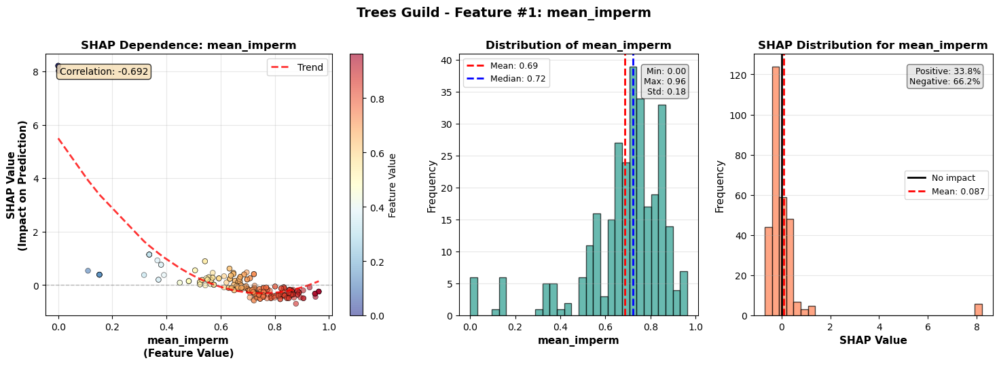


────────────────────────────────────────────────────────────────────────────────
Feature #1: mean_imperm
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 0.00 to 0.96
  Mean Feature Value: 0.69
  SHAP Range: -0.696 to 8.207
  Mean SHAP Impact: 0.087
  Correlation (Feature ↔ SHAP): -0.692
  → Higher mean_imperm generally DECREASES trees richness
  → This feature has MIXED impacts (positive in 33.8% of cases)



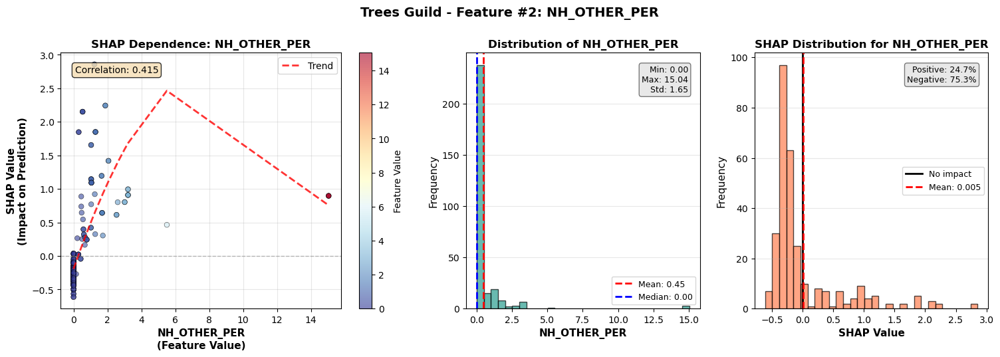


────────────────────────────────────────────────────────────────────────────────
Feature #2: NH_OTHER_PER
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 0.00 to 15.04
  Mean Feature Value: 0.45
  SHAP Range: -0.612 to 2.857
  Mean SHAP Impact: 0.005
  Correlation (Feature ↔ SHAP): 0.415
  → Higher NH_OTHER_PER generally INCREASES trees richness
  → This feature mostly has NEGATIVE impacts (75.3% of cases)



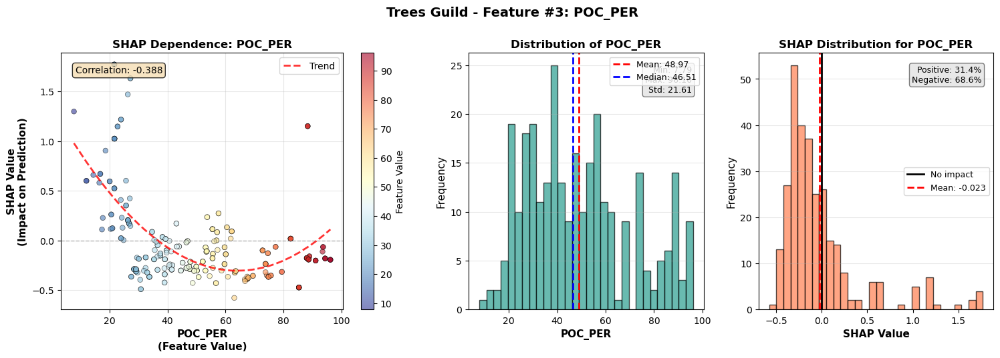


────────────────────────────────────────────────────────────────────────────────
Feature #3: POC_PER
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 7.79 to 96.10
  Mean Feature Value: 48.97
  SHAP Range: -0.579 to 1.771
  Mean SHAP Impact: -0.023
  Correlation (Feature ↔ SHAP): -0.388
  → Higher POC_PER generally DECREASES trees richness
  → This feature has MIXED impacts (positive in 31.4% of cases)



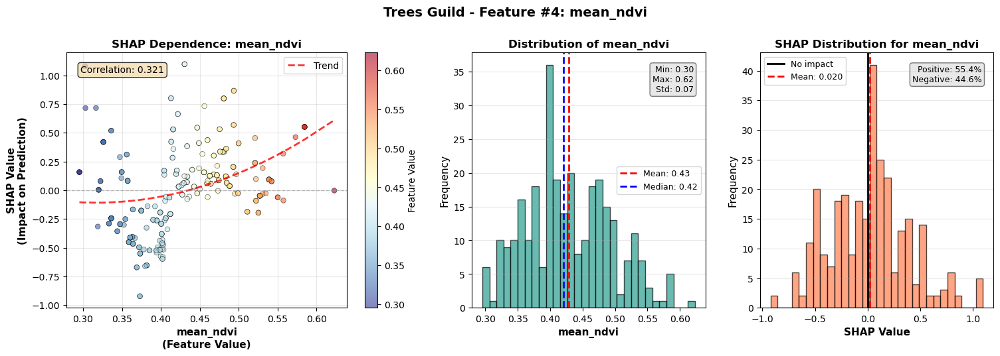


────────────────────────────────────────────────────────────────────────────────
Feature #4: mean_ndvi
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 0.30 to 0.62
  Mean Feature Value: 0.43
  SHAP Range: -0.923 to 1.096
  Mean SHAP Impact: 0.020
  Correlation (Feature ↔ SHAP): 0.321
  → Higher mean_ndvi generally INCREASES trees richness
  → This feature has MIXED impacts (positive in 55.4% of cases)



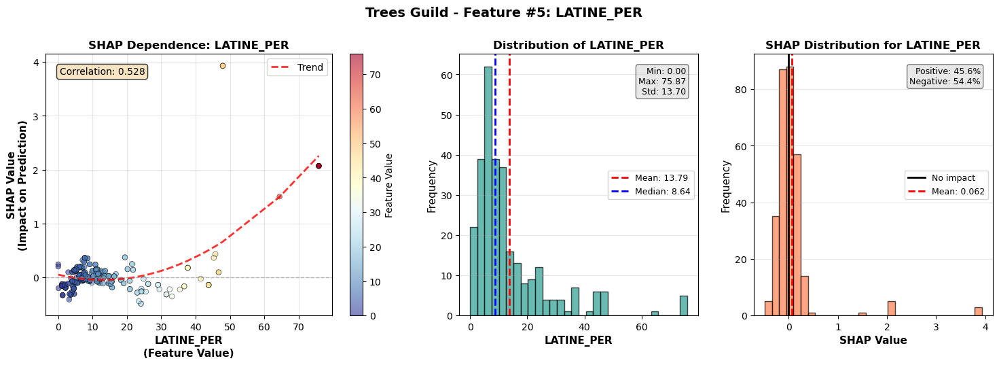


────────────────────────────────────────────────────────────────────────────────
Feature #5: LATINE_PER
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 0.00 to 75.87
  Mean Feature Value: 13.79
  SHAP Range: -0.490 to 3.928
  Mean SHAP Impact: 0.062
  Correlation (Feature ↔ SHAP): 0.528
  → Higher LATINE_PER generally INCREASES trees richness
  → This feature has MIXED impacts (positive in 45.6% of cases)



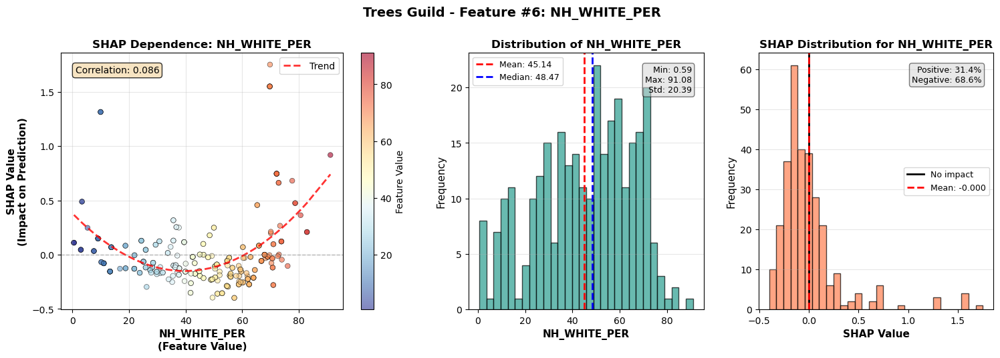


────────────────────────────────────────────────────────────────────────────────
Feature #6: NH_WHITE_PER
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 0.59 to 91.08
  Mean Feature Value: 45.14
  SHAP Range: -0.398 to 1.752
  Mean SHAP Impact: -0.000
  Correlation (Feature ↔ SHAP): 0.086
  → NH_WHITE_PER has COMPLEX/NON-LINEAR relationship with trees richness
  → This feature has MIXED impacts (positive in 31.4% of cases)



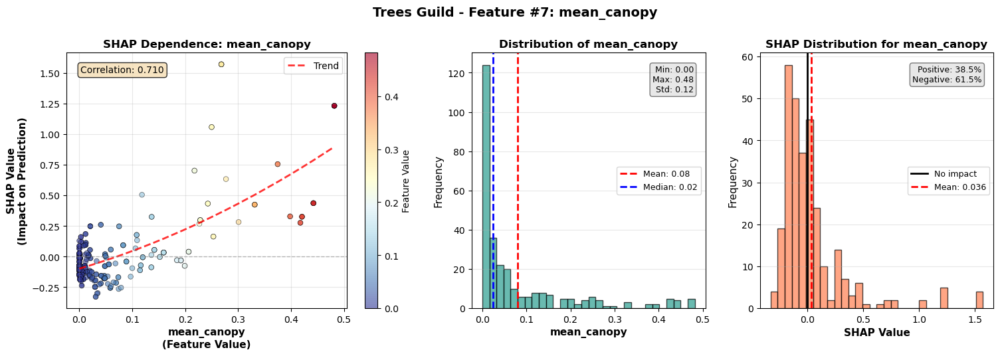


────────────────────────────────────────────────────────────────────────────────
Feature #7: mean_canopy
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 0.00 to 0.48
  Mean Feature Value: 0.08
  SHAP Range: -0.328 to 1.573
  Mean SHAP Impact: 0.036
  Correlation (Feature ↔ SHAP): 0.710
  → Higher mean_canopy generally INCREASES trees richness
  → This feature has MIXED impacts (positive in 38.5% of cases)



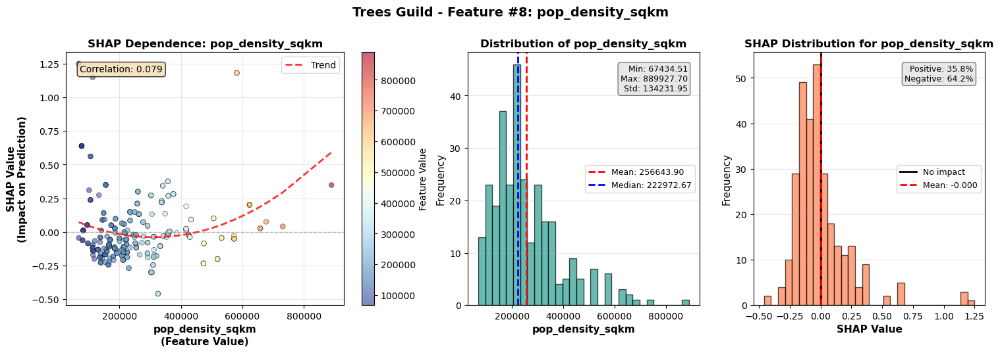


────────────────────────────────────────────────────────────────────────────────
Feature #8: pop_density_sqkm
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 67434.51 to 889927.70
  Mean Feature Value: 256643.90
  SHAP Range: -0.460 to 1.250
  Mean SHAP Impact: -0.000
  Correlation (Feature ↔ SHAP): 0.079
  → pop_density_sqkm has COMPLEX/NON-LINEAR relationship with trees richness
  → This feature has MIXED impacts (positive in 35.8% of cases)



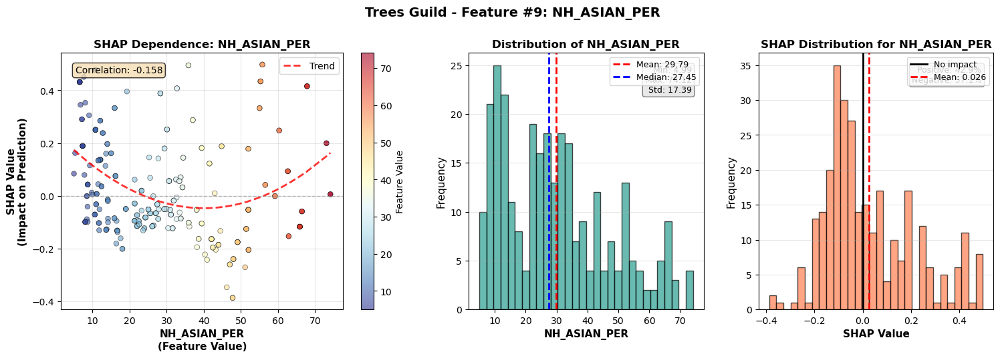


────────────────────────────────────────────────────────────────────────────────
Feature #9: NH_ASIAN_PER
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 4.99 to 74.12
  Mean Feature Value: 29.79
  SHAP Range: -0.387 to 0.497
  Mean SHAP Impact: 0.026
  Correlation (Feature ↔ SHAP): -0.158
  → NH_ASIAN_PER has COMPLEX/NON-LINEAR relationship with trees richness
  → This feature has MIXED impacts (positive in 42.9% of cases)



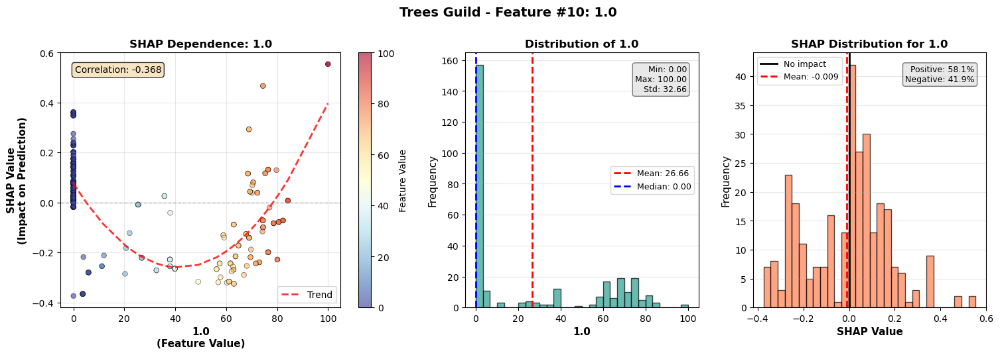


────────────────────────────────────────────────────────────────────────────────
Feature #10: 1.0
────────────────────────────────────────────────────────────────────────────────
  Feature Range: 0.00 to 100.00
  Mean Feature Value: 26.66
  SHAP Range: -0.374 to 0.554
  Mean SHAP Impact: -0.009
  Correlation (Feature ↔ SHAP): -0.368
  → Higher 1.0 generally DECREASES trees richness
  → This feature has MIXED impacts (positive in 58.1% of cases)



In [ ]:
plot_shap_dependence_comprehensive(guild_results, guild_name='trees', 
                                       top_n_features=10, save_path=None)


In [ ]:
def plot_biodiversity_variable_relationships(df, guild_name='trees', save_path=None):
    """
    Plot relationships between guild richness and all predictor variables
    Shows scatterplots with trend lines for each variable
    """
    # Set target column based on guild
    target_col = f'{guild_name}_estimator'
    
    if target_col not in df.columns:
        print(f"Error: {target_col} not found in data")
        return
    
    # Get valid data (non-NaN target)
    valid_data = df[~df[target_col].isna()].copy()
    
    # Define predictor variables (exclude guild columns and metadata)
    exclude_cols = ['human_estimator', 'shrubgrass_estimator', 'trees_estimator', 
                    'water_estimator', 'native_estimator', 'nonnative_estimator',
                    'Estimator_log_alt', 'Estimator_log', 'hex_id', 'Assemblage', 
                    'Diversity', 'Estimator', 'grade_x']
    
    predictor_cols = [col for col in valid_data.columns if col not in exclude_cols]
    
    # Remove non-numeric columns
    predictor_cols = [col for col in predictor_cols 
                     if valid_data[col].dtype in ['float64', 'int64']]
    
    n_predictors = len(predictor_cols)
    n_cols = 4
    n_rows = int(np.ceil(n_predictors / n_cols))
    
    print(f"\n{'='*80}")
    print(f"BIODIVERSITY-VARIABLE RELATIONSHIPS - {guild_name.upper()} GUILD")
    print(f"{'='*80}")
    print(f"Analyzing {n_predictors} predictor variables")
    print(f"Sample size: {len(valid_data)} locations\n")
    
    # Guild colors
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    color = guild_colors.get(guild_name, '#1f77b4')
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
    axes = axes.flatten()
    
    # Store correlation results
    correlations = []
    
    for idx, predictor in enumerate(predictor_cols):
        ax = axes[idx]
        
        # Get clean data for this relationship
        plot_data = valid_data[[predictor, target_col]].dropna()
        
        if len(plot_data) < 10:  # Skip if too few data points
            ax.text(0.5, 0.5, f'Insufficient data\n({len(plot_data)} points)', 
                   ha='center', va='center', transform=ax.transAxes)
            ax.set_title(predictor, fontsize=10, fontweight='bold')
            continue
        
        x = plot_data[predictor].values
        y = plot_data[target_col].values
        
        # Scatter plot
        ax.scatter(x, y, alpha=0.5, s=30, color=color, edgecolors='black', linewidth=0.5)
        
        # Add trend line
        z = np.polyfit(x, y, 2)  # Quadratic fit
        p = np.poly1d(z)
        x_sorted = np.sort(x)
        ax.plot(x_sorted, p(x_sorted), 'r-', linewidth=2, alpha=0.8, label='Trend')
        
        # Calculate correlation
        correlation = np.corrcoef(x, y)[0, 1]
        correlations.append({
            'variable': predictor,
            'correlation': correlation,
            'n_samples': len(plot_data)
        })
        
        # Calculate R²
        from sklearn.metrics import r2_score
        r2 = r2_score(y, p(x))
        
        # Formatting
        ax.set_xlabel(predictor, fontsize=9)
        ax.set_ylabel(f'{guild_name} richness', fontsize=9)
        ax.set_title(predictor, fontsize=10, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        # Add statistics box
        stats_text = f'r = {correlation:.3f}\nR² = {r2:.3f}\nn = {len(plot_data)}'
        ax.text(0.05, 0.95, stats_text, transform=ax.transAxes,
               fontsize=8, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Hide unused subplots
    for idx in range(n_predictors, len(axes)):
        axes[idx].axis('off')
    
    fig.suptitle(f'{guild_name.title()} Guild Richness vs Environmental Variables', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved relationship plots: {save_path}\n")
    
    # Print correlation summary
    corr_df = pd.DataFrame(correlations).sort_values('correlation', key=abs, ascending=False)
    
    print("\nCORRELATION SUMMARY (sorted by absolute correlation):")
    print("─"*60)
    print(f"{'Variable':<30} {'Correlation':<15} {'Samples':<10}")
    print("─"*60)
    for _, row in corr_df.head(15).iterrows():
        direction = "↑ Positive" if row['correlation'] > 0 else "↓ Negative"
        print(f"{row['variable']:<30} {row['correlation']:>+8.3f} ({direction})  {row['n_samples']:<10.0f}")
    
    return corr_df


def plot_biodiversity_relationships_grouped(df, guild_name='trees', save_path=None):
    """
    Plot relationships grouped by variable category
    Biophysical, Urban Infrastructure, Socioeconomic, Land Use
    """
    target_col = f'{guild_name}_estimator'
    
    if target_col not in df.columns:
        print(f"Error: {target_col} not found in data")
        return
    
    valid_data = df[~df[target_col].isna()].copy()
    
    # Define variable categories
    variable_categories = {
        'Biophysical': {
            'variables': ['mean_canopy', 'mean_ndvi', 'FHD', 'mean_elevation', 'std_elevation'],
            'color': '#2A9D8F'
        },
        'Urban Infrastructure': {
            'variables': ['mean_imperm', 'mean_highway', 'mean_road', 'mean_light'],
            'color': '#E76F51'
        },
        'Socioeconomic': {
            'variables': ['POC_PER', 'NH_WHITE_PER', 'NH_BLACK_PER', 'HISPANIC_PER', 
                         'MED_INCOME', 'pop_density_sqkm'],
            'color': '#F4A261'
        },
        'Land Use/Zoning': {
            'variables': ['1.0', '2.0', '3.0', '4.0', '5.0'],
            'color': '#E9C46A'
        }
    }
    
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    guild_color = guild_colors.get(guild_name, '#1f77b4')
    
    for category_name, category_info in variable_categories.items():
        variables = category_info['variables']
        cat_color = category_info['color']
        
        # Filter variables that exist in data
        available_vars = [v for v in variables if v in valid_data.columns]
        
        if not available_vars:
            continue
        
        n_vars = len(available_vars)
        n_cols = min(3, n_vars)
        n_rows = int(np.ceil(n_vars / n_cols))
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
        if n_vars == 1:
            axes = np.array([axes])
        axes = axes.flatten()
        
        print(f"\n{'─'*60}")
        print(f"{category_name.upper()}")
        print(f"{'─'*60}")
        
        for idx, var in enumerate(available_vars):
            ax = axes[idx]
            
            # Get clean data
            plot_data = valid_data[[var, target_col]].dropna()
            
            if len(plot_data) < 10:
                ax.text(0.5, 0.5, f'Insufficient data', 
                       ha='center', va='center', transform=ax.transAxes)
                ax.set_title(var, fontsize=11, fontweight='bold')
                continue
            
            x = plot_data[var].values
            y = plot_data[target_col].values
            
            # Scatter plot
            ax.scatter(x, y, alpha=0.6, s=40, color=guild_color, 
                      edgecolors='black', linewidth=0.5)
            
            # Fit different trend lines
            # Linear
            z_lin = np.polyfit(x, y, 1)
            p_lin = np.poly1d(z_lin)
            
            # Quadratic
            z_quad = np.polyfit(x, y, 2)
            p_quad = np.poly1d(z_quad)
            
            x_sorted = np.sort(x)
            ax.plot(x_sorted, p_lin(x_sorted), '--', linewidth=2, 
                   alpha=0.6, color='blue', label='Linear')
            ax.plot(x_sorted, p_quad(x_sorted), '-', linewidth=2.5, 
                   alpha=0.8, color='red', label='Quadratic')
            
            # Statistics
            correlation = np.corrcoef(x, y)[0, 1]
            from sklearn.metrics import r2_score
            r2_quad = r2_score(y, p_quad(x))
            
            # Format
            ax.set_xlabel(var, fontsize=11, fontweight='bold')
            ax.set_ylabel(f'{guild_name} richness', fontsize=11)
            ax.set_title(var, fontsize=12, fontweight='bold', color=cat_color)
            ax.grid(True, alpha=0.3)
            ax.legend(fontsize=9)
            
            # Stats box
            stats_text = f'r = {correlation:.3f}\nR² = {r2_quad:.3f}\nn = {len(plot_data)}'
            ax.text(0.05, 0.95, stats_text, transform=ax.transAxes,
                   fontsize=9, verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
            
            # Print to console
            print(f"  {var:<25} r = {correlation:>+.3f}  R² = {r2_quad:.3f}  n = {len(plot_data)}")
        
        # Hide unused subplots
        for idx in range(n_vars, len(axes)):
            axes[idx].axis('off')
        
        fig.suptitle(f'{guild_name.title()} Guild: {category_name}', 
                    fontsize=14, fontweight='bold')
        plt.tight_layout()
        
        if save_path:
            cat_save_path = save_path.replace('.png', f'_{category_name.replace("/", "_")}.png')
            plt.savefig(cat_save_path, dpi=300, bbox_inches='tight')
            print(f"\n✓ Saved: {cat_save_path}")
        
        plt.show()





BIODIVERSITY-VARIABLE RELATIONSHIPS - TREES GUILD
Analyzing 16 predictor variables
Sample size: 1476 locations



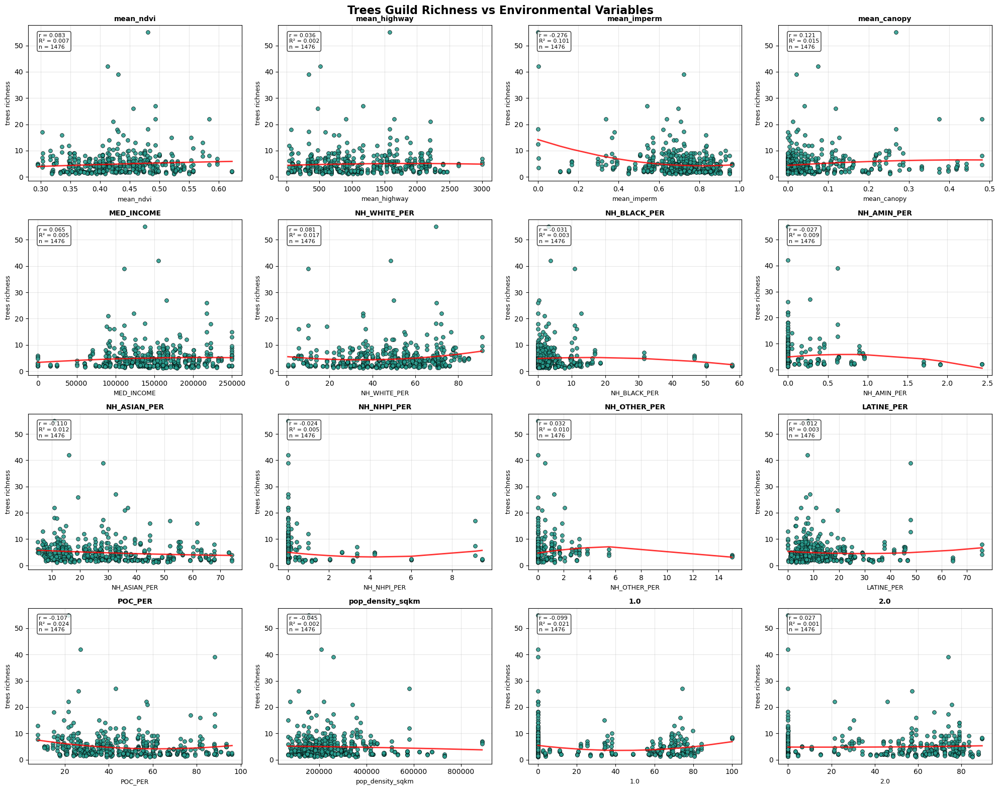

✓ Saved relationship plots: None


CORRELATION SUMMARY (sorted by absolute correlation):
────────────────────────────────────────────────────────────
Variable                       Correlation     Samples   
────────────────────────────────────────────────────────────
mean_imperm                      -0.276 (↓ Negative)  1476      
mean_canopy                      +0.121 (↑ Positive)  1476      
NH_ASIAN_PER                     -0.110 (↓ Negative)  1476      
POC_PER                          -0.107 (↓ Negative)  1476      
1.0                              -0.099 (↓ Negative)  1476      
mean_ndvi                        +0.083 (↑ Positive)  1476      
NH_WHITE_PER                     +0.081 (↑ Positive)  1476      
MED_INCOME                       +0.065 (↑ Positive)  1476      
pop_density_sqkm                 -0.045 (↓ Negative)  1476      
mean_highway                     +0.036 (↑ Positive)  1476      
NH_OTHER_PER                     +0.032 (↑ Positive)  1476      
NH_BLACK_PER    

,variable,correlation,n_samples
2,mean_imperm,-0.276132,1476
3,mean_canopy,0.120790,1476
8,NH_ASIAN_PER,-0.109915,1476
12,POC_PER,-0.107406,1476
14,1.0,-0.099191,1476
0,mean_ndvi,0.082811,1476
5,NH_WHITE_PER,0.081379,1476
4,MED_INCOME,0.064741,1476
13,pop_density_sqkm,-0.044586,1476
1,mean_highway,0.035941,1476


In [ ]:
plot_biodiversity_variable_relationships(combined_df, guild_name='trees', save_path=None)


In [67]:

def test_rf_models_by_diversity_and_guild(df, 
                                         guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
                                         diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
                                         save_path='../results_images'):
    """
    Train and test Random Forest models for each combination of guild and diversity metric
    """
    import os
    
    # Create save directory if it doesn't exist
    if save_path and not os.path.exists(save_path):
        os.makedirs(save_path)
    
    all_results = {}
    comparison_metrics = []
    
    print("\n" + "="*100)
    print("RANDOM FOREST MODEL TESTING - ALL GUILDS × ALL DIVERSITY METRICS")
    print("="*100)
    
    for diversity in diversity_types:
        print(f"\n{'#'*100}")
        print(f"DIVERSITY METRIC: {diversity.upper()}")
        print(f"{'#'*100}")
        
        # Filter data for this diversity type
        diversity_data = df[df['Diversity'] == diversity].copy()
        
        if len(diversity_data) == 0:
            print(f"⚠ No data for {diversity}")
            continue
        
        print(f"Total samples for {diversity}: {len(diversity_data)}")
        
        for guild in guilds:
            target_col = f'{guild}_estimator'
            
            if target_col not in diversity_data.columns:
                print(f"\n⚠ Skipping {guild}: target column not found")
                continue
            
            print(f"\n{'='*100}")
            print(f"TESTING: {guild.upper()} GUILD | {diversity.upper()}")
            print(f"{'='*100}")
            
            # Prepare data for this guild
            guild_data = diversity_data[~diversity_data[target_col].isna()].copy()
            
            if len(guild_data) < 50:
                print(f"⚠ Insufficient data for {guild} with {diversity} ({len(guild_data)} samples)")
                continue
            
            print(f"Sample size: {len(guild_data)}")
            print(f"Target range: [{guild_data[target_col].min():.2f}, {guild_data[target_col].max():.2f}]")
            print(f"Target mean: {guild_data[target_col].mean():.2f} ± {guild_data[target_col].std():.2f}")
            
            # Train model
            try:
                results = train_rf_model(guild_data, target_col, cv_folds=5)
                
                # Store results with unique key
                key = f"{guild}_{diversity.replace(' ', '_')}"
                all_results[key] = results
                
                # Store metrics for comparison
                comparison_metrics.append({
                    'Guild': guild,
                    'Diversity': diversity,
                    'N_samples': len(guild_data),
                    'Train_R2': results['train_r2'],
                    'CV_R2': results['cv_r2'],
                    'Test_R2': results['test_r2'],
                    'OOB_Score': results['oob_score'],
                    'Test_RMSE': results['test_rmse'],
                    'Test_MAE': results['test_mae'],
                    'CV_RMSE_mean': results['cv_rmse_mean'],
                    'CV_RMSE_std': results['cv_rmse_std'],
                    'Overfit_Gap': results['train_r2'] - results['test_r2']
                })
                
                # Generate plots
                if save_path:
                    # Clean diversity name for filename
                    div_name = diversity.replace(' ', '_').lower()
                    perf_plot_path = os.path.join(save_path, f'rf_performance_{guild}_{div_name}.png')
                    feat_plot_path = os.path.join(save_path, f'rf_feature_importance_{guild}_{div_name}.png')
                    
                    plot_model_performance(results, save_path=perf_plot_path)
                    plot_feature_importance(results, top_n=15, save_path=feat_plot_path)
                
                print(f"\n✓ {guild.upper()} | {diversity} model completed successfully")
                
            except Exception as e:
                print(f"\n✗ Error training {guild} | {diversity} model: {str(e)}")
                import traceback
                traceback.print_exc()
                continue
    
    # Initialize comparison_df as None
    comparison_df = None
    
    # Create comparison summary
    if comparison_metrics:
        print("\n" + "="*100)
        print("PERFORMANCE COMPARISON ACROSS ALL GUILDS AND DIVERSITY METRICS")
        print("="*100)
        
        comparison_df = pd.DataFrame(comparison_metrics)
        
        # Print summary table
        print("\n" + comparison_df.to_string(index=False))
        
        # Save to CSV
        if save_path:
            csv_path = os.path.join(save_path, 'rf_model_comparison_diversity_guild.csv')
            comparison_df.to_csv(csv_path, index=False)
            print(f"\n✓ Comparison table saved to: {csv_path}")
        
        # Create comparison visualizations
        create_diversity_guild_comparison_plots(comparison_df, save_path)
        
        # Analyze by diversity type
        analyze_by_diversity_type(comparison_df)
        

        
    else:
        print("\n⚠ No models were successfully trained")
    
    return all_results, comparison_df


def create_diversity_guild_comparison_plots(comparison_df, save_path=None):
    """
    Create comprehensive comparison plots for diversity × guild combinations
    """
    import os
    
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    
    # Plot 1: R² by Guild, faceted by Diversity
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle('Model Performance (R²) by Guild and Diversity Metric', 
                 fontsize=16, fontweight='bold')
    
    diversity_types = comparison_df['Diversity'].unique()
    
    for idx, diversity in enumerate(diversity_types):
        ax = axes[idx]
        div_data = comparison_df[comparison_df['Diversity'] == diversity]
        
        x = np.arange(len(div_data))
        width = 0.25
        
        ax.bar(x - width, div_data['Train_R2'], width, label='Train', alpha=0.8, edgecolor='black')
        ax.bar(x, div_data['CV_R2'], width, label='CV', alpha=0.8, edgecolor='black')
        ax.bar(x + width, div_data['Test_R2'], width, label='Test', alpha=0.8, edgecolor='black')
        
        ax.set_ylabel('R² Score', fontweight='bold', fontsize=11)
        ax.set_title(diversity, fontweight='bold', fontsize=12)
        ax.set_xticks(x)
        ax.set_xticklabels(div_data['Guild'], rotation=45, ha='right')
        ax.legend()
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_ylim([0, 1])
    
    plt.tight_layout()
    
    if save_path:
        plot_path = os.path.join(save_path, 'rf_r2_by_diversity.png')
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {plot_path}")
    
    plt.show()
    
    # Plot 2: Heatmap of Test R²
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Pivot data for heatmap
    pivot_r2 = comparison_df.pivot(index='Guild', columns='Diversity', values='Test_R2')
    
    sns.heatmap(pivot_r2, annot=True, fmt='.3f', cmap='RdYlGn', 
               cbar_kws={'label': 'Test R²'}, ax=ax,
               vmin=0, vmax=1, linewidths=0.5)
    
    ax.set_title('Test R² Heatmap: Guild × Diversity Metric', 
                fontweight='bold', fontsize=14)
    ax.set_xlabel('Diversity Metric', fontweight='bold', fontsize=12)
    ax.set_ylabel('Guild', fontweight='bold', fontsize=12)
    
    plt.tight_layout()
    
    if save_path:
        plot_path = os.path.join(save_path, 'rf_r2_heatmap.png')
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {plot_path}")
    
    plt.show()
    
    # Plot 3: RMSE Comparison
    fig, ax = plt.subplots(figsize=(14, 6))
    
    guilds = comparison_df['Guild'].unique()
    x = np.arange(len(guilds))
    width = 0.25
    
    for idx, diversity in enumerate(diversity_types):
        div_data = comparison_df[comparison_df['Diversity'] == diversity]
        # Ensure same order as guilds
        div_data = div_data.set_index('Guild').reindex(guilds).reset_index()
        
        offset = (idx - 1) * width
        ax.bar(x + offset, div_data['Test_RMSE'], width, 
              label=diversity, alpha=0.7, edgecolor='black')
    
    ax.set_ylabel('Test RMSE', fontweight='bold', fontsize=12)
    ax.set_xlabel('Guild', fontweight='bold', fontsize=12)
    ax.set_title('Test RMSE by Guild and Diversity Metric', 
                fontweight='bold', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(guilds, rotation=45, ha='right')
    ax.legend(title='Diversity Metric')
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    
    if save_path:
        plot_path = os.path.join(save_path, 'rf_rmse_comparison.png')
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {plot_path}")
    
    plt.show()
    
    # Plot 4: Overfitting Gap Comparison
    fig, ax = plt.subplots(figsize=(14, 6))
    
    for idx, diversity in enumerate(diversity_types):
        div_data = comparison_df[comparison_df['Diversity'] == diversity]
        div_data = div_data.set_index('Guild').reindex(guilds).reset_index()
        
        offset = (idx - 1) * width
        ax.bar(x + offset, div_data['Overfit_Gap'], width, 
              label=diversity, alpha=0.7, edgecolor='black')
    
    ax.axhline(0.1, color='orange', linestyle='--', linewidth=1, alpha=0.5, label='Moderate threshold')
    ax.axhline(0.2, color='red', linestyle='--', linewidth=1, alpha=0.5, label='High threshold')
    
    ax.set_ylabel('Overfitting Gap (Train R² - Test R²)', fontweight='bold', fontsize=12)
    ax.set_xlabel('Guild', fontweight='bold', fontsize=12)
    ax.set_title('Overfitting Analysis by Guild and Diversity Metric', 
                fontweight='bold', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(guilds, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    
    if save_path:
        plot_path = os.path.join(save_path, 'rf_overfitting_comparison.png')
        plt.savefig(plot_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {plot_path}")
    
    plt.show()


def analyze_by_diversity_type(comparison_df):
    """
    Analyze and print summary statistics by diversity type
    """
    print("\n" + "="*100)
    print("ANALYSIS BY DIVERSITY TYPE")
    print("="*100)
    
    for diversity in comparison_df['Diversity'].unique():
        div_data = comparison_df[comparison_df['Diversity'] == diversity]
        
        print(f"\n{diversity.upper()}")
        print("-" * 100)
        print(f"  Number of guilds tested: {len(div_data)}")
        print(f"  Average Test R²: {div_data['Test_R2'].mean():.3f} (±{div_data['Test_R2'].std():.3f})")
        print(f"  Average CV R²: {div_data['CV_R2'].mean():.3f} (±{div_data['CV_R2'].std():.3f})")
        print(f"  Average Test RMSE: {div_data['Test_RMSE'].mean():.3f} (±{div_data['Test_RMSE'].std():.3f})")
        print(f"  Average Overfitting Gap: {div_data['Overfit_Gap'].mean():.3f} (±{div_data['Overfit_Gap'].std():.3f})")
        
        print(f"\n  Best performing guild (by Test R²):")
        best = div_data.loc[div_data['Test_R2'].idxmax()]
        print(f"    {best['Guild']}: R² = {best['Test_R2']:.3f}, RMSE = {best['Test_RMSE']:.3f}")
        
        print(f"\n  Worst performing guild (by Test R²):")
        worst = div_data.loc[div_data['Test_R2'].idxmin()]
        print(f"    {worst['Guild']}: R² = {worst['Test_R2']:.3f}, RMSE = {worst['Test_RMSE']:.3f}")



In [68]:
test_rf_models_by_diversity_and_guild(combined_df, 
                                         guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
                                         diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'])


RANDOM FOREST MODEL TESTING - ALL GUILDS × ALL DIVERSITY METRICS

####################################################################################################
DIVERSITY METRIC: SPECIES RICHNESS
####################################################################################################
Total samples for Species richness: 735

TESTING: HUMAN GUILD | SPECIES RICHNESS
Sample size: 300
Target range: [2.00, 10.00]
Target mean: 3.42 ± 1.77

✗ Error training human | Species richness model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: SHRUBGRASS GUILD | SPECIES RICHNESS
Sample size: 363
Target range: [2.00, 28.00]
Target mean: 4.74 ± 4.14

✗ Error training shrubgrass | Species richness model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: TREES GUILD | SPECIES RICHNESS
Sample size: 483
Target range: [2.00, 55.00]
Target mean: 6.49 ± 7.25

✗ Error training trees | Spe

Traceback (most recent call last):
  File "/tmp/ipykernel_212959/362700419.py", line 59, in test_rf_models_by_diversity_and_guild
    results = train_rf_model(guild_data, target_col, cv_folds=5)
  File "/tmp/ipykernel_212959/3574673106.py", line 35, in train_rf_model
    imp.fit_transform(X)
    ~~~~~~~~~~~~~~~~~^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/_set_output.py", line 319, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 969, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/impute/_base.py", line 448, in fit
    X = self._validate_inp


✗ Error training shrubgrass | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: TREES GUILD | SIMPSON DIVERSITY
Sample size: 483
Target range: [1.14, 12.71]
Target mean: 3.84 ± 2.22

✗ Error training trees | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: WATER GUILD | SIMPSON DIVERSITY
Sample size: 63
Target range: [1.21, 5.08]
Target mean: 2.40 ± 0.99

✗ Error training water | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '2071_C'

TESTING: NATIVE GUILD | SIMPSON DIVERSITY
Sample size: 681
Target range: [1.03, 24.15]
Target mean: 4.91 ± 3.75

✗ Error training native | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: NONNATIVE GUILD | SIMPSON DIVERSITY
Sample size: 195
Target range: [1.11, 5.4

Traceback (most recent call last):
  File "/tmp/ipykernel_212959/362700419.py", line 59, in test_rf_models_by_diversity_and_guild
    results = train_rf_model(guild_data, target_col, cv_folds=5)
  File "/tmp/ipykernel_212959/3574673106.py", line 35, in train_rf_model
    imp.fit_transform(X)
    ~~~~~~~~~~~~~~~~~^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/_set_output.py", line 319, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 969, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/impute/_base.py", line 448, in fit
    X = self._validate_inp

({}, None)

In [32]:
# Example usage after running test_rf_models_by_diversity_and_guild:

# First, run the comprehensive testing takes about 6 minutes
all_results, comparison_df = test_rf_models_by_diversity_and_guild(
    combined_df, 
    guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
    diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
    save_path='../results_images'
)


RANDOM FOREST MODEL TESTING - ALL GUILDS × ALL DIVERSITY METRICS

####################################################################################################
DIVERSITY METRIC: SPECIES RICHNESS
####################################################################################################
Total samples for Species richness: 735

TESTING: HUMAN GUILD | SPECIES RICHNESS
Sample size: 300
Target range: [2.00, 10.00]
Target mean: 3.42 ± 1.77

✗ Error training human | Species richness model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: SHRUBGRASS GUILD | SPECIES RICHNESS
Sample size: 363
Target range: [2.00, 28.00]
Target mean: 4.74 ± 4.14

✗ Error training shrubgrass | Species richness model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: TREES GUILD | SPECIES RICHNESS
Sample size: 483
Target range: [2.00, 55.00]
Target mean: 6.49 ± 7.25

✗ Error training trees | Spe

Traceback (most recent call last):
  File "/tmp/ipykernel_212959/362700419.py", line 59, in test_rf_models_by_diversity_and_guild
    results = train_rf_model(guild_data, target_col, cv_folds=5)
  File "/tmp/ipykernel_212959/3574673106.py", line 35, in train_rf_model
    imp.fit_transform(X)
    ~~~~~~~~~~~~~~~~~^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/_set_output.py", line 319, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 969, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/impute/_base.py", line 448, in fit
    X = self._validate_inp


TESTING: WATER GUILD | SIMPSON DIVERSITY
Sample size: 63
Target range: [1.21, 5.08]
Target mean: 2.40 ± 0.99

✗ Error training water | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '2071_C'

TESTING: NATIVE GUILD | SIMPSON DIVERSITY
Sample size: 681
Target range: [1.03, 24.15]
Target mean: 4.91 ± 3.75

✗ Error training native | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: NONNATIVE GUILD | SIMPSON DIVERSITY
Sample size: 195
Target range: [1.11, 5.41]
Target mean: 2.09 ± 0.86

✗ Error training nonnative | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

⚠ No models were successfully trained


Traceback (most recent call last):
  File "/tmp/ipykernel_212959/362700419.py", line 59, in test_rf_models_by_diversity_and_guild
    results = train_rf_model(guild_data, target_col, cv_folds=5)
  File "/tmp/ipykernel_212959/3574673106.py", line 35, in train_rf_model
    imp.fit_transform(X)
    ~~~~~~~~~~~~~~~~~^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/_set_output.py", line 319, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 969, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/impute/_base.py", line 448, in fit
    X = self._validate_inp

## Habitat SHAP radial

In [9]:

def plot_guild_feature_radar_shap_with_stats(all_results, comparison_df, guild_name='trees', 
                                             diversity_type='Species richness', save_path=None):
    """
    Radar plot using ACTUAL mean absolute SHAP values (not percentages)
    with bins for weak/moderate/strong importance
    Top 3 variables highlighted in blue with scores in labels
    """
    from math import pi
    
    # Create unique key for this combination
    key = f"{guild_name}_{diversity_type.replace(' ', '_')}"
    
    if key not in all_results:
        print(f"No results found for {guild_name} with {diversity_type}")
        return
    
    result = all_results[key]
    
    # Check if SHAP values exist
    if 'shap_values' not in result or result.get('shap_values') is None:
        print(f"No SHAP values found for {guild_name} with {diversity_type}")
        return
    
    shap_values = result['shap_values']
    X_test = result['X_test']
    
    # Calculate ABSOLUTE mean SHAP values (actual values, not normalized)
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    
    # Create feature importance dataframe
    shap_importance = pd.DataFrame({
        'feature': X_test.columns,
        'importance': mean_abs_shap
    })
    
    # Print top features to see what's available
    print(f"\nTop 15 features by SHAP importance:")
    print(shap_importance.sort_values('importance', ascending=False).head(15))
    
    # Define feature categories
    feature_categories = {
        'Vegetation\nComplexity': ['mean_canopy'],
        'NDVI': ['mean_ndvi'],
        'Distance to\nHighway': ['mean_highway'],
        'Impervious\nSurface %': ['mean_imperm'],
        'Median\nIncome': ['MED_INCOME'],
        'POC %': ['POC_PER'],
        'White %': ['NH_WHITE_PER'],
        'Black %': ['NH_BLACK_PER'],
        'Pop.\nDensity': ['pop_density_sqkm'],
        'Single Family\nZoning': ['1.0'],
        'Multi Family\nZoning': ['2.0'],
        'HOLC\nGrades': ['grade_x']
    }
    
    # Calculate category scores from SHAP importance (ACTUAL VALUES)
    category_scores = []
    category_labels = []
    
    print(f"\n{guild_name.upper()} - {diversity_type}")
    print("="*60)
    
    for category, features in feature_categories.items():
        importances = []
        for feature in features:
            if feature in shap_importance['feature'].values:
                importance = shap_importance[shap_importance['feature'] == feature]['importance'].values[0]
                importances.append(importance)
                print(f"  ✓ Found {feature} in category {category}: {importance:.4f}")
            else:
                print(f"  ✗ Missing {feature} for category {category}")
        
        if importances:
            mean_importance = np.mean(importances)
            category_scores.append(mean_importance)
            category_labels.append(category)
            print(f"  {category.replace(chr(10), ' '):<30}: {mean_importance:.4f}")
    
    if len(category_scores) == 0:
        print(f"No valid data for {guild_name}")
        return
    
    # Get model statistics
    stats_row = comparison_df[
        (comparison_df['Guild'] == guild_name) & 
        (comparison_df['Diversity'] == diversity_type)
    ]
    
    if len(stats_row) == 0:
        print(f"No statistics found for {guild_name} with {diversity_type}")
        return
    
    stats = stats_row.iloc[0]
    
    # Define bins based on SHAP value ranges
    max_shap = max(category_scores)
    
    # Define bins: Weak, Moderate, Strong
    weak_threshold = max_shap * 0.33
    moderate_threshold = max_shap * 0.67
    
    print(f"\nSHAP Value Bins:")
    print(f"  Weak:     0.000 - {weak_threshold:.4f}")
    print(f"  Moderate: {weak_threshold:.4f} - {moderate_threshold:.4f}")
    print(f"  Strong:   {moderate_threshold:.4f} - {max_shap:.4f}")
    
    # Identify top 3 categories
    top_3_indices = sorted(range(len(category_scores)), key=lambda i: category_scores[i], reverse=True)[:3]
    print(f"\nTop 3 categories:")
    for idx in top_3_indices:
        print(f"  {category_labels[idx].replace(chr(10), ' ')}: {category_scores[idx]:.4f}")
    
    # Number of variables
    N = len(category_labels)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    
    # Use ACTUAL SHAP values (not normalized)
    category_scores_plot = category_scores + [category_scores[0]]
    angles_plot = angles + [angles[0]]
    
    # Guild colors
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    
    color = guild_colors.get(guild_name, '#999999')
    
    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    
    # Plot main line with regular markers
    ax.plot(angles_plot, category_scores_plot, 'o-', linewidth=3.5, color=color, markersize=10)
    ax.fill(angles_plot, category_scores_plot, alpha=0.25, color=color)
    
    # Highlight top 3 points with larger blue dots (same color but larger size)
    for idx in top_3_indices:
        ax.plot(angles[idx], category_scores[idx], 'o', 
               markersize=15, color=color, zorder=5, 
               markeredgecolor=color, markeredgewidth=1)
    
    ax.set_xticks(angles)
    
    # Create labels with scores for all variables, highlight top 3 
    
    ax.set_xticklabels(category_labels, fontsize=10, fontweight='bold')
    
    # Create labels - add scores ONLY for top 3 variables
    highlighted_labels = []
    for i, label in enumerate(category_labels):
        if i in top_3_indices:
            # Add score to top 3 labels
            label_with_score = f"{label}\n({category_scores[i]:.4f})"
            highlighted_labels.append(label_with_score)
        else:
            # No score for other labels
            highlighted_labels.append(label)

    for i, label in enumerate(ax.get_xticklabels()):
        if i in top_3_indices:
            label.set_color(color)
    
    ax.set_xticklabels(highlighted_labels, fontsize=10, fontweight='bold')
    
    # Set radial limits based on max SHAP value
    ax.set_ylim(0, max_shap * 1.1)  # Add 10% padding
    
    # Set bins for weak/moderate/strong with SHAP values in parentheses
    ax.set_yticks([weak_threshold, moderate_threshold, max_shap])
    ax.set_yticklabels([
        f'Weak\n({weak_threshold:.3f})', 
        f'Moderate\n({moderate_threshold:.3f})', 
        f'Strong\n({max_shap:.3f})'
    ], fontsize=10, fontweight='bold')
    
    ax.set_title(f'{guild_name.title()} Guild | {diversity_type}\nMean Absolute SHAP Values\n(Top 3 variables in blue)',
                fontsize=16, fontweight='bold', pad=30)
    
    ax.grid(True, alpha=0.3)
    
    # Add statistics text box
    stats_text = (
        f"Model Performance\n"
        f"{'─'*20}\n"
        f"Test R² = {stats['Test_R2']:.3f}\n"
        f"CV R² = {stats['CV_R2']:.3f}\n"
        f"Test RMSE = {stats['Test_RMSE']:.3f}\n"
        f"Test MAE = {stats['Test_MAE']:.3f}\n"
        f"OOB Score = {stats['OOB_Score']:.3f}\n"
        f"n = {stats['N_samples']:.0f}\n\n"
    )
    

    # Position text box
    ax.text(1.35, 0.5, stats_text, transform=ax.transAxes,
           fontsize=9, verticalalignment='center',
           bbox=dict(boxstyle='round', facecolor='white', edgecolor=color, 
                    linewidth=2, alpha=0.9),
           family='monospace')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {save_path}")
    
    plt.show()



# Test with one guild to see debug output
plot_guild_feature_radar_shap_with_stats(
    all_results, 
    comparison_df,
    guild_name='trees',
    diversity_type='Species richness',
    save_path='../results_images/test_radar.png'
)


NameError: name 'all_results' is not defined

In [ ]:
def plot_guild_feature_radar_shap_with_stats(all_results, comparison_df, guild_name='trees', 
                                             diversity_type='Species richness', save_path=None):
    """
    Radar plot using ACTUAL mean absolute SHAP values (not percentages)
    with bins for weak/moderate/strong importance
    Top 3 variables highlighted with scores in labels
    """
    from math import pi
    
    # Create unique key for this combination
    key = f"{guild_name}_{diversity_type.replace(' ', '_')}"
    
    if key not in all_results:
        print(f"No results found for {guild_name} with {diversity_type}")
        return
    
    result = all_results[key]
    
    # Check if SHAP values exist
    if 'shap_values' not in result or result.get('shap_values') is None:
        print(f"No SHAP values found for {guild_name} with {diversity_type}")
        return
    
    shap_values = result['shap_values']
    X_test = result['X_test']
    
    # Calculate ABSOLUTE mean SHAP values (actual values, not normalized)
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    
    # Create feature importance dataframe
    shap_importance = pd.DataFrame({
        'feature': X_test.columns,
        'importance': mean_abs_shap
    })
    
    # Print top features to see what's available
    print(f"\nTop 15 features by SHAP importance:")
    print(shap_importance.sort_values('importance', ascending=False).head(15))
    
    # Define feature categories
    feature_categories = {
        'Vegetation\nComplexity': ['mean_canopy'],
        'NDVI': ['mean_ndvi'],
        'Distance to\nHighway': ['mean_highway'],
        'Impervious\nSurface %': ['mean_imperm'],
        'Median\nIncome': ['MED_INCOME'],
        'POC %': ['POC_PER'],
        'White %': ['NH_WHITE_PER'],
        'Black %': ['NH_BLACK_PER'],
        'Pop.\nDensity': ['pop_density_sqkm'],
        'Single Family\nZoning': ['1.0'],
        'Multi Family\nZoning': ['2.0'],
        'HOLC\nGrades': ['grade_x']
    }
    
    # Calculate category scores from SHAP importance (ACTUAL VALUES)
    category_scores = []
    category_labels = []
    
    print(f"\n{guild_name.upper()} - {diversity_type}")
    print("="*60)
    
    for category, features in feature_categories.items():
        importances = []
        for feature in features:
            if feature in shap_importance['feature'].values:
                importance = shap_importance[shap_importance['feature'] == feature]['importance'].values[0]
                importances.append(importance)
                print(f"  ✓ Found {feature} in category {category}: {importance:.4f}")
            else:
                print(f"  ✗ Missing {feature} for category {category}")
        
        if importances:
            mean_importance = np.mean(importances)
            category_scores.append(mean_importance)
            category_labels.append(category)
            print(f"  {category.replace(chr(10), ' '):<30}: {mean_importance:.4f}")
    
    if len(category_scores) == 0:
        print(f"No valid data for {guild_name}")
        return
    
    # Get model statistics
    stats_row = comparison_df[
        (comparison_df['Guild'] == guild_name) & 
        (comparison_df['Diversity'] == diversity_type)
    ]
    
    if len(stats_row) == 0:
        print(f"No statistics found for {guild_name} with {diversity_type}")
        return
    
    stats = stats_row.iloc[0]
    
    # Define bins based on SHAP value ranges
    max_shap = max(category_scores)
    
    # Define bins: Weak, Moderate, Strong
    weak_threshold = max_shap * 0.33
    moderate_threshold = max_shap * 0.67
    
    print(f"\nSHAP Value Bins:")
    print(f"  Weak:     0.000 - {weak_threshold:.4f}")
    print(f"  Moderate: {weak_threshold:.4f} - {moderate_threshold:.4f}")
    print(f"  Strong:   {moderate_threshold:.4f} - {max_shap:.4f}")
    
    # Identify top 3 categories
    top_3_indices = sorted(range(len(category_scores)), key=lambda i: category_scores[i], reverse=True)[:3]
    print(f"\nTop 3 categories:")
    for idx in top_3_indices:
        print(f"  {category_labels[idx].replace(chr(10), ' ')}: {category_scores[idx]:.4f}")
    
    # Number of variables
    N = len(category_labels)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    
    # Use ACTUAL SHAP values (not normalized)
    category_scores_plot = category_scores + [category_scores[0]]
    angles_plot = angles + [angles[0]]
    
    # Guild colors
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    
    color = guild_colors.get(guild_name, '#999999')
    
    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    
    # Plot main line with regular markers
    ax.plot(angles_plot, category_scores_plot, 'o-', linewidth=3.5, color=color, markersize=10)
    ax.fill(angles_plot, category_scores_plot, alpha=0.25, color=color)
    
    
    ax.set_xticks(angles)
    
   # Create labels - add scores ONLY for top 3 variables
    """ highlighted_labels = []
    for i, label in enumerate(category_labels):
        if i in top_3_indices:
            # Add score to top 3 labels
            label_with_score = f"{label}\n({category_scores[i]:.4f})"
            highlighted_labels.append(label_with_score)
        else:
            # No score for other labels
            highlighted_labels.append(label) """

    ax.set_xticklabels(category_labels, fontsize=12, fontweight='bold')
    
    # Color top 3 labels
    for i, label in enumerate(ax.get_xticklabels()):
        if i in top_3_indices:
            label.set_color(color)
            label.set_fontweight('extra bold')
            label.set_fontsize(11)
    
    # Set radial limits based on max SHAP value
    ax.set_ylim(0, max_shap * 1.1)  # Add 10% padding
    
    # Set bins for weak/moderate/strong with SHAP values in parentheses
    ax.set_yticks([weak_threshold, moderate_threshold, max_shap])
    ax.set_yticklabels([
        f'Weak\n({weak_threshold:.3f})', 
        f'Moderate\n({moderate_threshold:.3f})', 
        f'Strong\n({max_shap:.3f})'
    ], fontsize=9, zorder=10, fontstyle='italic', alpha=0.5)
    
    ax.set_axisbelow(False) #labels on top 
    
    ax.set_title(f'{guild_name.title()} Guild | {diversity_type}\nMean Absolute SHAP Values',
                fontsize=16, fontweight='bold', pad=40)
    
    ax.grid(True, alpha=0.3, zorder=1)  # Grid behind everything
    
    # Add statistics text box
    stats_text = (
        f"Model Performance\n"
        f"{'─'*20}\n"
        f"Test R² = {stats['Test_R2']:.3f}\n"
        f"CV R² = {stats['CV_R2']:.3f}\n"
        f"Test RMSE = {stats['Test_RMSE']:.3f}\n"
        f"Test MAE = {stats['Test_MAE']:.3f}\n"
        f"OOB Score = {stats['OOB_Score']:.3f}\n"
        f"n = {stats['N_samples']:.0f}\n\n"
        
    )
    
    # Position text box in top right corner
    ax.text(1.15, 0.98, stats_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='top', horizontalalignment='left',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor=color, 
                    linewidth=2, alpha=0.9),
        family='monospace')
        
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {save_path}")
    
    plt.show()




def create_all_radar_plots_with_stats(all_results, comparison_df, 
                                      guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
                                      diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
                                      save_path='../results_images'):
    """
    Create radar plots for all guild × diversity combinations
    """
    import os
    
    if save_path and not os.path.exists(save_path):
        os.makedirs(save_path)
    
    print("\n" + "="*80)
    print("CREATING SHAP-BASED RADAR PLOTS WITH MODEL STATISTICS")
    print("="*80)
    
    for diversity in diversity_types:
        print(f"\n{'─'*80}")
        print(f"DIVERSITY: {diversity.upper()}")
        print(f"{'─'*80}")
        
        for guild in guilds:
            key = f"{guild}_{diversity.replace(' ', '_')}"
            
            if key in all_results:
                div_name = diversity.replace(' ', '_').lower()
                save_file = os.path.join(save_path, f'radar_shap_{guild}_{div_name}.png')
                
                plot_guild_feature_radar_shap_with_stats(
                    all_results, 
                    comparison_df,
                    guild_name=guild,
                    diversity_type=diversity,
                    save_path=save_file
                )
            else:
                print(f"  ⚠ No results for {guild} | {diversity}")




# Example usage after running test_rf_models_by_diversity_and_guild:



# Then create radar plots with statistics for all combinations
create_all_radar_plots_with_stats(
    guild_results, 
    comparison_df,
    guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
    diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],  
    save_path='../results_images'
)




CREATING SHAP-BASED RADAR PLOTS WITH MODEL STATISTICS

────────────────────────────────────────────────────────────────────────────────
DIVERSITY: SPECIES RICHNESS
────────────────────────────────────────────────────────────────────────────────
  ⚠ No results for human | Species richness
  ⚠ No results for shrubgrass | Species richness
  ⚠ No results for trees | Species richness
  ⚠ No results for water | Species richness
  ⚠ No results for native | Species richness
  ⚠ No results for nonnative | Species richness

────────────────────────────────────────────────────────────────────────────────
DIVERSITY: SHANNON DIVERSITY
────────────────────────────────────────────────────────────────────────────────
  ⚠ No results for human | Shannon diversity
  ⚠ No results for shrubgrass | Shannon diversity
  ⚠ No results for trees | Shannon diversity
  ⚠ No results for water | Shannon diversity
  ⚠ No results for native | Shannon diversity
  ⚠ No results for nonnative | Shannon diversity

───────

In [ ]:
def analyze_diversity_measure(df, measure_name, predictors, response_col='Estimator'):
    """Run complete analysis including RF model, importance plots, and PDPs"""
    # Run RF analysis
    result = run_rf_analysis(df, measure_name, predictors, response_col)
    
    if result is None:
        print(f"Analysis failed for {measure_name}")
        return None
    
    # Recreate X_data for PDPs
    predictor_cols = [col for col in predictors if col in df.columns]
    
    # Add poc column if necessary
    if all(col in df.columns for col in poc) and 'poc' not in df.columns:
        df['poc'] = df[poc].sum(axis=1)
    
    X = df[predictor_cols].copy()
    y = df[response_col].copy()
    
    # Handle categorical variables
    X = pd.get_dummies(X, drop_first=True)
    
    # Remove rows with missing values
    mask = ~(X.isna().any(axis=1) | y.isna())
    X_clean = X[mask]
    
    # Get top features
    importance_df = result['importance']
    top_features = importance_df['Feature'].tolist()[:6]
    
    # Create PDP plots
    create_partial_dependence_plots(
        result['model'], X_clean, top_features,
        feature_names=top_features,
        measure_name=measure_name
    )
    
    # Create feature interaction plots
    create_feature_interaction_plots(
        result['model'], X_clean, top_features,
        measure_name=measure_name
    )
    
    return result

# Run complete analysis for each measure
results = {}
results['Species richness'] = analyze_diversity_measure(richness_df, 'Species richness', all_predictors)
results['Shannon diversity'] = analyze_diversity_measure(shannon_df, 'Shannon diversity', all_predictors)
results['Simpson diversity'] = analyze_diversity_measure(simpson_df, 'Simpson diversity', all_predictors)

# Compare models
compare_diversity_models(results)

NameError: name 'all_predictors' is not defined


RANDOM FOREST MODEL TESTING - ALL GUILDS × ALL DIVERSITY METRICS

####################################################################################################
DIVERSITY METRIC: SPECIES RICHNESS
####################################################################################################
Total samples for Species richness: 759

TESTING: HUMAN GUILD | SPECIES RICHNESS
Sample size: 306
Target range: [2.00, 10.00]
Target mean: 3.39 ± 1.76
Shape before imputation: (306, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (306, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.841        1.228        N/A         

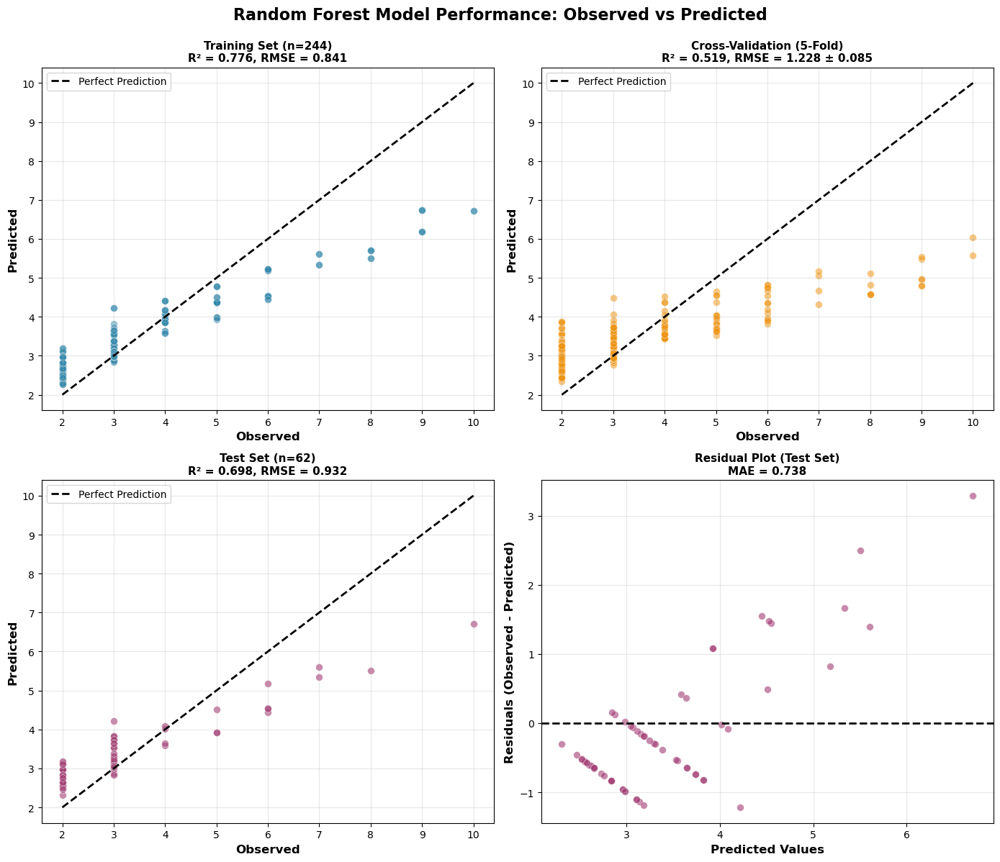

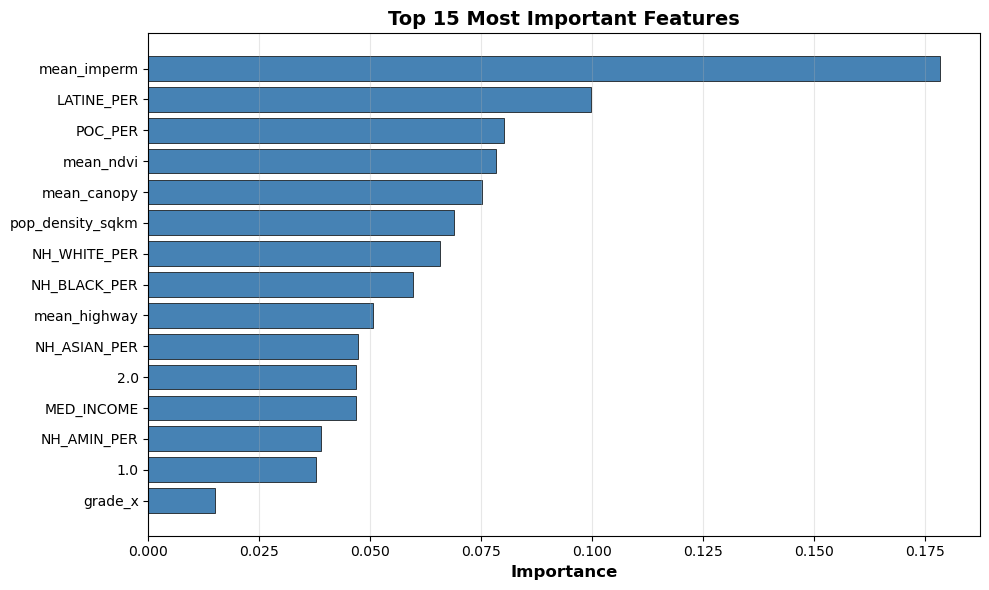


✓ HUMAN | Species richness model completed successfully

TESTING: SHRUBGRASS GUILD | SPECIES RICHNESS
Sample size: 369
Target range: [2.00, 28.00]
Target mean: 4.71 ± 4.11
Shape before imputation: (369, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (369, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      2.103        2.648        N/A          3.356       
R² Score                  0.692        0.454        0.505        0.575       
MAE                       N/A          1.692        N/A          1.855       

CV RMSE (±std)            2.648 ± 0.908

Plot saved to: ../results_images/rf_performance_shrubgrass_species_ric

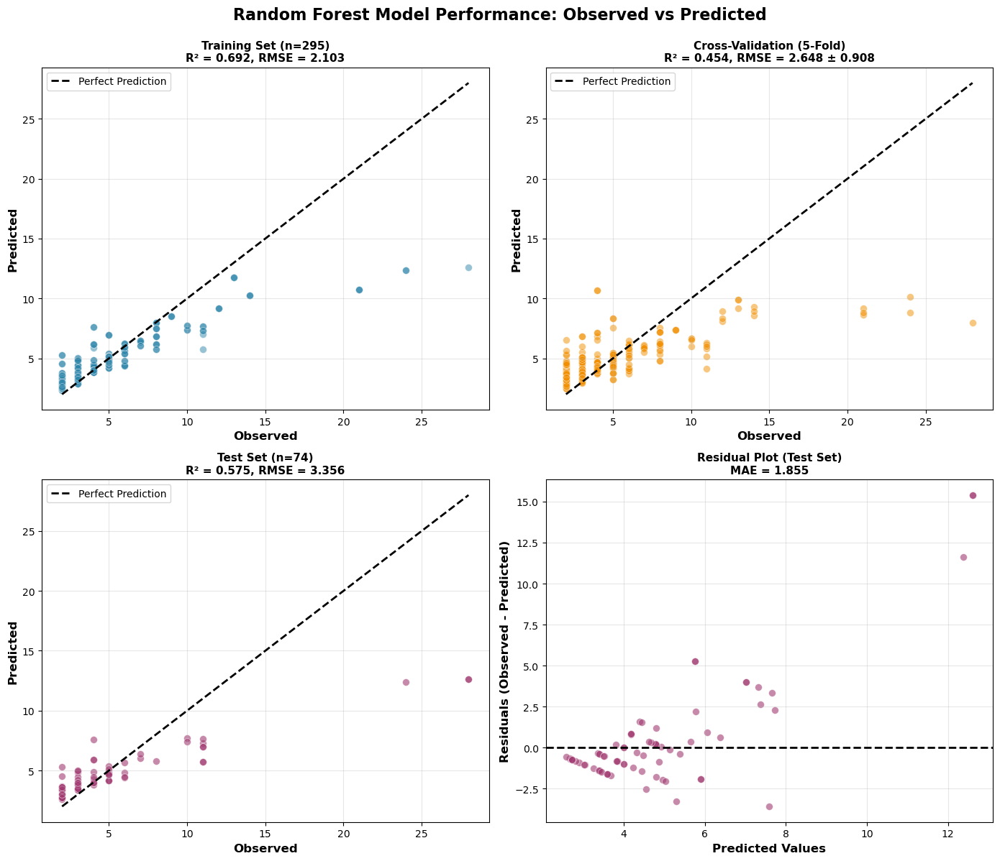

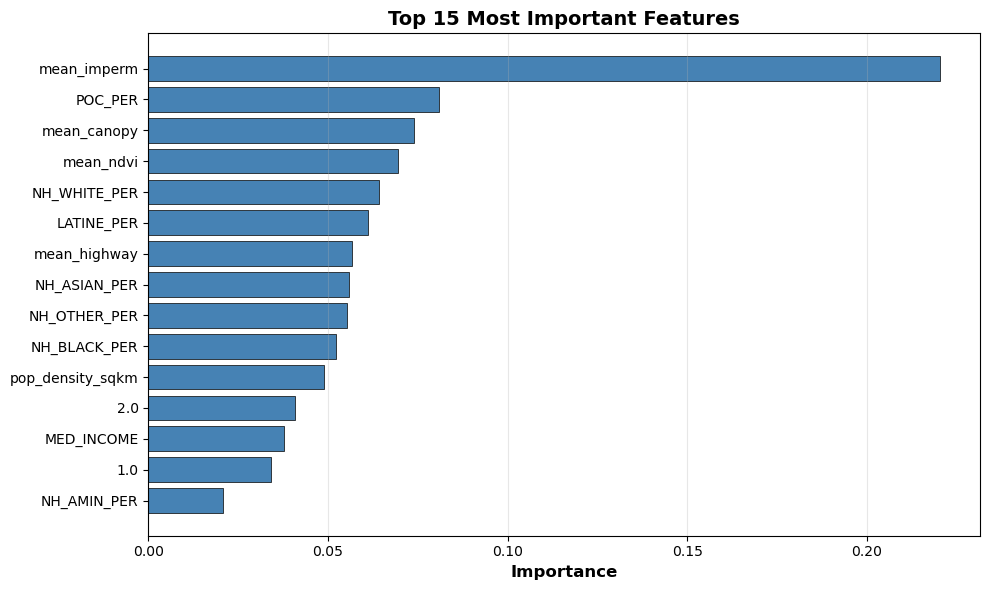


✓ SHRUBGRASS | Species richness model completed successfully

TESTING: TREES GUILD | SPECIES RICHNESS
Sample size: 492
Target range: [2.00, 55.00]
Target mean: 6.43 ± 7.20
Shape before imputation: (492, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (492, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      3.781        4.856        N/A          6.250       
R² Score                  0.673        0.438        0.483        0.531       
MAE                       N/A          3.024        N/A          3.358       

CV RMSE (±std)            4.856 ± 0.991

Plot saved to: ../results_images/rf_performance_trees_species_richness

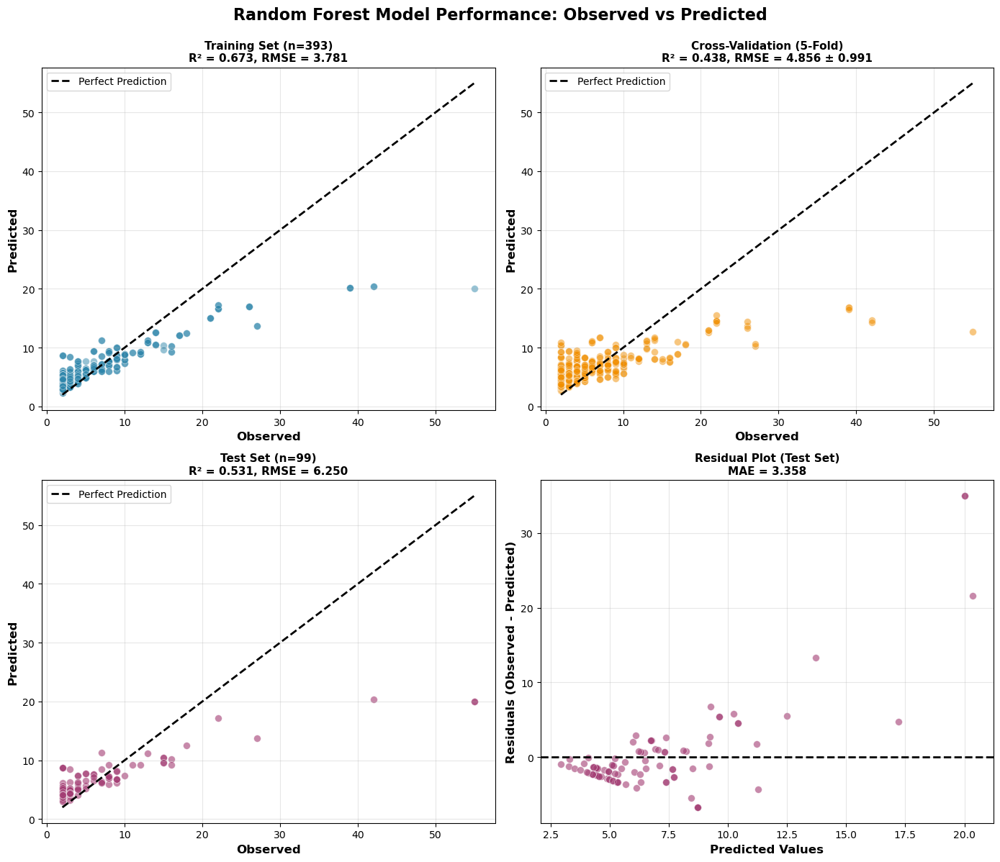

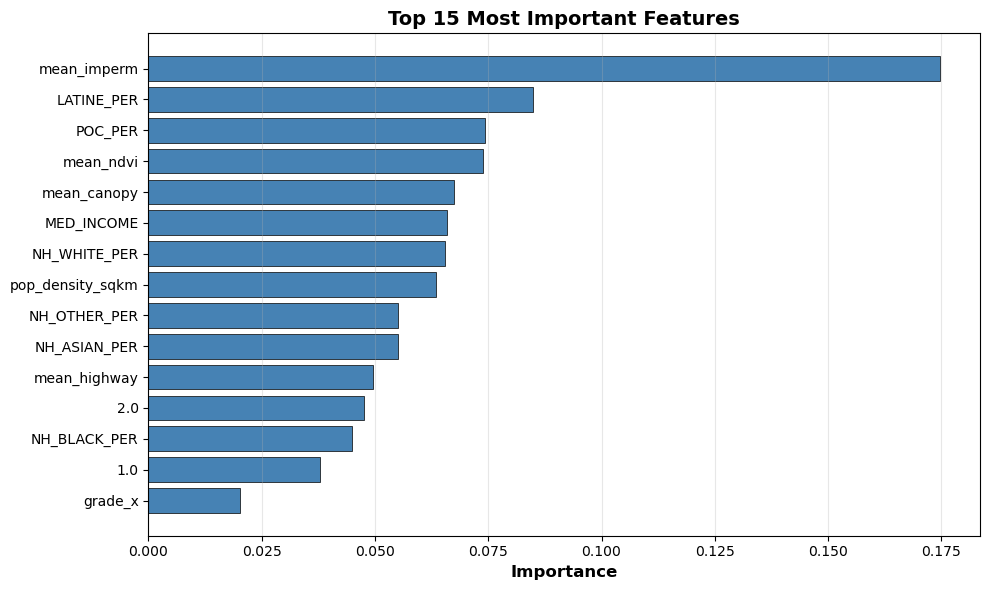


✓ TREES | Species richness model completed successfully

TESTING: WATER GUILD | SPECIES RICHNESS
Sample size: 63
Target range: [2.00, 23.00]
Target mean: 6.24 ± 5.46
Shape before imputation: (63, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (63, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      3.330        4.429        N/A          4.102       
R² Score                  0.618        0.289        0.417        0.449       
MAE                       N/A          3.379        N/A          3.065       

CV RMSE (±std)            4.429 ± 1.003

Plot saved to: ../results_images/rf_performance_water_species_richness.png


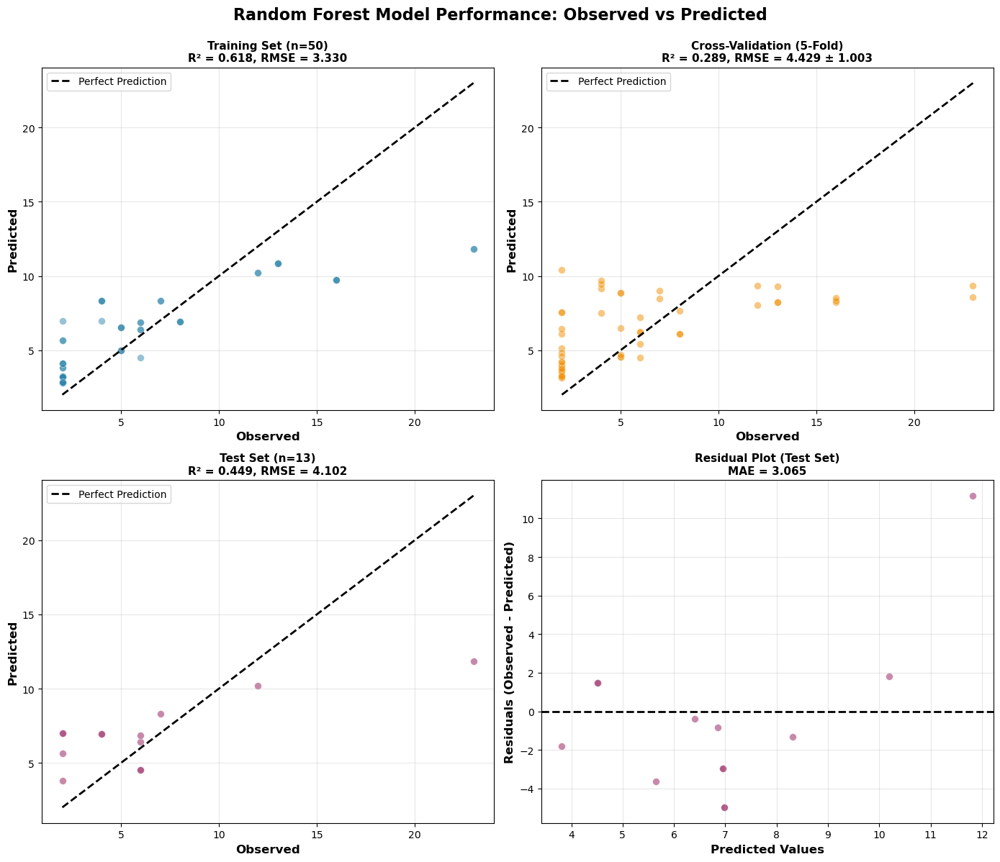

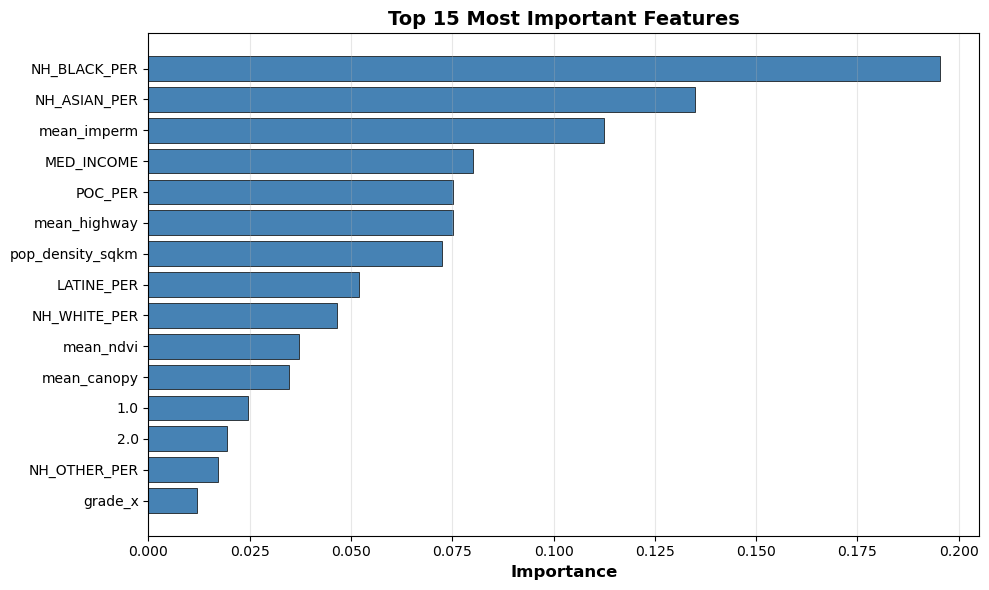


✓ WATER | Species richness model completed successfully

TESTING: NATIVE GUILD | SPECIES RICHNESS
Sample size: 699
Target range: [2.00, 105.00]
Target mean: 9.19 ± 12.96
Shape before imputation: (699, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (699, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      6.645        8.833        N/A          12.052      
R² Score                  0.692        0.447        0.520        0.451       
MAE                       N/A          5.115        N/A          5.587       

CV RMSE (±std)            8.833 ± 1.156

Plot saved to: ../results_images/rf_performance_native_species_richness.

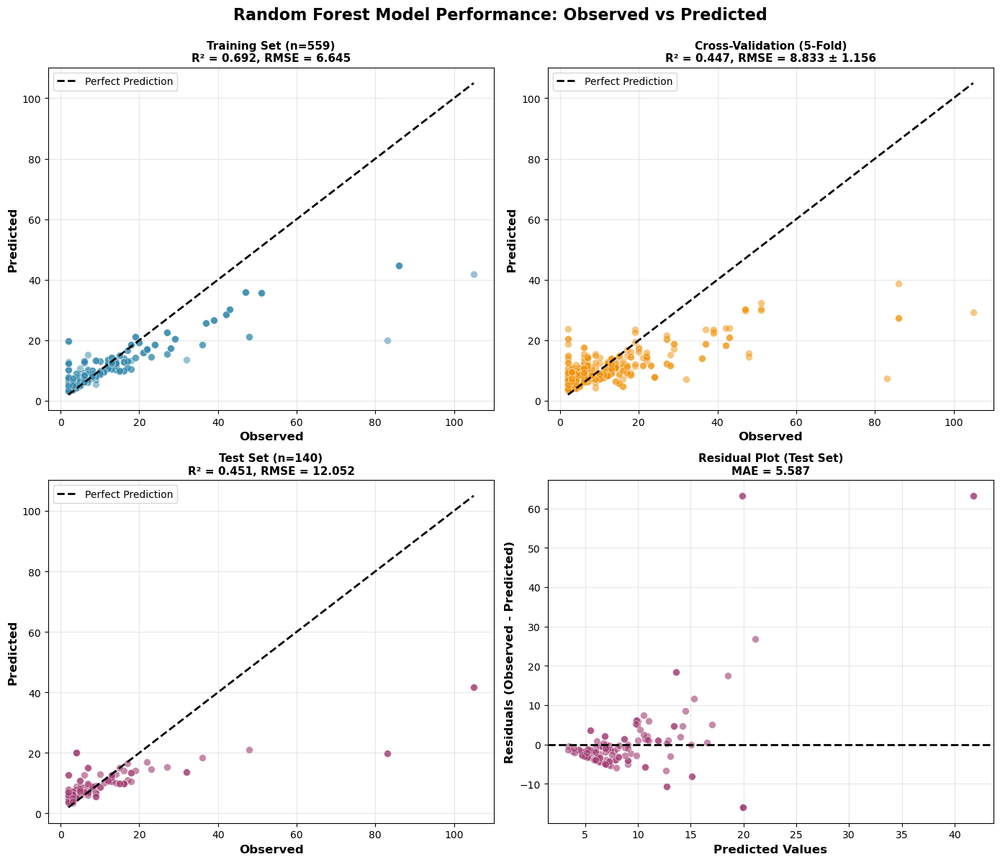

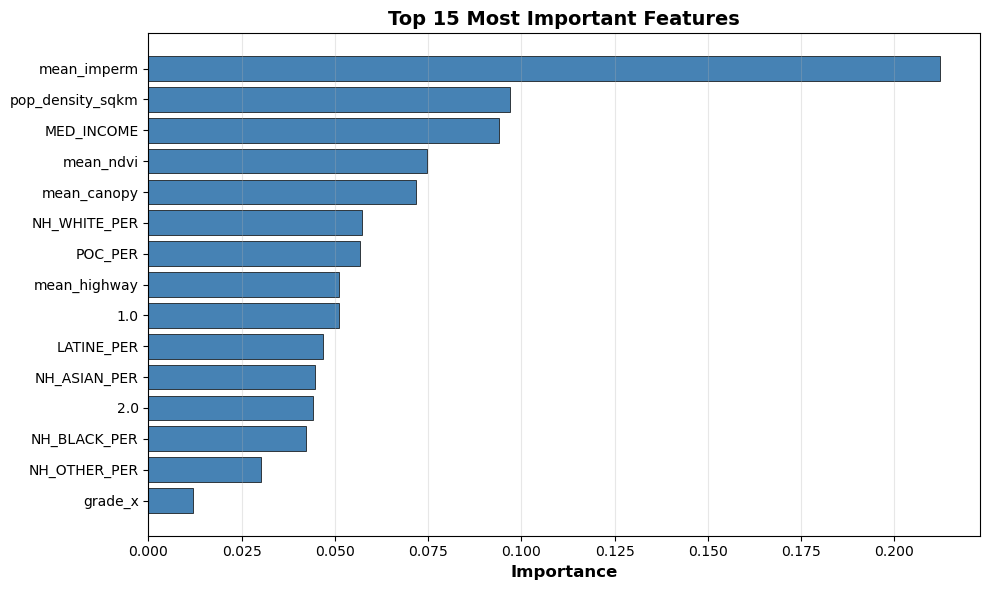


✓ NATIVE | Species richness model completed successfully

TESTING: NONNATIVE GUILD | SPECIES RICHNESS
Sample size: 201
Target range: [2.00, 6.00]
Target mean: 2.90 ± 1.06
Shape before imputation: (201, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (201, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.472        0.696        N/A          0.507       
R² Score                  0.814        0.574        0.658        0.635       
MAE                       N/A          0.558        N/A          0.428       

CV RMSE (±std)            0.696 ± 0.159

Plot saved to: ../results_images/rf_performance_nonnative_species_richn

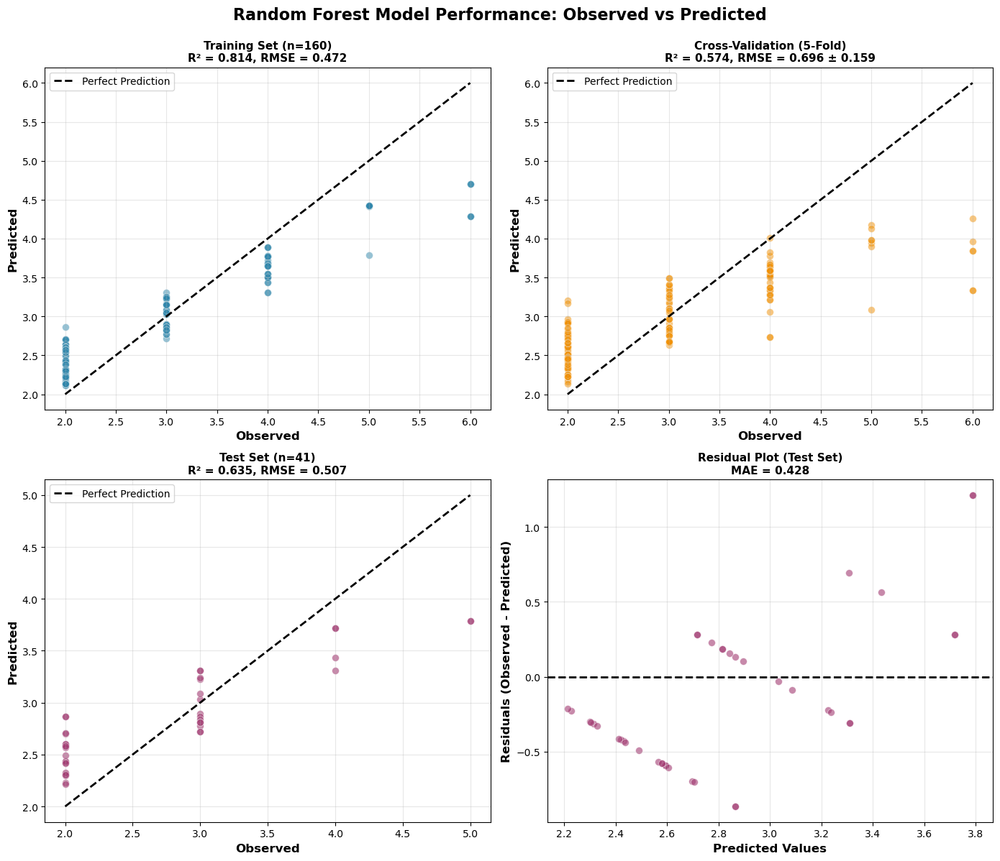

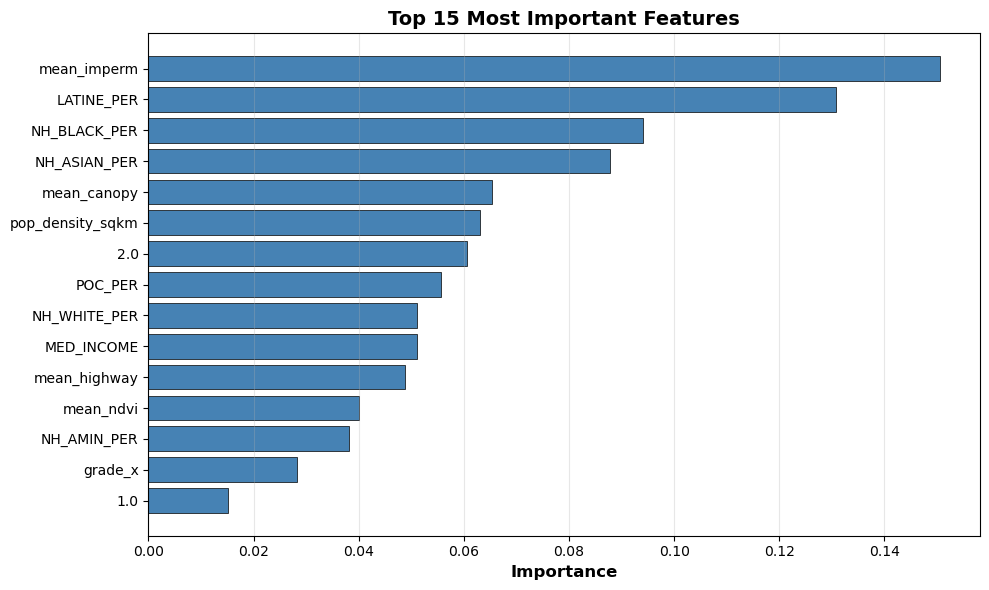


✓ NONNATIVE | Species richness model completed successfully

####################################################################################################
DIVERSITY METRIC: SHANNON DIVERSITY
####################################################################################################
Total samples for Shannon diversity: 759

TESTING: HUMAN GUILD | SHANNON DIVERSITY
Sample size: 306
Target range: [1.12, 6.90]
Target mean: 2.59 ± 0.99
Shape before imputation: (306, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (306, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.525        0.735        N/A          0.

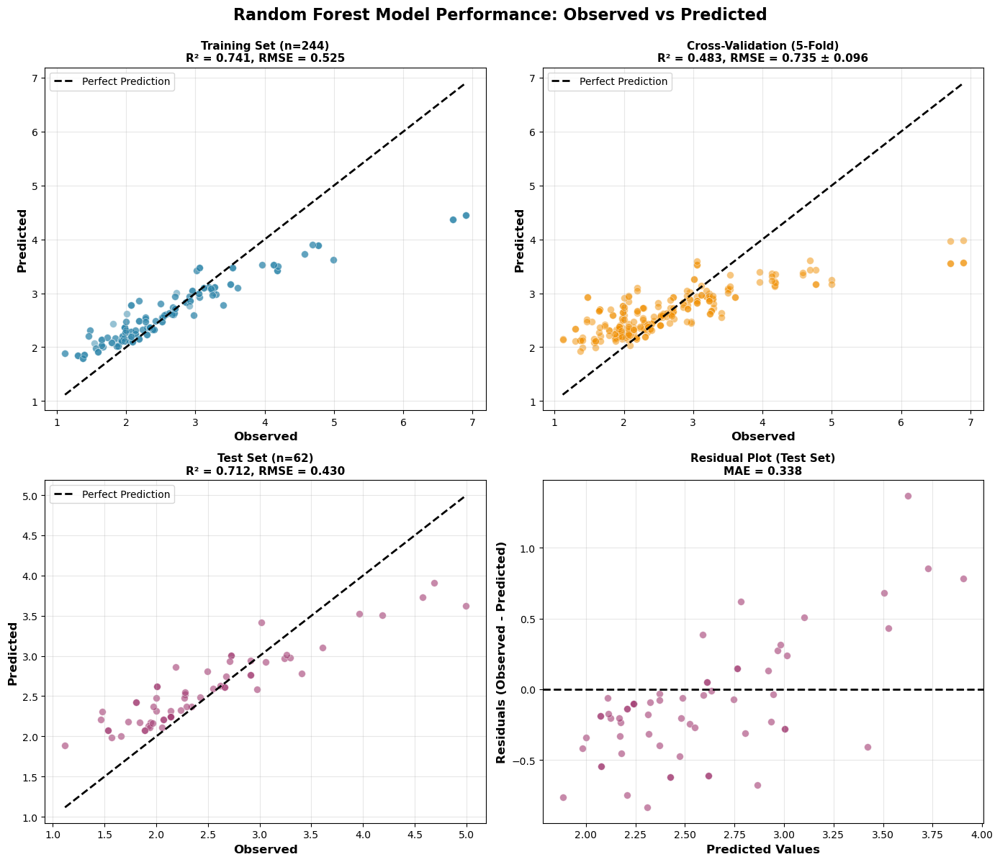

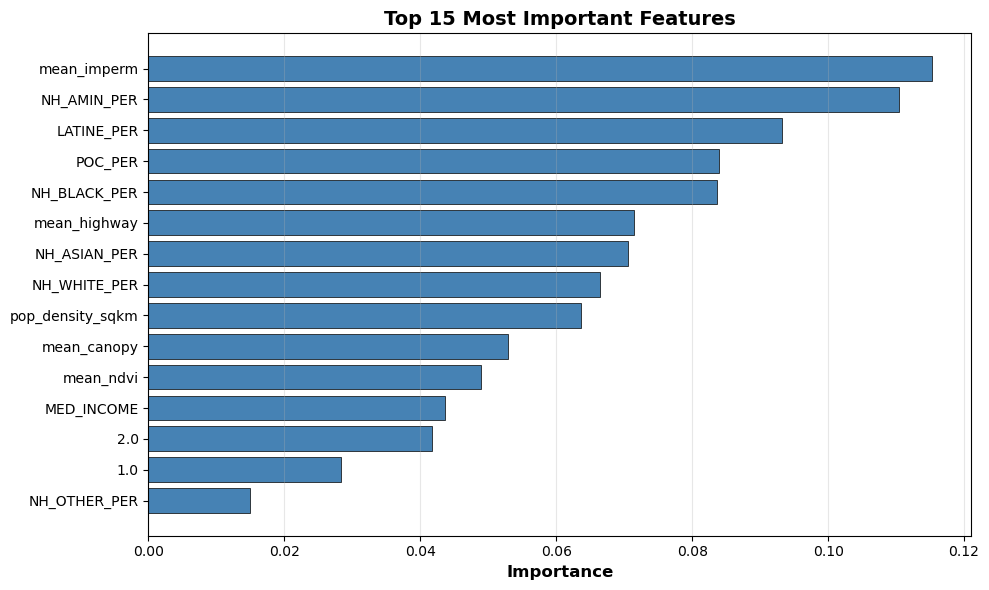


✓ HUMAN | Shannon diversity model completed successfully

TESTING: SHRUBGRASS GUILD | SHANNON DIVERSITY
Sample size: 369
Target range: [1.09, 9.88]
Target mean: 3.45 ± 1.77
Shape before imputation: (369, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (369, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.807        1.168        N/A          0.953       
R² Score                  0.795        0.558        0.631        0.684       
MAE                       N/A          0.881        N/A          0.723       

CV RMSE (±std)            1.168 ± 0.195

Plot saved to: ../results_images/rf_performance_shrubgrass_shannon_di

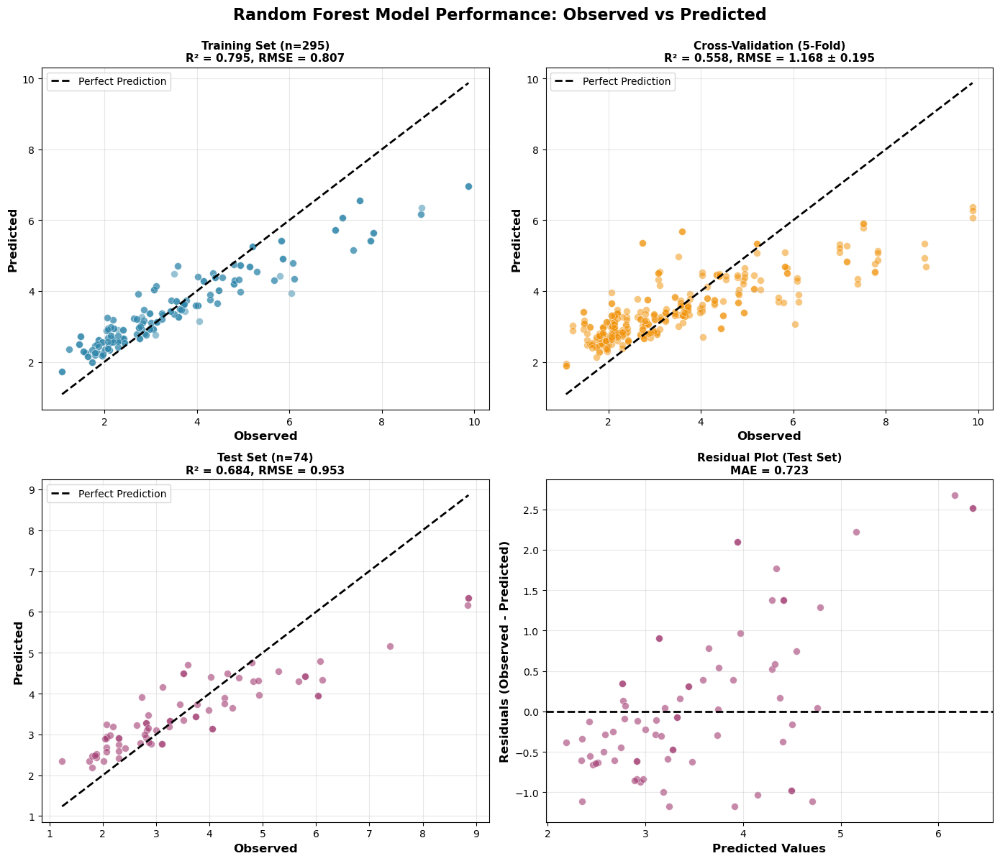

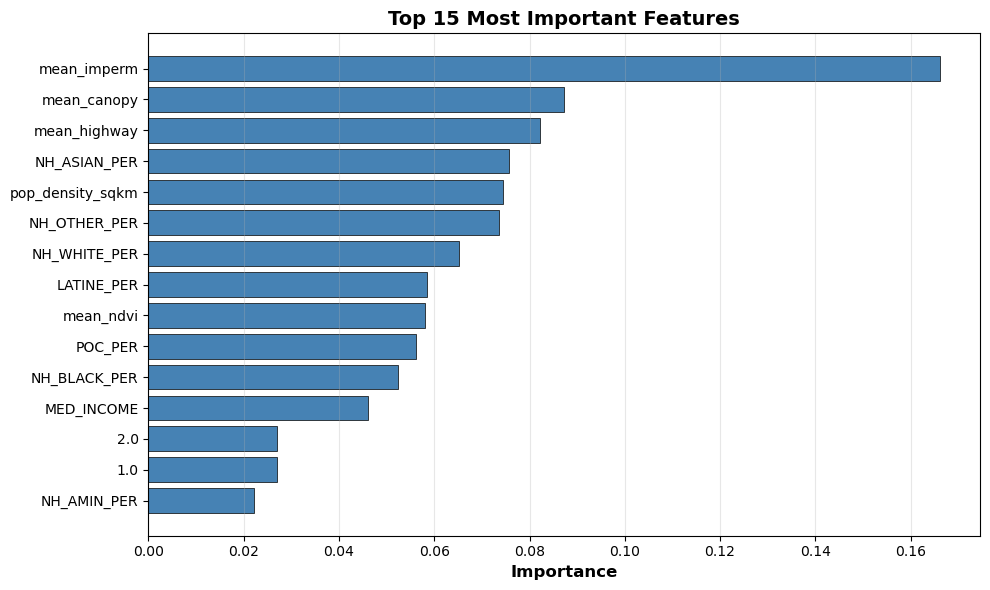


✓ SHRUBGRASS | Shannon diversity model completed successfully

TESTING: TREES GUILD | SHANNON DIVERSITY
Sample size: 492
Target range: [1.28, 18.17]
Target mean: 4.43 ± 2.88
Shape before imputation: (492, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (492, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      1.414        2.009        N/A          2.128       
R² Score                  0.742        0.475        0.539        0.558       
MAE                       N/A          1.503        N/A          1.459       

CV RMSE (±std)            2.009 ± 0.172

Plot saved to: ../results_images/rf_performance_trees_shannon_divers

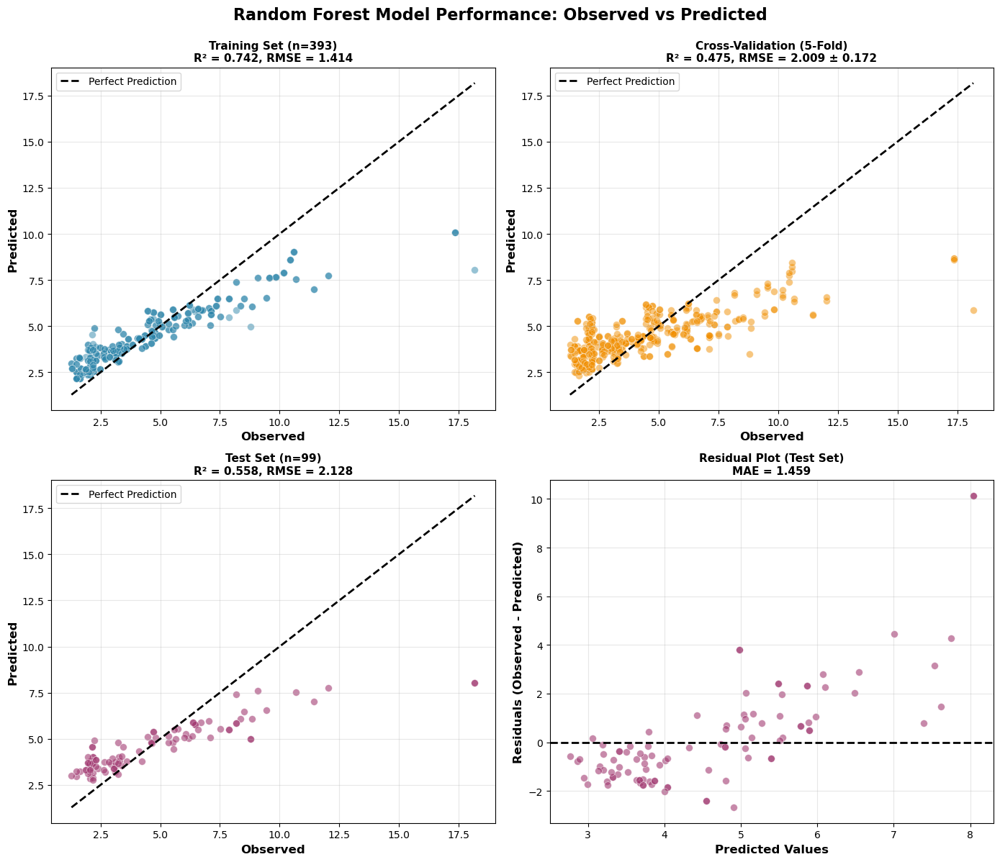

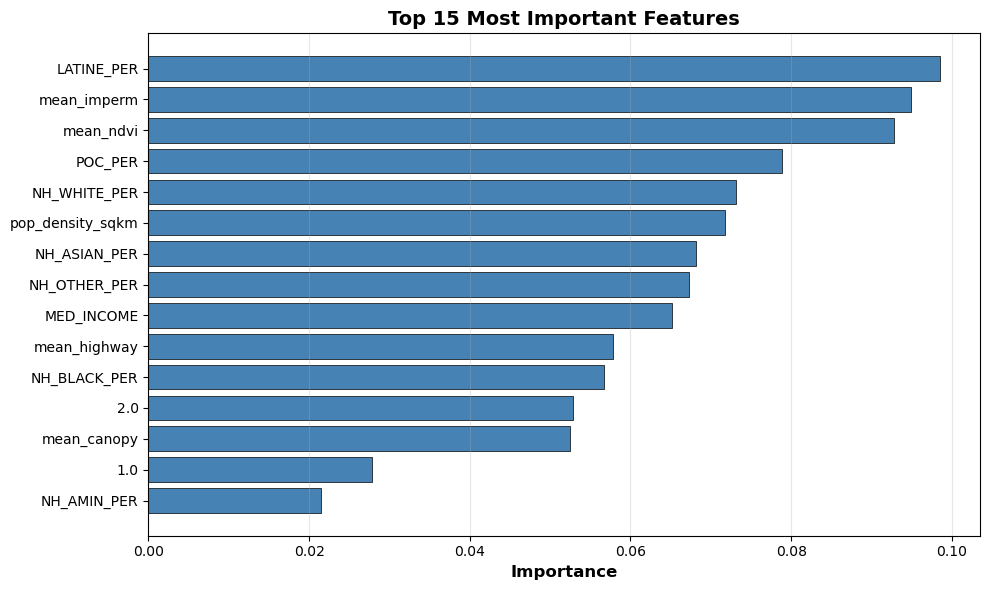


✓ TREES | Shannon diversity model completed successfully

TESTING: WATER GUILD | SHANNON DIVERSITY
Sample size: 63
Target range: [1.39, 7.36]
Target mean: 3.05 ± 1.65
Shape before imputation: (63, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (63, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.877        1.221        N/A          0.932       
R² Score                  0.718        0.401        0.555        0.646       
MAE                       N/A          0.981        N/A          0.658       

CV RMSE (±std)            1.221 ± 0.373

Plot saved to: ../results_images/rf_performance_water_shannon_diversity.png


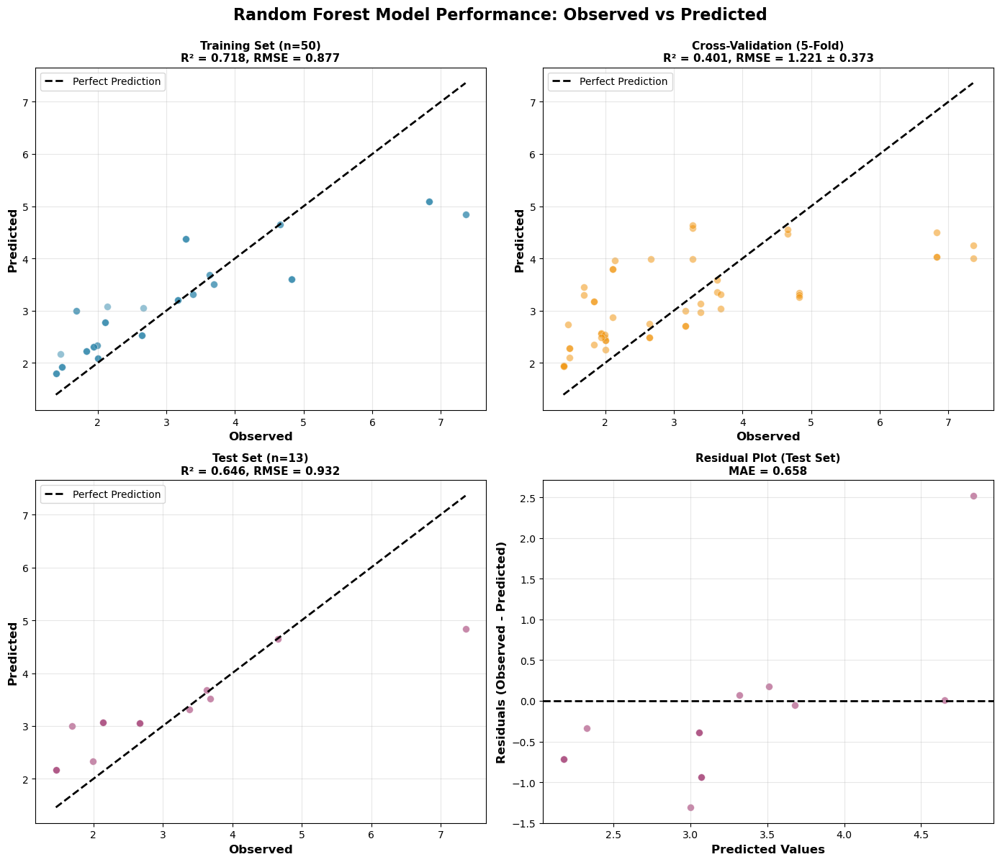

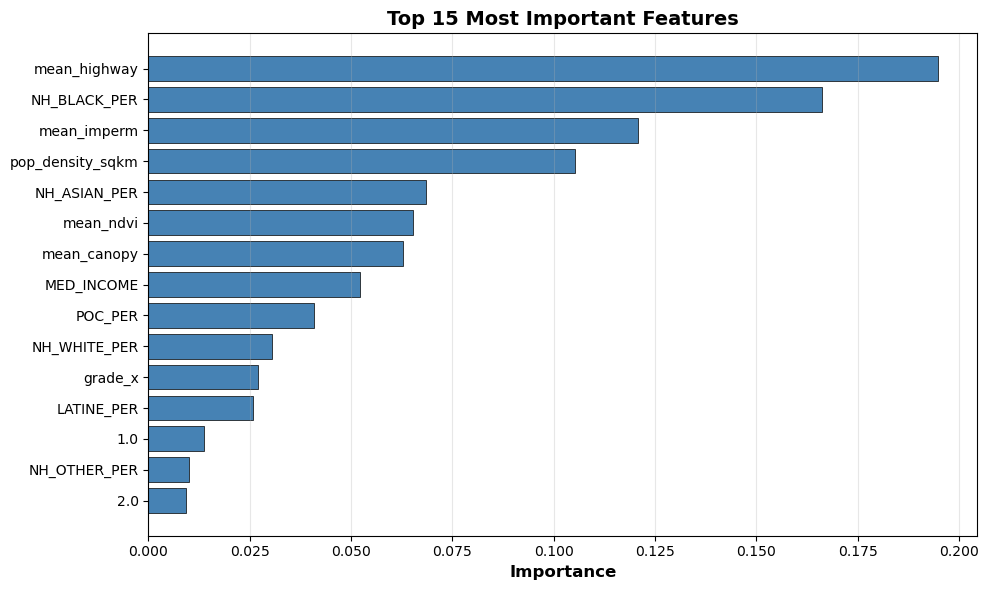


✓ WATER | Shannon diversity model completed successfully

TESTING: NATIVE GUILD | SHANNON DIVERSITY
Sample size: 699
Target range: [1.09, 35.08]
Target mean: 5.92 ± 5.21
Shape before imputation: (699, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (699, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      2.520        3.591        N/A          4.582       
R² Score                  0.735        0.442        0.545        0.469       
MAE                       N/A          2.503        N/A          2.645       

CV RMSE (±std)            3.591 ± 0.679

Plot saved to: ../results_images/rf_performance_native_shannon_diversity

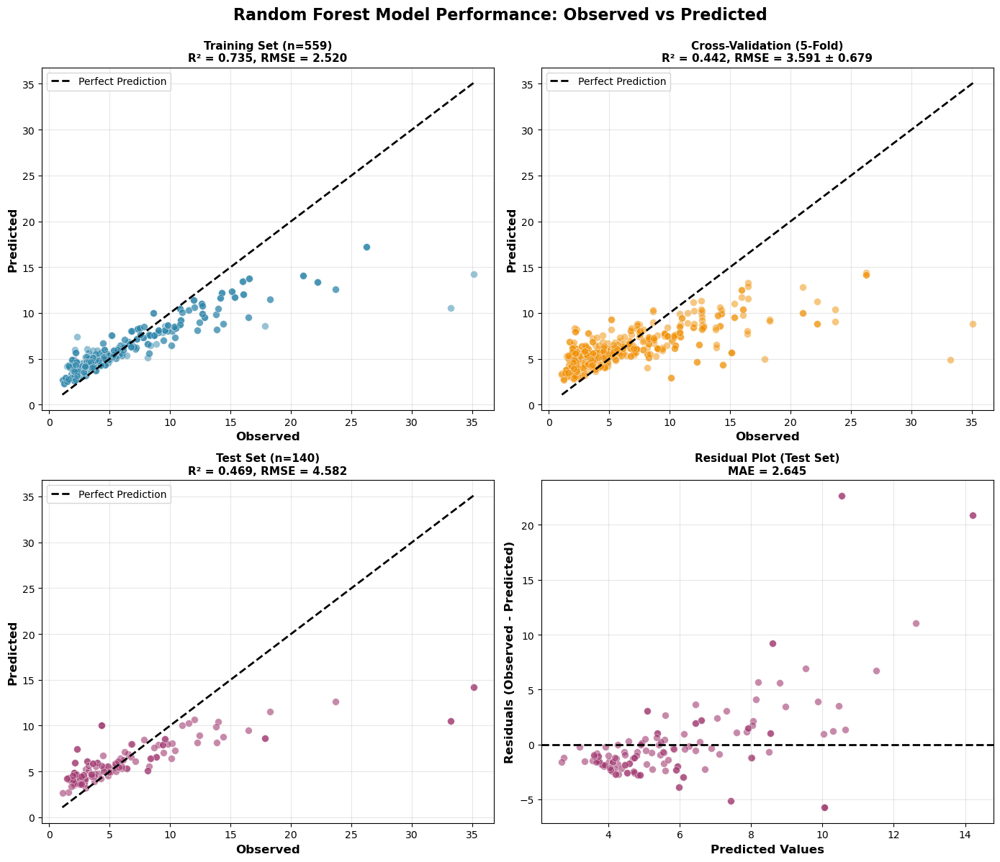

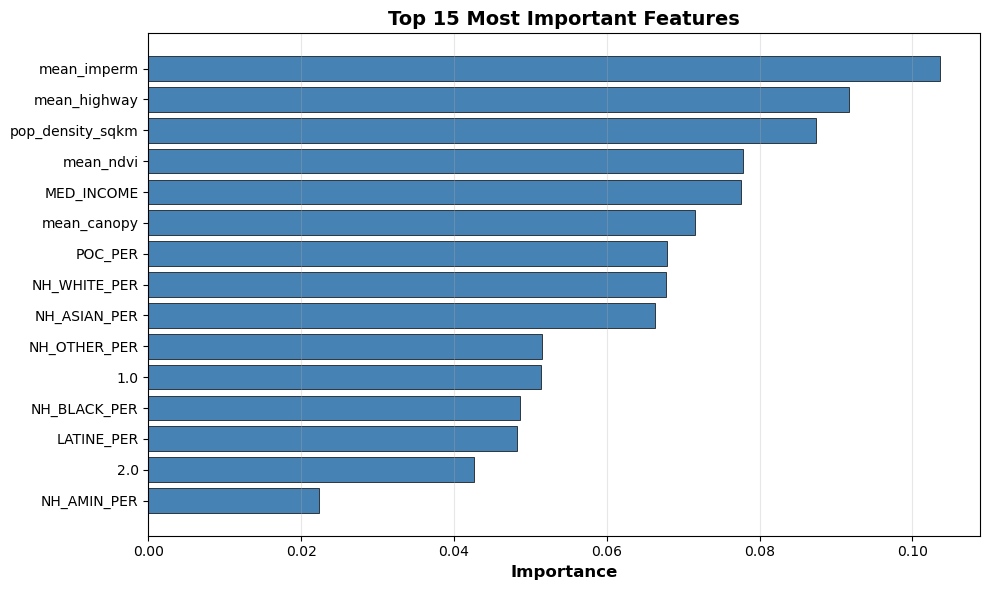


✓ NATIVE | Shannon diversity model completed successfully

TESTING: NONNATIVE GUILD | SHANNON DIVERSITY
Sample size: 201
Target range: [1.27, 5.19]
Target mean: 2.25 ± 0.79
Shape before imputation: (201, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (201, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.396        0.567        N/A          0.384       
R² Score                  0.779        0.534        0.616        0.465       
MAE                       N/A          0.435        N/A          0.313       

CV RMSE (±std)            0.567 ± 0.095

Plot saved to: ../results_images/rf_performance_nonnative_shannon_div

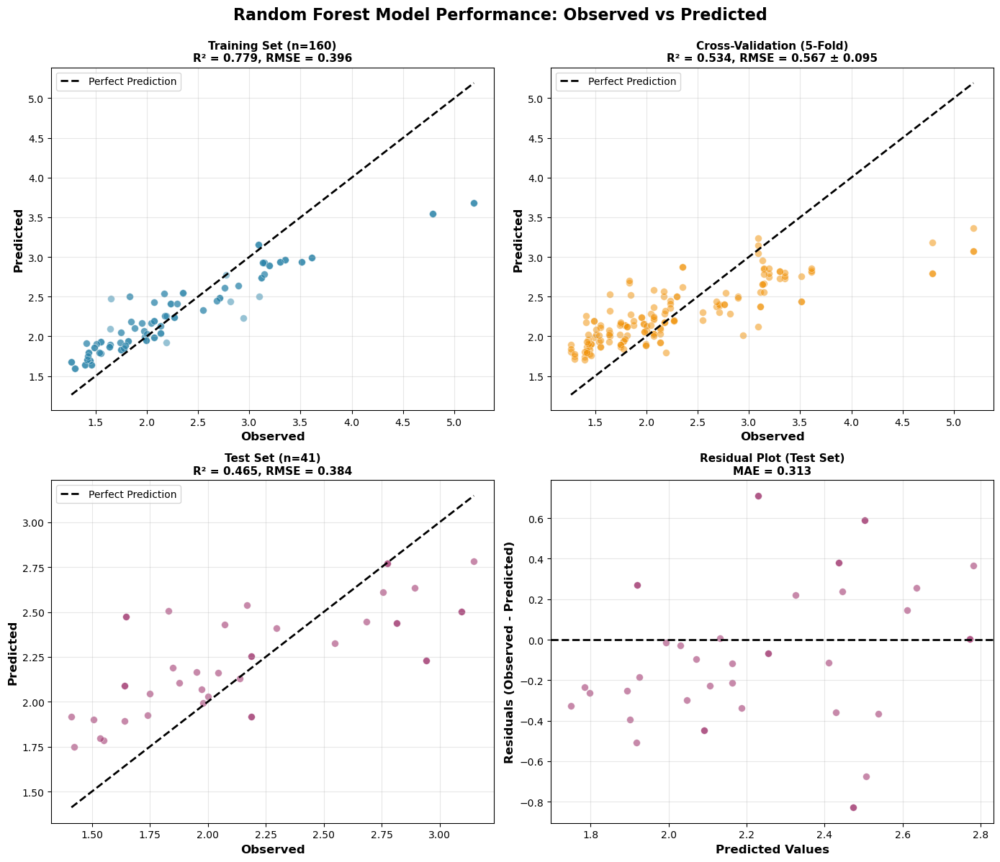

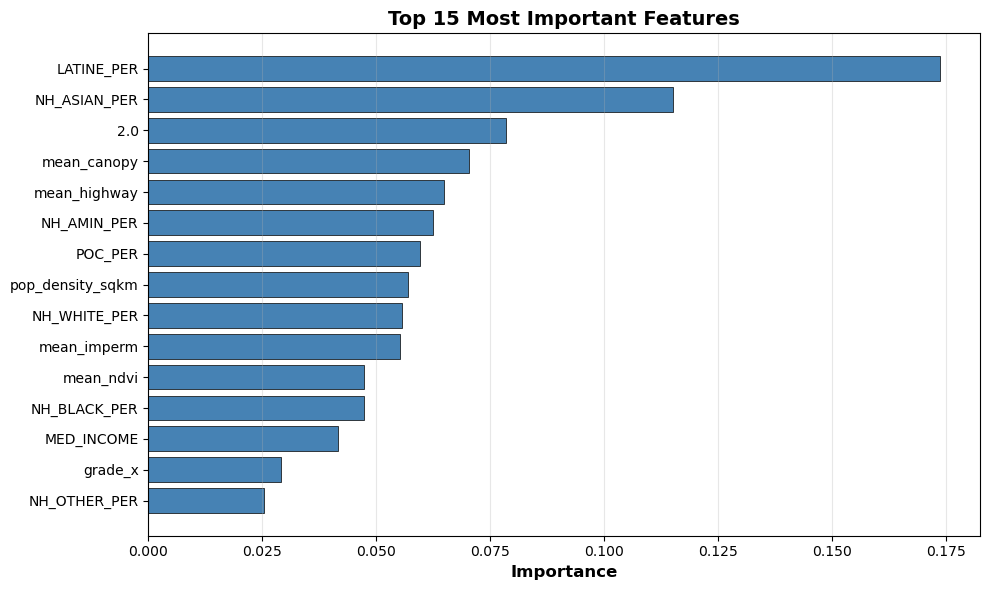


✓ NONNATIVE | Shannon diversity model completed successfully

####################################################################################################
DIVERSITY METRIC: SIMPSON DIVERSITY
####################################################################################################
Total samples for Simpson diversity: 759

TESTING: HUMAN GUILD | SIMPSON DIVERSITY
Sample size: 306
Target range: [1.04, 6.15]
Target mean: 2.35 ± 0.88
Shape before imputation: (306, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (306, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.458        0.650        N/A          0

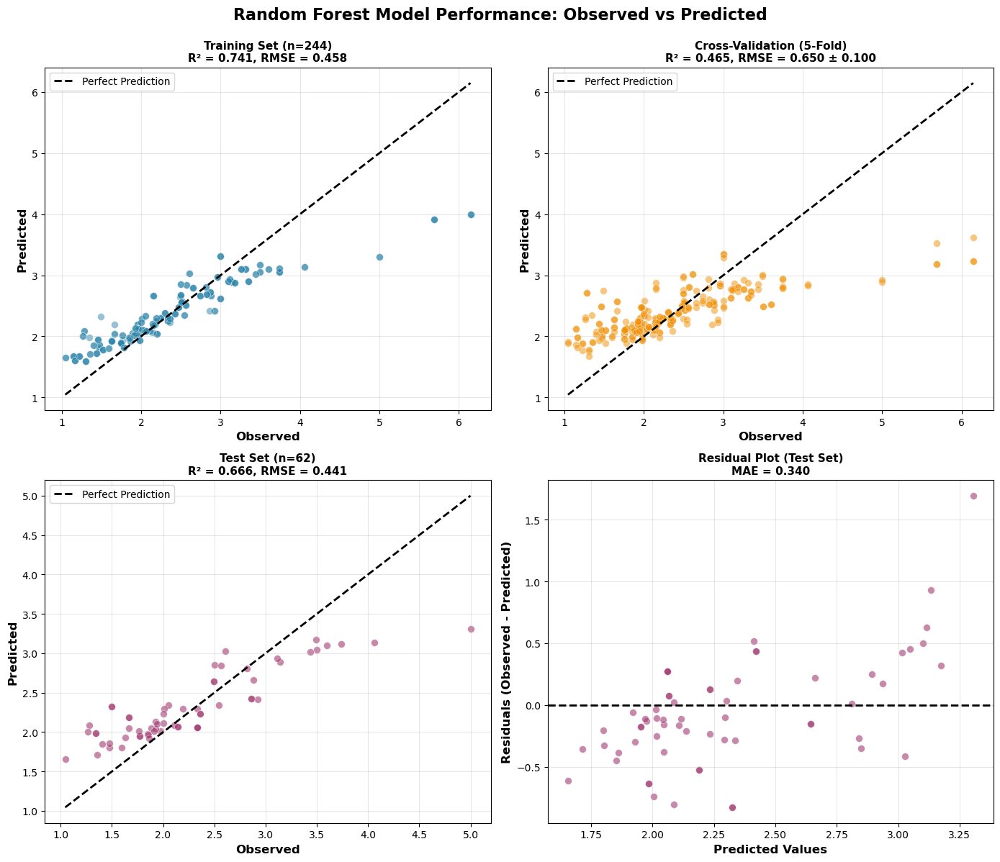

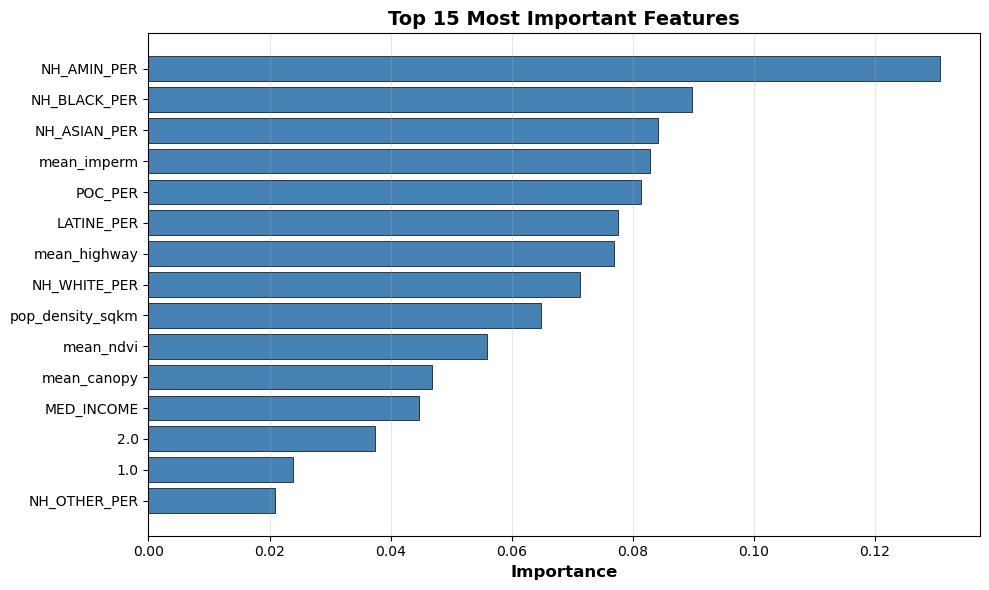


✓ HUMAN | Simpson diversity model completed successfully

TESTING: SHRUBGRASS GUILD | SIMPSON DIVERSITY
Sample size: 369
Target range: [1.03, 8.59]
Target mean: 3.11 ± 1.41
Shape before imputation: (369, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (369, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.662        0.952        N/A          0.690       
R² Score                  0.793        0.566        0.626        0.674       
MAE                       N/A          0.729        N/A          0.551       

CV RMSE (±std)            0.952 ± 0.127

Plot saved to: ../results_images/rf_performance_shrubgrass_simpson_di

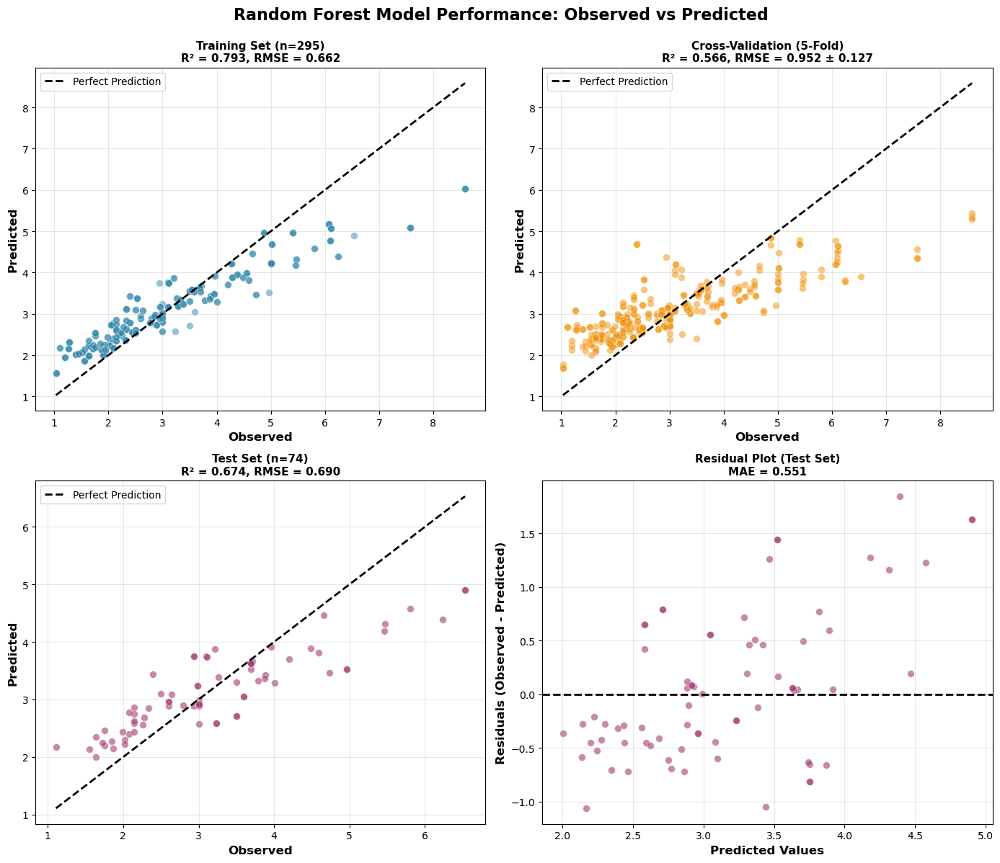

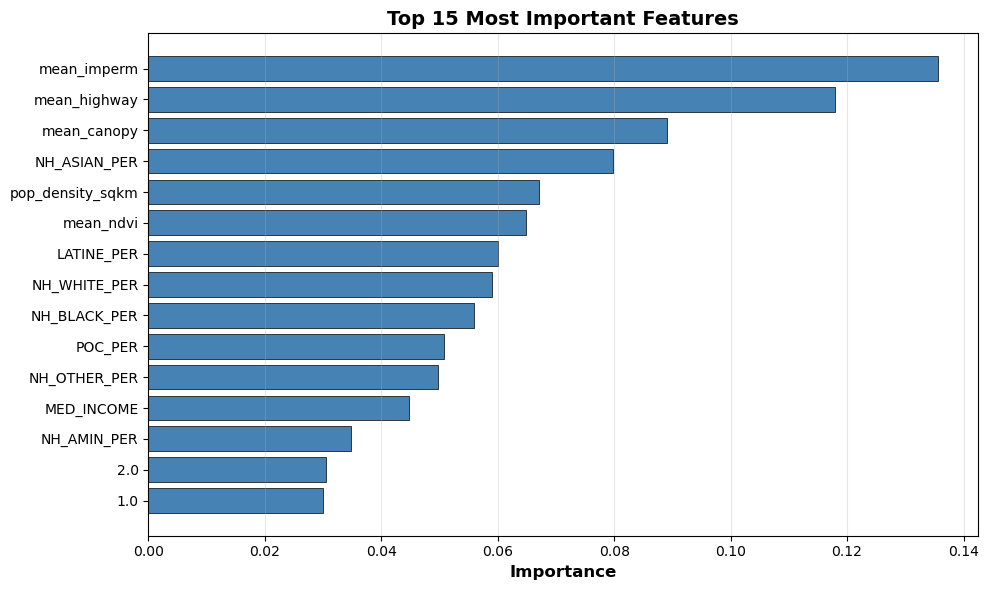


✓ SHRUBGRASS | Simpson diversity model completed successfully

TESTING: TREES GUILD | SIMPSON DIVERSITY
Sample size: 492
Target range: [1.14, 12.71]
Target mean: 3.84 ± 2.20
Shape before imputation: (492, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (492, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      1.058        1.535        N/A          1.501       
R² Score                  0.759        0.491        0.561        0.587       
MAE                       N/A          1.176        N/A          1.112       

CV RMSE (±std)            1.535 ± 0.098

Plot saved to: ../results_images/rf_performance_trees_simpson_divers

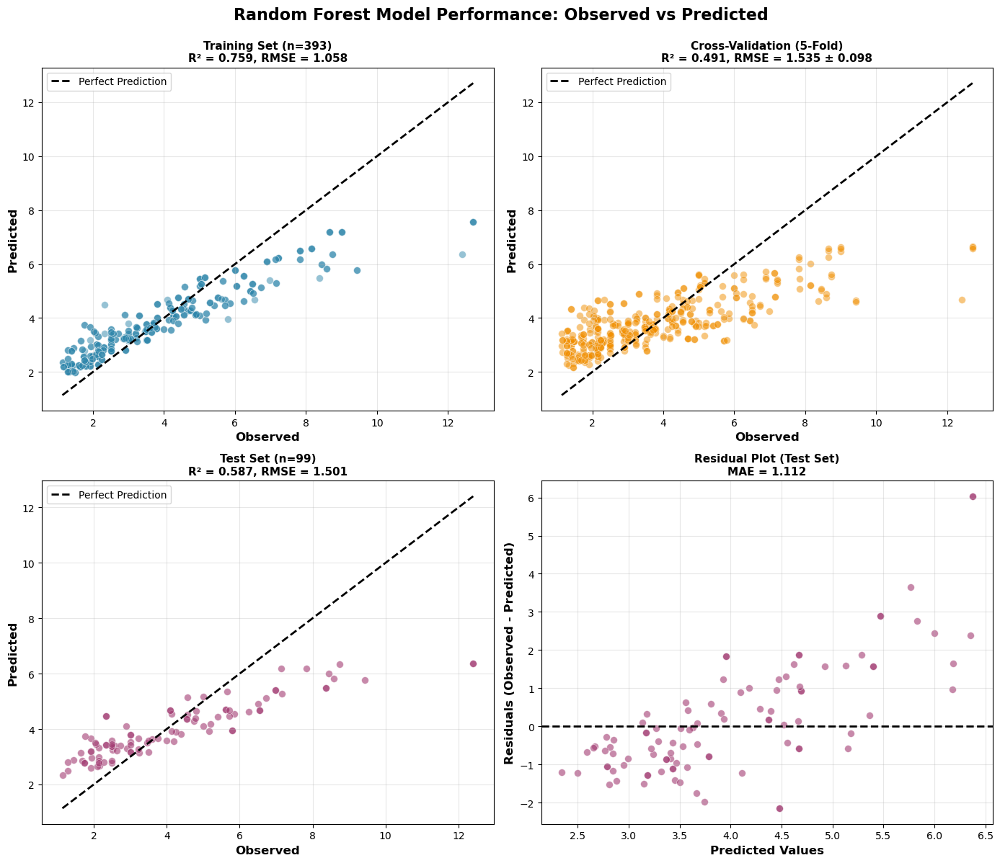

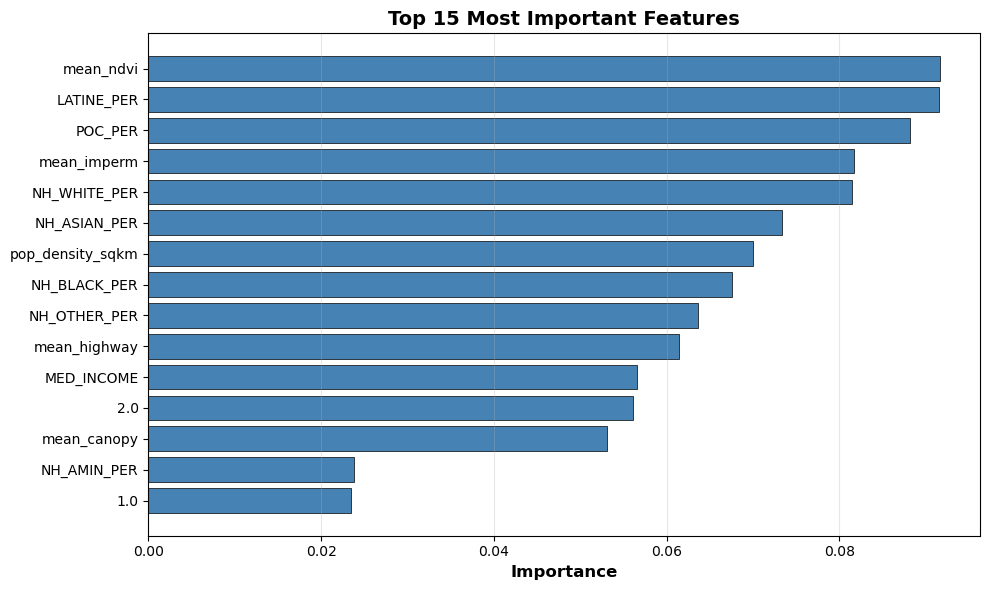


✓ TREES | Simpson diversity model completed successfully

TESTING: WATER GUILD | SIMPSON DIVERSITY
Sample size: 63
Target range: [1.21, 5.08]
Target mean: 2.40 ± 0.99
Shape before imputation: (63, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (63, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.491        0.706        N/A          0.439       
R² Score                  0.769        0.479        0.623        0.726       
MAE                       N/A          0.559        N/A          0.344       

CV RMSE (±std)            0.706 ± 0.212

Plot saved to: ../results_images/rf_performance_water_simpson_diversity.png


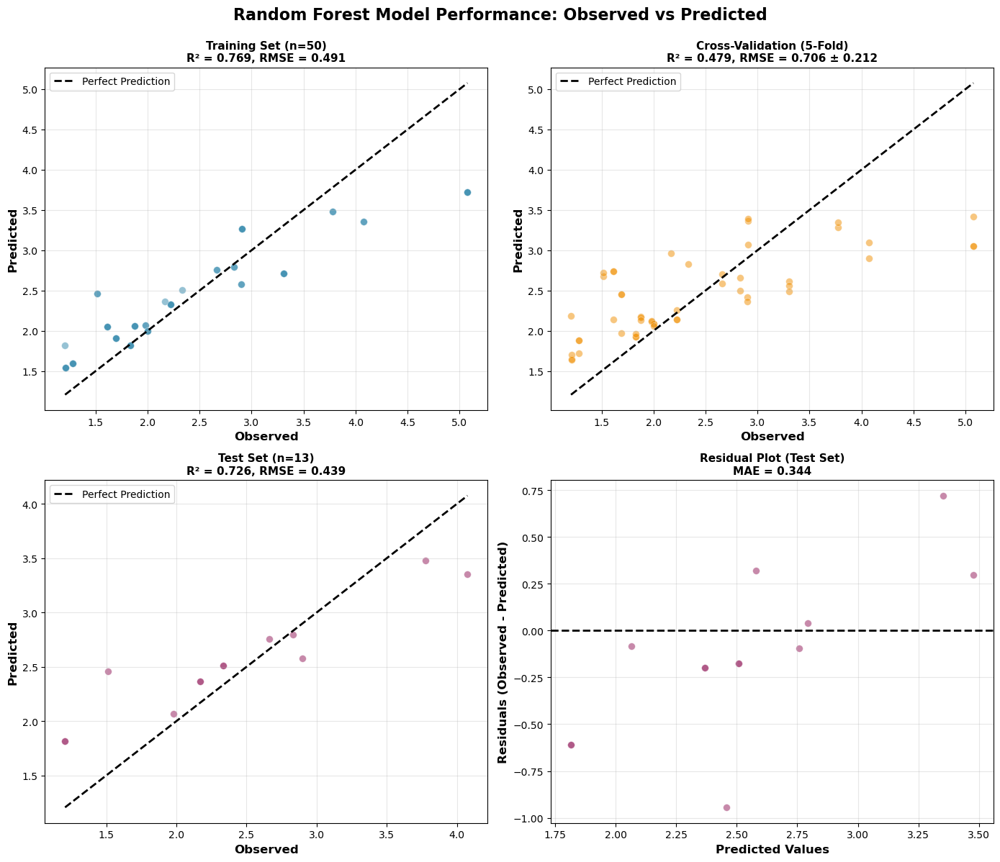

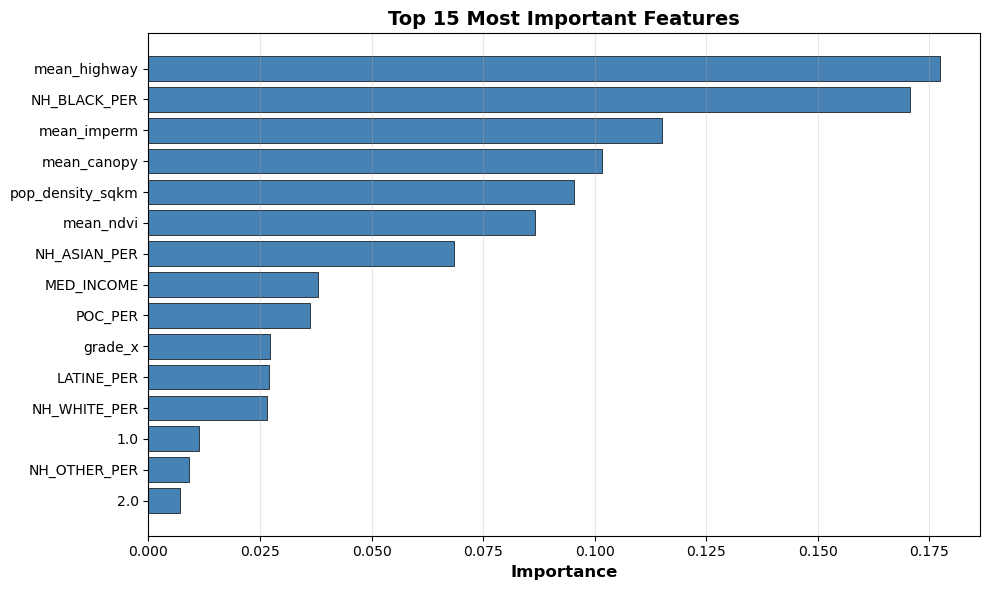


✓ WATER | Simpson diversity model completed successfully

TESTING: NATIVE GUILD | SIMPSON DIVERSITY
Sample size: 699
Target range: [1.03, 24.15]
Target mean: 4.88 ± 3.72
Shape before imputation: (699, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (699, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      1.727        2.579        N/A          3.015       
R² Score                  0.762        0.455        0.581        0.514       
MAE                       N/A          1.821        N/A          1.799       

CV RMSE (±std)            2.579 ± 0.447

Plot saved to: ../results_images/rf_performance_native_simpson_diversity

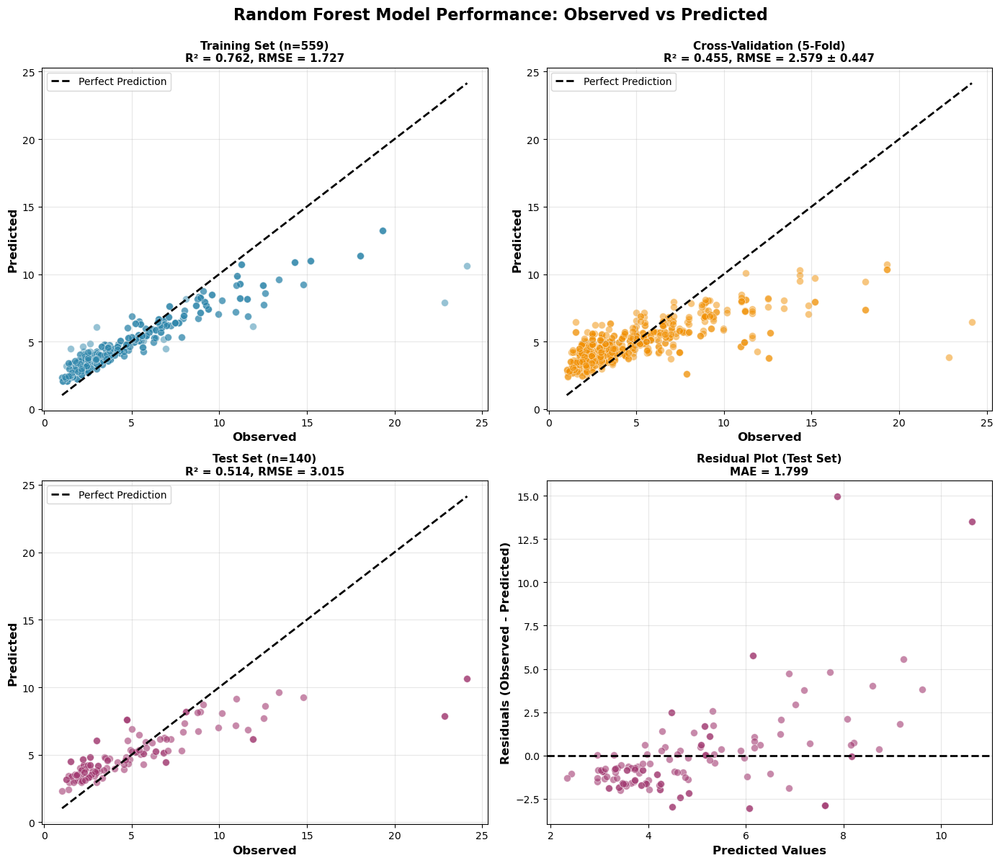

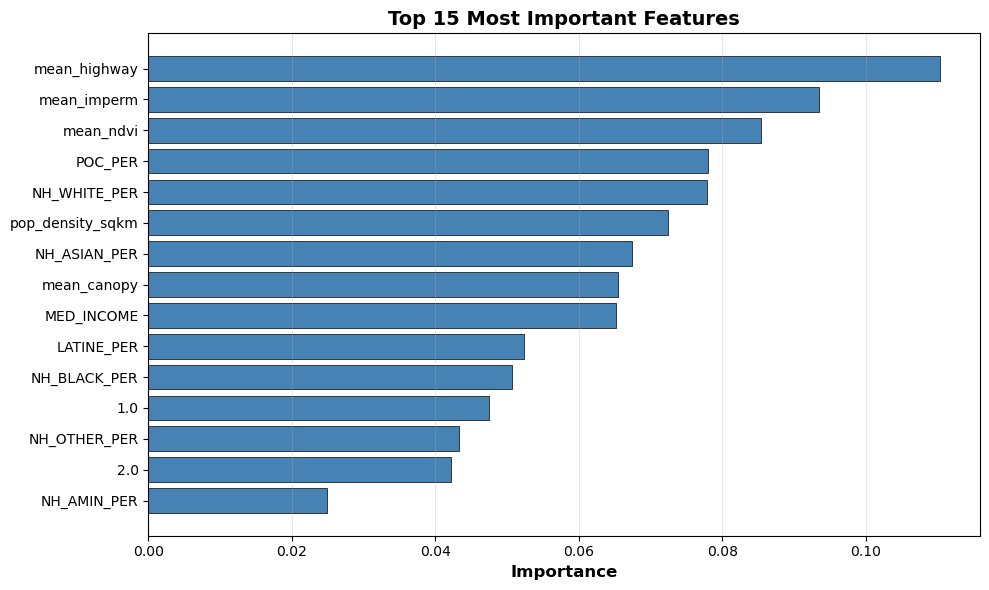


✓ NATIVE | Simpson diversity model completed successfully

TESTING: NONNATIVE GUILD | SIMPSON DIVERSITY
Sample size: 201
Target range: [1.11, 5.41]
Target mean: 2.07 ± 0.86
Shape before imputation: (201, 17)
Columns: ['grade_x', 'mean_ndvi', 'mean_highway', 'mean_imperm', 'mean_canopy', 'MED_INCOME', 'NH_WHITE_PER', 'NH_BLACK_PER', 'NH_AMIN_PER', 'NH_ASIAN_PER', 'NH_NHPI_PER', 'NH_OTHER_PER', 'LATINE_PER', 'POC_PER', 'pop_density_sqkm', '1.0', '2.0']
Shape after imputation: (201, 17)
MODEL EVALUATION SUMMARY

Metric                    Train        CV           OOB          Test        
------------------------------------------------------------
RMSE                      0.462        0.636        N/A          0.413       
R² Score                  0.745        0.495        0.561        0.409       
MAE                       N/A          0.478        N/A          0.341       

CV RMSE (±std)            0.636 ± 0.138

Plot saved to: ../results_images/rf_performance_nonnative_simpson_div

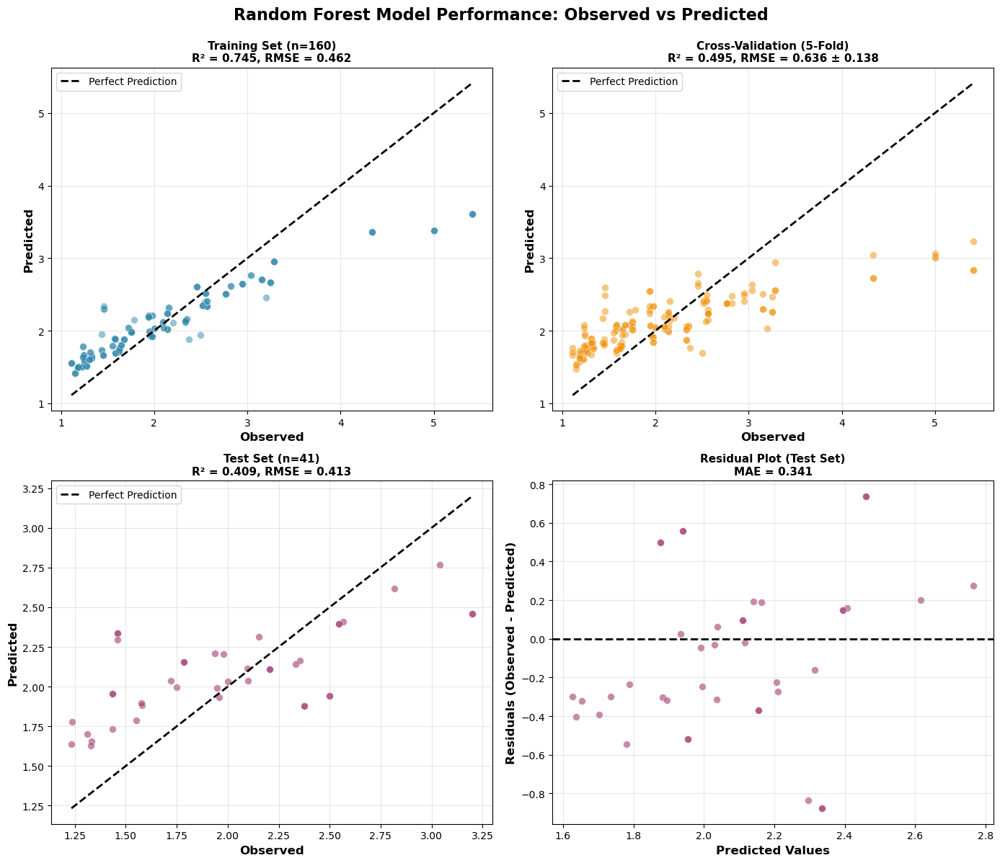

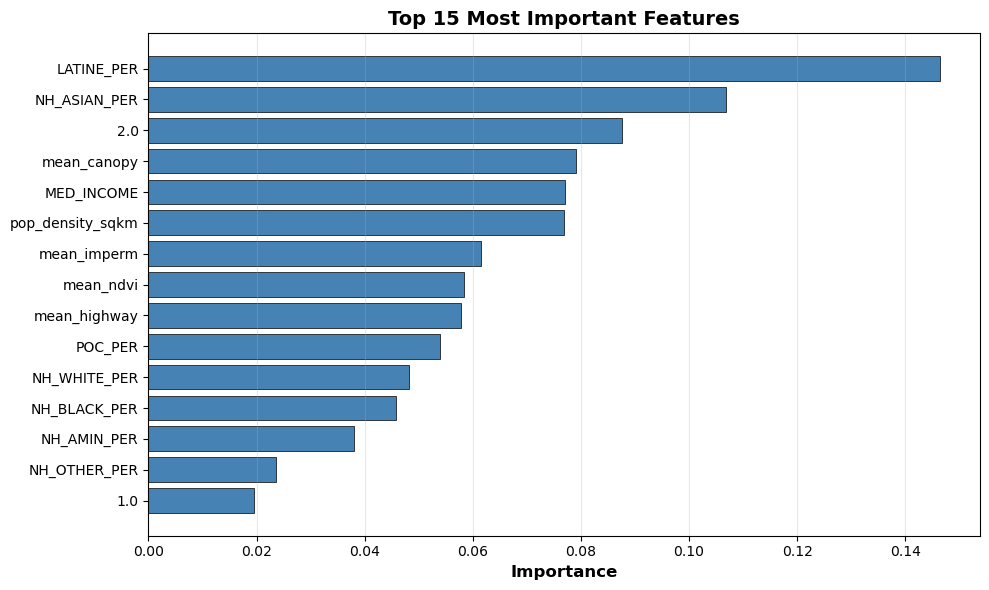


✓ NONNATIVE | Simpson diversity model completed successfully

PERFORMANCE COMPARISON ACROSS ALL GUILDS AND DIVERSITY METRICS

     Guild         Diversity  N_samples  Train_R2    CV_R2  Test_R2  OOB_Score  Test_RMSE  Test_MAE  CV_RMSE_mean  CV_RMSE_std  Overfit_Gap
     human  Species richness        306  0.775511 0.519328 0.698219   0.605854   0.931693  0.737681      1.227704     0.085257     0.077292
shrubgrass  Species richness        369  0.692168 0.454490 0.574568   0.504687   3.355610  1.854893      2.648148     0.908301     0.117600
     trees  Species richness        492  0.673345 0.437761 0.531076   0.482700   6.250017  3.358464      4.855651     0.990691     0.142269
     water  Species richness         63  0.617818 0.289178 0.448747   0.417024   4.101785  3.064769      4.429022     1.002921     0.169071
    native  Species richness        699  0.692121 0.446712 0.450527   0.519634  12.051717  5.586771      8.832789     1.156063     0.241594
 nonnative  Species richness     

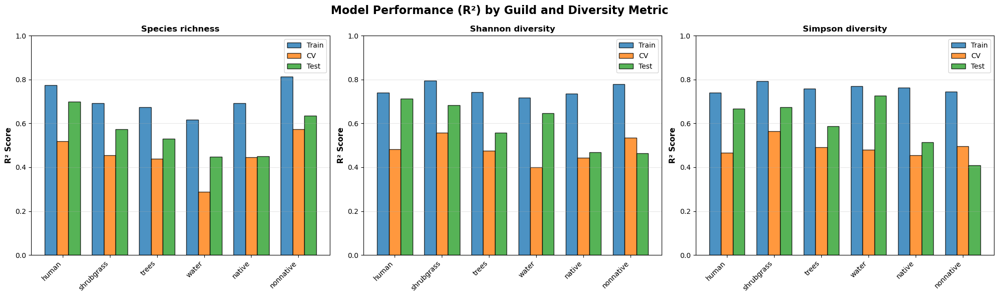

✓ Saved: ../results_images/rf_r2_heatmap.png


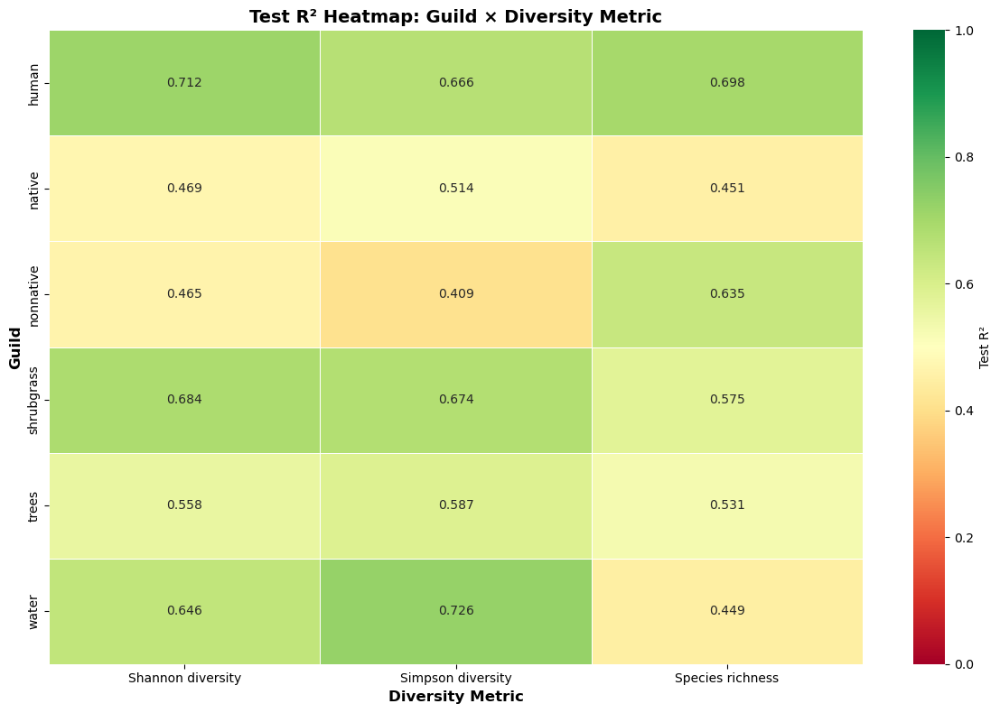

✓ Saved: ../results_images/rf_rmse_comparison.png


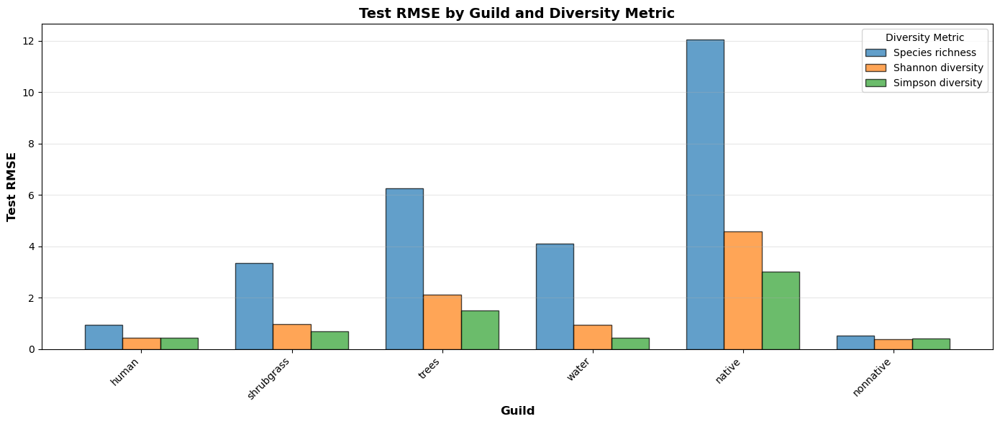

✓ Saved: ../results_images/rf_overfitting_comparison.png


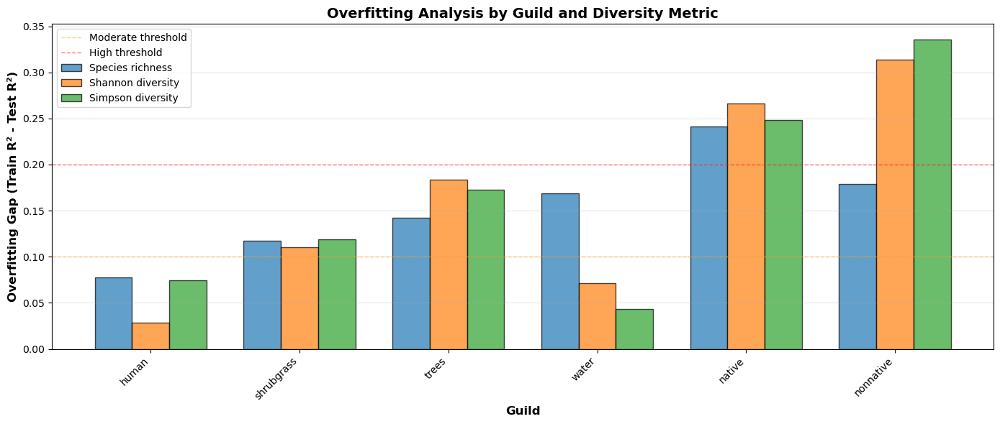


ANALYSIS BY DIVERSITY TYPE

SPECIES RICHNESS
----------------------------------------------------------------------------------------------------
  Number of guilds tested: 6
  Average Test R²: 0.556 (±0.100)
  Average CV R²: 0.454 (±0.096)
  Average Test RMSE: 4.533 (±4.248)
  Average Overfitting Gap: 0.154 (±0.056)

  Best performing guild (by Test R²):
    human: R² = 0.698, RMSE = 0.932

  Worst performing guild (by Test R²):
    water: R² = 0.449, RMSE = 4.102

SHANNON DIVERSITY
----------------------------------------------------------------------------------------------------
  Number of guilds tested: 6
  Average Test R²: 0.589 (±0.108)
  Average CV R²: 0.482 (±0.058)
  Average Test RMSE: 1.568 (±1.605)
  Average Overfitting Gap: 0.162 (±0.112)

  Best performing guild (by Test R²):
    human: R² = 0.712, RMSE = 0.430

  Worst performing guild (by Test R²):
    nonnative: R² = 0.465, RMSE = 0.384

SIMPSON DIVERSITY
--------------------------------------------------------------

# Habitat SHAP Radial w/ stats (FINAL)

We're going to analyze each guild using KNN-RF and SHAP using guild results from #Habitat Shap Values code section


In [19]:

def plot_guild_feature_radar_shap_with_stats(guild_results, comparison_df, guild_name='trees', 
                                             diversity_type='Species richness', save_path=None):
    """
    Radar plot using ACTUAL mean absolute SHAP values (not percentages)
    with bins for weak/moderate/strong importance
    Top 3 variables highlighted with scores shown only for them
    """
    from math import pi
    
    # Create unique key for this combination
    key = f"{guild_name}_{diversity_type.replace(' ', '_')}"
    
    if key not in guild_results:
        print(f"No results found for {guild_name} with {diversity_type}")
        return
    
    result = guild_results[key]
    
    # Check if SHAP values exist
    if 'shap_values' not in result or result.get('shap_values') is None:
        print(f"No SHAP values found for {guild_name} with {diversity_type}")
        return
    
    shap_values = result['shap_values']
    X_test = result['X_test']
    
    # Calculate ABSOLUTE mean SHAP values (actual values, not normalized)
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    
    # Create feature importance dataframe
    shap_importance = pd.DataFrame({
        'feature': X_test.columns,
        'importance': mean_abs_shap
    })
    
    # Print top features to see what's available
    print(f"\nTop 15 features by SHAP importance:")
    print(shap_importance.sort_values('importance', ascending=False).head(15))
    
    # Define feature categories
    feature_categories = {
        'Vegetation\nComplexity': ['mean_canopy'],
        'NDVI': ['mean_ndvi'],
        'Distance to\nHighway': ['highway_log1'],
        'Impervious\nSurface %': ['impervious_pct'],
        'Median\nIncome': ['MED_INCOME'],
        'POC %': ['POC_PER'],
        'White %': ['NH_WHITE_PER'],
        'Black %': ['NH_BLACK_PER'],
        'Asian %': ['NH_ASIAN_PER'],
        'Latine %': ['NH_LATINE_PER'],
        'Pop.\nDensity': ['pop_density_sqkm'],
        'Single Family\nZoning': ['SF_pct'],
        'Multi Family\nZoning': ['MF_pct'],
        'HOLC\nGrades': ['grade']
    }
    
    # Calculate category scores from SHAP importance (ACTUAL VALUES)
    category_scores = []
    category_labels = []
    
    print(f"\n{guild_name.upper()} - {diversity_type}")
    print("="*60)
    
    for category, features in feature_categories.items():
        importances = []
        for feature in features:
            if feature in shap_importance['feature'].values:
                importance = shap_importance[shap_importance['feature'] == feature]['importance'].values[0]
                importances.append(importance)
                print(f"  ✓ Found {feature} in category {category}: {importance:.4f}")
            else:
                print(f"  ✗ Missing {feature} for category {category}")
        
        if importances:
            mean_importance = np.mean(importances)
            category_scores.append(mean_importance)
            category_labels.append(category)
            print(f"  {category.replace(chr(10), ' '):<30}: {mean_importance:.4f}")
    
    if len(category_scores) == 0:
        print(f"No valid data for {guild_name}")
        return
    
    # Get model statistics
    stats_row = comparison_df[
        (comparison_df['Guild'] == guild_name) & 
        (comparison_df['Diversity'] == diversity_type)
    ]
    
    if len(stats_row) == 0:
        print(f"No statistics found for {guild_name} with {diversity_type}")
        return
    
    stats = stats_row.iloc[0]
    
    # Define bins based on SHAP value ranges
    max_shap = max(category_scores)
    
    # Define bins: Weak, Moderate, Strong
    weak_threshold = max_shap * 0.33
    moderate_threshold = max_shap * 0.67
    
    print(f"\nSHAP Value Bins:")
    print(f"  Weak:     0.000 - {weak_threshold:.4f}")
    print(f"  Moderate: {weak_threshold:.4f} - {moderate_threshold:.4f}")
    print(f"  Strong:   {moderate_threshold:.4f} - {max_shap:.4f}")
    
    # Identify top 3 categories
    top_3_indices = sorted(range(len(category_scores)), key=lambda i: category_scores[i], reverse=True)[:3]
    print(f"\nTop 3 categories:")
    for idx in top_3_indices:
        print(f"  {category_labels[idx].replace(chr(10), ' ')}: {category_scores[idx]:.4f}")
    
    # Number of variables
    N = len(category_labels)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    
    # Use ACTUAL SHAP values (not normalized)
    category_scores_plot = category_scores + [category_scores[0]]
    angles_plot = angles + [angles[0]]
    
    # Guild colors
    guild_colors = {
        'human': '#E63946',
        'shrubgrass': '#F1A208',
        'trees': '#2A9D8F',
        'water': '#264653',
        'native': '#8338EC',
        'nonnative': '#FB5607'
    }
    
    color = guild_colors.get(guild_name, '#999999')
    
    fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))
    
    # Plot main line with regular markers
    ax.plot(angles_plot, category_scores_plot, 'o-', linewidth=3.5, color=color, markersize=10)
    ax.fill(angles_plot, category_scores_plot, alpha=0.25, color=color)
    
    # Highlight top 3 points with larger dots
    for idx in top_3_indices:
        ax.plot(angles[idx], category_scores[idx], 'o', 
               markersize=15, color=color, zorder=5, 
               markeredgecolor=color, markeredgewidth=1)
    
    ax.set_xticks(angles)
    
    # Create labels - add scores ONLY for top 3 variables
    highlighted_labels = []
    for i, label in enumerate(category_labels):
        if i in top_3_indices:
            # Add score to top 3 labels
            label_with_score = f"{label}\n({category_scores[i]:.4f})"
            highlighted_labels.append(label_with_score)
        else:
            # No score for other labels
            highlighted_labels.append(label)
    
    ax.set_xticklabels(highlighted_labels, fontsize=10, fontweight='bold')
    
    # Make top 3 labels bold and slightly larger
    for i, label in enumerate(ax.get_xticklabels()):
        if i in top_3_indices:
            label.set_fontsize(11)
            label.set_color(color)
            label.set_fontweight('extra bold')
    
    # Set radial limits based on max SHAP value
    ax.set_ylim(0, max_shap * 1.1)  # Add 10% padding
    
    # Set bins for weak/moderate/strong with SHAP values in parentheses
    ax.set_yticks([weak_threshold, moderate_threshold, max_shap])
    ax.set_yticklabels([
        f'Weak\n({weak_threshold:.3f})', 
        f'Moderate\n({moderate_threshold:.3f})', 
        f'Strong\n({max_shap:.3f})'
    ], fontsize=10, fontweight='bold')
    
    ax.set_title(f'{guild_name.title()} Guild | {diversity_type}\nMean Absolute SHAP Values',
                fontsize=16, fontweight='bold', pad=30)
    
    ax.grid(True, alpha=0.3)
    
    # Add statistics text box
    stats_text = (
        f"Model Performance\n"
        f"{'─'*20}\n"
        f"Test R² = {stats['Test_R2']:.3f}\n"
        f"CV R² = {stats['CV_R2']:.3f}\n"
        f"Test RMSE = {stats['Test_RMSE']:.3f}\n"
        f"Test MAE = {stats['Test_MAE']:.3f}\n"
        f"OOB Score = {stats['OOB_Score']:.3f}\n"
        f"n = {stats['N_samples']:.0f}\n\n"
    )
    
    # Position text box
    ax.text(1.35, 0.5, stats_text, transform=ax.transAxes,
           fontsize=9, verticalalignment='center',
           bbox=dict(boxstyle='round', facecolor='white', edgecolor=color, 
                    linewidth=2, alpha=0.9),
           family='monospace')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Saved: {save_path}")
    
    plt.show()




guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative']

# Test with one guild to see debug output
plot_guild_feature_radar_shap_with_stats(
    guilds, 
    comparison_df,
    guild_name='trees',
    diversity_type='Species richness',
    save_path='../results_images/test_radar.png'
)


No results found for trees with Species richness


In [20]:
def analyze_by_diversity_type(comparison_df):
    """
    Analyze and print summary statistics by diversity type
    """
    print("\n" + "="*100)
    print("ANALYSIS BY DIVERSITY TYPE")
    print("="*100)
    
    for diversity in comparison_df['Diversity'].unique():
        div_data = comparison_df[comparison_df['Diversity'] == diversity]
        
        print(f"\n{diversity.upper()}")
        print("-" * 100)
        print(f"  Number of guilds tested: {len(div_data)}")
        print(f"  Average Test R²: {div_data['Test_R2'].mean():.3f} (±{div_data['Test_R2'].std():.3f})")
        print(f"  Average CV R²: {div_data['CV_R2'].mean():.3f} (±{div_data['CV_R2'].std():.3f})")
        print(f"  Average Test RMSE: {div_data['Test_RMSE'].mean():.3f} (±{div_data['Test_RMSE'].std():.3f})")
        print(f"  Average Overfitting Gap: {div_data['Overfit_Gap'].mean():.3f} (±{div_data['Overfit_Gap'].std():.3f})")
        
        print(f"\n  Best performing guild (by Test R²):")
        best = div_data.loc[div_data['Test_R2'].idxmax()]
        print(f"    {best['Guild']}: R² = {best['Test_R2']:.3f}, RMSE = {best['Test_RMSE']:.3f}")
        
        print(f"\n  Worst performing guild (by Test R²):")
        worst = div_data.loc[div_data['Test_R2'].idxmin()]
        print(f"    {worst['Guild']}: R² = {worst['Test_R2']:.3f}, RMSE = {worst['Test_RMSE']:.3f}")


def analyze_by_guild(comparison_df):
    """
    Analyze and print summary statistics by guild
    """
    print("\n" + "="*100)
    print("ANALYSIS BY GUILD")
    print("="*100)
    
    for guild in comparison_df['Guild'].unique():
        guild_data = comparison_df[comparison_df['Guild'] == guild]
        
        print(f"\n{guild.upper()}")
        print("-" * 100)
        print(f"  Number of diversity metrics tested: {len(guild_data)}")
        print(f"  Average Test R²: {guild_data['Test_R2'].mean():.3f} (±{guild_data['Test_R2'].std():.3f})")
        print(f"  Average CV R²: {guild_data['CV_R2'].mean():.3f} (±{guild_data['CV_R2'].std():.3f})")
        print(f"  Average Test RMSE: {guild_data['Test_RMSE'].mean():.3f} (±{guild_data['Test_RMSE'].std():.3f})")
        print(f"  Average Overfitting Gap: {guild_data['Overfit_Gap'].mean():.3f} (±{guild_data['Overfit_Gap'].std():.3f})")
        
        print(f"\n  Best performing diversity metric (by Test R²):")
        best = guild_data.loc[guild_data['Test_R2'].idxmax()]
        print(f"    {best['Diversity']}: R² = {best['Test_R2']:.3f}, RMSE = {best['Test_RMSE']:.3f}")
        
        print(f"\n  Worst performing diversity metric (by Test R²):")
        worst = guild_data.loc[guild_data['Test_R2'].idxmin()]
        print(f"    {worst['Diversity']}: R² = {worst['Test_R2']:.3f}, RMSE = {worst['Test_RMSE']:.3f}")


# Now run the analysis - ONLY RADAR PLOTS WILL BE CREATED

# STEP 1: Train models with SHAP (NO plots)
guild_results, comparison_df = test_rf_models_by_diversity_and_guild(
    combined_df, 
    guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
    diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
    calculate_shap=True,
    save_path='../results_images'
)

# STEP 2: Create ONLY radar plots
print("\n" + "="*80)
print("CREATING RADAR PLOTS ONLY")
print("="*80)

plot_guild_feature_radar_shap_with_stats(
    guild_results, 
    comparison_df,
    guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
    diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
    save_path='../results_images'
)

NameError: name 'test_rf_models_by_diversity_and_guild' is not defined

In [73]:
def analyze_by_diversity_type(comparison_df):
    """
    Analyze and print summary statistics by diversity type
    """
    print("\n" + "="*100)
    print("ANALYSIS BY DIVERSITY TYPE")
    print("="*100)
    
    for diversity in comparison_df['Diversity'].unique():
        div_data = comparison_df[comparison_df['Diversity'] == diversity]
        
        print(f"\n{diversity.upper()}")
        print("-" * 100)
        print(f"  Number of guilds tested: {len(div_data)}")
        print(f"  Average Test R²: {div_data['Test_R2'].mean():.3f} (±{div_data['Test_R2'].std():.3f})")
        print(f"  Average CV R²: {div_data['CV_R2'].mean():.3f} (±{div_data['CV_R2'].std():.3f})")
        print(f"  Average Test RMSE: {div_data['Test_RMSE'].mean():.3f} (±{div_data['Test_RMSE'].std():.3f})")
        print(f"  Average Overfitting Gap: {div_data['Overfit_Gap'].mean():.3f} (±{div_data['Overfit_Gap'].std():.3f})")
        
        print(f"\n  Best performing guild (by Test R²):")
        best = div_data.loc[div_data['Test_R2'].idxmax()]
        print(f"    {best['Guild']}: R² = {best['Test_R2']:.3f}, RMSE = {best['Test_RMSE']:.3f}")
        
        print(f"\n  Worst performing guild (by Test R²):")
        worst = div_data.loc[div_data['Test_R2'].idxmin()]
        print(f"    {worst['Guild']}: R² = {worst['Test_R2']:.3f}, RMSE = {worst['Test_RMSE']:.3f}")


def analyze_by_guild(comparison_df):
    """
    Analyze and print summary statistics by guild
    """
    print("\n" + "="*100)
    print("ANALYSIS BY GUILD")
    print("="*100)
    
    for guild in comparison_df['Guild'].unique():
        guild_data = comparison_df[comparison_df['Guild'] == guild]
        
        print(f"\n{guild.upper()}")
        print("-" * 100)
        print(f"  Number of diversity metrics tested: {len(guild_data)}")
        print(f"  Average Test R²: {guild_data['Test_R2'].mean():.3f} (±{guild_data['Test_R2'].std():.3f})")
        print(f"  Average CV R²: {guild_data['CV_R2'].mean():.3f} (±{guild_data['CV_R2'].std():.3f})")
        print(f"  Average Test RMSE: {guild_data['Test_RMSE'].mean():.3f} (±{guild_data['Test_RMSE'].std():.3f})")
        print(f"  Average Overfitting Gap: {guild_data['Overfit_Gap'].mean():.3f} (±{guild_data['Overfit_Gap'].std():.3f})")
        
        print(f"\n  Best performing diversity metric (by Test R²):")
        best = guild_data.loc[guild_data['Test_R2'].idxmax()]
        print(f"    {best['Diversity']}: R² = {best['Test_R2']:.3f}, RMSE = {best['Test_RMSE']:.3f}")
        
        print(f"\n  Worst performing diversity metric (by Test R²):")
        worst = guild_data.loc[guild_data['Test_R2'].idxmin()]
        print(f"    {worst['Diversity']}: R² = {worst['Test_R2']:.3f}, RMSE = {worst['Test_RMSE']:.3f}")


# Now run the analysis - ONLY RADAR PLOTS WILL BE CREATED

# STEP 1: Train models with SHAP (NO plots)
all_results, comparison_df = test_rf_models_by_diversity_and_guild(
    combined_df, 
    guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
    diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
    calculate_shap=True,
    save_path='../results_images'
)

# STEP 2: Create ONLY radar plots
print("\n" + "="*80)
print("CREATING RADAR PLOTS ONLY")
print("="*80)

create_all_radar_plots_with_stats(
    all_results, 
    comparison_df,
    guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
    diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
    save_path='../results_images'
)

TypeError: test_rf_models_by_diversity_and_guild() got an unexpected keyword argument 'calculate_shap'

In [74]:


# Example usage after running test_rf_models_by_diversity_and_guild:

# First, run the comprehensive testing
all_results, comparison_df = test_rf_models_by_diversity_and_guild(
    combined_df, 
    guilds=['human', 'shrubgrass', 'trees', 'water', 'native', 'nonnative'],
    diversity_types=['Species richness', 'Shannon diversity', 'Simpson diversity'],
    save_path='../results_images'
)




RANDOM FOREST MODEL TESTING - ALL GUILDS × ALL DIVERSITY METRICS

####################################################################################################
DIVERSITY METRIC: SPECIES RICHNESS
####################################################################################################
Total samples for Species richness: 735

TESTING: HUMAN GUILD | SPECIES RICHNESS
Sample size: 300
Target range: [2.00, 10.00]
Target mean: 3.42 ± 1.77

✗ Error training human | Species richness model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: SHRUBGRASS GUILD | SPECIES RICHNESS
Sample size: 363
Target range: [2.00, 28.00]
Target mean: 4.74 ± 4.14

✗ Error training shrubgrass | Species richness model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: TREES GUILD | SPECIES RICHNESS
Sample size: 483
Target range: [2.00, 55.00]
Target mean: 6.49 ± 7.25

✗ Error training trees | Spe

Traceback (most recent call last):
  File "/tmp/ipykernel_212959/362700419.py", line 59, in test_rf_models_by_diversity_and_guild
    results = train_rf_model(guild_data, target_col, cv_folds=5)
  File "/tmp/ipykernel_212959/3574673106.py", line 35, in train_rf_model
    imp.fit_transform(X)
    ~~~~~~~~~~~~~~~~~^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/_set_output.py", line 319, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 969, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/impute/_base.py", line 448, in fit
    X = self._validate_inp


####################################################################################################
DIVERSITY METRIC: SIMPSON DIVERSITY
####################################################################################################
Total samples for Simpson diversity: 735

TESTING: HUMAN GUILD | SIMPSON DIVERSITY
Sample size: 300
Target range: [1.04, 6.15]
Target mean: 2.36 ± 0.88

✗ Error training human | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: SHRUBGRASS GUILD | SIMPSON DIVERSITY
Sample size: 363
Target range: [1.03, 8.59]
Target mean: 3.11 ± 1.42

✗ Error training shrubgrass | Simpson diversity model: Cannot use mean strategy with non-numeric data:
could not convert string to float: '3395_C'

TESTING: TREES GUILD | SIMPSON DIVERSITY
Sample size: 483
Target range: [1.14, 12.71]
Target mean: 3.84 ± 2.22

✗ Error training trees | Simpson diversity model: Cannot use mean strategy with non-numer

Traceback (most recent call last):
  File "/tmp/ipykernel_212959/362700419.py", line 59, in test_rf_models_by_diversity_and_guild
    results = train_rf_model(guild_data, target_col, cv_folds=5)
  File "/tmp/ipykernel_212959/3574673106.py", line 35, in train_rf_model
    imp.fit_transform(X)
    ~~~~~~~~~~~~~~~~~^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/utils/_set_output.py", line 319, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 969, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/impute/_base.py", line 448, in fit
    X = self._validate_inp


NMDS ANALYSIS BY HOLC GRADE

Total observations: 759
grade_x
A     48
B    204
C    240
D    267
Name: count, dtype: int64

Using 11 environmental variables
Valid observations after removing NA: 759

COMPUTING NMDS...


/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=False instead of metric=False. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


Convergence criterion reached (iteration 300).
Convergence criterion reached (iteration 214).
Convergence criterion reached (iteration 402).
Convergence criterion reached (iteration 225).
Convergence criterion reached (iteration 222).
Convergence criterion reached (iteration 199).
Convergence criterion reached (iteration 242).
Convergence criterion reached (iteration 271).
Convergence criterion reached (iteration 298).
Convergence criterion reached (iteration 302).
NMDS Stress: 0.1884
  (Stress < 0.05 = excellent, < 0.10 = good, < 0.20 = acceptable)


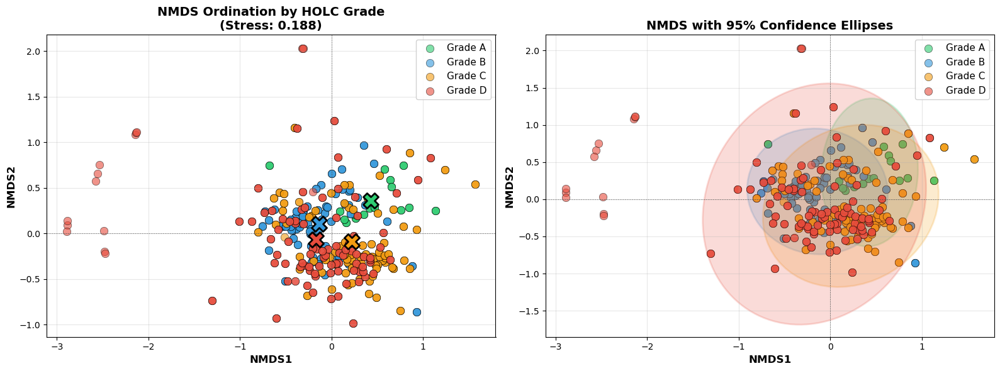

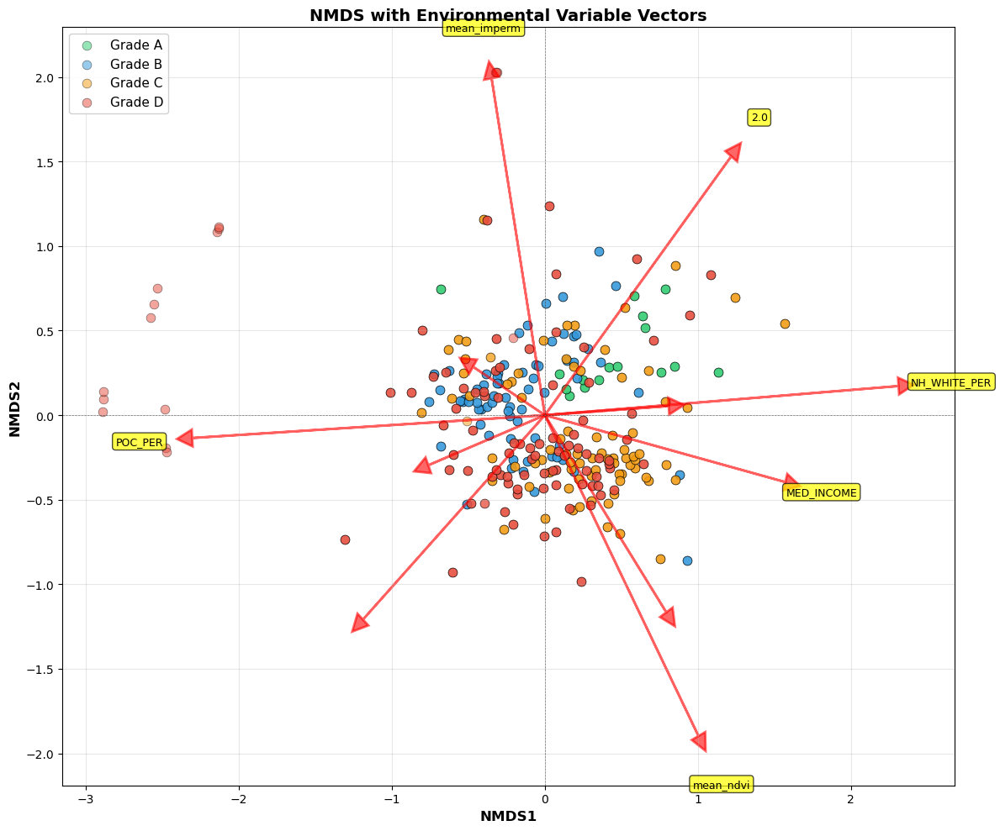

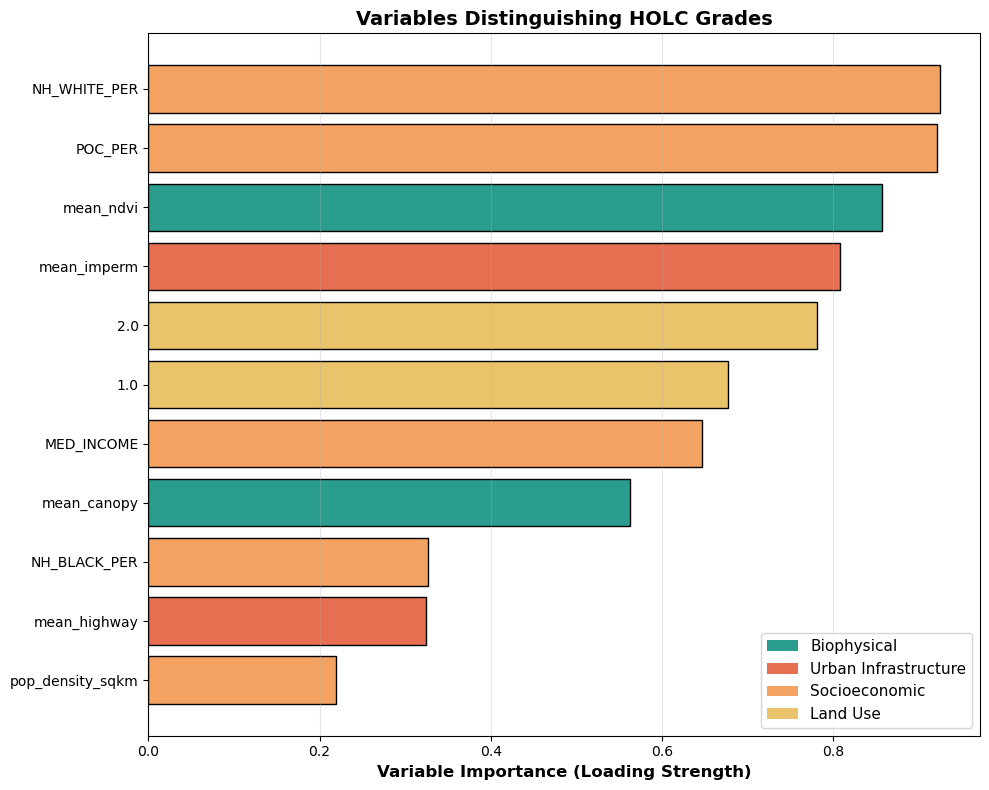


✓ Results saved to ../results_images

SUMMARY
NMDS Stress: 0.1884
Number of observations: 759
Number of variables: 11

Top 5 variables separating grades:
  NH_WHITE_PER: 0.926
  POC_PER: 0.922
  mean_ndvi: 0.857
  mean_imperm: 0.808
  2.0: 0.781


In [ ]:

def nmds_analysis_by_holc_grade(combined_df, save_path='../results_images'):
    """
    NMDS (Non-metric Multidimensional Scaling) analysis of environmental variables by HOLC grade
    Better for ecological data with non-linear relationships
    """
    import os
    from sklearn.manifold import MDS
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    import seaborn as sns
    
    if save_path and not os.path.exists(save_path):
        os.makedirs(save_path)
    
    print("\n" + "="*80)
    print("NMDS ANALYSIS BY HOLC GRADE")
    print("="*80)
    
    # Get data with HOLC grades
    richness_df = combined_df[combined_df['Diversity'] == 'Species richness'].copy()
    holc_data = richness_df[richness_df['grade_x'].notna()].copy()
    
    print(f"\nTotal observations: {len(holc_data)}")
    print(holc_data['grade_x'].value_counts().sort_index())
    
    # Select environmental variables for ordination
    env_vars = [
        # Biophysical
        'mean_canopy', 'mean_ndvi',
        # Urban infrastructure
        'mean_imperm', 'mean_highway',
        # Socioeconomic
        'POC_PER', 'NH_WHITE_PER', 'NH_BLACK_PER', 'HISPANIC_PER',
        'MED_INCOME', 'pop_density_sqkm',
        # Land use (zoning)
        '1.0', '2.0'
    ]
    
    # Filter to available variables
    available_vars = [v for v in env_vars if v in holc_data.columns]
    print(f"\nUsing {len(available_vars)} environmental variables")
    
    # Prepare data
    analysis_data = holc_data[available_vars + ['grade_x']].dropna()
    print(f"Valid observations after removing NA: {len(analysis_data)}")
    
    X = analysis_data[available_vars].values
    grades = analysis_data['grade_x'].values
    
    # Standardize data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # ==================================================================================
    # NMDS (Non-metric Multidimensional Scaling)
    # ==================================================================================
    
    print("\n" + "="*80)
    print("COMPUTING NMDS...")
    print("="*80)
    
    # NMDS with 2 dimensions
    nmds = MDS(n_components=2, metric=False, random_state=123, max_iter=500, n_init=10, verbose=1)
    nmds_coords = nmds.fit_transform(X_scaled)
    
    print(f"NMDS Stress: {nmds.stress_:.4f}")
    print("  (Stress < 0.05 = excellent, < 0.10 = good, < 0.20 = acceptable)")
    
    # Also compute PCA for loading vectors
    pca = PCA(n_components=2)
    pca.fit(X_scaled)
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # ==================================================================================
    # VISUALIZATIONS
    # ==================================================================================
    
    # Grade colors
    grade_colors = {'A': '#2ecc71', 'B': '#3498db', 'C': '#f39c12', 'D': '#e74c3c'}
    
    # Figure 1: NMDS plots
    fig1, axes1 = plt.subplots(1, 2, figsize=(16, 6))
    
    # NMDS scatter with centroids
    ax1a = axes1[0]
    for grade in ['A', 'B', 'C', 'D']:
        mask = grades == grade
        ax1a.scatter(nmds_coords[mask, 0], nmds_coords[mask, 1], 
                    c=grade_colors[grade], label=f'Grade {grade}', 
                    s=80, alpha=0.6, edgecolors='black', linewidth=0.5)
        
        # Add centroid
        centroid_x = nmds_coords[mask, 0].mean()
        centroid_y = nmds_coords[mask, 1].mean()
        ax1a.scatter(centroid_x, centroid_y, c=grade_colors[grade], 
                   marker='X', s=300, edgecolors='black', linewidth=2, zorder=5)
    
    ax1a.set_xlabel('NMDS1', fontweight='bold', fontsize=12)
    ax1a.set_ylabel('NMDS2', fontweight='bold', fontsize=12)
    ax1a.set_title(f'NMDS Ordination by HOLC Grade\n(Stress: {nmds.stress_:.3f})', 
                  fontweight='bold', fontsize=14)
    ax1a.legend(fontsize=11, framealpha=0.9)
    ax1a.grid(True, alpha=0.3)
    ax1a.axhline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
    ax1a.axvline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
    
    # NMDS with confidence ellipses
    ax1b = axes1[1]
    for grade in ['A', 'B', 'C', 'D']:
        mask = grades == grade
        ax1b.scatter(nmds_coords[mask, 0], nmds_coords[mask, 1], 
                    c=grade_colors[grade], label=f'Grade {grade}', 
                    s=80, alpha=0.6, edgecolors='black', linewidth=0.5)
        
        # Add 95% confidence ellipse
        if mask.sum() > 2:
            from matplotlib.patches import Ellipse
            from scipy import stats as sp_stats
            
            points = nmds_coords[mask]
            mean = points.mean(axis=0)
            cov = np.cov(points.T)
            
            # Chi-square value for 95% confidence (2 DOF)
            chi2_val = sp_stats.chi2.ppf(0.95, 2)
            eigenvalues, eigenvectors = np.linalg.eigh(cov)
            
            angle = np.degrees(np.arctan2(eigenvectors[1, 1], eigenvectors[0, 1]))
            width, height = 2 * np.sqrt(chi2_val * eigenvalues)
            
            ellipse = Ellipse(mean, width, height, angle=angle, 
                            facecolor=grade_colors[grade], alpha=0.2, 
                            edgecolor=grade_colors[grade], linewidth=2)
            ax1b.add_patch(ellipse)
    
    ax1b.set_xlabel('NMDS1', fontweight='bold', fontsize=12)
    ax1b.set_ylabel('NMDS2', fontweight='bold', fontsize=12)
    ax1b.set_title('NMDS with 95% Confidence Ellipses', fontweight='bold', fontsize=14)
    ax1b.legend(fontsize=11, framealpha=0.9)
    ax1b.grid(True, alpha=0.3)
    ax1b.axhline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
    ax1b.axvline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(save_path, 'nmds_holc_grades.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Figure 2: NMDS with variable vectors
    fig2, ax2 = plt.subplots(figsize=(12, 10))
    
    # Plot points
    for grade in ['A', 'B', 'C', 'D']:
        mask = grades == grade
        ax2.scatter(nmds_coords[mask, 0], nmds_coords[mask, 1], 
                   c=grade_colors[grade], label=f'Grade {grade}', 
                   s=60, alpha=0.5, edgecolors='black', linewidth=0.5)
    
    # Add variable vectors (using PCA loadings as approximation)
    scale_factor = 0.8 * max(abs(nmds_coords).max(), abs(loadings).max()) / abs(loadings).max()
    
    for i, var in enumerate(available_vars):
        ax2.arrow(0, 0, loadings[i, 0]*scale_factor, loadings[i, 1]*scale_factor,
                 head_width=0.1, head_length=0.1, fc='red', ec='red', alpha=0.6, linewidth=2)
        
        # Add labels for top contributors
        if abs(loadings[i, 0]) > np.percentile(abs(loadings[:, 0]), 70) or \
           abs(loadings[i, 1]) > np.percentile(abs(loadings[:, 1]), 70):
            ax2.text(loadings[i, 0]*scale_factor*1.15, loadings[i, 1]*scale_factor*1.15, 
                    var, fontsize=9, ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7, edgecolor='black'))
    
    ax2.set_xlabel('NMDS1', fontweight='bold', fontsize=12)
    ax2.set_ylabel('NMDS2', fontweight='bold', fontsize=12)
    ax2.set_title('NMDS with Environmental Variable Vectors', fontweight='bold', fontsize=14)
    ax2.legend(fontsize=11, framealpha=0.9, loc='upper left')
    ax2.grid(True, alpha=0.3)
    ax2.axhline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
    ax2.axvline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(save_path, 'nmds_holc_vectors.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Figure 3: Variable importance
    fig3, ax3 = plt.subplots(figsize=(10, 8))
    
    # Calculate variable importance based on loadings
    loading_importance = np.sqrt(loadings[:, 0]**2 + loadings[:, 1]**2)
    var_importance_df = pd.DataFrame({
        'Variable': available_vars,
        'Importance': loading_importance
    }).sort_values('Importance', ascending=False)
    
    # Color by category
    colors_cat = []
    for var in var_importance_df['Variable']:
        if var in ['mean_canopy', 'mean_ndvi', 'FHD', 'mean_elevation']:
            colors_cat.append('#2A9D8F')
        elif var in ['mean_imperm', 'mean_highway', 'mean_road', 'mean_light']:
            colors_cat.append('#E76F51')
        elif var in ['POC_PER', 'NH_WHITE_PER', 'NH_BLACK_PER', 'HISPANIC_PER', 'MED_INCOME', 'pop_density_sqkm']:
            colors_cat.append('#F4A261')
        else:
            colors_cat.append('#E9C46A')
    
    ax3.barh(range(len(var_importance_df)), var_importance_df['Importance'], 
            color=colors_cat, edgecolor='black')
    ax3.set_yticks(range(len(var_importance_df)))
    ax3.set_yticklabels(var_importance_df['Variable'])
    ax3.invert_yaxis()
    ax3.set_xlabel('Variable Importance (Loading Strength)', fontweight='bold', fontsize=12)
    ax3.set_title('Variables Distinguishing HOLC Grades', fontweight='bold', fontsize=14)
    ax3.grid(True, alpha=0.3, axis='x')
    
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#2A9D8F', label='Biophysical'),
                      Patch(facecolor='#E76F51', label='Urban Infrastructure'),
                      Patch(facecolor='#F4A261', label='Socioeconomic'),
                      Patch(facecolor='#E9C46A', label='Land Use')]
    ax3.legend(handles=legend_elements, loc='lower right', fontsize=11)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(save_path, 'nmds_variable_importance.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Save results
    if save_path:
        results_df = pd.DataFrame({
            'NMDS1': nmds_coords[:, 0],
            'NMDS2': nmds_coords[:, 1],
            'HOLC_Grade': grades
        })
        results_df.to_csv(os.path.join(save_path, 'nmds_coordinates.csv'), index=False)
        var_importance_df.to_csv(os.path.join(save_path, 'nmds_variable_importance.csv'), index=False)
        print(f"\n✓ Results saved to {save_path}")
    
    print(f"\n{'='*80}")
    print("SUMMARY")
    print(f"{'='*80}")
    print(f"NMDS Stress: {nmds.stress_:.4f}")
    print(f"Number of observations: {len(nmds_coords)}")
    print(f"Number of variables: {len(available_vars)}")
    print(f"\nTop 5 variables separating grades:")
    for i, row in var_importance_df.head(5).iterrows():
        print(f"  {row['Variable']}: {row['Importance']:.3f}")
    
    return nmds_coords, var_importance_df


# Run NMDS analysis
nmds_coords, var_importance = nmds_analysis_by_holc_grade(combined_df, save_path='../results_images')



3D NMDS ANALYSIS BY HOLC GRADE

Total observations: 759
grade_x
A     48
B    204
C    240
D    267
Name: count, dtype: int64

Using 11 environmental variables
Valid observations after removing NA: 759

COMPUTING 3D NMDS...


/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=False instead of metric=False. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


Convergence criterion reached (iteration 295).
Convergence criterion reached (iteration 211).
Convergence criterion reached (iteration 235).
Convergence criterion reached (iteration 263).
Convergence criterion reached (iteration 304).
Convergence criterion reached (iteration 348).
Convergence criterion reached (iteration 215).
Convergence criterion reached (iteration 280).
Convergence criterion reached (iteration 419).

3D NMDS Stress: 0.1306


/home/oliver/miniforge3/envs/sf_env/lib/python3.14/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=False instead of metric=False. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


2D NMDS Stress: 0.1884
Stress improvement with 3D: 30.7%


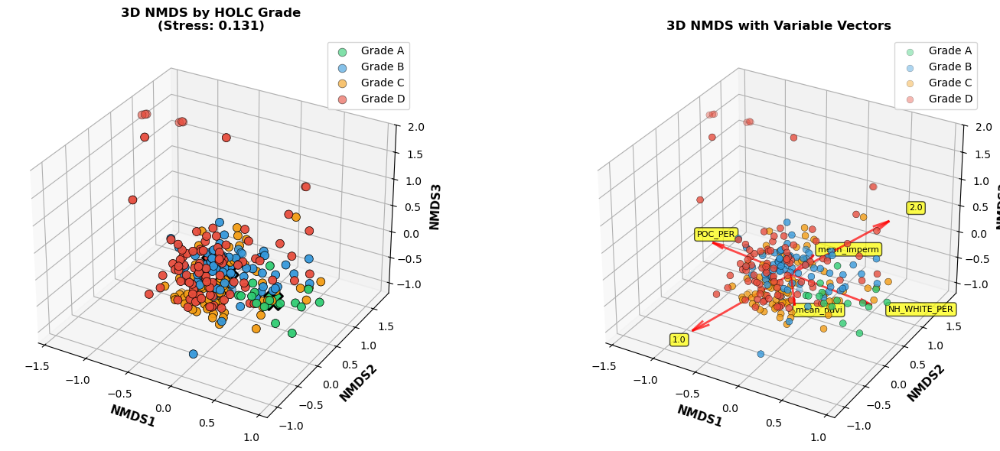

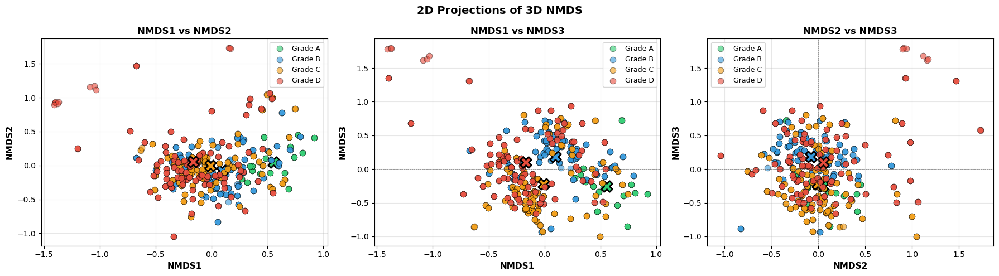

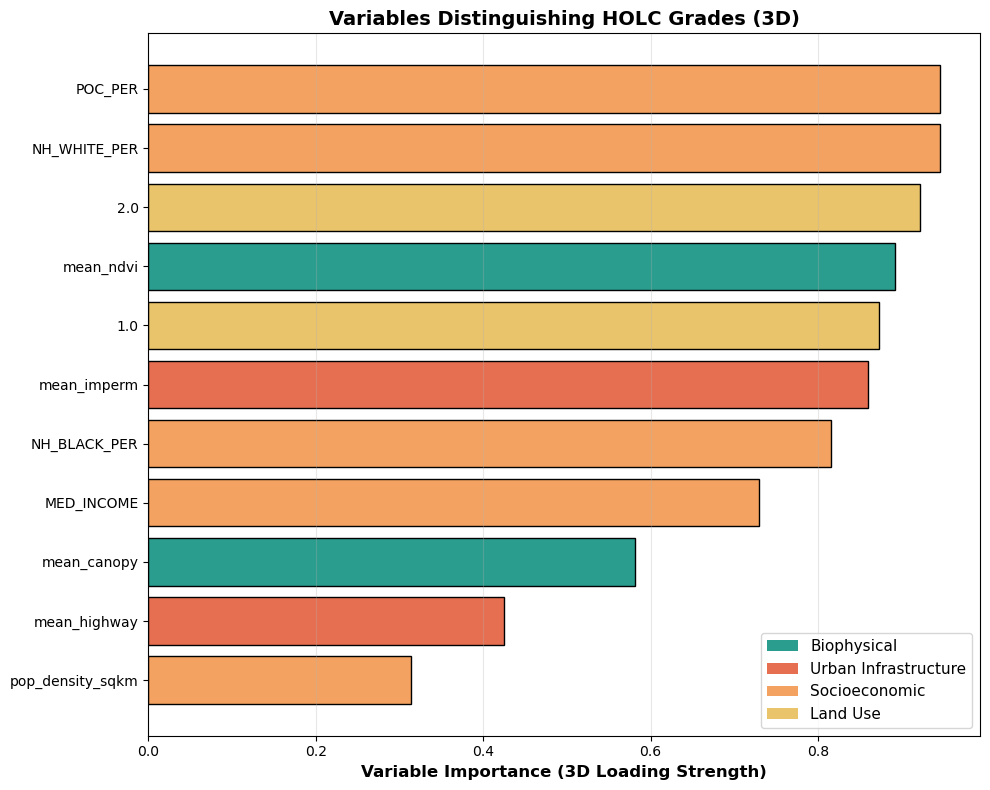


✓ Results saved to ../results_images

SUMMARY
2D NMDS Stress: 0.1884
3D NMDS Stress: 0.1306
Improvement: 30.7%
Number of observations: 759
Number of variables: 11

Top 5 variables separating grades (3D):
  POC_PER: 0.946
  NH_WHITE_PER: 0.946
  2.0: 0.922
  mean_ndvi: 0.891
  1.0: 0.873


In [ ]:

def nmds_analysis_by_holc_grade_3d(combined_df, save_path='../results_images'):
    """
    3D NMDS analysis of environmental variables by HOLC grade
    """
    import os
    from sklearn.manifold import MDS
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from mpl_toolkits.mplot3d import Axes3D
    import seaborn as sns
    
    if save_path and not os.path.exists(save_path):
        os.makedirs(save_path)
    
    print("\n" + "="*80)
    print("3D NMDS ANALYSIS BY HOLC GRADE")
    print("="*80)
    
    # Get data with HOLC grades
    richness_df = combined_df[combined_df['Diversity'] == 'Species richness'].copy()
    holc_data = richness_df[richness_df['grade_x'].notna()].copy()
    
    print(f"\nTotal observations: {len(holc_data)}")
    print(holc_data['grade_x'].value_counts().sort_index())
    
    # Select environmental variables
    env_vars = [
        'mean_canopy', 'mean_ndvi',
        'mean_imperm', 'mean_highway',
        'POC_PER', 'NH_WHITE_PER', 'NH_BLACK_PER', 'HISPANIC_PER',
        'MED_INCOME', 'pop_density_sqkm',
        '1.0', '2.0'
    ]
    
    available_vars = [v for v in env_vars if v in holc_data.columns]
    print(f"\nUsing {len(available_vars)} environmental variables")
    
    # Prepare data
    analysis_data = holc_data[available_vars + ['grade_x']].dropna()
    print(f"Valid observations after removing NA: {len(analysis_data)}")
    
    X = analysis_data[available_vars].values
    grades = analysis_data['grade_x'].values
    
    # Standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # ==================================================================================
    # 3D NMDS
    # ==================================================================================
    
    print("\n" + "="*80)
    print("COMPUTING 3D NMDS...")
    print("="*80)
    
    # 3D NMDS
    nmds_3d = MDS(n_components=3, 
                  metric=False,
                  init='random',
                  random_state=123, 
                  max_iter=500, 
                  n_init=10, 
                  verbose=1)
    nmds_coords_3d = nmds_3d.fit_transform(X_scaled)
    
    print(f"\n3D NMDS Stress: {nmds_3d.stress_:.4f}")
    
    # Also compute 2D for comparison
    nmds_2d = MDS(n_components=2, 
                  metric=False,
                  init='random',
                  random_state=123, 
                  max_iter=500, 
                  n_init=10)
    nmds_coords_2d = nmds_2d.fit_transform(X_scaled)
    
    print(f"2D NMDS Stress: {nmds_2d.stress_:.4f}")
    print(f"Stress improvement with 3D: {((nmds_2d.stress_ - nmds_3d.stress_) / nmds_2d.stress_ * 100):.1f}%")
    
    # PCA for loading vectors
    pca = PCA(n_components=3)
    pca.fit(X_scaled)
    loadings_3d = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Grade colors
    grade_colors = {'A': '#2ecc71', 'B': '#3498db', 'C': '#f39c12', 'D': '#e74c3c'}
    
    # ==================================================================================
    # 3D VISUALIZATIONS
    # ==================================================================================
    
    # Figure 1: Interactive 3D scatter plot
    fig1 = plt.figure(figsize=(16, 6))
    
    # Plot 1a: Basic 3D scatter
    ax1a = fig1.add_subplot(121, projection='3d')
    
    for grade in ['A', 'B', 'C', 'D']:
        mask = grades == grade
        ax1a.scatter(nmds_coords_3d[mask, 0], 
                    nmds_coords_3d[mask, 1], 
                    nmds_coords_3d[mask, 2],
                    c=grade_colors[grade], 
                    label=f'Grade {grade}',
                    s=60, 
                    alpha=0.6, 
                    edgecolors='black', 
                    linewidth=0.5)
        
        # Add centroid
        centroid = nmds_coords_3d[mask].mean(axis=0)
        ax1a.scatter(centroid[0], centroid[1], centroid[2],
                    c=grade_colors[grade],
                    marker='X',
                    s=300,
                    edgecolors='black',
                    linewidth=2,
                    zorder=5)
    
    ax1a.set_xlabel('NMDS1', fontweight='bold', fontsize=11)
    ax1a.set_ylabel('NMDS2', fontweight='bold', fontsize=11)
    ax1a.set_zlabel('NMDS3', fontweight='bold', fontsize=11)
    ax1a.set_title(f'3D NMDS by HOLC Grade\n(Stress: {nmds_3d.stress_:.3f})', 
                  fontweight='bold', fontsize=12)
    ax1a.legend(fontsize=10)
    
    # Plot 1b: 3D with variable vectors
    ax1b = fig1.add_subplot(122, projection='3d')
    
    for grade in ['A', 'B', 'C', 'D']:
        mask = grades == grade
        ax1b.scatter(nmds_coords_3d[mask, 0], 
                    nmds_coords_3d[mask, 1], 
                    nmds_coords_3d[mask, 2],
                    c=grade_colors[grade], 
                    label=f'Grade {grade}',
                    s=40, 
                    alpha=0.4, 
                    edgecolors='black', 
                    linewidth=0.3)
    
    # Add top variable vectors
    scale_factor = 0.5 * abs(nmds_coords_3d).max()
    loading_strength = np.sqrt((loadings_3d**2).sum(axis=1))
    top_vars_idx = np.argsort(loading_strength)[-6:]  # Top 6 variables
    
    for i in top_vars_idx:
        vec = loadings_3d[i] * scale_factor / abs(loadings_3d[i]).max()
        ax1b.quiver(0, 0, 0, vec[0], vec[1], vec[2],
                   color='red', arrow_length_ratio=0.15, linewidth=2, alpha=0.7)
        ax1b.text(vec[0]*1.2, vec[1]*1.2, vec[2]*1.2, available_vars[i],
                 fontsize=8, bbox=dict(boxstyle='round,pad=0.3', 
                                      facecolor='yellow', alpha=0.7))
    
    ax1b.set_xlabel('NMDS1', fontweight='bold', fontsize=11)
    ax1b.set_ylabel('NMDS2', fontweight='bold', fontsize=11)
    ax1b.set_zlabel('NMDS3', fontweight='bold', fontsize=11)
    ax1b.set_title('3D NMDS with Variable Vectors', fontweight='bold', fontsize=12)
    ax1b.legend(fontsize=10)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(save_path, 'nmds_3d_holc_grades.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Figure 2: 2D projections of 3D NMDS
    fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
    
    projections = [
        (0, 1, 'NMDS1', 'NMDS2'),
        (0, 2, 'NMDS1', 'NMDS3'),
        (1, 2, 'NMDS2', 'NMDS3')
    ]
    
    for ax, (dim1, dim2, label1, label2) in zip(axes2, projections):
        for grade in ['A', 'B', 'C', 'D']:
            mask = grades == grade
            ax.scatter(nmds_coords_3d[mask, dim1], 
                      nmds_coords_3d[mask, dim2],
                      c=grade_colors[grade], 
                      label=f'Grade {grade}',
                      s=60, 
                      alpha=0.6, 
                      edgecolors='black', 
                      linewidth=0.5)
            
            # Centroid
            centroid = nmds_coords_3d[mask].mean(axis=0)
            ax.scatter(centroid[dim1], centroid[dim2],
                      c=grade_colors[grade],
                      marker='X',
                      s=200,
                      edgecolors='black',
                      linewidth=2)
        
        ax.set_xlabel(label1, fontweight='bold', fontsize=11)
        ax.set_ylabel(label2, fontweight='bold', fontsize=11)
        ax.set_title(f'{label1} vs {label2}', fontweight='bold', fontsize=12)
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
        ax.axvline(0, color='black', linestyle='--', linewidth=0.5, alpha=0.5)
    
    fig2.suptitle('2D Projections of 3D NMDS', fontweight='bold', fontsize=14)
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(save_path, 'nmds_3d_projections.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Figure 3: Variable importance (3D)
    fig3, ax3 = plt.subplots(figsize=(10, 8))
    
    loading_importance_3d = np.sqrt((loadings_3d**2).sum(axis=1))
    var_importance_df = pd.DataFrame({
        'Variable': available_vars,
        'Importance': loading_importance_3d
    }).sort_values('Importance', ascending=False)
    
    # Color by category
    colors_cat = []
    for var in var_importance_df['Variable']:
        if var in ['mean_canopy', 'mean_ndvi', 'FHD', 'mean_elevation']:
            colors_cat.append('#2A9D8F')
        elif var in ['mean_imperm', 'mean_highway', 'mean_road', 'mean_light']:
            colors_cat.append('#E76F51')
        elif var in ['POC_PER', 'NH_WHITE_PER', 'NH_BLACK_PER', 'HISPANIC_PER', 'MED_INCOME', 'pop_density_sqkm']:
            colors_cat.append('#F4A261')
        else:
            colors_cat.append('#E9C46A')
    
    ax3.barh(range(len(var_importance_df)), var_importance_df['Importance'], 
            color=colors_cat, edgecolor='black')
    ax3.set_yticks(range(len(var_importance_df)))
    ax3.set_yticklabels(var_importance_df['Variable'])
    ax3.invert_yaxis()
    ax3.set_xlabel('Variable Importance (3D Loading Strength)', fontweight='bold', fontsize=12)
    ax3.set_title('Variables Distinguishing HOLC Grades (3D)', fontweight='bold', fontsize=14)
    ax3.grid(True, alpha=0.3, axis='x')
    
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#2A9D8F', label='Biophysical'),
                      Patch(facecolor='#E76F51', label='Urban Infrastructure'),
                      Patch(facecolor='#F4A261', label='Socioeconomic'),
                      Patch(facecolor='#E9C46A', label='Land Use')]
    ax3.legend(handles=legend_elements, loc='lower right', fontsize=11)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(save_path, 'nmds_3d_variable_importance.png'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # Save results
    if save_path:
        results_df = pd.DataFrame({
            'NMDS1': nmds_coords_3d[:, 0],
            'NMDS2': nmds_coords_3d[:, 1],
            'NMDS3': nmds_coords_3d[:, 2],
            'HOLC_Grade': grades
        })
        results_df.to_csv(os.path.join(save_path, 'nmds_3d_coordinates.csv'), index=False)
        var_importance_df.to_csv(os.path.join(save_path, 'nmds_3d_variable_importance.csv'), index=False)
        print(f"\n✓ Results saved to {save_path}")
    
    print(f"\n{'='*80}")
    print("SUMMARY")
    print(f"{'='*80}")
    print(f"2D NMDS Stress: {nmds_2d.stress_:.4f}")
    print(f"3D NMDS Stress: {nmds_3d.stress_:.4f}")
    print(f"Improvement: {((nmds_2d.stress_ - nmds_3d.stress_) / nmds_2d.stress_ * 100):.1f}%")
    print(f"Number of observations: {len(nmds_coords_3d)}")
    print(f"Number of variables: {len(available_vars)}")
    print(f"\nTop 5 variables separating grades (3D):")
    for i, row in var_importance_df.head(5).iterrows():
        print(f"  {row['Variable']}: {row['Importance']:.3f}")
    
    return nmds_coords_3d, var_importance_df


# Run 3D NMDS analysis
nmds_coords_3d, var_importance_3d = nmds_analysis_by_holc_grade_3d(combined_df, save_path='../results_images')
